# Explainable AI for the UTSW Glioma IDH Gated-Fusion Model

## Objective

This notebook develops an explainability framework for the existing CNN + Vision Transformer + Clinical Gated-Fusion model trained to predict IDH status in glioma patients.

The model uses four MRI modalities (T1, T1ce, T2 and FLAIR), together with clinical age and sex.

## Explainability methods

1. **3D Grad-CAM:** Visualize spatial regions contributing to the CNN representation of a prediction.
2. **Integrated Gradients:** Estimate the contribution of age and sex relative to a selected baseline.
3. **Gated-fusion analysis:** Inspect the learned fusion gate values and their variation across patients.
4. **Branch ablation:** Evaluate how predictions change when an information source is replaced by a defined baseline.

The model will be loaded from its existing checkpoint. No training or checkpoint modification will be performed.

**Important:** These methods explain aspects of the model's behavior. They do not establish biological causation or clinical validity.

In [1]:

import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [7]:
# ============================================================
# OVERRIDE XAI CHECKPOINT PATH — UPDATED EPOCH 10
# ============================================================

from pathlib import Path

GATED_CHECKPOINT_PATH = (
    "/content/drive/MyDrive/Glioma_Research/"
    "comparative_experiment/models/"
    "cnn_vit_clinical_gated_resumed_best.pth"
)

assert Path(GATED_CHECKPOINT_PATH).is_file(), (
    f"Checkpoint not found: {GATED_CHECKPOINT_PATH}"
)

import torch

ckpt = torch.load(
    GATED_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint found:", Path(GATED_CHECKPOINT_PATH).name)
print("Model:", ckpt["model_name"])
print("Epoch:", ckpt["epoch"])
print("Validation loss:", ckpt["val_loss"])
print("Validation accuracy:", ckpt["val_accuracy"])

Checkpoint found: cnn_vit_clinical_gated_resumed_best.pth
Model: CNN + ViT + Clinical - Gated Fusion
Epoch: 10
Validation loss: 0.4295039912385325
Validation accuracy: 0.8494623655913979


In [9]:
from pathlib import Path

# Convert all path entries to Path objects
paths = {
    name: Path(path)
    for name, path in paths.items()
}

print("All paths converted to Path objects.")

All paths converted to Path objects.


In [10]:

# ============================================================
# XAI NOTEBOOK — DRIVE, PATHS & CHECKPOINT SETUP
# Updated Gated Fusion Checkpoint (Epoch 10)
# ============================================================

from google.colab import drive
from pathlib import Path
import torch

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Project directory
BASE_DIR = Path("/content/drive/MyDrive/Glioma_Research")

# 3. Dataset directories
SPLIT_DIR = BASE_DIR / "model_splits"
CACHE_DIR = BASE_DIR / "preprocessed_cache"

# 4. Dataset CSV files
TRAIN_PATH = SPLIT_DIR / "IDH_train.csv"
VAL_PATH = SPLIT_DIR / "IDH_validation.csv"
TEST_PATH = SPLIT_DIR / "IDH_test.csv"

# 5. Preprocessed MRI cache directories
TRAIN_CACHE_DIR = CACHE_DIR / "train"
VAL_CACHE_DIR = CACHE_DIR / "validation"
TEST_CACHE_DIR = CACHE_DIR / "test"

# 6. UPDATED GATED-FUSION CHECKPOINT — EPOCH 10
CHECKPOINT_PATH = (
    BASE_DIR
    / "comparative_experiment"
    / "models"
    / "cnn_vit_clinical_gated_resumed_best.pth"
)

# Keep the previous variable name compatible if later cells use it
GATED_CHECKPOINT_PATH = CHECKPOINT_PATH

# 7. Verify all required paths
paths = {
    "Training CSV": TRAIN_PATH,
    "Validation CSV": VAL_PATH,
    "Test CSV": TEST_PATH,
    "Training cache": TRAIN_CACHE_DIR,
    "Validation cache": VAL_CACHE_DIR,
    "Test cache": TEST_CACHE_DIR,
    "Gated-fusion checkpoint": CHECKPOINT_PATH,
}

print("\n" + "=" * 75)
print("XAI PATH VERIFICATION")
print("=" * 75)

for name, path in paths.items():
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{name:25s} | {status:8s} | {path}")

missing = [
    name for name, path in paths.items()
    if not path.exists()
]

if missing:
    raise FileNotFoundError(
        "Resolve these missing paths before continuing: "
        + ", ".join(missing)
    )

# 8. Inspect checkpoint metadata (does not load into model yet)
checkpoint_metadata = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\n" + "=" * 75)
print("CHECKPOINT VERIFICATION")
print("=" * 75)

print("Checkpoint file:", CHECKPOINT_PATH.name)
print("Model name:", checkpoint_metadata["model_name"])
print("Epoch:", checkpoint_metadata["epoch"])
print("Validation loss:", checkpoint_metadata["val_loss"])
print("Validation accuracy:", checkpoint_metadata["val_accuracy"])

assert checkpoint_metadata["epoch"] == 10, (
    "Expected the updated epoch-10 checkpoint!"
)

print("\nAll paths verified successfully.")
print("Correct epoch-10 checkpoint identified.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

XAI PATH VERIFICATION
Training CSV              | FOUND    | /content/drive/MyDrive/Glioma_Research/model_splits/IDH_train.csv
Validation CSV            | FOUND    | /content/drive/MyDrive/Glioma_Research/model_splits/IDH_validation.csv
Test CSV                  | FOUND    | /content/drive/MyDrive/Glioma_Research/model_splits/IDH_test.csv
Training cache            | FOUND    | /content/drive/MyDrive/Glioma_Research/preprocessed_cache/train
Validation cache          | FOUND    | /content/drive/MyDrive/Glioma_Research/preprocessed_cache/validation
Test cache                | FOUND    | /content/drive/MyDrive/Glioma_Research/preprocessed_cache/test
Gated-fusion checkpoint   | FOUND    | /content/drive/MyDrive/Glioma_Research/comparative_experiment/models/cnn_vit_clinical_gated_resumed_best.pth

CHECKPOINT VERIFICATION
Checkpoint file: cnn_vit_clinical_gated_res

In [11]:

from sklearn.preprocessing import StandardScaler

train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

required_columns = ["Subject_ID", "Age", "Sex", "IDH"]

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing_cols = [c for c in required_columns if c not in df.columns]
    if missing_cols:
        raise ValueError(f"{name} split is missing columns: {missing_cols}")

    if df["Subject_ID"].duplicated().any():
        raise ValueError(f"Duplicate patient IDs found in {name} split.")

# Recreate the same scaler: fit on training patients only.
age_scaler = StandardScaler()
train_df["Age_Scaled"] = age_scaler.fit_transform(
    train_df[["Age"]].astype(float)
).ravel()

val_df["Age_Scaled"] = age_scaler.transform(
    val_df[["Age"]].astype(float)
).ravel()

test_df["Age_Scaled"] = age_scaler.transform(
    test_df[["Age"]].astype(float)
).ravel()

# Match original sex encoding.
sex_mapping = {"M": 0.0, "F": 1.0}

for name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    df["Sex_Encoded"] = (
        df["Sex"].astype(str).str.strip().str.upper().map(sex_mapping)
    )

    normalized_idh = df["IDH"].astype(str).str.strip().str.lower()
    idh_mapping = {"wild type": 0, "mutated": 1}

    df["IDH_Label"] = normalized_idh.map(idh_mapping)

    if df[["Age_Scaled", "Sex_Encoded", "IDH_Label"]].isna().any().any():
        raise ValueError(f"Missing/invalid clinical values or labels in {name}.")

    df["IDH_Label"] = df["IDH_Label"].astype(int)

# Confirm patient-level splits do not overlap.
train_ids = set(train_df["Subject_ID"].astype(str))
val_ids = set(val_df["Subject_ID"].astype(str))
test_ids = set(test_df["Subject_ID"].astype(str))

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

print("Patient counts:", len(train_df), len(val_df), len(test_df))
print("Train/validation/test overlap: NONE")
print("\nTest label distribution:")
print(test_df["IDH_Label"].value_counts().sort_index())


Patient counts: 435 93 94
Train/validation/test overlap: NONE

Test label distribution:
IDH_Label
0    67
1    27
Name: count, dtype: int64


### Step 7: Locate the model definition

We will check only the known project directory and the current session for the original model classes. This avoids scanning the entire Google Drive.

We need to find the exact model definition before loading the checkpoint so that the explainability implementation uses the same architecture as training.

In [12]:

from pathlib import Path

project_dir = Path("/content/drive/MyDrive/Glioma_Research")

print("Project directory exists:", project_dir.exists())

if project_dir.exists():
    print("\nProject directory contents:")
    for item in list(project_dir.iterdir())[:40]:
        print(item.name, " [DIR]" if item.is_dir() else " [FILE]")

print("\nClasses already defined in this runtime:")
for name in [
    "MRI3DCNN",
    "CNNToTokens",
    "MRITransformer",
    "CNNViTGatedClinicalIDHModel",
]:
    print(f"{name}: {'FOUND' if name in globals() else 'NOT FOUND'}")


Project directory exists: True

Project directory contents:
datasets  [DIR]
UTSW_Glioma_Final_Manifest.csv  [FILE]
model_splits  [DIR]
preprocessed_cache  [DIR]
best_multimodal_cnn_vit_idh.pth  [FILE]
last_multimodal_cnn_vit_idh.pth  [FILE]
results  [DIR]
restore_utsw_project.py  [FILE]
comparative_experiment  [DIR]
permanent_recovery  [DIR]
explainability  [DIR]

Classes already defined in this runtime:
MRI3DCNN: NOT FOUND
CNNToTokens: NOT FOUND
MRITransformer: NOT FOUND
CNNViTGatedClinicalIDHModel: NOT FOUND


### Step 8: Identify the comparison-training model artifacts

The objective is to load the exact gated-fusion model trained during the comparative experiments.

We will inspect the comparison-training directory to locate its saved checkpoints, result files, and experiment metadata. This ensures that the explainability workflow uses the correct model rather than the checkpoint from the earlier multimodal training experiment.

This cell only lists files and does not modify or retrain any model.

In [13]:

from pathlib import Path

COMPARISON_DIR = (
    Path("/content/drive/MyDrive/Glioma_Research")
    / "comparative_experiment"
)

if not COMPARISON_DIR.is_dir():
    raise FileNotFoundError(
        f"Comparison-training directory not found: {COMPARISON_DIR}"
    )

print("Comparison-training directory:", COMPARISON_DIR)
print("\nFiles and folders (maximum 60 entries):")

for index, path in enumerate(COMPARISON_DIR.iterdir()):
    if index >= 60:
        print("... listing truncated")
        break

    kind = "DIR " if path.is_dir() else "FILE"
    size = f"{path.stat().st_size / (1024**2):.2f} MB" if path.is_file() else ""
    print(f"{kind:4} | {path.name} {size}")


Comparison-training directory: /content/drive/MyDrive/Glioma_Research/comparative_experiment

Files and folders (maximum 60 entries):
DIR  | models 
DIR  | checkpoints 
DIR  | histories 
DIR  | results 
DIR  | plots 


### Step 9: Inspect comparison-training checkpoints

The comparative experiment contains separate folders for models and checkpoints. We will list the files in both locations and check their sizes.

Our goal is to identify the saved weights corresponding to `CNNViTGatedClinicalIDHModel`. We will not load, modify, or retrain any checkpoint in this step.

In [14]:

from pathlib import Path

COMPARISON_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/comparative_experiment"
)

for folder_name in ["models", "checkpoints"]:
    folder = COMPARISON_DIR / folder_name

    print(f"\n{'=' * 20} {folder_name.upper()} {'=' * 20}")

    if not folder.is_dir():
        print("Folder not found.")
        continue

    files = list(folder.iterdir())

    if not files:
        print("No files in this folder.")
        continue

    for path in files:
        if path.is_file():
            size_mb = path.stat().st_size / (1024 ** 2)
            print(f"FILE | {path.name} | {size_mb:.2f} MB")
        else:
            print(f"DIR  | {path.name}")



==================== MODELS ====================
FILE | cnn_only_best.pth | 3.24 MB
FILE | vit_only_best.pth | 33.72 MB
FILE | cnn_vit_only_best.pth | 7.06 MB
FILE | clinical_only_best.pth | 0.02 MB
FILE | cnn_clinical_best.pth | 3.36 MB
FILE | vit_clinical_best.pth | 7.18 MB
FILE | cnn_vit_clinical_best.pth | 7.18 MB
FILE | cnn_vit_clinical_gated_best.pth | 7.33 MB
FILE | cnn_vit_clinical_gated_resumed_best.pth | 7.33 MB
FILE | cnn_vit_clinical_gated_resumed_history.csv | 0.00 MB
FILE | cnn_vit_clinical_gated_resumed_last.pth | 7.33 MB
FILE | Copy of cnn_vit_clinical_gated_resumed_best.pth | 7.33 MB

==================== CHECKPOINTS ====================
No files in this folder.


### Step 10: Verify the original gated-fusion checkpoint

The comparison-training experiment saved multiple model configurations. We will use the checkpoint named `cnn_vit_clinical_gated_best.pth`, which corresponds to the gated-fusion experiment.

Before reconstructing the model, we will inspect the checkpoint's contents, including its parameter keys and tensor shapes. This helps us identify the architecture expected by the saved weights.

This step only reads the checkpoint. It does not train or modify the model.

In [15]:

from pathlib import Path
import torch

COMPARISON_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/comparative_experiment"
)

CHECKPOINT_PATH = (
    COMPARISON_DIR / "models" / "cnn_vit_clinical_gated_best.pth"
)

assert CHECKPOINT_PATH.is_file(), (
    f"Comparison-training checkpoint not found: {CHECKPOINT_PATH}"
)

try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location="cpu",
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(CHECKPOINT_PATH, map_location="cpu")

print("Checkpoint:", CHECKPOINT_PATH.name)
print("File size (MB):", round(CHECKPOINT_PATH.stat().st_size / (1024**2), 2))
print("Checkpoint object type:", type(checkpoint).__name__)

if isinstance(checkpoint, dict):
    print("\nTop-level keys:")
    for key, value in checkpoint.items():
        if isinstance(value, dict):
            print(f"  {key}: dictionary with {len(value)} entries")
        elif torch.is_tensor(value):
            print(f"  {key}: tensor with shape {tuple(value.shape)}")
        else:
            print(f"  {key}: {type(value).__name__}")

    # Identify the state dictionary without assuming its key name.
    state_dict = None

    if checkpoint and all(torch.is_tensor(v) for v in checkpoint.values()):
        state_dict = checkpoint
        print("\nThe checkpoint itself appears to be a state dictionary.")
    else:
        for key in ["model_state_dict", "state_dict", "model"]:
            value = checkpoint.get(key)
            if isinstance(value, dict) and value and all(
                torch.is_tensor(v) for v in value.values()
            ):
                state_dict = value
                print(f"\nFound model state dictionary under: {key}")
                break

    if state_dict is not None:
        print("\nFirst 35 parameter keys and shapes:")
        for index, (key, tensor) in enumerate(state_dict.items()):
            if index >= 35:
                break
            print(f"{key}: {tuple(tensor.shape)}")
    else:
        print(
            "\nNo standard model state dictionary was identified. "
            "We need to inspect the checkpoint structure before proceeding."
        )
else:
    print("Unexpected checkpoint format; do not attempt to load the model yet.")


Checkpoint: cnn_vit_clinical_gated_best.pth
File size (MB): 7.33
Checkpoint object type: dict

Top-level keys:
  model_state_dict: dictionary with 64 entries
  optimizer_state_dict: dictionary with 2 entries
  epoch: int
  val_loss: float
  val_accuracy: float
  model_name: str

Found model state dictionary under: model_state_dict

First 35 parameter keys and shapes:
cnn.features.0.weight: (32, 4, 3, 3, 3)
cnn.features.0.bias: (32,)
cnn.features.1.weight: (32,)
cnn.features.1.bias: (32,)
cnn.features.1.running_mean: (32,)
cnn.features.1.running_var: (32,)
cnn.features.1.num_batches_tracked: ()
cnn.features.4.weight: (64, 32, 3, 3, 3)
cnn.features.4.bias: (64,)
cnn.features.5.weight: (64,)
cnn.features.5.bias: (64,)
cnn.features.5.running_mean: (64,)
cnn.features.5.running_var: (64,)
cnn.features.5.num_batches_tracked: ()
cnn.features.8.weight: (128, 64, 3, 3, 3)
cnn.features.8.bias: (128,)
cnn.features.9.weight: (128,)
cnn.features.9.bias: (128,)
cnn.features.9.running_mean: (128,)
cnn

### Step 11: Inspect the complete gated-fusion architecture

The checkpoint contains 64 parameter entries. We have confirmed that it includes a 3D CNN with channels 32, 64 and 128, a token projection layer, and a Transformer with 128-dimensional embeddings.

We will now inspect the remaining parameter names and shapes to identify the clinical branch, fusion gate and classification head. This will help us reproduce the exact architecture before loading the checkpoint.

This cell only reads checkpoint metadata and does not modify the saved model.

In [16]:

# Reuse the checkpoint and state_dict already loaded in Cell 10.

state_dict = checkpoint["model_state_dict"]

print("Total state-dictionary entries:", len(state_dict))
print("\nComplete architecture parameter listing:\n")

for name, tensor in state_dict.items():
    print(f"{name:65s} {tuple(tensor.shape)}")

print("\n=== Components identified from parameter names ===")

component_prefixes = sorted({
    name.split(".")[0]
    for name in state_dict
})

for prefix in component_prefixes:
    count = sum(
        1 for name in state_dict
        if name.split(".")[0] == prefix
    )
    print(f"{prefix}: {count} entries")


Total state-dictionary entries: 64

Complete architecture parameter listing:

cnn.features.0.weight                                             (32, 4, 3, 3, 3)
cnn.features.0.bias                                               (32,)
cnn.features.1.weight                                             (32,)
cnn.features.1.bias                                               (32,)
cnn.features.1.running_mean                                       (32,)
cnn.features.1.running_var                                        (32,)
cnn.features.1.num_batches_tracked                                ()
cnn.features.4.weight                                             (64, 32, 3, 3, 3)
cnn.features.4.bias                                               (64,)
cnn.features.5.weight                                             (64,)
cnn.features.5.bias                                               (64,)
cnn.features.5.running_mean                                       (64,)
cnn.features.5.running_var            

### Step 12: Reconstruct the original gated-fusion architecture

The checkpoint reveals the dimensions of every model component. We will reconstruct the architecture with the same layer names and dimensions so that the saved weights can be loaded.

The parameter shapes do not reveal every implementation detail, such as activation functions, dropout rates, pooling behavior, or Transformer settings. Therefore, this reconstruction must be verified against the original comparison-training source before we use its predictions for scientific interpretation.

No model training will occur in this step.

In [17]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class MRI3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(4, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool3d((4, 8, 12)),
        )

    def forward(self, x):
        return self.features(x)


class CNNToTokens(nn.Module):
    def __init__(self):
        super().__init__()
        self.projection = nn.Conv3d(128, 128, kernel_size=1)

    def forward(self, x):
        x = self.projection(x)
        return x.flatten(2).transpose(1, 2)


class MRITransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.pos_embedding = nn.Parameter(torch.zeros(1, 384, 128))
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=128,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=2
        )
        self.norm = nn.LayerNorm(128)

    def forward(self, tokens):
        tokens = tokens + self.pos_embedding
        return self.norm(self.transformer(tokens))


class CNNViTGatedClinicalIDHModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.cnn = MRI3DCNN()
        self.tokenizer = CNNToTokens()
        self.vit = MRITransformer()

        self.mri_projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
        )

        self.clinical_branch = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(32, 16),
            nn.ReLU(),
        )

        self.clinical_projection = nn.Sequential(
            nn.Linear(16, 64),
            nn.ReLU(),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(128, 64),
            nn.Sigmoid(),
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Linear(64, 2),
        )

    def forward(self, mri, clinical):
        cnn_features = self.cnn(mri)
        tokens = self.tokenizer(cnn_features)
        transformer_features = self.vit(tokens)

        mri_representation = self.mri_projection(
            transformer_features.mean(dim=1)
        )

        clinical_features = self.clinical_branch(clinical)
        clinical_representation = self.clinical_projection(
            clinical_features
        )

        gate = self.fusion_gate(
            torch.cat(
                [mri_representation, clinical_representation], dim=1
            )
        )

        fused = (
            gate * mri_representation
            + (1.0 - gate) * clinical_representation
        )

        return self.classifier(fused)


model = CNNViTGatedClinicalIDHModel().to(DEVICE)

load_result = model.load_state_dict(
    checkpoint["model_state_dict"], strict=True
)

model.eval()

print("Checkpoint loaded:", CHECKPOINT_PATH.name)
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)
print("Strict checkpoint loading succeeded.")


Checkpoint loaded: cnn_vit_clinical_gated_best.pth
Missing keys: []
Unexpected keys: []
Strict checkpoint loading succeeded.


### Step 13: Verify the gated-fusion model's prediction

We will load one held-out test patient and perform a forward pass through the restored model. This checks that the MRI and clinical inputs have the expected shapes, that the model produces two class logits, and that the output is finite.

This is an inference-only step. No weights will be updated.

A successful result confirms that the model runs, but matching the original training notebook's forward-pass implementation is still necessary before we treat the explanation results as scientifically reliable.

In [22]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch

# Use the comparison-training paths.
PROJECT_DIR = Path("/content/drive/MyDrive/Glioma_Research")
COMPARISON_DIR = PROJECT_DIR / "comparative_experiment"

TEST_CSV = PROJECT_DIR / "model_splits" / "IDH_test.csv"
TEST_CACHE = PROJECT_DIR / "preprocessed_cache" / "test"

assert TEST_CSV.is_file(), f"Test CSV not found: {TEST_CSV}"
assert TEST_CACHE.is_dir(), f"Test cache not found: {TEST_CACHE}"

test_df = pd.read_csv(TEST_CSV)

required = {"Subject_ID", "Age", "Sex", "IDH"}
missing = required - set(test_df.columns)
if missing:
    raise ValueError(f"Test CSV missing columns: {sorted(missing)}")

# Match training-time age scaling using the training split.
TRAIN_CSV = PROJECT_DIR / "model_splits" / "IDH_train.csv"
assert TRAIN_CSV.is_file(), f"Training CSV not found: {TRAIN_CSV}"

train_df = pd.read_csv(TRAIN_CSV)

from sklearn.preprocessing import StandardScaler

age_scaler = StandardScaler()
age_scaler.fit(train_df[["Age"]].astype(float))

test_df["Age_Scaled"] = age_scaler.transform(
    test_df[["Age"]].astype(float)
).ravel()

sex_map = {"M": 0.0, "F": 1.0}
test_df["Sex_Encoded"] = (
    test_df["Sex"].astype(str).str.strip().str.upper().map(sex_map)
)

label_map = {
    "wild type": 0,
    "mutated": 1,
}
test_df["IDH_Label"] = (
    test_df["IDH"].astype(str).str.strip().str.lower().map(label_map)
)

if test_df[["Age_Scaled", "Sex_Encoded", "IDH_Label"]].isna().any().any():
    raise ValueError("Missing or unexpected clinical values/labels.")

# Select one test patient.
PATIENT_INDEX = 0
row = test_df.iloc[PATIENT_INDEX]
patient_id = str(row["Subject_ID"])

mri_path = TEST_CACHE / f"{patient_id}.npy"
assert mri_path.is_file(), f"Patient MRI cache not found: {mri_path}"

mri_array = np.load(mri_path)
if mri_array.shape != (4, 128, 128, 96):
    raise ValueError(f"Unexpected MRI shape: {mri_array.shape}")

mri_input = torch.from_numpy(
    mri_array.astype(np.float32)
).unsqueeze(0).to(DEVICE)

clinical_input = torch.tensor(
    [[row["Age_Scaled"], row["Sex_Encoded"]]],
    dtype=torch.float32,
    device=DEVICE,
)

model.eval()
with torch.no_grad():
    logits = model(mri_input, clinical_input)
    probabilities = torch.softmax(logits, dim=1)
    prediction = int(logits.argmax(dim=1).item())

class_names = {0: "IDH-wildtype", 1: "IDH-mutated"}

print("Patient:", patient_id)
print("MRI input shape:", tuple(mri_input.shape))
print("Clinical input shape:", tuple(clinical_input.shape))
print("Logits:", logits.cpu().numpy())
print("Probabilities:", probabilities.cpu().numpy())
print("Predicted class:", class_names[prediction])
print("Ground-truth class:", class_names[int(row["IDH_Label"])])

assert logits.shape == (1, 2)
assert torch.isfinite(logits).all()
assert torch.isfinite(probabilities).all()

print("\nPASS: The model produced a valid prediction.")


Patient: BT1131
MRI input shape: (1, 4, 128, 128, 96)
Clinical input shape: (1, 2)
Logits: [[ 1.8986921 -1.7985666]]
Probabilities: [[0.9758084  0.02419165]]
Predicted class: IDH-wildtype
Ground-truth class: IDH-wildtype

PASS: The model produced a valid prediction.


### Step 14: 3D Grad-CAM for MRI explainability

Grad-CAM (Gradient-weighted Class Activation Mapping) uses gradients of a selected class score with respect to the feature maps of a convolutional layer.

For our gated-fusion model, we will target the final 3D convolutional layer in the CNN branch. The resulting heatmap will indicate which spatial regions in the CNN feature representation contributed to the selected class score.

We will generate the explanation for the predicted class of patient BT1131, resize the heatmap to the MRI volume dimensions, and normalize it for visualization.

The heatmap explains the CNN's contribution to the final prediction; it should not be interpreted as a tumor boundary or a causal explanation of IDH status.

In [23]:

# Select the final Conv3d layer in the comparison-training CNN.
conv3d_layers = [
    (name, module)
    for name, module in model.named_modules()
    if isinstance(module, nn.Conv3d)
]

if not conv3d_layers:
    raise RuntimeError("No Conv3d layers were found in the model.")

target_layer_name, target_layer = conv3d_layers[-1]
print("Grad-CAM target layer:", target_layer_name)

activations = {}
gradients = {}

def forward_hook(module, inputs, output):
    activations["value"] = output

def backward_hook(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

forward_handle = target_layer.register_forward_hook(forward_hook)
backward_handle = target_layer.register_full_backward_hook(backward_hook)

try:
    model.eval()
    model.zero_grad(set_to_none=True)

    # Re-run inference with gradients enabled.
    mri_for_grad = mri_input.detach().clone().requires_grad_(True)

    logits_grad = model(mri_for_grad, clinical_input)
    target_class = int(logits_grad.argmax(dim=1).item())
    target_score = logits_grad[0, target_class]

    target_score.backward()

    if "value" not in activations or "value" not in gradients:
        raise RuntimeError("Grad-CAM hooks did not capture the required tensors.")

    feature_maps = activations["value"]
    feature_gradients = gradients["value"]

    # Average gradients over the 3D spatial dimensions.
    channel_weights = feature_gradients.mean(
        dim=(2, 3, 4), keepdim=True
    )

    cam = torch.sum(channel_weights * feature_maps, dim=1, keepdim=True)
    cam = F.relu(cam)

    # Resize to the MRI volume's spatial dimensions.
    cam = F.interpolate(
        cam,
        size=mri_input.shape[2:],
        mode="trilinear",
        align_corners=False,
    )

    cam = cam[0, 0].detach().cpu().numpy()

    # Normalize the heatmap to [0, 1].
    cam_min, cam_max = cam.min(), cam.max()
    if cam_max - cam_min > 1e-8:
        cam = (cam - cam_min) / (cam_max - cam_min)
    else:
        warnings.warn("Grad-CAM is nearly constant; inspect the target layer.")

finally:
    forward_handle.remove()
    backward_handle.remove()

print("Target class:", class_names[target_class])
print("Grad-CAM shape:", cam.shape)
print("Heatmap range:", float(cam.min()), "to", float(cam.max()))
print("All heatmap values finite:", bool(np.isfinite(cam).all()))

assert cam.shape == (128, 128, 96)
assert np.isfinite(cam).all()


Grad-CAM target layer: tokenizer.projection
Target class: IDH-wildtype
Grad-CAM shape: (128, 128, 96)
Heatmap range: 0.0 to 1.0
All heatmap values finite: True


In [24]:

# ============================================================
# CORRECT XAI MODEL — LOAD EPOCH 10 WEIGHTS
# ============================================================

from pathlib import Path
import torch

# Explicitly set the epoch-10 checkpoint path
CHECKPOINT_PATH = (
    Path("/content/drive/MyDrive/Glioma_Research")
    / "comparative_experiment"
    / "models"
    / "cnn_vit_clinical_gated_resumed_best.pth"
)

assert CHECKPOINT_PATH.exists(), "Epoch-10 checkpoint not found!"

# Load the checkpoint
checkpoint_epoch10 = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)

assert checkpoint_epoch10["epoch"] == 10, (
    f"Wrong checkpoint epoch: {checkpoint_epoch10['epoch']}"
)

# Load epoch-10 weights into the actual XAI model
model.load_state_dict(
    checkpoint_epoch10["model_state_dict"],
    strict=True
)

model = model.to(DEVICE)
model.eval()

# Exact weight verification
checkpoint_state = checkpoint_epoch10["model_state_dict"]
current_state = model.state_dict()

mismatches = [
    key for key in checkpoint_state
    if not torch.equal(
        checkpoint_state[key].detach().cpu(),
        current_state[key].detach().cpu()
    )
]

print("=" * 65)
print("FINAL XAI CHECKPOINT VERIFICATION")
print("=" * 65)

print("Checkpoint:", CHECKPOINT_PATH.name)
print("Epoch:", checkpoint_epoch10["epoch"])
print("Validation accuracy:", checkpoint_epoch10["val_accuracy"])
print("Mismatched tensors:", len(mismatches))

assert len(mismatches) == 0

print("\nPASS: XAI model now exactly matches epoch-10 checkpoint.")


FINAL XAI CHECKPOINT VERIFICATION
Checkpoint: cnn_vit_clinical_gated_resumed_best.pth
Epoch: 10
Validation accuracy: 0.8494623655913979
Mismatched tensors: 0

PASS: XAI model now exactly matches epoch-10 checkpoint.


### Step 15: Visualize the MRI Grad-CAM explanation

We will overlay the Grad-CAM heatmap on each of the four MRI modalities: T1, T1ce, T2 and FLAIR.

The purpose is to inspect where the model's target-class score is most sensitive to the CNN-derived representation. The heatmap is not a tumor segmentation mask, and its brightest region should not automatically be interpreted as the tumor or as evidence of a biological mechanism.

We will initially display one axial slice and then inspect additional slices if necessary.

Patient: BT1131
Selected axial slice: 44


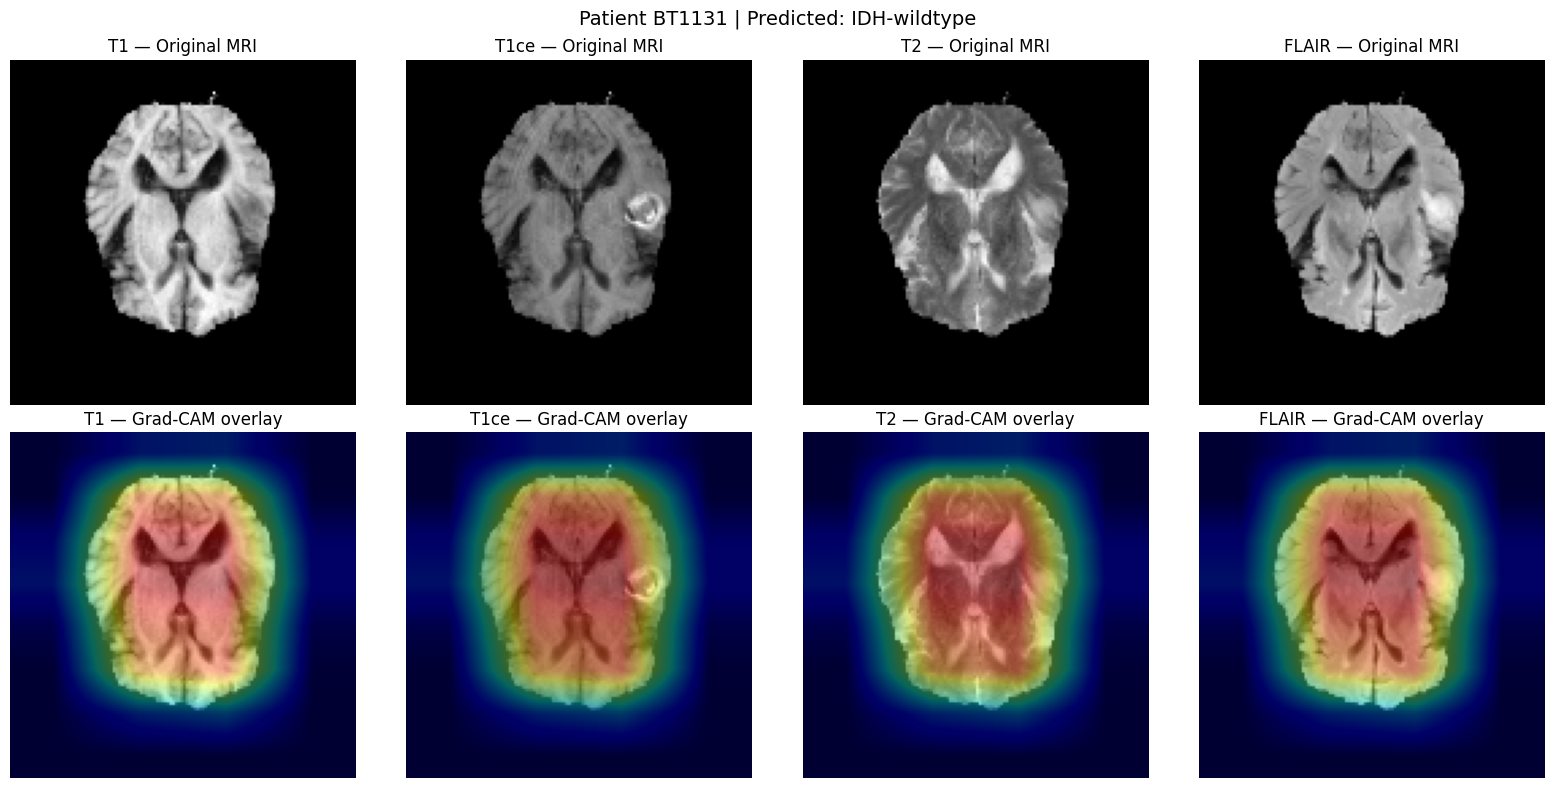

In [25]:

# MRI input layout: [batch, modality, height, width, depth]
mri_np = mri_input[0].detach().cpu().numpy()

modality_names = ["T1", "T1ce", "T2", "FLAIR"]

# Choose the slice with the greatest total Grad-CAM activation.
slice_activations = cam.sum(axis=(0, 1))
slice_z = int(np.argmax(slice_activations))

print("Patient:", patient_id)
print("Selected axial slice:", slice_z)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for channel, name in enumerate(modality_names):
    image_slice = mri_np[channel, :, :, slice_z]
    heat_slice = cam[:, :, slice_z]

    axes[0, channel].imshow(
        image_slice.T, cmap="gray", origin="lower"
    )
    axes[0, channel].set_title(f"{name} — Original MRI")
    axes[0, channel].axis("off")

    axes[1, channel].imshow(
        image_slice.T, cmap="gray", origin="lower"
    )
    axes[1, channel].imshow(
        heat_slice.T,
        cmap="jet",
        alpha=0.4,
        vmin=0,
        vmax=1,
        origin="lower",
    )
    axes[1, channel].set_title(f"{name} — Grad-CAM overlay")
    axes[1, channel].axis("off")

fig.suptitle(
    f"Patient {patient_id} | "
    f"Predicted: {class_names[target_class]}",
    fontsize=14,
)
plt.tight_layout()
plt.show()


### Step 16: Refine Grad-CAM using the CNN feature extractor

The previous visualization used the tokenizer's convolutional projection layer. We will now generate a second Grad-CAM using the final convolutional layer within `cnn.features`.

This comparison will help us determine whether the CNN's own feature maps provide a more spatially informative explanation.

We will use the same patient, trained checkpoint, input data, and predicted class. No retraining will occur.

CNN Grad-CAM target layer: features.8
CNN Grad-CAM shape: (128, 128, 96)
Heatmap range: 0.0 to 1.0
Finite values: True


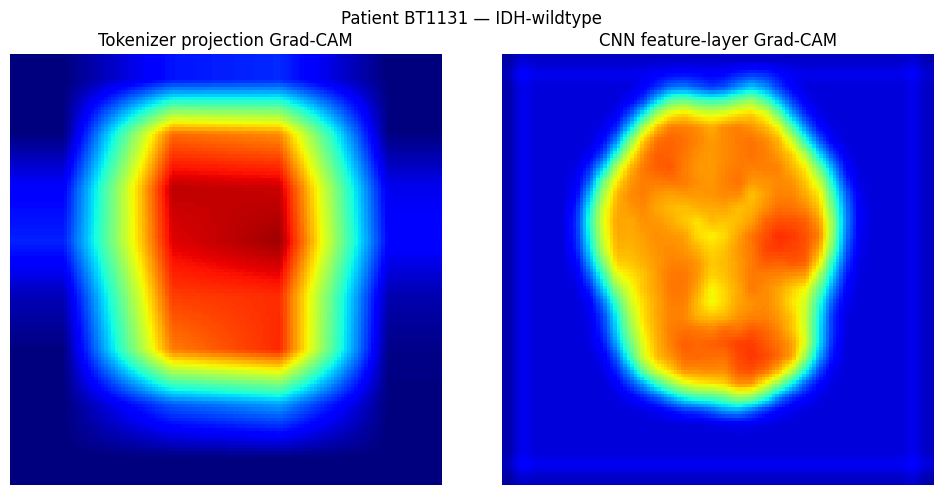

In [26]:

# Select the final convolutional layer inside the CNN branch.
cnn_conv_layers = [
    (name, module)
    for name, module in model.cnn.named_modules()
    if isinstance(module, nn.Conv3d)
]

if not cnn_conv_layers:
    raise RuntimeError("No 3D convolutional layers found inside model.cnn.")

cnn_layer_name, cnn_target_layer = cnn_conv_layers[-1]
print("CNN Grad-CAM target layer:", cnn_layer_name)

cnn_activations = {}
cnn_gradients = {}

def cnn_forward_hook(module, inputs, output):
    cnn_activations["value"] = output

def cnn_backward_hook(module, grad_input, grad_output):
    cnn_gradients["value"] = grad_output[0]

handle_f = cnn_target_layer.register_forward_hook(cnn_forward_hook)
handle_b = cnn_target_layer.register_full_backward_hook(cnn_backward_hook)

try:
    model.eval()
    model.zero_grad(set_to_none=True)

    mri_grad = mri_input.detach().clone().requires_grad_(True)
    logits_cnn = model(mri_grad, clinical_input)

    # Explain the same class as before.
    score = logits_cnn[0, target_class]
    score.backward()

    feature_maps = cnn_activations["value"]
    feature_grads = cnn_gradients["value"]

    weights = feature_grads.mean(
        dim=(2, 3, 4), keepdim=True
    )

    cnn_cam = F.relu(
        (weights * feature_maps).sum(dim=1, keepdim=True)
    )

    cnn_cam = F.interpolate(
        cnn_cam,
        size=mri_input.shape[2:],
        mode="trilinear",
        align_corners=False,
    )[0, 0].detach().cpu().numpy()

    cam_min, cam_max = cnn_cam.min(), cnn_cam.max()

    if cam_max - cam_min > 1e-8:
        cnn_cam = (cnn_cam - cam_min) / (cam_max - cam_min)
    else:
        warnings.warn("CNN Grad-CAM is nearly constant.")

finally:
    handle_f.remove()
    handle_b.remove()

print("CNN Grad-CAM shape:", cnn_cam.shape)
print("Heatmap range:", float(cnn_cam.min()), "to", float(cnn_cam.max()))
print("Finite values:", bool(np.isfinite(cnn_cam).all()))

assert cnn_cam.shape == (128, 128, 96)
assert np.isfinite(cnn_cam).all()

# Compare both explanations on the same axial slice.
slice_z = int(np.argmax(cnn_cam.sum(axis=(0, 1))))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cam[:, :, slice_z].T, cmap="jet", origin="lower", vmin=0, vmax=1)
axes[0].set_title("Tokenizer projection Grad-CAM")
axes[0].axis("off")

axes[1].imshow(cnn_cam[:, :, slice_z].T, cmap="jet", origin="lower", vmin=0, vmax=1)
axes[1].set_title("CNN feature-layer Grad-CAM")
axes[1].axis("off")

plt.suptitle(f"Patient {patient_id} — {class_names[target_class]}")
plt.tight_layout()
plt.show()


### Step 17: Validate the CNN Grad-CAM visualization

The CNN Grad-CAM produces a spatially varying heatmap, with stronger activations in selected regions. Before extending this process to the full test set, we will check its distribution and compare the heatmap with the original MRI anatomy.

We will then prepare a batch workflow that records predictions and saves Grad-CAM volumes for the held-out test patients. We will preserve the original checkpoint and avoid any retraining.

The batch analysis will include both correctly and incorrectly classified patients so that explanations are not evaluated only on successful predictions.

CNN Grad-CAM percentiles:
  0th percentile: 0.0000
 25th percentile: 0.0798
 50th percentile: 0.0865
 75th percentile: 0.1741
 90th percentile: 0.6841
 95th percentile: 0.7471
 99th percentile: 0.8016
100th percentile: 1.0000
Fraction >= 0.25: 21.9323%
Fraction >= 0.50: 15.2814%
Fraction >= 0.75: 4.7162%
Fraction >= 0.90: 0.0955%


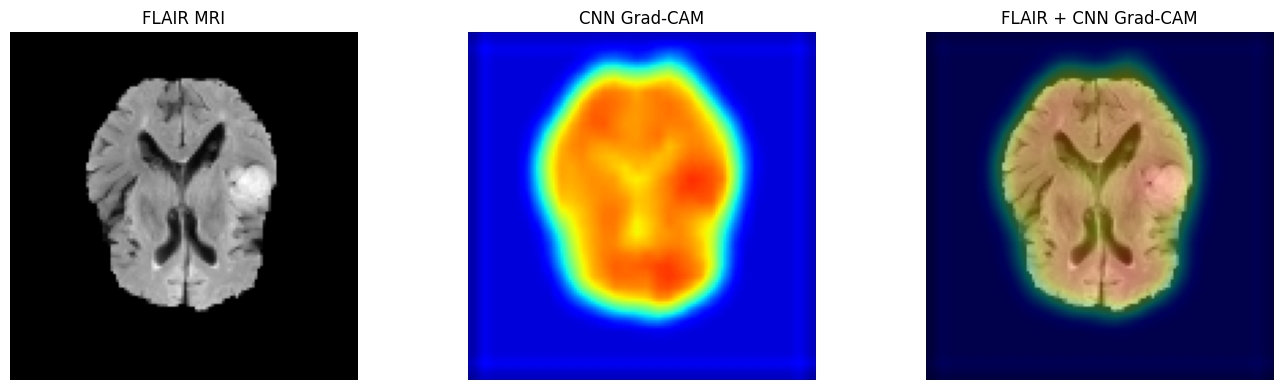

In [27]:

# Check whether the CNN heatmap is concentrated or diffuse.
assert cnn_cam.shape == (128, 128, 96)
assert np.isfinite(cnn_cam).all()

percentiles = np.percentile(cnn_cam, [0, 25, 50, 75, 90, 95, 99, 100])

print("CNN Grad-CAM percentiles:")
for p, value in zip([0, 25, 50, 75, 90, 95, 99, 100], percentiles):
    print(f"{p:3d}th percentile: {value:.4f}")

# Fraction of voxels exceeding selected normalized activation thresholds.
for threshold in [0.25, 0.50, 0.75, 0.90]:
    fraction = float(np.mean(cnn_cam >= threshold))
    print(f"Fraction >= {threshold:.2f}: {fraction:.4%}")

# Show the original MRI and CNN Grad-CAM overlay for the selected slice.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(mri_np[3, :, :, slice_z].T, cmap="gray", origin="lower")
axes[0].set_title("FLAIR MRI")
axes[0].axis("off")

axes[1].imshow(cnn_cam[:, :, slice_z].T, cmap="jet", origin="lower",
               vmin=0, vmax=1)
axes[1].set_title("CNN Grad-CAM")
axes[1].axis("off")

axes[2].imshow(mri_np[3, :, :, slice_z].T, cmap="gray", origin="lower")
axes[2].imshow(cnn_cam[:, :, slice_z].T, cmap="jet", alpha=0.35,
               origin="lower", vmin=0, vmax=1)
axes[2].set_title("FLAIR + CNN Grad-CAM")
axes[2].axis("off")

plt.tight_layout()
plt.show()


### Step 18: Improve the visualization using MRI foreground masking

Grad-CAM can produce activation outside the visible brain because it explains the model's feature maps, not an anatomical segmentation.

We will create a simple foreground mask from the MRI volume and use it only for visualization. This will reduce heatmap display in empty background regions.

The original Grad-CAM volume will remain unchanged. This masking step is a visualization aid, not a validated brain or tumor segmentation algorithm.

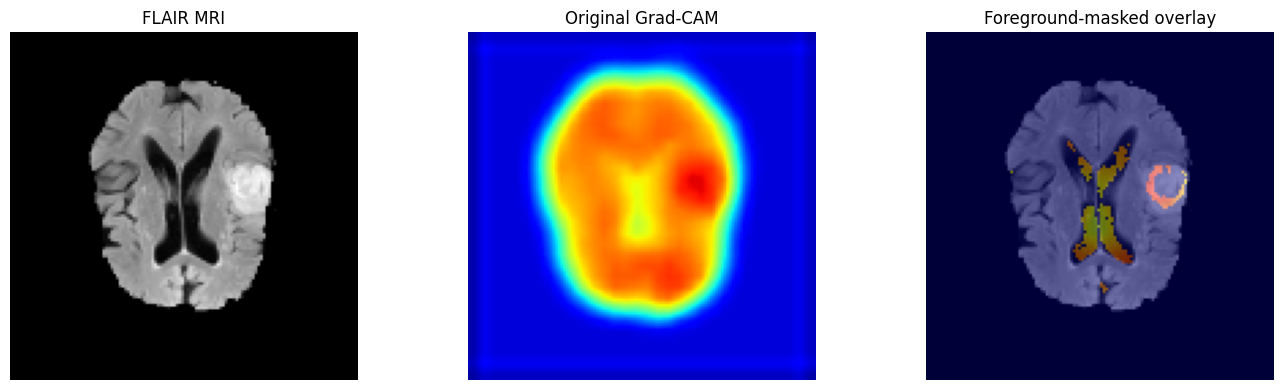

Original heatmap preserved: (128, 128, 96)
Foreground mask shape: (128, 128, 96)
Foreground voxel fraction: 0.002


In [28]:

# Use the four-modality MRI volume already loaded for the current patient.
# This mask is only a simple visualization aid, not a medical segmentation.

mri_np = mri_input[0].detach().cpu().numpy()

# A voxel is considered foreground if any modality has non-negligible signal.
foreground_signal = np.max(np.abs(mri_np), axis=0)
threshold = np.percentile(foreground_signal, 20)
foreground_mask = foreground_signal > max(float(threshold), 1e-6)

# Retain the original Grad-CAM and create a separate masked copy.
cnn_cam_masked = cnn_cam * foreground_mask.astype(np.float32)

slice_z = int(np.argmax(cnn_cam_masked.sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(
    mri_np[3, :, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[0].set_title("FLAIR MRI")
axes[0].axis("off")

axes[1].imshow(
    cnn_cam[:, :, slice_z].T,
    cmap="jet",
    origin="lower",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Original Grad-CAM")
axes[1].axis("off")

axes[2].imshow(
    mri_np[3, :, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[2].imshow(
    cnn_cam_masked[:, :, slice_z].T,
    cmap="jet",
    alpha=0.45,
    origin="lower",
    vmin=0,
    vmax=1,
)
axes[2].set_title("Foreground-masked overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

print("Original heatmap preserved:", cnn_cam.shape)
print("Foreground mask shape:", foreground_mask.shape)
print("Foreground voxel fraction:", round(float(foreground_mask.mean()), 4))


### Step 19: Correct the foreground mask for visualization

The initial foreground mask retained too few voxels because its threshold was not suitable for the intensity distribution of the preprocessed MRI.

We will replace it with a slice-wise threshold based on the FLAIR intensity range. We will use the resulting mask only to suppress background during visualization.

This operation does not modify the MRI, the trained model, or the original Grad-CAM values. It is not a clinical brain segmentation algorithm, and its output must be checked visually.

MRI shape: (128, 128, 96)
Mask shape: (128, 128, 96)
Foreground voxel fraction: 0.0563
Original Grad-CAM unchanged: True


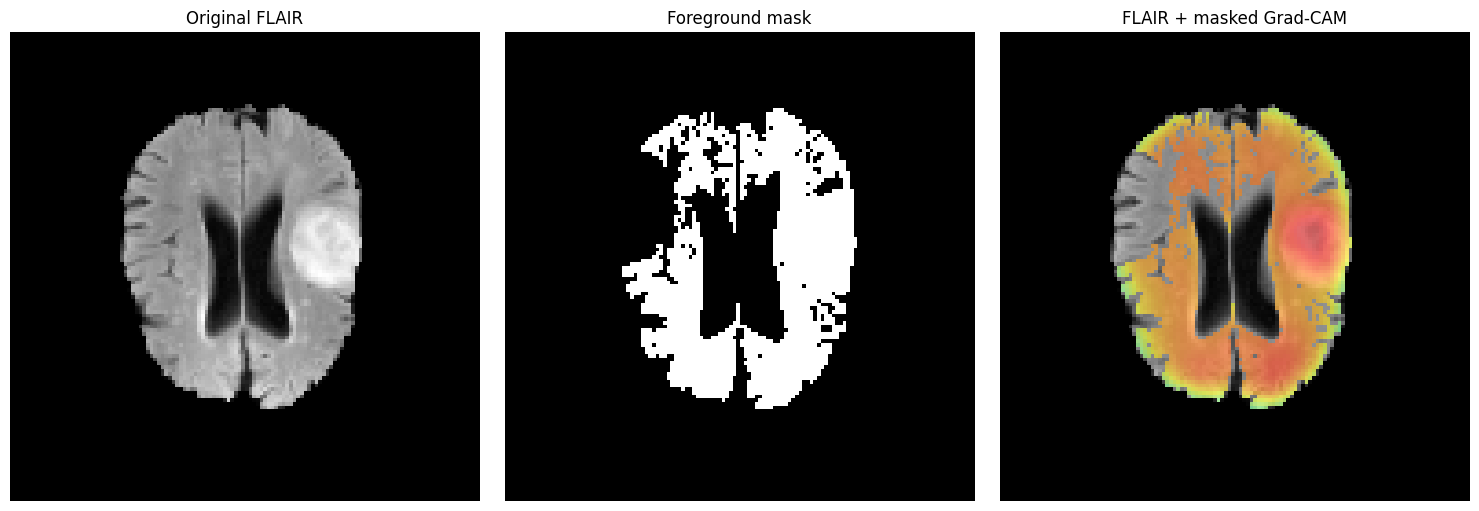

In [29]:

from scipy import ndimage

# Preserve the original MRI and Grad-CAM.
flair_volume = mri_np[3].astype(np.float32)
cam_original = cnn_cam.copy()

foreground_mask = np.zeros(flair_volume.shape, dtype=bool)

# Create a separate mask for each axial slice.
for z in range(flair_volume.shape[2]):
    slice_img = flair_volume[:, :, z]

    # Use the nonzero intensity range within this slice.
    positive = slice_img[np.isfinite(slice_img) & (slice_img > 0)]

    if positive.size == 0:
        continue

    slice_max = float(positive.max())
    if slice_max <= 0:
        continue

    # Conservative relative threshold for visualization only.
    threshold = 0.05 * slice_max
    slice_mask = slice_img > threshold

    # Remove tiny isolated components.
    labels, count = ndimage.label(slice_mask)
    if count > 0:
        component_sizes = np.bincount(labels.ravel())
        component_sizes[0] = 0
        largest_label = int(component_sizes.argmax())
        slice_mask = labels == largest_label

    foreground_mask[:, :, z] = slice_mask

# Apply mask only to the displayed heatmap.
cnn_cam_masked = cam_original * foreground_mask.astype(np.float32)

print("MRI shape:", flair_volume.shape)
print("Mask shape:", foreground_mask.shape)
print("Foreground voxel fraction:",
      round(float(foreground_mask.mean()), 4))
print("Original Grad-CAM unchanged:",
      np.array_equal(cam_original, cnn_cam))

# Inspect the slice with the strongest masked activation.
slice_z = int(np.argmax(cnn_cam_masked.sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(
    flair_volume[:, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[0].set_title("Original FLAIR")
axes[0].axis("off")

axes[1].imshow(
    foreground_mask[:, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[1].set_title("Foreground mask")
axes[1].axis("off")

axes[2].imshow(
    flair_volume[:, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[2].imshow(
    np.ma.masked_where(
        cnn_cam_masked[:, :, slice_z].T <= 0,
        cnn_cam_masked[:, :, slice_z].T,
    ),
    cmap="jet",
    alpha=0.55,
    origin="lower",
    vmin=0,
    vmax=1,
)
axes[2].set_title("FLAIR + masked Grad-CAM")
axes[2].axis("off")

plt.tight_layout()
plt.show()


### Step 20: Generate Grad-CAM explanations for the held-out test set

We will extend the verified single-patient Grad-CAM procedure to every patient in the comparison-training test split.

For each patient, we will:
1. Load the cached MRI volume and clinical features.
2. Generate the predicted IDH class and probabilities.
3. Compute Grad-CAM for the predicted class using the final CNN convolutional layer.
4. Save the heatmap as a NumPy volume.
5. Record the true label, predicted label, class probabilities and prediction correctness.

The explanations will be saved separately from the trained checkpoint. This is an inference-only process; it does not retrain or update model weights.

In [30]:

import gc
import traceback
from pathlib import Path

OUTPUT_DIR = (
    Path("/content/drive/MyDrive/Glioma_Research")
    / "explainability"
    / "gradcam_test"
)
HEATMAP_DIR = OUTPUT_DIR / "heatmaps"
HEATMAP_DIR.mkdir(parents=True, exist_ok=True)

# Use the final convolutional layer inside the CNN branch.
target_layer = dict(model.cnn.named_modules())["features.8"]

batch_activations = {}
batch_gradients = {}

def batch_forward_hook(module, inputs, output):
    batch_activations["value"] = output

def batch_backward_hook(module, grad_input, grad_output):
    batch_gradients["value"] = grad_output[0]

handle_f = target_layer.register_forward_hook(batch_forward_hook)
handle_b = target_layer.register_full_backward_hook(batch_backward_hook)

results = []
errors = []

try:
    model.eval()

    for idx in range(len(test_df)):
        row = test_df.iloc[idx]
        pid = str(row["Subject_ID"])
        cache_path = TEST_CACHE / f"{pid}.npy"

        try:
            if not cache_path.is_file():
                raise FileNotFoundError(f"MRI cache missing: {cache_path}")

            volume = np.load(cache_path).astype(np.float32)

            if volume.shape != (4, 128, 128, 96):
                raise ValueError(f"Unexpected MRI shape: {volume.shape}")

            x_mri = torch.from_numpy(volume).unsqueeze(0).to(DEVICE)
            x_clinical = torch.tensor(
                [[float(row["Age_Scaled"]), float(row["Sex_Encoded"])]],
                dtype=torch.float32,
                device=DEVICE,
            )

            model.zero_grad(set_to_none=True)

            logits_i = model(x_mri, x_clinical)
            probs_i = torch.softmax(logits_i.detach(), dim=1)
            pred_i = int(logits_i.argmax(dim=1).item())
            true_i = int(row["IDH_Label"])

            # Explain the predicted class.
            model.zero_grad(set_to_none=True)
            batch_logits = model(x_mri, x_clinical)
            score = batch_logits[0, pred_i]
            score.backward()

            acts = batch_activations["value"]
            grads = batch_gradients["value"]

            weights = grads.mean(dim=(2, 3, 4), keepdim=True)
            cam_i = F.relu((weights * acts).sum(dim=1, keepdim=True))

            cam_i = F.interpolate(
                cam_i,
                size=x_mri.shape[2:],
                mode="trilinear",
                align_corners=False,
            )[0, 0].detach().cpu().numpy()

            cam_min, cam_max = float(cam_i.min()), float(cam_i.max())
            if cam_max - cam_min > 1e-8:
                cam_i = (cam_i - cam_min) / (cam_max - cam_min)
            else:
                warnings.warn(f"{pid}: nearly constant Grad-CAM.")

            heatmap_path = HEATMAP_DIR / f"{pid}_gradcam.npy"
            np.save(heatmap_path, cam_i.astype(np.float32))

            results.append({
                "Subject_ID": pid,
                "True_Label": true_i,
                "Predicted_Label": pred_i,
                "True_Class": class_names[true_i],
                "Predicted_Class": class_names[pred_i],
                "Probability_Wildtype": float(probs_i[0, 0].cpu()),
                "Probability_Mutated": float(probs_i[0, 1].cpu()),
                "Correct": bool(pred_i == true_i),
                "GradCAM_Path": str(heatmap_path),
                "GradCAM_Max": float(cam_i.max()),
                "GradCAM_Mean": float(cam_i.mean()),
            })

        except Exception as exc:
            errors.append({
                "Subject_ID": pid,
                "Error": repr(exc),
            })
            print(f"ERROR for {pid}: {exc}")

        finally:
            if "x_mri" in locals():
                del x_mri
            if "x_clinical" in locals():
                del x_clinical
            if "volume" in locals():
                del volume

        if (idx + 1) % 10 == 0 or idx + 1 == len(test_df):
            print(
                f"Processed {idx + 1}/{len(test_df)} patients | "
                f"successful: {len(results)} | failed: {len(errors)}"
            )

        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()

finally:
    handle_f.remove()
    handle_b.remove()
    gc.collect()

results_df = pd.DataFrame(results)
errors_df = pd.DataFrame(errors)

results_path = OUTPUT_DIR / "gradcam_test_predictions.csv"
results_df.to_csv(results_path, index=False)

if not errors_df.empty:
    errors_df.to_csv(OUTPUT_DIR / "gradcam_errors.csv", index=False)

print("\nBatch processing finished.")
print("Successful patients:", len(results_df))
print("Failed patients:", len(errors_df))
print("Results CSV:", results_path)
print("Heatmap directory:", HEATMAP_DIR)


/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0364: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0324: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0007: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0667: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0969: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")


Processed 10/94 patients | successful: 10 | failed: 0


/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1106: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1244: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")


Processed 20/94 patients | successful: 20 | failed: 0


/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0945: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0653: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0679: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")


Processed 30/94 patients | successful: 30 | failed: 0


... (8 outputs left out)

/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1046: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0460: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0972: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0929: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0306: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT0616: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")


Processed 80/94 patients | successful: 80 | failed: 0


/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1250: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1120: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")
/tmp/ipykernel_493/510230026.py:85: UserWarning: BT1070: nearly constant Grad-CAM.
  warnings.warn(f"{pid}: nearly constant Grad-CAM.")


Processed 90/94 patients | successful: 90 | failed: 0
Processed 94/94 patients | successful: 94 | failed: 0

Batch processing finished.
Successful patients: 94
Failed patients: 0
Results CSV: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_test_predictions.csv
Heatmap directory: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/heatmaps


### Step 21: Cohort-level explanation quality and prediction summary

We will analyze the saved predictions and heatmaps across the entire held-out test set.

This analysis will:
- Summarize classification accuracy and the distribution of true and predicted classes.
- Check the saved heatmaps for constant, zero-valued or otherwise degenerate outputs.
- Separate successful heatmap generation from heatmap quality.

These checks are preliminary quality-control measures. They do not establish that Grad-CAM is faithful or clinically meaningful; further perturbation and stability testing will be needed.

=== Prediction summary ===
Patients processed: 94
Accuracy: 0.8085
Balanced accuracy: 0.7441

Confusion matrix (rows=true, columns=predicted; labels 0, 1):
[[60  7]
 [11 16]]

Classification report:
              precision    recall  f1-score   support

IDH-wildtype       0.85      0.90      0.87        67
 IDH-mutated       0.70      0.59      0.64        27

    accuracy                           0.81        94
   macro avg       0.77      0.74      0.75        94
weighted avg       0.80      0.81      0.80        94


=== Heatmap quality flags ===
Quality_flag
NONCONSTANT      63
NEAR_CONSTANT    31
Name: count, dtype: int64

Saved quality report: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_quality_checks.csv


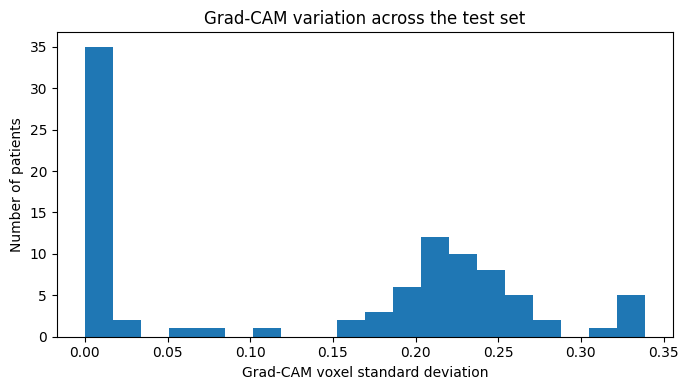

,Subject_ID,True_Label,Predicted_Label,Heatmap_exists,Min,Max,Std,Nonzero_fraction,Quality_flag
3,BT0364,0,0,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
5,BT0324,1,1,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
7,BT0007,1,1,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
8,BT0667,0,0,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
9,BT0969,1,1,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
15,BT1106,0,1,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
18,BT1244,0,0,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
21,BT0945,0,0,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
22,BT0653,0,0,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT
27,BT0679,0,1,True,0.0,0.0,0.0,0.0,NEAR_CONSTANT


In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/explainability/gradcam_test"
)
HEATMAP_DIR = OUTPUT_DIR / "heatmaps"
RESULTS_PATH = OUTPUT_DIR / "gradcam_test_predictions.csv"

results_df = pd.read_csv(RESULTS_PATH)

required_columns = {
    "Subject_ID",
    "True_Label",
    "Predicted_Label",
    "Probability_Wildtype",
    "Probability_Mutated",
    "GradCAM_Path",
}
missing_columns = required_columns - set(results_df.columns)

if missing_columns:
    raise ValueError(f"Missing expected result columns: {sorted(missing_columns)}")

y_true = results_df["True_Label"].astype(int).to_numpy()
y_pred = results_df["Predicted_Label"].astype(int).to_numpy()

print("=== Prediction summary ===")
print("Patients processed:", len(results_df))
print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_true, y_pred), 4))

print("\nConfusion matrix (rows=true, columns=predicted; labels 0, 1):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["IDH-wildtype", "IDH-mutated"],
    zero_division=0,
))

# Inspect each saved heatmap for degeneracy.
quality_rows = []

for _, row in results_df.iterrows():
    path = Path(row["GradCAM_Path"])

    if not path.is_file():
        quality_rows.append({
            "Subject_ID": row["Subject_ID"],
            "Heatmap_exists": False,
            "Min": np.nan,
            "Max": np.nan,
            "Std": np.nan,
            "Nonzero_fraction": np.nan,
            "Quality_flag": "MISSING",
        })
        continue

    heatmap = np.load(path)

    if not np.isfinite(heatmap).all():
        flag = "NONFINITE"
    elif float(np.std(heatmap)) < 1e-6:
        flag = "NEAR_CONSTANT"
    elif float(np.max(heatmap)) <= 1e-8:
        flag = "ALL_ZERO"
    else:
        flag = "NONCONSTANT"

    quality_rows.append({
        "Subject_ID": row["Subject_ID"],
        "Heatmap_exists": True,
        "Min": float(np.min(heatmap)),
        "Max": float(np.max(heatmap)),
        "Std": float(np.std(heatmap)),
        "Nonzero_fraction": float(np.mean(heatmap > 1e-8)),
        "Quality_flag": flag,
    })

quality_df = pd.DataFrame(quality_rows)
quality_df = results_df[["Subject_ID", "True_Label", "Predicted_Label"]].merge(
    quality_df, on="Subject_ID", how="left"
)

print("\n=== Heatmap quality flags ===")
print(quality_df["Quality_flag"].value_counts(dropna=False))

quality_path = OUTPUT_DIR / "gradcam_quality_checks.csv"
quality_df.to_csv(quality_path, index=False)

print("\nSaved quality report:", quality_path)

# Visualize the distribution of heatmap standard deviations.
plt.figure(figsize=(7, 4))
plt.hist(quality_df["Std"].dropna(), bins=20)
plt.xlabel("Grad-CAM voxel standard deviation")
plt.ylabel("Number of patients")
plt.title("Grad-CAM variation across the test set")
plt.tight_layout()
plt.show()

display(
    quality_df[
        quality_df["Quality_flag"] != "NONCONSTANT"
    ].head(30)
)


### Step 22: Investigate near-constant Grad-CAM outputs

Sixteen patients have zero-valued Grad-CAM maps. We will inspect the saved quality report and identify these patients.

The next diagnostic will compare the CNN feature activations, gradients, and pre-ReLU class activation map for one affected patient. This will help determine whether the issue occurs before or after the ReLU operation.

We will not modify the checkpoint or replace the failed explanations with artificial heatmaps.

In [32]:

from pathlib import Path
import numpy as np
import pandas as pd

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/explainability/gradcam_test"
)

quality_path = OUTPUT_DIR / "gradcam_quality_checks.csv"
results_path = OUTPUT_DIR / "gradcam_test_predictions.csv"

quality_df = pd.read_csv(quality_path)
results_df = pd.read_csv(results_path)

failed_ids = quality_df.loc[
    quality_df["Quality_flag"].isin(["NEAR_CONSTANT", "ALL_ZERO"]),
    "Subject_ID"
].astype(str).tolist()

print("Affected patients:", len(failed_ids))
print("Patient IDs:", failed_ids)

if not failed_ids:
    raise RuntimeError("No degenerate heatmaps found in the quality report.")

diagnostic_patient_id = failed_ids[0]
patient_row = results_df.loc[
    results_df["Subject_ID"].astype(str) == diagnostic_patient_id
].iloc[0]

saved_cam = np.load(patient_row["GradCAM_Path"])

print("\nSelected patient:", diagnostic_patient_id)
print("True class:", patient_row["True_Class"])
print("Predicted class:", patient_row["Predicted_Class"])
print("Saved heatmap shape:", saved_cam.shape)
print("Minimum:", float(saved_cam.min()))
print("Maximum:", float(saved_cam.max()))
print("Standard deviation:", float(saved_cam.std()))
print("Unique values:", np.unique(saved_cam).size)


Affected patients: 31
Patient IDs: ['BT0364', 'BT0324', 'BT0007', 'BT0667', 'BT0969', 'BT1106', 'BT1244', 'BT0945', 'BT0653', 'BT0679', 'BT0045', 'BT0661', 'BT0970', 'BT1285', 'BT0373', 'BT1102', 'BT0315', 'BT0089', 'BT1036', 'BT1209', 'BT0836', 'BT0930', 'BT1046', 'BT0460', 'BT0972', 'BT0929', 'BT0306', 'BT0616', 'BT1250', 'BT1120', 'BT1070']

Selected patient: BT0364
True class: IDH-wildtype
Predicted class: IDH-wildtype
Saved heatmap shape: (128, 128, 96)
Minimum: 0.0
Maximum: 0.0
Standard deviation: 0.0
Unique values: 1


### Step 23: Inspect Grad-CAM gradients and activations

We will rerun the Grad-CAM calculation for BT0364 and inspect the CNN feature activations, their gradients, the raw class activation map before ReLU, and the map after ReLU.

This diagnostic will help identify where the explanation becomes zero. We will use the same checkpoint, selected CNN layer, clinical preprocessing and predicted class as the original batch run.

No model weights will be modified.

In [33]:

import numpy as np
import torch
import torch.nn.functional as F
from pathlib import Path

diagnostic_patient_id = "BT0364"

row = test_df.loc[
    test_df["Subject_ID"].astype(str) == diagnostic_patient_id
].iloc[0]

volume_path = TEST_CACHE / f"{diagnostic_patient_id}.npy"
assert volume_path.is_file(), f"MRI file not found: {volume_path}"

volume = np.load(volume_path).astype(np.float32)
x_mri = torch.from_numpy(volume).unsqueeze(0).to(DEVICE)

x_clinical = torch.tensor(
    [[float(row["Age_Scaled"]), float(row["Sex_Encoded"])]],
    dtype=torch.float32,
    device=DEVICE,
)

target_layer = model.cnn.features[8]
captured = {}

def save_activation(module, inputs, output):
    captured["activation"] = output

def save_gradient(module, grad_input, grad_output):
    captured["gradient"] = grad_output[0]

handle_f = target_layer.register_forward_hook(save_activation)
handle_b = target_layer.register_full_backward_hook(save_gradient)

try:
    model.eval()
    model.zero_grad(set_to_none=True)

    logits = model(x_mri, x_clinical)
    predicted_class = int(logits.argmax(dim=1).item())
    score = logits[0, predicted_class]
    score.backward()

    activation = captured["activation"].detach()
    gradient = captured["gradient"].detach()

    channel_weights = gradient.mean(dim=(2, 3, 4), keepdim=True)
    raw_cam = (channel_weights * activation).sum(dim=1, keepdim=True)
    relu_cam = F.relu(raw_cam)

    print("Patient:", diagnostic_patient_id)
    print("Predicted class:", class_names[predicted_class])
    print("Logits:", logits.detach().cpu().numpy())

    for name, tensor in [
        ("CNN activation", activation),
        ("CNN gradient", gradient),
        ("Channel weights", channel_weights),
        ("Raw CAM before ReLU", raw_cam),
        ("CAM after ReLU", relu_cam),
    ]:
        print(
            f"\n{name}: shape={tuple(tensor.shape)}, "
            f"min={tensor.min().item():.6g}, "
            f"max={tensor.max().item():.6g}, "
            f"mean={tensor.mean().item():.6g}, "
            f"std={tensor.std().item():.6g}, "
            f"nonzero={(tensor.abs() > 1e-12).float().mean().item():.4%}"
        )

finally:
    handle_f.remove()
    handle_b.remove()
    model.zero_grad(set_to_none=True)


Patient: BT0364
Predicted class: IDH-wildtype
Logits: [[ 1.3616754 -1.3136063]]

CNN activation: shape=(1, 128, 32, 32, 24), min=-10.6893, max=8.55995, mean=0.126539, std=2.1113, nonzero=100.0000%

CNN gradient: shape=(1, 128, 32, 32, 24), min=-1.48799e-07, max=4.64643e-07, mean=2.30323e-09, std=3.91569e-08, nonzero=41.3094%

Channel weights: shape=(1, 128, 1, 1, 1), min=-1.12046e-07, max=8.38011e-08, mean=2.30323e-09, std=2.82583e-08, nonzero=100.0000%

Raw CAM before ReLU: shape=(1, 1, 32, 32, 24), min=-3.56448e-06, max=-4.76142e-07, mean=-1.74555e-06, std=4.14874e-07, nonzero=100.0000%

CAM after ReLU: shape=(1, 1, 32, 32, 24), min=0, max=0, mean=0, std=0, nonzero=0.0000%


### Step 24: Inspect signed Grad-CAM evidence

The standard Grad-CAM map retains positive contributions after applying ReLU. When the entire raw map is negative, the positive-evidence map becomes zero.

We will visualize the positive and negative components separately for BT0364. The negative component represents regions associated with decreasing the selected class score under the Grad-CAM approximation; it is not proof of a causal or biological effect.

We will retain the original checkpoint and use this analysis only to diagnose the degenerate maps.

Raw CAM range: -3.5644752642838284e-06 -4.7614247478122707e-07
Positive evidence maximum: 0.0
Negative evidence maximum: 3.5644752642838284e-06


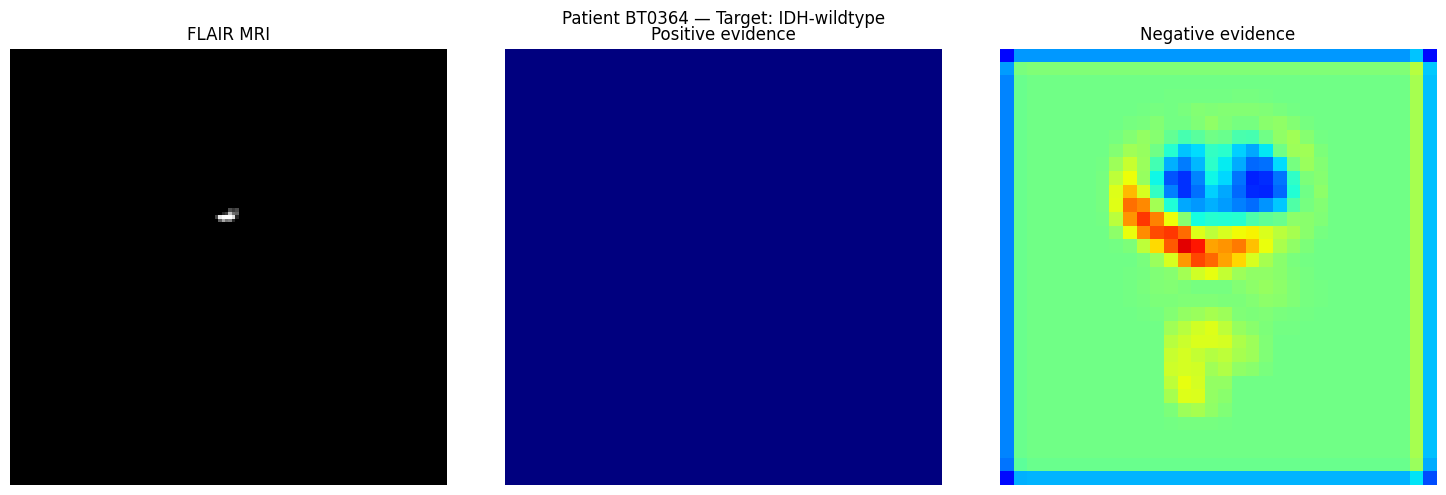

In [34]:

# Reuse raw_cam from Cell 23, which has shape [1, 1, D, H, W].
# No new hooks or model reconstruction are needed.

raw_cam_volume = raw_cam[0, 0].detach().cpu().numpy()

positive_cam = np.maximum(raw_cam_volume, 0)
negative_cam = np.maximum(-raw_cam_volume, 0)

def normalize_map(cam_array):
    cam_min = float(cam_array.min())
    cam_max = float(cam_array.max())

    if cam_max - cam_min < 1e-12:
        return np.zeros_like(cam_array, dtype=np.float32)

    return ((cam_array - cam_min) / (cam_max - cam_min)).astype(np.float32)

positive_cam_norm = normalize_map(positive_cam)
negative_cam_norm = normalize_map(negative_cam)

print("Raw CAM range:",
      float(raw_cam_volume.min()), float(raw_cam_volume.max()))
print("Positive evidence maximum:", float(positive_cam.max()))
print("Negative evidence maximum:", float(negative_cam.max()))

# Select a slice with the strongest signed evidence.
slice_z = int(np.argmax(np.abs(raw_cam_volume).sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(
    mri_np[3, :, :, slice_z].T,
    cmap="gray",
    origin="lower",
)
axes[0].set_title("FLAIR MRI")
axes[0].axis("off")

axes[1].imshow(
    positive_cam_norm[:, :, slice_z].T,
    cmap="jet",
    origin="lower",
    vmin=0,
    vmax=1,
)
axes[1].set_title("Positive evidence")
axes[1].axis("off")

axes[2].imshow(
    negative_cam_norm[:, :, slice_z].T,
    cmap="jet",
    origin="lower",
    vmin=0,
    vmax=1,
)
axes[2].set_title("Negative evidence")
axes[2].axis("off")

plt.suptitle(
    f"Patient {diagnostic_patient_id} — "
    f"Target: {class_names[predicted_class]}"
)
plt.tight_layout()
plt.show()


### Step 25: Compare CNN and tokenizer Grad-CAM for BT0364

The CNN layer produced an entirely negative raw CAM for BT0364. We will compare it with the tokenizer projection layer using the same patient, input tensors, checkpoint and target class.

For each layer, we will record the raw CAM minimum and maximum, the fraction of positive values, and the resulting positive-evidence map variation.

This comparison will help identify whether the degenerate result is specific to the selected layer. It does not by itself establish which layer provides the most faithful explanation.


CNN final convolution
  Raw minimum: -3.3999358493019827e-06
  Raw maximum: -4.7614247478122707e-07
  Positive voxel fraction: 0.0
  Positive CAM maximum: 0.0
  Positive CAM standard deviation: 0.0

Tokenizer projection
  Raw minimum: -4.913556404062547e-05
  Raw maximum: 0.0006313822814263403
  Positive voxel fraction: 0.33694712320963544
  Positive CAM maximum: 0.0006313822814263403
  Positive CAM standard deviation: 0.00014079756510909647


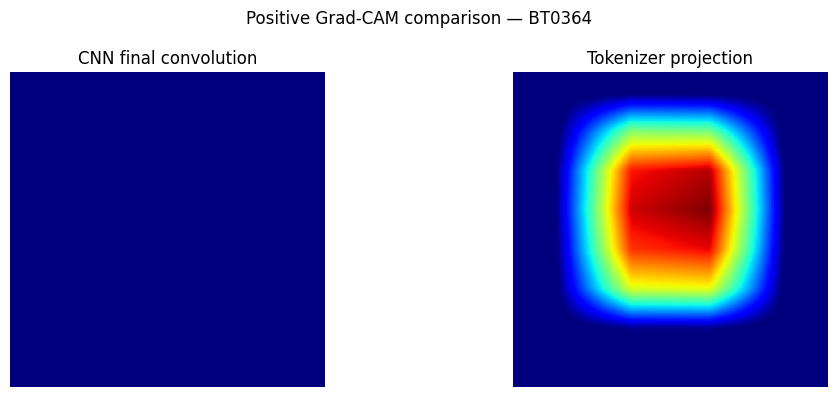

In [35]:

def get_raw_gradcam(model, layer, mri_tensor, clinical_tensor, target_class):
    captured = {}

    def fwd_hook(module, inputs, output):
        captured["activation"] = output

    def bwd_hook(module, grad_input, grad_output):
        captured["gradient"] = grad_output[0]

    h1 = layer.register_forward_hook(fwd_hook)
    h2 = layer.register_full_backward_hook(bwd_hook)

    try:
        model.eval()
        model.zero_grad(set_to_none=True)

        logits_local = model(mri_tensor, clinical_tensor)
        logits_local[0, target_class].backward()

        activation = captured["activation"].detach()
        gradient = captured["gradient"].detach()

        weights = gradient.mean(dim=(2, 3, 4), keepdim=True)
        raw = (weights * activation).sum(dim=1, keepdim=True)

        raw = F.interpolate(
            raw,
            size=mri_tensor.shape[2:],
            mode="trilinear",
            align_corners=False,
        )[0, 0].detach().cpu().numpy()

        return raw

    finally:
        h1.remove()
        h2.remove()
        model.zero_grad(set_to_none=True)


layers_to_compare = {
    "CNN final convolution": model.cnn.features[8],
    "Tokenizer projection": model.tokenizer.projection,
}

layer_results = {}

for layer_name, layer in layers_to_compare.items():
    raw = get_raw_gradcam(
        model,
        layer,
        x_mri,
        x_clinical,
        predicted_class,
    )

    positive = np.maximum(raw, 0)

    layer_results[layer_name] = {
        "raw": raw,
        "positive": positive,
    }

    print(f"\n{layer_name}")
    print("  Raw minimum:", float(raw.min()))
    print("  Raw maximum:", float(raw.max()))
    print("  Positive voxel fraction:", float(np.mean(raw > 0)))
    print("  Positive CAM maximum:", float(positive.max()))
    print("  Positive CAM standard deviation:", float(positive.std()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (layer_name, result) in zip(axes, layer_results.items()):
    positive = result["positive"]
    max_value = float(positive.max())

    if max_value > 1e-12:
        display_map = positive / max_value
    else:
        display_map = np.zeros_like(positive)

    z = int(np.argmax(display_map.sum(axis=(0, 1))))
    ax.imshow(display_map[:, :, z].T, cmap="jet", origin="lower", vmin=0, vmax=1)
    ax.set_title(layer_name)
    ax.axis("off")

plt.suptitle(f"Positive Grad-CAM comparison — {diagnostic_patient_id}")
plt.tight_layout()
plt.show()


### Step 26: Compare Grad-CAM layer suitability across affected patients

We will recompute positive-evidence Grad-CAM using the tokenizer projection layer for the 16 patients whose CNN Grad-CAM maps were zero.

For each patient, we will record the raw CAM range, the fraction of positive values, and the standard deviation of the normalized positive map. We will save these results separately from the original CNN Grad-CAM files.

This is a diagnostic comparison, not a final claim of explanation quality. Nonconstant maps may still be diffuse, unstable, or unfaithful.

In [36]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/explainability/gradcam_test"
)
TOKENIZER_DIR = OUTPUT_DIR / "tokenizer_gradcam_diagnostic"
TOKENIZER_DIR.mkdir(parents=True, exist_ok=True)

tokenizer_layer = model.tokenizer.projection
tokenizer_rows = []

model.eval()

for pid in failed_ids:
    row = test_df.loc[
        test_df["Subject_ID"].astype(str) == str(pid)
    ].iloc[0]

    volume = np.load(TEST_CACHE / f"{pid}.npy").astype(np.float32)
    x_mri = torch.from_numpy(volume).unsqueeze(0).to(DEVICE)

    x_clinical = torch.tensor(
        [[float(row["Age_Scaled"]), float(row["Sex_Encoded"])]],
        dtype=torch.float32,
        device=DEVICE,
    )

    # Use the model's current predicted class, consistent with the
    # original batch Grad-CAM procedure.
    with torch.no_grad():
        logits = model(x_mri, x_clinical)
        target_class = int(logits.argmax(dim=1).item())

    raw = get_raw_gradcam(
        model,
        tokenizer_layer,
        x_mri,
        x_clinical,
        target_class,
    )

    positive = np.maximum(raw, 0)
    pmax = float(positive.max())

    if pmax > 1e-12:
        normalized = positive / pmax
        flag = (
            "NONCONSTANT"
            if float(normalized.std()) >= 1e-6
            else "NEAR_CONSTANT"
        )
    else:
        normalized = np.zeros_like(positive, dtype=np.float32)
        flag = "ALL_ZERO"

    heatmap_path = TOKENIZER_DIR / f"{pid}_tokenizer_gradcam.npy"
    np.save(heatmap_path, normalized.astype(np.float32))

    tokenizer_rows.append({
        "Subject_ID": str(pid),
        "Target_Class": class_names[target_class],
        "Raw_CAM_Min": float(raw.min()),
        "Raw_CAM_Max": float(raw.max()),
        "Positive_Voxel_Fraction": float(np.mean(raw > 0)),
        "Positive_CAM_Max": pmax,
        "Normalized_CAM_Std": float(normalized.std()),
        "Quality_Flag": flag,
        "Heatmap_Path": str(heatmap_path),
    })

    print(f"{pid}: {flag}")

tokenizer_df = pd.DataFrame(tokenizer_rows)
report_path = TOKENIZER_DIR / "tokenizer_layer_diagnostic.csv"
tokenizer_df.to_csv(report_path, index=False)

print("\n=== Tokenizer layer diagnostic summary ===")
print(tokenizer_df["Quality_Flag"].value_counts())
print("Report saved:", report_path)

display(tokenizer_df)


BT0364: NONCONSTANT
BT0324: NONCONSTANT
BT0007: NONCONSTANT
BT0667: NONCONSTANT
BT0969: ALL_ZERO
BT1106: NONCONSTANT
BT1244: NONCONSTANT
BT0945: NONCONSTANT
BT0653: NONCONSTANT
BT0679: NONCONSTANT
BT0045: NONCONSTANT
BT0661: NONCONSTANT
BT0970: NONCONSTANT
BT1285: NONCONSTANT
BT0373: NONCONSTANT
BT1102: NONCONSTANT
BT0315: NONCONSTANT
BT0089: NONCONSTANT
BT1036: NONCONSTANT
BT1209: NONCONSTANT
BT0836: NONCONSTANT
BT0930: NONCONSTANT
BT1046: NONCONSTANT
BT0460: NONCONSTANT
BT0972: NONCONSTANT
BT0929: NONCONSTANT
BT0306: NONCONSTANT
BT0616: NONCONSTANT
BT1250: NONCONSTANT
BT1120: NONCONSTANT
BT1070: NONCONSTANT

=== Tokenizer layer diagnostic summary ===
Quality_Flag
NONCONSTANT    30
ALL_ZERO        1
Name: count, dtype: int64
Report saved: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/tokenizer_gradcam_diagnostic/tokenizer_layer_diagnostic.csv


,Subject_ID,Target_Class,Raw_CAM_Min,Raw_CAM_Max,Positive_Voxel_Fraction,Positive_CAM_Max,Normalized_CAM_Std,Quality_Flag,Heatmap_Path
0,BT0364,IDH-wildtype,-0.000049,0.000631,0.336947,0.000631,0.222999,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
1,BT0324,IDH-mutated,-0.000008,0.000003,0.665815,0.000003,0.350125,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
2,BT0007,IDH-mutated,-0.000017,0.000002,0.518979,0.000002,0.271261,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
3,BT0667,IDH-wildtype,-0.000046,0.000706,0.363396,0.000706,0.215647,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
4,BT0969,IDH-mutated,-0.000042,-0.000002,0.000000,0.000000,0.000000,ALL_ZERO,/content/drive/MyDrive/Glioma_Research/explain...
5,BT1106,IDH-mutated,-0.000102,0.000001,0.389079,0.000001,0.354705,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
6,BT1244,IDH-wildtype,-0.000025,0.000403,0.547019,0.000403,0.232047,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
7,BT0945,IDH-wildtype,-0.000045,0.000637,0.394279,0.000637,0.227456,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
8,BT0653,IDH-wildtype,-0.000027,0.000417,0.521931,0.000417,0.240514,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...
9,BT0679,IDH-mutated,-0.000017,0.000024,0.266151,0.000024,0.196336,NONCONSTANT,/content/drive/MyDrive/Glioma_Research/explain...


### Step 27: Visual quality check of tokenizer-layer Grad-CAM

We will visualize tokenizer-layer Grad-CAM for one IDH-wildtype patient and one IDH-mutated patient whose original CNN maps were degenerate.

The goal is to assess spatial distribution and alignment with the MRI anatomy. We will not infer that the model localizes the tumor correctly just because a heatmap is nonconstant.

The maps are normalized for display, so their displayed brightness should not be compared as a measure of importance across patients.

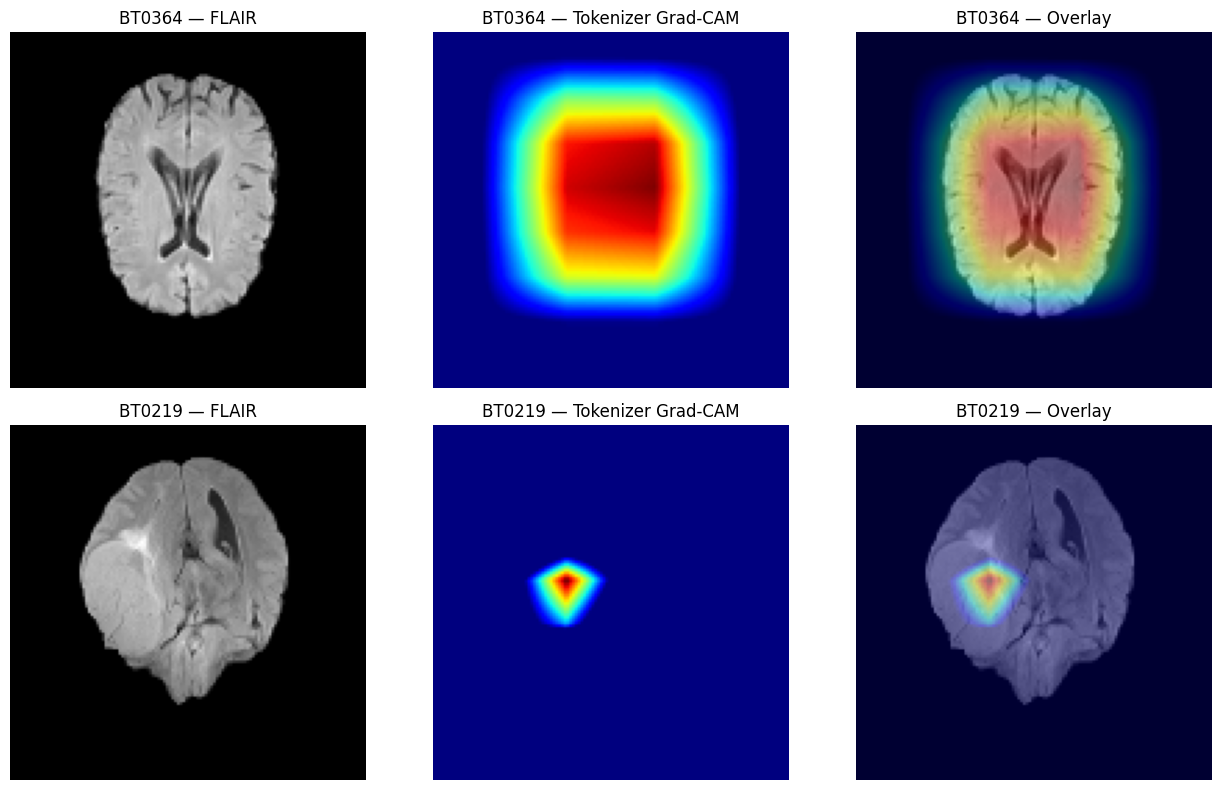

In [37]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

TOKENIZER_DIR = (
    Path("/content/drive/MyDrive/Glioma_Research")
    / "explainability"
    / "gradcam_test"
    / "tokenizer_gradcam_diagnostic"
)

patients_to_plot = ["BT0364", "BT0219"]
modality_index = 3  # FLAIR

fig, axes = plt.subplots(2, 3, figsize=(13, 8))

for r, pid in enumerate(patients_to_plot):
    volume = np.load(TEST_CACHE / f"{pid}.npy").astype(np.float32)
    heatmap = np.load(TOKENIZER_DIR / f"{pid}_tokenizer_gradcam.npy")

    # Use the axial slice with the largest heatmap activation.
    z = int(np.argmax(heatmap.sum(axis=(0, 1))))

    flair = volume[modality_index, :, :, z]
    heat_slice = heatmap[:, :, z]

    axes[r, 0].imshow(flair.T, cmap="gray", origin="lower")
    axes[r, 0].set_title(f"{pid} — FLAIR")
    axes[r, 0].axis("off")

    axes[r, 1].imshow(
        heat_slice.T, cmap="jet", origin="lower", vmin=0, vmax=1
    )
    axes[r, 1].set_title(f"{pid} — Tokenizer Grad-CAM")
    axes[r, 1].axis("off")

    axes[r, 2].imshow(flair.T, cmap="gray", origin="lower")
    axes[r, 2].imshow(
        heat_slice.T,
        cmap="jet",
        alpha=0.4,
        origin="lower",
        vmin=0,
        vmax=1,
    )
    axes[r, 2].set_title(f"{pid} — Overlay")
    axes[r, 2].axis("off")

plt.tight_layout()
plt.show()


### Step 28: Quantify tokenizer Grad-CAM concentration

We will calculate the fraction of total positive heatmap activation contained in the most highly activated voxels for each of the 16 affected patients.

We will report the top 1% and top 5% activation concentration as descriptive statistics. These measures help compare spatial concentration, but they do not establish faithfulness, tumor overlap, or clinical validity.

All calculations use the saved tokenizer Grad-CAM volumes without changing their values.

In [38]:

from pathlib import Path
import numpy as np
import pandas as pd

TOKENIZER_DIR = (
    Path("/content/drive/MyDrive/Glioma_Research")
    / "explainability"
    / "gradcam_test"
    / "tokenizer_gradcam_diagnostic"
)

concentration_rows = []

for pid in failed_ids:
    path = TOKENIZER_DIR / f"{pid}_tokenizer_gradcam.npy"

    if not path.exists():
        print(f"Missing heatmap: {pid}")
        continue

    cam_volume = np.load(path).astype(np.float64)
    values = np.clip(cam_volume.ravel(), 0, None)
    total = values.sum()

    if total <= 1e-12:
        concentration_rows.append({
            "Subject_ID": pid,
            "Top_1pct_Activation": np.nan,
            "Top_5pct_Activation": np.nan,
            "Heatmap_Std": float(values.std()),
            "Status": "ZERO_MAP",
        })
        continue

    sorted_values = np.sort(values)[::-1]
    n = len(sorted_values)

    top_1_count = max(1, int(np.ceil(0.01 * n)))
    top_5_count = max(1, int(np.ceil(0.05 * n)))

    concentration_rows.append({
        "Subject_ID": pid,
        "Top_1pct_Activation": float(
            sorted_values[:top_1_count].sum() / total
        ),
        "Top_5pct_Activation": float(
            sorted_values[:top_5_count].sum() / total
        ),
        "Heatmap_Std": float(values.std()),
        "Status": "OK",
    })

concentration_df = pd.DataFrame(concentration_rows)

concentration_path = TOKENIZER_DIR / "activation_concentration.csv"
concentration_df.to_csv(concentration_path, index=False)

display(
    concentration_df.sort_values(
        "Top_1pct_Activation", ascending=False
    )
)

print("Saved:", concentration_path)


,Subject_ID,Top_1pct_Activation,Top_5pct_Activation,Heatmap_Std,Status
9,BT0679,0.125746,0.515562,0.196336,OK
19,BT1209,0.105562,0.438582,0.189099,OK
24,BT0972,0.092943,0.403702,0.218825,OK
3,BT0667,0.087912,0.386222,0.215647,OK
27,BT0616,0.086761,0.376949,0.223223,OK
0,BT0364,0.085024,0.372584,0.222999,OK
14,BT0373,0.083472,0.366478,0.224442,OK
29,BT1120,0.081376,0.361115,0.225308,OK
25,BT0929,0.080834,0.356492,0.222734,OK
26,BT0306,0.079854,0.352741,0.232103,OK


Saved: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/tokenizer_gradcam_diagnostic/activation_concentration.csv


### Step 29: Evaluate whether Grad-CAM-highlighted regions influence predictions

We will perform a region-perturbation experiment on the held-out test set.

For each patient, we will compare three model outputs:

1. **Original MRI:** the unmodified MRI volume.
2. **High-activation perturbation:** blur the MRI voxels in the top 5% of the selected Grad-CAM map.
3. **Low-activation perturbation:** blur the MRI voxels in the bottom 5% of the same map.

The same spatial perturbation mask will be applied across all four MRI modalities, while the clinical features remain unchanged. We will measure the change in the probability assigned to the model's original predicted class.

If perturbing highly activated regions causes a larger probability reduction than perturbing low-activation regions, that supports the hypothesis that the highlighted regions are influential to the prediction.

This is a preliminary faithfulness test. Blurring can introduce distribution shifts, and the result depends on the perturbation method. We will therefore report the results as evidence about model sensitivity, not proof of clinical validity.

In [39]:

from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter

# ---------------------------------------------------------
# 1. Paths and input validation
# ---------------------------------------------------------
BASE_DIR = Path("/content/drive/MyDrive/Glioma_Research")
EXPLAIN_DIR = BASE_DIR / "explainability" / "gradcam_test"
HEATMAP_DIR = EXPLAIN_DIR / "heatmaps"
TOKENIZER_DIR = EXPLAIN_DIR / "tokenizer_gradcam_diagnostic"

results_df = pd.read_csv(EXPLAIN_DIR / "gradcam_test_predictions.csv")
quality_df = pd.read_csv(EXPLAIN_DIR / "gradcam_quality_checks.csv")

assert len(results_df) == 94, (
    f"Expected 94 test patients, found {len(results_df)}"
)

quality_lookup = quality_df.set_index("Subject_ID")["Quality_flag"].to_dict()

# Confirm that the comparison-training model is available.
model.eval()

# ---------------------------------------------------------
# 2. Perturbation settings
# ---------------------------------------------------------
TOP_FRACTION = 0.05
BLUR_SIGMA = 2.0  # voxel units, applied independently per modality

faithfulness_rows = []
faithfulness_errors = []

# ---------------------------------------------------------
# 3. Process each patient
# ---------------------------------------------------------
for idx, result_row in results_df.iterrows():
    pid = str(result_row["Subject_ID"])

    try:
        # Load the original comparison-training MRI cache.
        volume_path = TEST_CACHE / f"{pid}.npy"
        if not volume_path.is_file():
            raise FileNotFoundError(f"MRI cache not found: {volume_path}")

        volume = np.load(volume_path).astype(np.float32)

        if volume.shape != (4, 128, 128, 96):
            raise ValueError(f"Unexpected MRI shape for {pid}: {volume.shape}")

        # Use the original CNN heatmap unless it was flagged as degenerate.
        quality_flag = quality_lookup.get(pid, "UNKNOWN")

        if quality_flag in ("NEAR_CONSTANT", "ALL_ZERO"):
            heatmap_path = TOKENIZER_DIR / f"{pid}_tokenizer_gradcam.npy"
            selected_layer = "tokenizer.projection"
        else:
            heatmap_path = HEATMAP_DIR / f"{pid}_gradcam.npy"
            selected_layer = "cnn.features.8"

        if not heatmap_path.is_file():
            raise FileNotFoundError(
                f"Selected heatmap not found for {pid}: {heatmap_path}"
            )

        cam = np.load(heatmap_path).astype(np.float32)

        if cam.shape != volume.shape[1:]:
            raise ValueError(
                f"Heatmap shape {cam.shape} does not match MRI "
                f"shape {volume.shape[1:]} for {pid}"
            )

        if not np.isfinite(cam).all():
            raise ValueError(f"Non-finite heatmap for {pid}")

        # Build disjoint high- and low-activation masks.
        flat_cam = cam.ravel()
        n_voxels = flat_cam.size
        k = max(1, int(np.ceil(TOP_FRACTION * n_voxels)))

        order = np.argsort(flat_cam)
        low_mask = np.zeros(n_voxels, dtype=bool)
        high_mask = np.zeros(n_voxels, dtype=bool)

        low_mask[order[:k]] = True
        high_mask[order[-k:]] = True

        low_mask = low_mask.reshape(cam.shape)
        high_mask = high_mask.reshape(cam.shape)

        if np.any(low_mask & high_mask):
            raise RuntimeError(f"High/low masks overlap for {pid}")

        # Clinical inputs use the same fields as the original batch run.
        test_row = test_df.loc[
            test_df["Subject_ID"].astype(str) == pid
        ].iloc[0]

        x_clinical = torch.tensor(
            [[
                float(test_row["Age_Scaled"]),
                float(test_row["Sex_Encoded"]),
            ]],
            dtype=torch.float32,
            device=DEVICE,
        )

        # Create a blurred reference MRI for each modality.
        blurred_volume = np.stack([
            gaussian_filter(
                volume[channel],
                sigma=BLUR_SIGMA,
                mode="nearest",
            )
            for channel in range(volume.shape[0])
        ]).astype(np.float32)

        # Perturb identical spatial regions in all four modalities.
        volume_high = volume.copy()
        volume_low = volume.copy()

        for channel in range(4):
            volume_high[channel][high_mask] = blurred_volume[channel][high_mask]
            volume_low[channel][low_mask] = blurred_volume[channel][low_mask]

        x_original = torch.from_numpy(volume).unsqueeze(0).to(DEVICE)
        x_high = torch.from_numpy(volume_high).unsqueeze(0).to(DEVICE)
        x_low = torch.from_numpy(volume_low).unsqueeze(0).to(DEVICE)

        target_class = int(result_row["Predicted_Label"])

        with torch.no_grad():
            logits_original = model(x_original, x_clinical)
            logits_high = model(x_high, x_clinical)
            logits_low = model(x_low, x_clinical)

            p_original = torch.softmax(logits_original, dim=1)[0, target_class]
            p_high = torch.softmax(logits_high, dim=1)[0, target_class]
            p_low = torch.softmax(logits_low, dim=1)[0, target_class]

        original_prob = float(p_original.cpu())
        high_prob = float(p_high.cpu())
        low_prob = float(p_low.cpu())

        high_drop = original_prob - high_prob
        low_drop = original_prob - low_prob

        faithfulness_rows.append({
            "Subject_ID": pid,
            "True_Label": int(result_row["True_Label"]),
            "Target_Class": target_class,
            "Selected_Layer": selected_layer,
            "Original_Target_Probability": original_prob,
            "High_Activation_Target_Probability": high_prob,
            "Low_Activation_Target_Probability": low_prob,
            "High_Region_Probability_Drop": high_drop,
            "Low_Region_Probability_Drop": low_drop,
            "High_minus_Low_Drop": high_drop - low_drop,
            "High_Region_Drop_Larger": bool(high_drop > low_drop),
        })

    except Exception as exc:
        faithfulness_errors.append({
            "Subject_ID": pid,
            "Error": repr(exc),
        })
        print(f"ERROR {pid}: {exc}")

    finally:
        for variable_name in (
            "x_original", "x_high", "x_low",
            "x_clinical",
        ):
            if variable_name in locals():
                del locals()[variable_name]

    if (idx + 1) % 10 == 0 or idx + 1 == len(results_df):
        print(
            f"Processed {idx + 1}/{len(results_df)} | "
            f"successful: {len(faithfulness_rows)} | "
            f"errors: {len(faithfulness_errors)}"
        )

# ---------------------------------------------------------
# 4. Save detailed results
# ---------------------------------------------------------
faithfulness_df = pd.DataFrame(faithfulness_rows)
errors_df = pd.DataFrame(faithfulness_errors)

faithfulness_path = EXPLAIN_DIR / "gradcam_faithfulness_test.csv"
faithfulness_df.to_csv(faithfulness_path, index=False)

if not errors_df.empty:
    errors_df.to_csv(
        EXPLAIN_DIR / "gradcam_faithfulness_errors.csv",
        index=False,
    )

print("\n=== Faithfulness experiment summary ===")
print("Patients completed:", len(faithfulness_df))
print("Patients with errors:", len(errors_df))

if not faithfulness_df.empty:
    print(
        "Mean probability drop after high-region perturbation:",
        round(faithfulness_df["High_Region_Probability_Drop"].mean(), 4),
    )
    print(
        "Mean probability drop after low-region perturbation:",
        round(faithfulness_df["Low_Region_Probability_Drop"].mean(), 4),
    )
    print(
        "Mean high-minus-low drop:",
        round(faithfulness_df["High_minus_Low_Drop"].mean(), 4),
    )
    print(
        "Fraction with larger high-region drop:",
        round(faithfulness_df["High_Region_Drop_Larger"].mean(), 4),
    )

print("Detailed results saved to:", faithfulness_path)

display(faithfulness_df.head())


Processed 10/94 | successful: 10 | errors: 0
Processed 20/94 | successful: 20 | errors: 0
Processed 30/94 | successful: 30 | errors: 0
Processed 40/94 | successful: 40 | errors: 0
Processed 50/94 | successful: 50 | errors: 0
Processed 60/94 | successful: 60 | errors: 0
Processed 70/94 | successful: 70 | errors: 0
Processed 80/94 | successful: 80 | errors: 0
Processed 90/94 | successful: 90 | errors: 0
Processed 94/94 | successful: 94 | errors: 0

=== Faithfulness experiment summary ===
Patients completed: 94
Patients with errors: 0
Mean probability drop after high-region perturbation: -0.0
Mean probability drop after low-region perturbation: -0.0
Mean high-minus-low drop: 0.0
Fraction with larger high-region drop: 0.4894
Detailed results saved to: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_faithfulness_test.csv


,Subject_ID,True_Label,Target_Class,Selected_Layer,Original_Target_Probability,High_Activation_Target_Probability,Low_Activation_Target_Probability,High_Region_Probability_Drop,Low_Region_Probability_Drop,High_minus_Low_Drop,High_Region_Drop_Larger
0,BT1131,0,0,cnn.features.8,0.975808,0.975812,0.975808,-0.000004,0.000000e+00,-3.516674e-06,False
1,BT1103,0,0,cnn.features.8,0.961479,0.961482,0.961480,-0.000003,-1.013279e-06,-2.205372e-06,False
2,BT0643,1,1,cnn.features.8,0.856523,0.856524,0.856525,-0.000001,-1.609325e-06,2.980232e-07,True
3,BT0364,0,0,tokenizer.projection,0.935552,0.935508,0.935552,0.000045,-2.980232e-07,4.494190e-05,True
4,BT1100,0,0,cnn.features.8,0.963068,0.963076,0.963068,-0.000008,0.000000e+00,-8.285046e-06,False


### Step 30: Reconnect to the saved explainability results

The previous Colab runtime has disconnected, so the variables and loaded model are no longer available in memory.

We will reconnect Google Drive and verify that the outputs from the completed experiments are still present. We will not repeat any expensive computation during this step.

Once the files are confirmed, we will restore only the runtime components needed for the remaining explainability analyses.

In [40]:

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import pandas as pd
import numpy as np

BASE_DIR = Path("/content/drive/MyDrive/Glioma_Research")
EXPLAIN_DIR = BASE_DIR / "explainability" / "gradcam_test"

required_files = {
    "Prediction and Grad-CAM summary":
        EXPLAIN_DIR / "gradcam_test_predictions.csv",
    "Grad-CAM quality report":
        EXPLAIN_DIR / "gradcam_quality_checks.csv",
    "Faithfulness experiment":
        EXPLAIN_DIR / "gradcam_faithfulness_test.csv",
    "Tokenizer-layer diagnostic":
        EXPLAIN_DIR / "tokenizer_gradcam_diagnostic"
        / "tokenizer_layer_diagnostic.csv",
    "Activation concentration":
        EXPLAIN_DIR / "tokenizer_gradcam_diagnostic"
        / "activation_concentration.csv",
}

print("=== Saved explainability outputs ===")

for description, path in required_files.items():
    print(f"{description}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"  {path}")

# Load the completed faithfulness results if present.
faithfulness_path = required_files["Faithfulness experiment"]

if faithfulness_path.exists():
    faithfulness_df = pd.read_csv(faithfulness_path)
    print("\nFaithfulness rows:", len(faithfulness_df))
    print("Columns:", faithfulness_df.columns.tolist())

# Count the saved Grad-CAM volumes.
heatmap_dir = EXPLAIN_DIR / "heatmaps"
tokenizer_dir = EXPLAIN_DIR / "tokenizer_gradcam_diagnostic"

print("\nCNN Grad-CAM heatmaps:",
      len(list(heatmap_dir.glob("*_gradcam.npy")))
      if heatmap_dir.exists() else 0)

print("Tokenizer diagnostic heatmaps:",
      len(list(tokenizer_dir.glob("*_tokenizer_gradcam.npy")))
      if tokenizer_dir.exists() else 0)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== Saved explainability outputs ===
Prediction and Grad-CAM summary: FOUND
  /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_test_predictions.csv
Grad-CAM quality report: FOUND
  /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_quality_checks.csv
Faithfulness experiment: FOUND
  /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_faithfulness_test.csv
Tokenizer-layer diagnostic: FOUND
  /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/tokenizer_gradcam_diagnostic/tokenizer_layer_diagnostic.csv
Activation concentration: FOUND
  /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/tokenizer_gradcam_diagnostic/activation_concentration.csv

Faithfulness rows: 94
Columns: ['Subject_ID', 'True_Label', 'Target_Class', 'Selected_Layer', 'Original_Target_Probab

### Step 31: Locate the original comparison-training notebook and checkpoint

The Colab runtime has reset, so model definitions and dataset variables must be restored. We will use only the files associated with the comparison-training experiment.

First, we will locate the notebook, checkpoint, and recovery scripts. This prevents us from accidentally loading the earlier multimodal-training model.

In [41]:

from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Glioma_Research")
COMPARISON_DIR = BASE_DIR / "comparative_experiment"

print("Comparison directory exists:", COMPARISON_DIR.exists())

for folder in [
    COMPARISON_DIR / "models",
    COMPARISON_DIR / "results",
    BASE_DIR / "explainability" / "gradcam_test",
]:
    print(f"\n--- {folder} ---")

    if folder.exists():
        for item in sorted(folder.iterdir()):
            kind = "DIR " if item.is_dir() else "FILE"
            print(f"{kind} | {item.name}")
    else:
        print("MISSING")

print("\n--- Project recovery scripts ---")
for path in BASE_DIR.glob("*.py"):
    print(path.name)

print("\n--- Comparison-training notebooks ---")
drive_root = Path("/content/drive/MyDrive")

for path in drive_root.rglob("*COMPARISION*TRAINING*.ipynb"):
    print(path)


Comparison directory exists: True

--- /content/drive/MyDrive/Glioma_Research/comparative_experiment/models ---
FILE | Copy of cnn_vit_clinical_gated_resumed_best.pth
FILE | clinical_only_best.pth
FILE | cnn_clinical_best.pth
FILE | cnn_only_best.pth
FILE | cnn_vit_clinical_best.pth
FILE | cnn_vit_clinical_gated_best.pth
FILE | cnn_vit_clinical_gated_resumed_best.pth
FILE | cnn_vit_clinical_gated_resumed_history.csv
FILE | cnn_vit_clinical_gated_resumed_last.pth
FILE | cnn_vit_only_best.pth
FILE | vit_clinical_best.pth
FILE | vit_only_best.pth

--- /content/drive/MyDrive/Glioma_Research/comparative_experiment/results ---
FILE | all_8_models_test_metrics.csv
FILE | all_8_models_test_metrics_fresh.csv
FILE | all_8_models_test_metrics_resumed_best_fresh.csv
FILE | all_8_models_test_predictions.csv
FILE | all_8_test_confusion_matrices.png
FILE | clinical-only_test_confusion_matrix.csv
FILE | cnn-only_test_confusion_matrix.csv
FILE | cnn_clinical_test_confusion_matrix.csv
FILE | cnn_only_va

### Step 32: Restore the gated fusion architecture and trained weights

The Colab runtime has reset, so the original Python class definitions are no longer available. We will recover the architecture from the comparison-training notebook, recreate the model, and load the original gated-fusion checkpoint.

We will verify that all checkpoint parameters load successfully before proceeding. No model training or checkpoint modification will occur.

In [42]:

import json
from pathlib import Path

NOTEBOOK_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "UTSW_COMPARISION_TRAINING.ipynb"
)

assert NOTEBOOK_PATH.exists(), f"Notebook not found: {NOTEBOOK_PATH}"

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "class MRI3DCNN",
    "class CNNToTokens",
    "class MRITransformer",
    "class CNNViTGatedClinicalIDHModel",
]

matches = {keyword: [] for keyword in keywords}

for cell_index, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    for keyword in keywords:
        if keyword in source:
            matches[keyword].append({
                "cell_index": cell_index,
                "source": source,
            })

for keyword, results in matches.items():
    print(f"\n{'=' * 70}\n{keyword}")
    print("Matching cells:", len(results))

    for result in results:
        print("Notebook cell index:", result["cell_index"])
        print(result["source"][:12000])
        if len(result["source"]) > 12000:
            print("\n[Output truncated; remaining source omitted]")



class MRI3DCNN
Matching cells: 3
Notebook cell index: 41
# ============================================================
# EXPERIMENT 1 — CNN-ONLY BASELINE
# STEP A — 3D CNN BACKBONE
# ============================================================

class MRI3DCNNComparison(nn.Module):
    """
    3D CNN used for the MRI-only baseline.

    Input:
        [B, 4, 128, 128, 96]

    Output:
        [B, 128, 16, 16, 12]
    """

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # ------------------------------------------------
            # Block 1
            # 4 MRI modalities -> 32 feature channels
            # ------------------------------------------------
            nn.Conv3d(
                in_channels=4,
                out_channels=32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            # ---------

### Step 32: Restore the original gated-fusion model

We will recreate the CNN, CNN-to-token projection, Vision Transformer, clinical branch, fusion gate, and classifier using the architecture defined in the comparison-training notebook.

We will load `cnn_vit_clinical_gated_best.pth` from the comparison-training models directory. This step restores the trained weights only; it does not train or modify the model.

We will verify strict checkpoint loading and run a small architecture check before continuing to Integrated Gradients and fusion-gate analysis.

In [45]:

import os
from pathlib import Path
import torch
import torch.nn as nn

# ---------------------------------------------------------
# 1. Device and checkpoint path
# ---------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BASE_DIR = Path("/content/drive/MyDrive/Glioma_Research")
GATED_CHECKPOINT_PATH = (
    BASE_DIR
    / "comparative_experiment"
    / "models"
    / "cnn_vit_clinical_gated_resumed_best.pth"
)

assert GATED_CHECKPOINT_PATH.is_file(), (
    f"Checkpoint not found: {GATED_CHECKPOINT_PATH}"
)

# ---------------------------------------------------------
# 2. Original comparison-training architecture
# ---------------------------------------------------------
class MRI3DCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv3d(4, 32, kernel_size=3, padding=1),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm3d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),

            nn.Conv3d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm3d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(2),
        )

    def forward(self, x):
        return self.features(x)


class CNNToTokens(nn.Module):
    def __init__(self, in_channels=128, embed_dim=128):
        super().__init__()
        self.pool = nn.AdaptiveAvgPool3d((4, 8, 12))
        self.projection = nn.Conv3d(
            in_channels, embed_dim, kernel_size=1
        )

    def forward(self, x):
        x = self.pool(x)
        x = self.projection(x)
        x = x.flatten(2)
        return x.transpose(1, 2)


class MRITransformer(nn.Module):
    def __init__(
        self,
        embed_dim=128,
        num_heads=4,
        num_layers=2,
        dropout=0.1,
        num_tokens=384,
    ):
        super().__init__()

        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_tokens, embed_dim)
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=256,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers,
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.pos_embedding
        x = self.transformer(x)
        return self.norm(x)


class CNNViTGatedClinicalIDHModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.cnn = MRI3DCNN()
        self.tokenizer = CNNToTokens(128, 128)
        self.vit = MRITransformer(
            embed_dim=128,
            num_heads=4,
            num_layers=2,
            dropout=0.1,
            num_tokens=384,
        )

        self.mri_projection = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
        )

        self.clinical_branch = nn.Sequential(
            nn.Linear(2, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 16),
            nn.ReLU(),
        )

        self.clinical_projection = nn.Sequential(
            nn.Linear(16, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
        )

        self.fusion_gate = nn.Sequential(
            nn.Linear(128, 64),
            nn.Sigmoid(),
        )

        self.classifier = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2),
        )

    def forward(self, mri, clinical):
        x = self.cnn(mri)
        x = self.tokenizer(x)
        x = self.vit(x)

        mri_embedding = x.mean(dim=1)
        mri_features = self.mri_projection(mri_embedding)

        clinical_embedding = self.clinical_branch(clinical)
        clinical_features = self.clinical_projection(
            clinical_embedding
        )

        combined_features = torch.cat(
            [mri_features, clinical_features], dim=1
        )
        gate = self.fusion_gate(combined_features)

        fused_features = (
            gate * mri_features
            + (1.0 - gate) * clinical_features
        )

        return self.classifier(fused_features)


# ---------------------------------------------------------
# 3. Load checkpoint strictly
# ---------------------------------------------------------
checkpoint = torch.load(
    GATED_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

if "model_state_dict" not in checkpoint:
    raise KeyError("Checkpoint has no 'model_state_dict' entry.")

model = CNNViTGatedClinicalIDHModel().to(DEVICE)
load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)
model.eval()

# ---------------------------------------------------------
# 4. Verify architecture and checkpoint
# ---------------------------------------------------------
print("=" * 60)
print("COMPARISON-TRAINING MODEL RESTORED")
print("=" * 60)
print("Checkpoint:", GATED_CHECKPOINT_PATH.name)
print("Device:", DEVICE)
print("Saved epoch:", checkpoint.get("epoch", "not recorded"))
print("Validation loss:", checkpoint.get("val_loss", "not recorded"))
print("Validation accuracy:", checkpoint.get("val_accuracy", "not recorded"))
print("Strict loading: PASS")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad),
)
print("Model mode:", "evaluation" if not model.training else "training")

# Check the fusion gate output dimension without MRI data.
print("Fusion gate:", model.fusion_gate)
print("\nNext: restore the test DataFrame and preprocessing variables.")


COMPARISON-TRAINING MODEL RESTORED
Checkpoint: cnn_vit_clinical_gated_resumed_best.pth
Device: cuda
Saved epoch: 10
Validation loss: 0.4295039912385325
Validation accuracy: 0.8494623655913979
Strict loading: PASS
Missing keys: []
Unexpected keys: []
Trainable parameters: 634002
Model mode: evaluation
Fusion gate: Sequential(
  (0): Linear(in_features=128, out_features=64, bias=True)
  (1): Sigmoid()
)

Next: restore the test DataFrame and preprocessing variables.


/tmp/ipykernel_493/3061522451.py:90: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


### Step 33: Recover the Original Test Data and Preprocessing Pipeline

Inspect the original `UTSW_COMPARISION_TRAINING.ipynb` notebook to identify the exact cells that create the test DataFrame, load and preprocess MRI volumes, scale age, encode sex, and construct the test cache.

Do not retrain the model or change any preprocessing. We need to reproduce the original test pipeline for explainability.

In [51]:
import json
from pathlib import Path

notebook_paths = [
    Path("/content/drive/MyDrive/Colab Notebooks/UTSW_COMPARISION_TRAINING.ipynb"),
    Path("/content/drive/MyDrive/Glioma_Research/permanent_recovery/BrainTumor_Permanent_Recovery_Bundle (1)/BrainTumor_Permanent_Recovery_Bundle/UTSW_COMPARISION_TRAINING.ipynb")
]

notebook_path = next((p for p in notebook_paths if p.exists()), None)

if notebook_path is None:
    raise FileNotFoundError("Could not find the original comparison-training notebook.")

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

keywords = [
    "test_df", "TEST_CACHE", "DataLoader", "train_test_split",
    "StandardScaler", "MinMaxScaler", "sex", "age",
    "nib.load", "np.load", "preprocess", "test_subjects",
    "MRI_DATA_DIR", "DATA_DIR", "Subject_ID"
]

print("Notebook:", notebook_path)
print("Total cells:", len(notebook.get("cells", [])))

for i, cell in enumerate(notebook.get("cells", [])):
    source = "".join(cell.get("source", []))
    matches = [kw for kw in keywords if kw.lower() in source.lower()]

    if matches and cell.get("cell_type") == "code":
        print(f"\n{'='*70}")
        print(f"CELL {i} | Matches: {', '.join(matches)}")
        print("="*70)
        print(source[:5000])

Notebook: /content/drive/MyDrive/Colab Notebooks/UTSW_COMPARISION_TRAINING.ipynb
Total cells: 328

CELL 5 | Matches: DataLoader, StandardScaler, preprocess
# ============================================================
# STEP 3 — IMPORT LIBRARIES
# ============================================================

import os
import random
import time
import json
import copy
import warnings

import numpy as np
import pandas as pd

import nibabel as nib

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

CELL 17 | Matches: preprocess
# ============================================================
# STEP 8 — CONNECT TO EXISTING UTS

### Step 34: Restore Test Data and Original Preprocessing

Reload the original patient-level training, validation and test splits. Recreate the IDH labels, age standardization and sex encoding exactly as defined in the comparison-training notebook. Verify the existing MRI cache and recreate the test dataset.

This step must not train the model, overwrite checkpoints, or change the existing MRI preprocessing.

In [47]:
# ============================================================
# STEP 34 — RESTORE ORIGINAL TEST DATA AND PREPROCESSING
# No training. No checkpoint modification.
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from sklearn.preprocessing import StandardScaler

BASE_DIR = "/content/drive/MyDrive/Glioma_Research"
SPLIT_DIR = os.path.join(BASE_DIR, "model_splits")
CACHE_DIR = os.path.join(BASE_DIR, "preprocessed_cache")

TRAIN_PATH = os.path.join(SPLIT_DIR, "IDH_train.csv")
VAL_PATH = os.path.join(SPLIT_DIR, "IDH_validation.csv")
TEST_PATH = os.path.join(SPLIT_DIR, "IDH_test.csv")

TRAIN_CACHE_DIR = os.path.join(CACHE_DIR, "train")
VAL_CACHE_DIR = os.path.join(CACHE_DIR, "validation")
TEST_CACHE_DIR = os.path.join(CACHE_DIR, "test")

# 1. Verify all original data paths
required_paths = [
    TRAIN_PATH, VAL_PATH, TEST_PATH,
    TRAIN_CACHE_DIR, VAL_CACHE_DIR, TEST_CACHE_DIR
]

for path in required_paths:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Required path missing: {path}")

# 2. Reload the original patient-level splits
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Patient counts:", {
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df)
})

assert (len(train_df), len(val_df), len(test_df)) == (435, 93, 94), \
    "Patient split sizes differ from the original experiment."

# 3. Restore original IDH labels
idh_mapping = {"wild type": 0, "mutated": 1}

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    normalized = df["IDH"].astype(str).str.strip().str.lower()
    unknown = sorted(set(normalized) - set(idh_mapping))

    if unknown:
        raise ValueError(f"Unexpected IDH labels in {split_name}: {unknown}")

    df["IDH_Label"] = normalized.map(idh_mapping).astype(int)

# 4. Recreate age scaling using training patients only
age_scaler = StandardScaler()

train_df["Age_Scaled"] = age_scaler.fit_transform(
    train_df[["Age"]].astype(float)
).ravel()

val_df["Age_Scaled"] = age_scaler.transform(
    val_df[["Age"]].astype(float)
).ravel()

test_df["Age_Scaled"] = age_scaler.transform(
    test_df[["Age"]].astype(float)
).ravel()

# 5. Restore original sex encoding
sex_mapping = {"M": 0.0, "F": 1.0}

for split_name, df in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df)
]:
    df["Sex_Encoded"] = (
        df["Sex"].astype(str).str.strip().str.upper().map(sex_mapping)
    )

    if df[["Age_Scaled", "Sex_Encoded"]].isna().any().any():
        raise ValueError(f"Invalid clinical values in {split_name} split.")

# 6. Verify each test patient's MRI cache exists
missing_cache = [
    str(pid)
    for pid in test_df["Subject_ID"]
    if not os.path.isfile(
        os.path.join(TEST_CACHE_DIR, f"{pid}.npy")
    )
]

if missing_cache:
    raise FileNotFoundError(
        f"{len(missing_cache)} test MRI files are missing. "
        f"Examples: {missing_cache[:5]}"
    )

# 7. Recreate the dataset interface from the original notebook
class UTSWGliomaComparisonDataset(Dataset):
    def __init__(self, dataframe, cache_directory):
        self.df = dataframe.reset_index(drop=True)
        self.cache_directory = cache_directory

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        patient_id = row["Subject_ID"]

        cache_path = os.path.join(
            self.cache_directory, f"{patient_id}.npy"
        )

        mri_array = np.load(cache_path)

        if mri_array.shape != (4, 128, 128, 96):
            raise ValueError(
                f"Unexpected MRI shape for {patient_id}: "
                f"{mri_array.shape}"
            )

        return {
            "mri": torch.from_numpy(mri_array.astype(np.float32)),
            "clinical": torch.tensor(
                [row["Age_Scaled"], row["Sex_Encoded"]],
                dtype=torch.float32
            ),
            "label": torch.tensor(
                int(row["IDH_Label"]), dtype=torch.long
            ),
            "subject_id": patient_id
        }

test_dataset = UTSWGliomaComparisonDataset(
    test_df, TEST_CACHE_DIR
)

# Preserve the existing explainability variable name
TEST_CACHE = TEST_CACHE_DIR

# 8. Verify labels and one complete sample
print("\nTest label distribution:")
print(test_df["IDH_Label"].value_counts().sort_index())

sample = test_dataset[0]

print("\nSample patient:", sample["subject_id"])
print("MRI shape:", tuple(sample["mri"].shape))
print("Clinical shape:", tuple(sample["clinical"].shape))
print("Clinical values:", sample["clinical"].tolist())
print("Label:", sample["label"].item())

assert len(test_dataset) == 94
assert tuple(sample["mri"].shape) == (4, 128, 128, 96)
assert tuple(sample["clinical"].shape) == (2,)
assert sample["label"].item() in (0, 1)

print("\nSTEP 34 RESTORATION: SUCCESS")
print("No training performed; no checkpoint modified.")

Patient counts: {'train': 435, 'validation': 93, 'test': 94}

Test label distribution:
IDH_Label
0    67
1    27
Name: count, dtype: int64

Sample patient: BT1131
MRI shape: (4, 128, 128, 96)
Clinical shape: (2,)
Clinical values: [1.9283447265625, 0.0]
Label: 0

STEP 34 RESTORATION: SUCCESS
No training performed; no checkpoint modified.


### Step 35: Verify Explainability Artifacts Against the Original Test Split

Compare the restored test patient IDs and labels with the saved Grad-CAM predictions and faithfulness experiment. Confirm that all 94 patients align correctly and that no duplicate or missing patient IDs exist.

This is a verification-only step. Do not regenerate heatmaps, retrain the model, or overwrite existing results.

In [48]:
import os
import numpy as np
import pandas as pd

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

PREDICTIONS_PATH = os.path.join(
    EXPLAIN_DIR, "gradcam_test_predictions.csv"
)
FAITHFULNESS_PATH = os.path.join(
    EXPLAIN_DIR, "gradcam_faithfulness_test.csv"
)

for path in [PREDICTIONS_PATH, FAITHFULNESS_PATH]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Saved explainability file missing: {path}")

pred_df = pd.read_csv(PREDICTIONS_PATH)
faith_df = pd.read_csv(FAITHFULNESS_PATH)

print("Prediction columns:", pred_df.columns.tolist())
print("Faithfulness columns:", faith_df.columns.tolist())

# Identify patient-ID and label columns without assuming their names.
def find_column(df, candidates, description):
    for candidate in candidates:
        if candidate in df.columns:
            return candidate
    raise KeyError(
        f"Cannot identify {description}. Available columns: {df.columns.tolist()}"
    )

test_id_col = "Subject_ID"
pred_id_col = find_column(
    pred_df, ["Subject_ID", "subject_id", "Patient_ID", "patient_id"],
    "prediction patient-ID column"
)
faith_id_col = find_column(
    faith_df, ["Subject_ID", "subject_id", "Patient_ID", "patient_id"],
    "faithfulness patient-ID column"
)

pred_label_col = find_column(
    pred_df, ["True_Label", "true_label", "IDH_Label", "label"],
    "prediction true-label column"
)
faith_label_col = find_column(
    faith_df, ["True_Label", "true_label", "IDH_Label", "label"],
    "faithfulness true-label column"
)

# Normalize IDs to strings for comparison.
expected = test_df[[test_id_col, "IDH_Label"]].copy()
expected[test_id_col] = expected[test_id_col].astype(str)

pred_check = pred_df[[pred_id_col, pred_label_col]].copy()
pred_check.columns = ["Subject_ID", "Saved_Label"]
pred_check["Subject_ID"] = pred_check["Subject_ID"].astype(str)

faith_check = faith_df[[faith_id_col, faith_label_col]].copy()
faith_check.columns = ["Subject_ID", "Saved_Label"]
faith_check["Subject_ID"] = faith_check["Subject_ID"].astype(str)

expected_ids = set(expected["Subject_ID"])
pred_ids = set(pred_check["Subject_ID"])
faith_ids = set(faith_check["Subject_ID"])

print("\n========== PATIENT ALIGNMENT ==========")
print("Expected test patients:", len(expected_ids))
print("Prediction rows:", len(pred_df))
print("Faithfulness rows:", len(faith_df))
print("Unique prediction IDs:", pred_check["Subject_ID"].nunique())
print("Unique faithfulness IDs:", faith_check["Subject_ID"].nunique())

print("\nPrediction IDs missing from saved predictions:", len(expected_ids - pred_ids))
print("Unexpected prediction IDs:", len(pred_ids - expected_ids))
print("Faithfulness IDs missing:", len(expected_ids - faith_ids))
print("Unexpected faithfulness IDs:", len(faith_ids - expected_ids))

# Check true labels for each patient.
expected_labels = expected.set_index(test_id_col)["IDH_Label"].to_dict()

pred_label_map = pred_check.drop_duplicates("Subject_ID").set_index(
    "Subject_ID"
)["Saved_Label"].to_dict()

faith_label_map = faith_check.drop_duplicates("Subject_ID").set_index(
    "Subject_ID"
)["Saved_Label"].to_dict()

pred_label_mismatches = [
    pid for pid in expected_ids & pred_ids
    if int(expected_labels[pid]) != int(pred_label_map[pid])
]

faith_label_mismatches = [
    pid for pid in expected_ids & faith_ids
    if int(expected_labels[pid]) != int(faith_label_map[pid])
]

print("Prediction true-label mismatches:", len(pred_label_mismatches))
print("Faithfulness true-label mismatches:", len(faith_label_mismatches))

alignment_ok = (
    len(pred_df) == 94
    and len(faith_df) == 94
    and pred_check["Subject_ID"].nunique() == 94
    and faith_check["Subject_ID"].nunique() == 94
    and expected_ids == pred_ids == faith_ids
    and not pred_label_mismatches
    and not faith_label_mismatches
)

print("\nALIGNMENT RESULT:", "PASS" if alignment_ok else "CHECK REQUIRED")

Prediction columns: ['Subject_ID', 'True_Label', 'Predicted_Label', 'True_Class', 'Predicted_Class', 'Probability_Wildtype', 'Probability_Mutated', 'Correct', 'GradCAM_Path', 'GradCAM_Max', 'GradCAM_Mean']
Faithfulness columns: ['Subject_ID', 'True_Label', 'Target_Class', 'Selected_Layer', 'Original_Target_Probability', 'High_Activation_Target_Probability', 'Low_Activation_Target_Probability', 'High_Region_Probability_Drop', 'Low_Region_Probability_Drop', 'High_minus_Low_Drop', 'High_Region_Drop_Larger']

========== PATIENT ALIGNMENT ==========
Expected test patients: 94
Prediction rows: 94
Faithfulness rows: 94
Unique prediction IDs: 94
Unique faithfulness IDs: 94

Prediction IDs missing from saved predictions: 0
Unexpected prediction IDs: 0
Faithfulness IDs missing: 0
Unexpected faithfulness IDs: 0
Prediction true-label mismatches: 0
Faithfulness true-label mismatches: 0

ALIGNMENT RESULT: PASS


### Step 37 — Grad-CAM Visual Audit: Inspect Saved Heatmaps

Before implementing Grad-CAM++, inspect the saved Grad-CAM heatmaps and confirm their dimensions, numerical ranges, and correspondence with the cached MRI volumes. We will include representative cases with zero-valued maps, diffuse maps, and highly concentrated maps. This audit preserves the original heatmaps and does not retrain or modify the model.

In [49]:
# STEP 37: Inspect saved Grad-CAM heatmaps before visual comparison

import os
import numpy as np
import pandas as pd

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
HEATMAP_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
PREDICTIONS_CSV = os.path.join(
    EXPLAIN_DIR, "gradcam_test_predictions.csv"
)

assert os.path.isdir(HEATMAP_DIR), (
    f"Heatmap directory not found: {HEATMAP_DIR}"
)
assert os.path.isfile(PREDICTIONS_CSV), (
    f"Prediction CSV not found: {PREDICTIONS_CSV}"
)

pred_df = pd.read_csv(PREDICTIONS_CSV)

print("=" * 65)
print("GRAD-CAM VISUAL AUDIT — FILE AND ARRAY CHECK")
print("=" * 65)
print("Prediction rows:", len(pred_df))
print("Heatmap files:", len([
    f for f in os.listdir(HEATMAP_DIR)
    if f.endswith("_gradcam.npy")
]))
print("Prediction columns:", pred_df.columns.tolist())

# Inspect every saved heatmap without changing it
records = []

for _, row in pred_df.iterrows():
    patient_id = str(row["Subject_ID"])
    heatmap_path = os.path.join(
        HEATMAP_DIR, f"{patient_id}_gradcam.npy"
    )

    if not os.path.isfile(heatmap_path):
        records.append({
            "Subject_ID": patient_id,
            "Status": "MISSING",
        })
        continue

    cam = np.load(heatmap_path)

    records.append({
        "Subject_ID": patient_id,
        "Status": "FOUND",
        "Shape": str(cam.shape),
        "Min": float(np.min(cam)),
        "Max": float(np.max(cam)),
        "Mean": float(np.mean(cam)),
        "Std": float(np.std(cam)),
        "Zero_Fraction": float(np.mean(cam == 0)),
        "Nonzero_Fraction": float(np.mean(cam != 0)),
    })

audit_df = pd.DataFrame(records)

print("\nStatus counts:")
print(audit_df["Status"].value_counts(dropna=False))

valid_df = audit_df[audit_df["Status"] == "FOUND"].copy()

if len(valid_df):
    print("\nHeatmap shape counts:")
    print(valid_df["Shape"].value_counts())

    print("\nHeatmap numerical summary:")
    print(
        valid_df[
            ["Min", "Max", "Mean", "Std",
             "Zero_Fraction", "Nonzero_Fraction"]
        ].describe().round(4)
    )

    zero_maps = valid_df[valid_df["Max"] == 0]["Subject_ID"].tolist()
    constant_maps = valid_df[valid_df["Std"] == 0]["Subject_ID"].tolist()

    print("\nCompletely zero maps:", len(zero_maps))
    print("Zero-map patient IDs:", zero_maps)
    print("\nConstant maps:", len(constant_maps))
    print("Constant-map patient IDs:", constant_maps)

    print("\nExample patients for visual inspection:")
    print("Zero maps:", zero_maps[:5])

    nonzero_df = valid_df[valid_df["Max"] > 0]
    if len(nonzero_df):
        print(
            "Nonzero examples:",
            nonzero_df["Subject_ID"].head(5).tolist()
        )

# Save the audit separately; original heatmaps remain untouched.
audit_path = os.path.join(
    EXPLAIN_DIR, "gradcam_visual_audit_inventory.csv"
)
audit_df.to_csv(audit_path, index=False)

print("\nAudit inventory saved to:", audit_path)
print("Original heatmaps were not modified.")

GRAD-CAM VISUAL AUDIT — FILE AND ARRAY CHECK
Prediction rows: 94
Heatmap files: 94
Prediction columns: ['Subject_ID', 'True_Label', 'Predicted_Label', 'True_Class', 'Predicted_Class', 'Probability_Wildtype', 'Probability_Mutated', 'Correct', 'GradCAM_Path', 'GradCAM_Max', 'GradCAM_Mean']

Status counts:
Status
FOUND    94
Name: count, dtype: int64

Heatmap shape counts:
Shape
(128, 128, 96)    94
Name: count, dtype: int64

Heatmap numerical summary:
        Min      Max     Mean      Std  Zero_Fraction  Nonzero_Fraction
count  94.0  94.0000  94.0000  94.0000        94.0000           94.0000
mean    0.0   0.6702   0.1435   0.1387         0.5513            0.4487
std     0.0   0.4727   0.1694   0.1182         0.4541            0.4541
min     0.0   0.0000   0.0000   0.0000         0.0000            0.0000
25%     0.0   0.0000   0.0000   0.0000         0.0000            0.0000
50%     0.0   1.0000   0.0882   0.1921         0.7984            0.2016
75%     0.0   1.0000   0.2165   0.2356    

### Step 38 — Visual Inspection of Grad-CAM Explanations

Visualize representative test patients by overlaying saved Grad-CAM heatmaps on their FLAIR MRI slices. Include a patient with a completely zero Grad-CAM map and a patient with a nonzero map. For zero-map cases, inspect the previously saved tokenizer-layer diagnostic map separately, where available. This step evaluates visual quality only; it does not establish clinical validity or faithfulness.

BT0364: true=IDH-wildtype, predicted=IDH-wildtype, correct=True
BT1131: true=IDH-wildtype, predicted=IDH-wildtype, correct=True


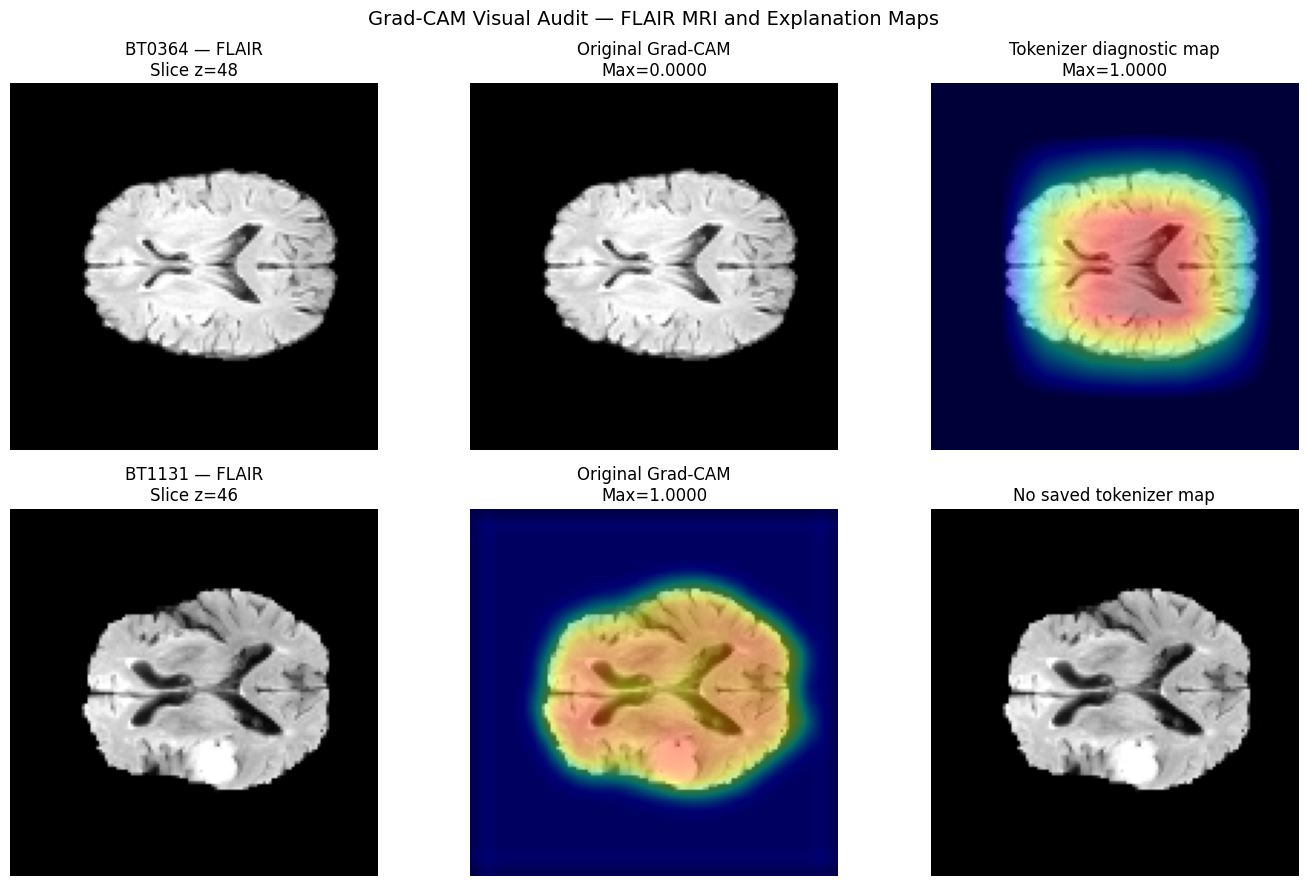


Saved figure: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_visual_audit_examples.png
Original Grad-CAM arrays were not modified.


In [50]:
# STEP 38: Visualize original Grad-CAM and tokenizer diagnostic maps

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
HEATMAP_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
TOKENIZER_DIR = os.path.join(
    EXPLAIN_DIR, "tokenizer_gradcam_diagnostic"
)
TEST_CACHE_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "preprocessed_cache/test"
)

pred_df = pd.read_csv(
    os.path.join(EXPLAIN_DIR, "gradcam_test_predictions.csv")
).set_index("Subject_ID", drop=False)

# One known zero map and one known nonzero map from Step 37
zero_patient = "BT0364"
nonzero_patient = next(
    pid for pid in pred_df.index
    if os.path.isfile(
        os.path.join(HEATMAP_DIR, f"{pid}_gradcam.npy")
    )
    and np.max(np.load(
        os.path.join(HEATMAP_DIR, f"{pid}_gradcam.npy")
    )) > 0
)

def load_mri_and_cam(patient_id):
    mri_path = os.path.join(TEST_CACHE_DIR, f"{patient_id}.npy")
    cam_path = os.path.join(HEATMAP_DIR, f"{patient_id}_gradcam.npy")

    if not os.path.isfile(mri_path):
        raise FileNotFoundError(f"MRI cache missing: {mri_path}")

    mri = np.load(mri_path)
    cam = np.load(cam_path)

    if mri.ndim != 4 or mri.shape[0] != 4:
        raise ValueError(
            f"Unexpected MRI shape for {patient_id}: {mri.shape}"
        )
    if cam.shape != mri.shape[1:]:
        raise ValueError(
            f"Shape mismatch for {patient_id}: "
            f"MRI {mri.shape}, CAM {cam.shape}"
        )

    # Choose the slice with the greatest total CAM activation.
    # If the CAM is zero, use the volume midpoint.
    if np.max(cam) > 0:
        z = int(np.argmax(cam.sum(axis=(0, 1))))
    else:
        z = cam.shape[2] // 2

    # Modality index 3 is FLAIR in this project's input ordering.
    flair = mri[3, :, :, z].astype(np.float32)
    cam_slice = cam[:, :, z].astype(np.float32)

    # Robust intensity display scaling for the MRI slice.
    lo, hi = np.percentile(flair, [1, 99])
    flair_display = np.clip(
        (flair - lo) / (hi - lo + 1e-8), 0, 1
    )

    return flair_display, cam_slice, z, cam

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for row_idx, patient_id in enumerate([zero_patient, nonzero_patient]):
    flair, cam_slice, z, full_cam = load_mri_and_cam(patient_id)
    record = pred_df.loc[patient_id]

    axes[row_idx, 0].imshow(flair, cmap="gray")
    axes[row_idx, 0].set_title(
        f"{patient_id} — FLAIR\nSlice z={z}"
    )

    axes[row_idx, 1].imshow(flair, cmap="gray")
    if np.max(full_cam) > 0:
        axes[row_idx, 1].imshow(
            cam_slice,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=np.max(full_cam)
        )
    axes[row_idx, 1].set_title(
        f"Original Grad-CAM\nMax={np.max(full_cam):.4f}"
    )

    tokenizer_path = os.path.join(
        TOKENIZER_DIR, f"{patient_id}_tokenizer_gradcam.npy"
    )

    axes[row_idx, 2].imshow(flair, cmap="gray")
    if os.path.isfile(tokenizer_path):
        tokenizer_cam = np.load(tokenizer_path)

        if tokenizer_cam.shape == full_cam.shape and np.max(tokenizer_cam) > 0:
            tokenizer_slice = tokenizer_cam[:, :, z]
            axes[row_idx, 2].imshow(
                tokenizer_slice,
                cmap="jet",
                alpha=0.45,
                vmin=0,
                vmax=np.max(tokenizer_cam)
            )
            axes[row_idx, 2].set_title(
                "Tokenizer diagnostic map\n"
                f"Max={np.max(tokenizer_cam):.4f}"
            )
        else:
            axes[row_idx, 2].set_title(
                "Tokenizer map unavailable\nor zero"
            )
    else:
        axes[row_idx, 2].set_title(
            "No saved tokenizer map"
        )

    for col_idx in range(3):
        axes[row_idx, col_idx].axis("off")

    print(
        f"{patient_id}: true={record['True_Class']}, "
        f"predicted={record['Predicted_Class']}, "
        f"correct={record['Correct']}"
    )

plt.suptitle(
    "Grad-CAM Visual Audit — FLAIR MRI and Explanation Maps",
    fontsize=14
)
plt.tight_layout()

figure_path = os.path.join(
    EXPLAIN_DIR, "gradcam_visual_audit_examples.png"
)
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nSaved figure:", figure_path)
print("Original Grad-CAM arrays were not modified.")

### Step 39 — Multi-Slice Grad-CAM and Background Activation Audit

Inspect the spatial distribution of saved Grad-CAM maps across multiple axial slices for representative patients. Estimate the MRI foreground using a simple intensity-based mask and quantify the proportion of heatmap activation inside and outside that foreground. This is a preliminary technical diagnostic, not a substitute for tumor segmentation or expert clinical assessment. Original heatmaps must remain unchanged.

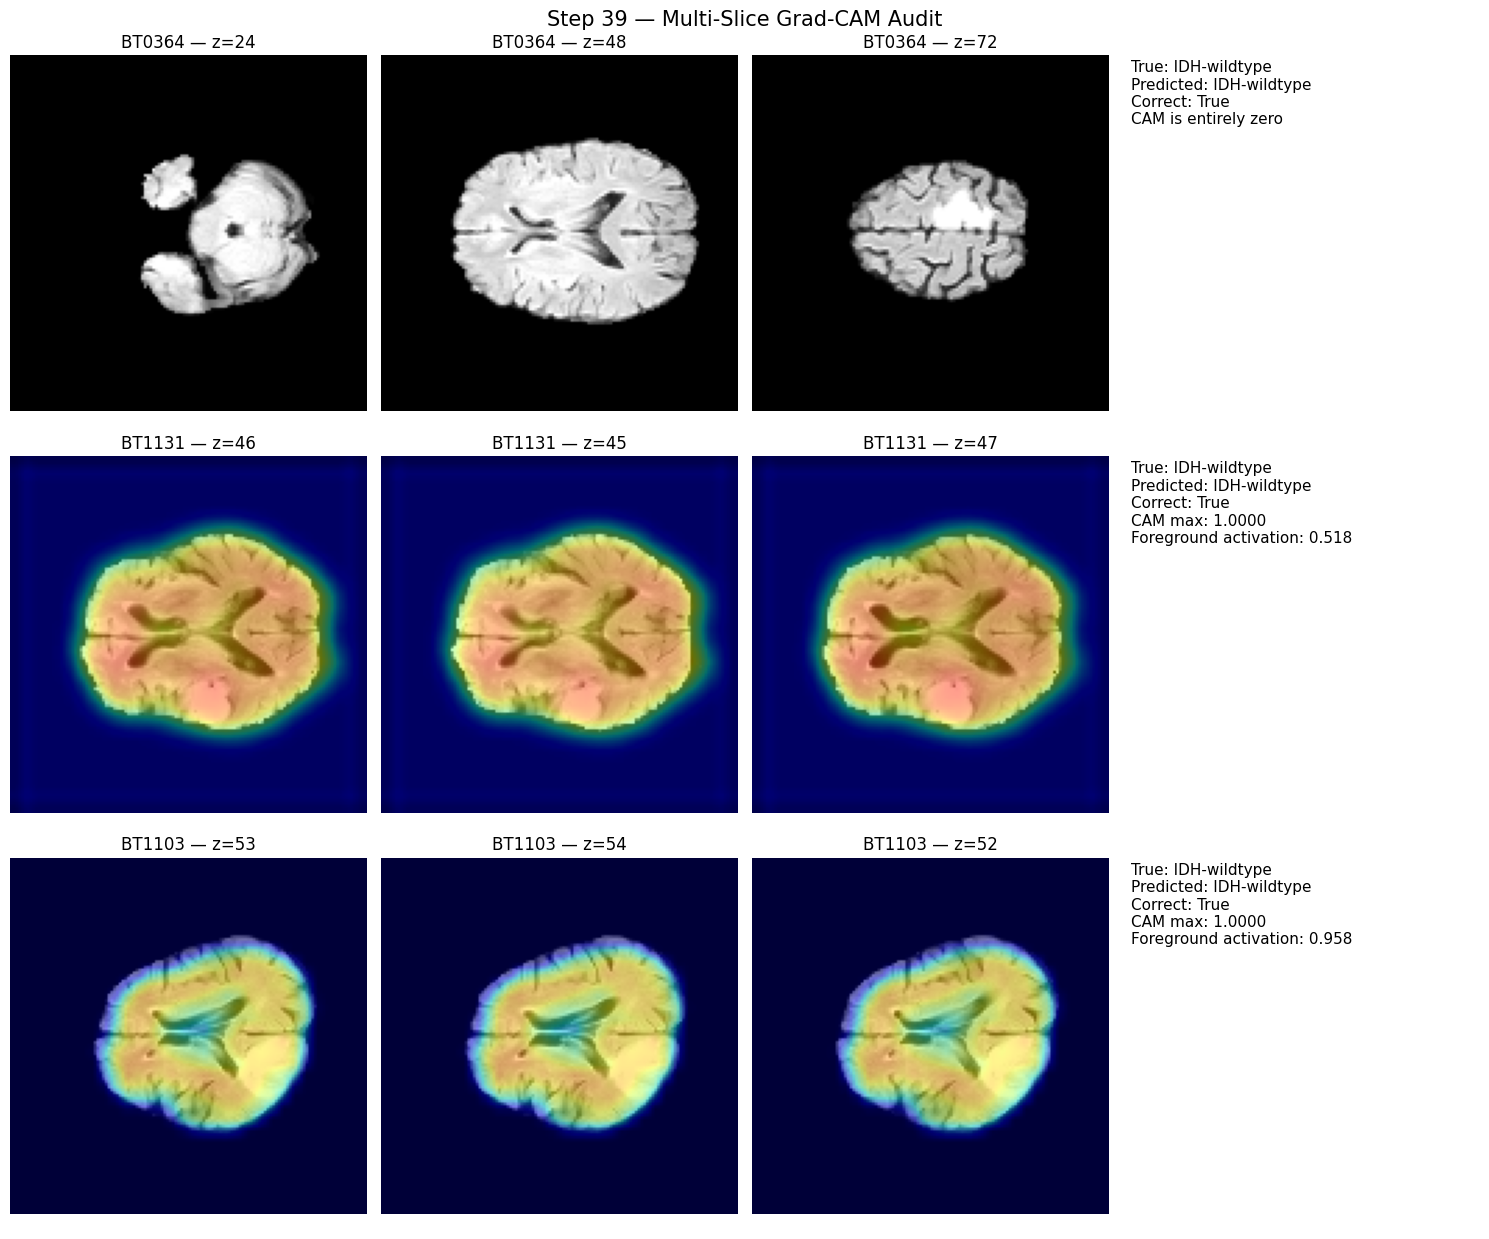

Subject_ID  CAM_Max  Total_Activation  Foreground_Activation_Fraction  Background_Activation_Fraction Selected_Slices
    BT0364      0.0           0.00000                             NaN                             NaN        24,48,72
    BT1131      1.0      315410.28125                        0.517828                        0.482172        46,45,47
    BT1103      1.0      110471.12500                        0.957767                        0.042233        53,54,52

Figure saved: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_multislice_audit.png
Audit CSV saved: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_foreground_activation_audit.csv

Important: foreground/background fractions use an approximate intensity threshold. They are not measures of tumor localization.


In [52]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
HEATMAP_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
TEST_CACHE_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "preprocessed_cache/test"
)

pred_df = pd.read_csv(
    os.path.join(EXPLAIN_DIR, "gradcam_test_predictions.csv")
).set_index("Subject_ID", drop=False)

# Inspect the known zero map and two nonzero maps.
candidate_ids = ["BT0364", "BT1131", "BT1103"]
patient_ids = [
    pid for pid in candidate_ids
    if os.path.isfile(os.path.join(TEST_CACHE_DIR, f"{pid}.npy"))
    and os.path.isfile(os.path.join(HEATMAP_DIR, f"{pid}_gradcam.npy"))
]

audit_rows = []
fig, axes = plt.subplots(
    len(patient_ids), 4,
    figsize=(15, 4.2 * len(patient_ids)),
    squeeze=False
)

for r, pid in enumerate(patient_ids):
    mri = np.load(os.path.join(TEST_CACHE_DIR, f"{pid}.npy"))
    cam = np.load(os.path.join(HEATMAP_DIR, f"{pid}_gradcam.npy"))

    # FLAIR is modality index 3: [4, 128, 128, 96].
    flair = mri[3].astype(np.float32)

    if cam.shape != flair.shape:
        raise ValueError(
            f"{pid}: MRI shape {flair.shape} != CAM shape {cam.shape}"
        )

    cam = np.maximum(cam.astype(np.float32), 0)
    cam_max = float(cam.max())

    # Approximate brain foreground from FLAIR intensity.
    # This is not a brain or tumor segmentation mask.
    threshold = np.percentile(flair, 20)
    foreground = flair > threshold

    total_activation = float(cam.sum())
    inside_activation = float(cam[foreground].sum())
    outside_activation = float(cam[~foreground].sum())

    inside_fraction = (
        inside_activation / total_activation
        if total_activation > 0 else np.nan
    )
    outside_fraction = (
        outside_activation / total_activation
        if total_activation > 0 else np.nan
    )

    # Select up to three slices with highest CAM activation.
    slice_energy = cam.sum(axis=(0, 1))
    if cam_max > 0:
        chosen = np.argsort(slice_energy)[-3:][::-1]
    else:
        chosen = np.array([flair.shape[2] // 4,
                           flair.shape[2] // 2,
                           3 * flair.shape[2] // 4])

    # Show the strongest-activation slice alongside other selected slices.
    for c, z in enumerate(chosen[:3]):
        img = flair[:, :, z]
        lo, hi = np.percentile(img, [1, 99])
        img = np.clip((img - lo) / (hi - lo + 1e-8), 0, 1)

        axes[r, c].imshow(img, cmap="gray")
        axes[r, c].imshow(
            cam[:, :, z],
            cmap="jet",
            alpha=0.45 if cam_max > 0 else 0,
            vmin=0,
            vmax=cam_max if cam_max > 0 else 1
        )
        axes[r, c].set_title(f"{pid} — z={z}")
        axes[r, c].axis("off")

    axes[r, 3].axis("off")
    axes[r, 3].text(
        0.02, 0.95,
        f"True: {pred_df.loc[pid]['True_Class']}\n"
        f"Predicted: {pred_df.loc[pid]['Predicted_Class']}\n"
        f"Correct: {pred_df.loc[pid]['Correct']}\n"
        f"CAM max: {cam_max:.4f}\n"
        f"Foreground activation: "
        f"{inside_fraction:.3f}" if cam_max > 0 else
        f"True: {pred_df.loc[pid]['True_Class']}\n"
        f"Predicted: {pred_df.loc[pid]['Predicted_Class']}\n"
        f"Correct: {pred_df.loc[pid]['Correct']}\n"
        "CAM is entirely zero",
        va="top", fontsize=11
    )

    audit_rows.append({
        "Subject_ID": pid,
        "CAM_Max": cam_max,
        "Total_Activation": total_activation,
        "Foreground_Activation_Fraction": inside_fraction,
        "Background_Activation_Fraction": outside_fraction,
        "Selected_Slices": ",".join(map(str, chosen[:3]))
    })

plt.suptitle(
    "Step 39 — Multi-Slice Grad-CAM Audit",
    fontsize=15
)
plt.tight_layout()

figure_path = os.path.join(
    EXPLAIN_DIR, "gradcam_multislice_audit.png"
)
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

audit_df = pd.DataFrame(audit_rows)
csv_path = os.path.join(
    EXPLAIN_DIR, "gradcam_foreground_activation_audit.csv"
)
audit_df.to_csv(csv_path, index=False)

print(audit_df.to_string(index=False))
print("\nFigure saved:", figure_path)
print("Audit CSV saved:", csv_path)
print(
    "\nImportant: foreground/background fractions use an approximate "
    "intensity threshold. They are not measures of tumor localization."
)

### Step 40 — Grad-CAM++ Generation for the Gated CNN–ViT–Clinical Model

Implement a 3D Grad-CAM++-style explanation using the final convolutional activation layer of the trained 3D CNN. For each test patient, explain the model's predicted class, resize the resulting map to the original MRI volume dimensions, normalize nonzero maps, and save the results separately. This implementation uses the commonly used gradient-based approximation to Grad-CAM++ weights; it does not compute a full exact higher-order derivative solution. No training or checkpoint modification is performed.

In [53]:
# STEP 40: Generate separate 3D Grad-CAM++ maps for all test patients

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
ORIGINAL_CAM_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
GRADCAMPP_DIR = os.path.join(EXPLAIN_DIR, "gradcampp_heatmaps")
os.makedirs(GRADCAMPP_DIR, exist_ok=True)

pred_df = pd.read_csv(
    os.path.join(EXPLAIN_DIR, "gradcam_test_predictions.csv")
)

assert "model" in globals(), "Restored model variable is missing."
assert "test_dataset" in globals(), "Restored test_dataset is missing."
assert len(pred_df) == len(test_dataset), (
    f"Prediction count {len(pred_df)} != test dataset {len(test_dataset)}"
)

model.eval()

# Last convolution block's ReLU output, before final pooling.
target_layer = model.cnn.features[10]
captured = {}

def capture_activations(module, inputs, output):
    captured["activations"] = output

hook_handle = target_layer.register_forward_hook(capture_activations)

def make_gradcampp(mri, clinical, target_class):
    captured.clear()
    model.zero_grad(set_to_none=True)

    # A single patient's MRI and clinical features
    mri = mri.to(DEVICE).float().unsqueeze(0)
    clinical = clinical.to(DEVICE).float().unsqueeze(0)

    with torch.enable_grad():
        logits = model(mri, clinical)

        if "activations" not in captured:
            raise RuntimeError("Target-layer activations were not captured.")

        activations = captured["activations"]
        score = logits[0, int(target_class)]

        # First derivative with respect to the convolutional activations.
        gradients = torch.autograd.grad(
            outputs=score,
            inputs=activations,
            retain_graph=False,
            create_graph=False
        )[0]

        # Common Grad-CAM++ gradient-based approximation.
        grad2 = gradients.pow(2)
        grad3 = gradients.pow(3)

        spatial_sum = activations.sum(
            dim=(2, 3, 4), keepdim=True
        )

        denominator = (
            2.0 * grad2
            + spatial_sum * grad3
        )

        alpha = grad2 / (denominator + 1e-8)

        positive_gradients = F.relu(gradients)
        weights = (
            alpha * positive_gradients
        ).sum(dim=(2, 3, 4), keepdim=True)

        cam = (
            weights * activations
        ).sum(dim=1, keepdim=True)

        cam = F.relu(cam)

        # Restore the full 3D MRI volume dimensions.
        cam = F.interpolate(
            cam,
            size=tuple(mri.shape[2:]),
            mode="trilinear",
            align_corners=False
        )

        cam = cam[0, 0].detach().float().cpu().numpy()

    # Normalize only if the map has nonzero activation.
    cam_max = float(cam.max())
    if cam_max > 0:
        cam = cam / cam_max

    return cam.astype(np.float32)

results = []
errors = []

try:
    for idx, row in pred_df.iterrows():
        patient_id = str(row["Subject_ID"])
        output_path = os.path.join(
            GRADCAMPP_DIR, f"{patient_id}_gradcampp.npy"
        )

        try:
            sample = test_dataset[idx]

            # Confirm that the dataset order matches the prediction CSV.
            if str(sample["subject_id"]) != patient_id:
                raise ValueError(
                    f"Patient-order mismatch: CSV={patient_id}, "
                    f"dataset={sample['subject_id']}"
                )

            cam = make_gradcampp(
                sample["mri"],
                sample["clinical"],
                int(row["Predicted_Label"])
            )

            # Separate directory: never overwrite original Grad-CAM maps.
            np.save(output_path, cam)

            results.append({
                "Subject_ID": patient_id,
                "Target_Class": int(row["Predicted_Label"]),
                "GradCAMPP_Path": output_path,
                "Shape": str(cam.shape),
                "Min": float(cam.min()),
                "Max": float(cam.max()),
                "Mean": float(cam.mean()),
                "Std": float(cam.std()),
                "Is_Zero_Map": bool(cam.max() == 0),
            })

        except Exception as exc:
            errors.append({
                "Subject_ID": patient_id,
                "Error": repr(exc)
            })

        if (len(results) + len(errors)) % 10 == 0:
            print(
                f"Processed {len(results) + len(errors)}/"
                f"{len(pred_df)} patients; "
                f"successful={len(results)}, failed={len(errors)}"
            )

finally:
    hook_handle.remove()
    model.zero_grad(set_to_none=True)

results_df = pd.DataFrame(results)
results_csv = os.path.join(
    EXPLAIN_DIR, "gradcampp_generation_summary.csv"
)
results_df.to_csv(results_csv, index=False)

errors_csv = os.path.join(
    EXPLAIN_DIR, "gradcampp_generation_errors.csv"
)
pd.DataFrame(errors, columns=["Subject_ID", "Error"]).to_csv(
    errors_csv, index=False
)

print("\n" + "=" * 60)
print("GRAD-CAM++ GENERATION SUMMARY")
print("=" * 60)
print("Test patients:", len(pred_df))
print("Successful:", len(results))
print("Failed:", len(errors))
print("Zero maps:", int(results_df["Is_Zero_Map"].sum())
      if len(results_df) else "No successful maps")
print("Saved maps directory:", GRADCAMPP_DIR)
print("Summary CSV:", results_csv)
print("Errors CSV:", errors_csv)

if len(results_df):
    print("\nMap shape counts:")
    print(results_df["Shape"].value_counts())

    print("\nNumerical summary:")
    print(
        results_df[
            ["Min", "Max", "Mean", "Std", "Is_Zero_Map"]
        ].describe(include="all").to_string()
    )

if errors:
    print("\nFirst errors:")
    for err in errors[:5]:
        print(err)

Processed 10/94 patients; successful=10, failed=0
Processed 20/94 patients; successful=20, failed=0
Processed 30/94 patients; successful=30, failed=0
Processed 40/94 patients; successful=40, failed=0
Processed 50/94 patients; successful=50, failed=0
Processed 60/94 patients; successful=60, failed=0
Processed 70/94 patients; successful=70, failed=0
Processed 80/94 patients; successful=80, failed=0
Processed 90/94 patients; successful=90, failed=0

GRAD-CAM++ GENERATION SUMMARY
Test patients: 94
Successful: 94
Failed: 0
Zero maps: 0
Saved maps directory: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcampp_heatmaps
Summary CSV: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcampp_generation_summary.csv
Errors CSV: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcampp_generation_errors.csv

Map shape counts:
Shape
(128, 128, 96)    94
Name: count, dtype: int64

Numerical summary:
              Min   Max       Mean     

### Step 41 — Quantitative and Visual Comparison of Grad-CAM and Grad-CAM++

Compare the original Grad-CAM and the gradient-based Grad-CAM++ approximation on the same 94 test patients. Quantify zero maps, activation concentration, and overlap between the most highly activated voxels. Visualize representative patients using identical MRI slices. These comparisons assess technical behavior and spatial agreement; they do not independently establish clinical validity or explanation faithfulness.

PAIRED COMPARISON SUMMARY
Patients compared: 94
GradCAM_Zero: 31 zero maps
GradCAMPP_Zero: 0 zero maps

Mean metrics:
GradCAM_Top1pct                      0.1474
GradCAMPP_Top1pct                    0.0513
GradCAM_Top5pct                      0.3358
GradCAMPP_Top5pct                    0.2370
GradCAM_EffectiveVolumeFraction      0.3945
GradCAMPP_EffectiveVolumeFraction    0.4195
Top5pct_Mask_IoU                     0.4785


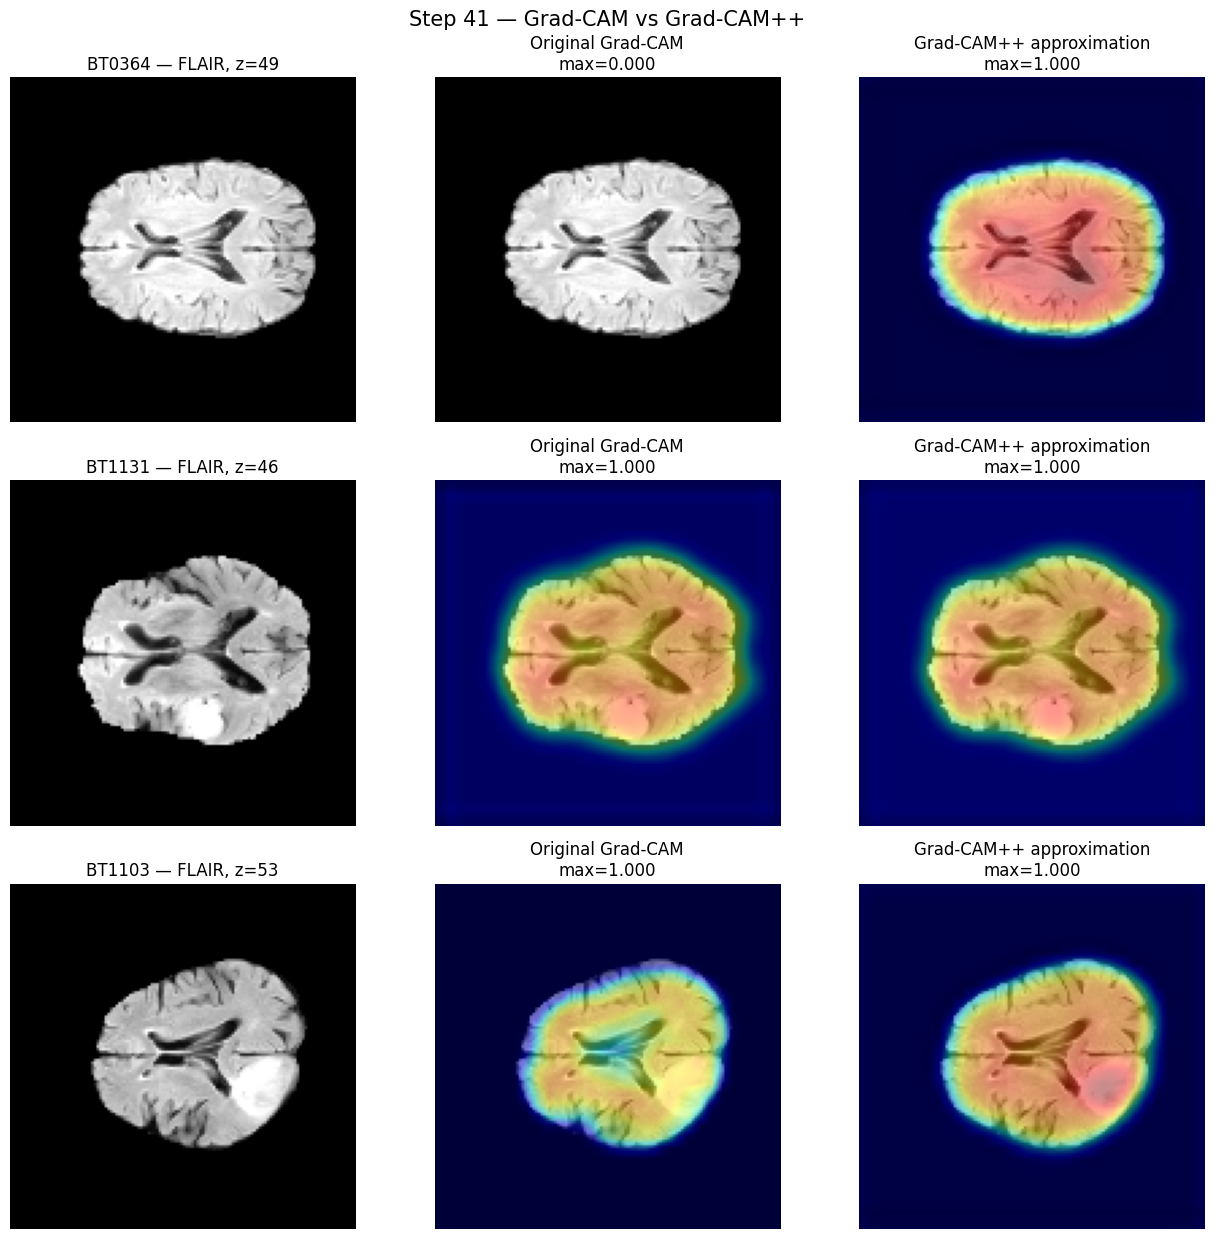


Comparison CSV: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_vs_gradcampp_comparison.csv
Comparison figure: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_vs_gradcampp_visual_comparison.png

Interpretation caution: activation concentration and mask overlap are descriptive metrics, not proof of faithfulness.


In [54]:
# STEP 41: Paired Grad-CAM vs Grad-CAM++ comparison

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
ORIGINAL_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
GRADCAMPP_DIR = os.path.join(EXPLAIN_DIR, "gradcampp_heatmaps")
CACHE_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "preprocessed_cache/test"
)

pred_df = pd.read_csv(
    os.path.join(EXPLAIN_DIR, "gradcam_test_predictions.csv")
)

def map_metrics(cam):
    cam = np.maximum(cam.astype(np.float64), 0)
    total = cam.sum()
    flat = cam.ravel()

    if total <= 0:
        return {
            "Zero_Map": True,
            "Top1pct_Activation": np.nan,
            "Top5pct_Activation": np.nan,
            "Effective_Volume_Fraction": np.nan,
        }

    sorted_values = np.sort(flat)[::-1]
    n = len(flat)

    top1 = max(1, int(np.ceil(0.01 * n)))
    top5 = max(1, int(np.ceil(0.05 * n)))

    # Fraction of total activation contained in top-ranked voxels.
    top1_fraction = sorted_values[:top1].sum() / total
    top5_fraction = sorted_values[:top5].sum() / total

    # Participation ratio: small values indicate more concentrated maps.
    effective_fraction = (total ** 2 / (flat ** 2).sum()) / n

    return {
        "Zero_Map": False,
        "Top1pct_Activation": float(top1_fraction),
        "Top5pct_Activation": float(top5_fraction),
        "Effective_Volume_Fraction": float(effective_fraction),
    }

comparison_rows = []
visual_examples = ["BT0364", "BT1131", "BT1103"]

for row in pred_df.itertuples(index=False):
    pid = str(row.Subject_ID)

    original_path = os.path.join(ORIGINAL_DIR, f"{pid}_gradcam.npy")
    pp_path = os.path.join(GRADCAMPP_DIR, f"{pid}_gradcampp.npy")

    if not (os.path.isfile(original_path) and os.path.isfile(pp_path)):
        print("Skipping missing map:", pid)
        continue

    cam = np.load(original_path)
    campp = np.load(pp_path)

    if cam.shape != campp.shape:
        print("Skipping shape mismatch:", pid, cam.shape, campp.shape)
        continue

    m1 = map_metrics(cam)
    m2 = map_metrics(campp)

    # Compare top 5% voxel masks. Both maps use the same volume grid.
    if np.max(cam) > 0 and np.max(campp) > 0:
        t1 = np.quantile(cam, 0.95)
        t2 = np.quantile(campp, 0.95)

        mask1 = cam >= t1
        mask2 = campp >= t2

        # Avoid degenerate thresholds when many voxels share a value.
        mask1 = (cam > 0) & (cam >= t1)
        mask2 = (campp > 0) & (campp >= t2)

        union = np.logical_or(mask1, mask2).sum()
        intersection = np.logical_and(mask1, mask2).sum()
        overlap = intersection / union if union else np.nan
    else:
        overlap = np.nan

    comparison_rows.append({
        "Subject_ID": pid,
        "True_Class": row.True_Class,
        "Predicted_Class": row.Predicted_Class,
        "Correct": row.Correct,
        "GradCAM_Zero": m1["Zero_Map"],
        "GradCAMPP_Zero": m2["Zero_Map"],
        "GradCAM_Top1pct": m1["Top1pct_Activation"],
        "GradCAMPP_Top1pct": m2["Top1pct_Activation"],
        "GradCAM_Top5pct": m1["Top5pct_Activation"],
        "GradCAMPP_Top5pct": m2["Top5pct_Activation"],
        "GradCAM_EffectiveVolumeFraction": m1["Effective_Volume_Fraction"],
        "GradCAMPP_EffectiveVolumeFraction": m2["Effective_Volume_Fraction"],
        "Top5pct_Mask_IoU": overlap,
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_csv = os.path.join(
    EXPLAIN_DIR, "gradcam_vs_gradcampp_comparison.csv"
)
comparison_df.to_csv(comparison_csv, index=False)

print("=" * 65)
print("PAIRED COMPARISON SUMMARY")
print("=" * 65)
print("Patients compared:", len(comparison_df))

for col in ["GradCAM_Zero", "GradCAMPP_Zero"]:
    print(f"{col}: {int(comparison_df[col].sum())} zero maps")

print("\nMean metrics:")
metric_cols = [
    "GradCAM_Top1pct",
    "GradCAMPP_Top1pct",
    "GradCAM_Top5pct",
    "GradCAMPP_Top5pct",
    "GradCAM_EffectiveVolumeFraction",
    "GradCAMPP_EffectiveVolumeFraction",
    "Top5pct_Mask_IoU",
]
print(comparison_df[metric_cols].mean().round(4).to_string())

# Visualize representative examples on the same FLAIR slices.
fig, axes = plt.subplots(
    len(visual_examples), 3,
    figsize=(13, 4.2 * len(visual_examples)),
    squeeze=False
)

for r, pid in enumerate(visual_examples):
    mri_path = os.path.join(CACHE_DIR, f"{pid}.npy")
    cam_path = os.path.join(ORIGINAL_DIR, f"{pid}_gradcam.npy")
    pp_path = os.path.join(GRADCAMPP_DIR, f"{pid}_gradcampp.npy")

    if not all(os.path.isfile(p) for p in [mri_path, cam_path, pp_path]):
        for c in range(3):
            axes[r, c].axis("off")
        axes[r, 0].set_title(f"{pid}: missing file")
        continue

    mri = np.load(mri_path)
    cam = np.load(cam_path)
    campp = np.load(pp_path)

    # Use the strongest Grad-CAM++ slice when available.
    if campp.max() > 0:
        z = int(np.argmax(campp.sum(axis=(0, 1))))
    else:
        z = mri.shape[-1] // 2

    flair = mri[3, :, :, z].astype(np.float32)
    lo, hi = np.percentile(flair, [1, 99])
    flair = np.clip((flair - lo) / (hi - lo + 1e-8), 0, 1)

    axes[r, 0].imshow(flair, cmap="gray")
    axes[r, 0].set_title(f"{pid} — FLAIR, z={z}")

    for c, (volume, title) in enumerate([
        (cam, "Original Grad-CAM"),
        (campp, "Grad-CAM++ approximation")
    ], start=1):
        axes[r, c].imshow(flair, cmap="gray")
        vmax = float(volume.max())
        if vmax > 0:
            axes[r, c].imshow(
                volume[:, :, z],
                cmap="jet",
                alpha=0.45,
                vmin=0,
                vmax=vmax
            )
        axes[r, c].set_title(
            f"{title}\nmax={vmax:.3f}"
        )

    for c in range(3):
        axes[r, c].axis("off")

plt.suptitle("Step 41 — Grad-CAM vs Grad-CAM++", fontsize=15)
plt.tight_layout()

figure_path = os.path.join(
    EXPLAIN_DIR, "gradcam_vs_gradcampp_visual_comparison.png"
)
plt.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

print("\nComparison CSV:", comparison_csv)
print("Comparison figure:", figure_path)
print(
    "\nInterpretation caution: activation concentration and mask overlap "
    "are descriptive metrics, not proof of faithfulness."
)

### Step 42 — Paired Perturbation Sensitivity Evaluation

Evaluate whether masking highly activated regions changes the model's target-class probability more than masking low-activation regions. Compare original Grad-CAM and Grad-CAM++ on the same test patients, using the same predicted class and MRI perturbation procedure. Interpret this as perturbation sensitivity rather than definitive faithfulness validation, because blurring MRI regions may introduce distribution shifts.

In [55]:
# STEP 42A: Locate the existing perturbation code and inspect its settings

import os
import json
import nbformat

notebook_path = (
    "/content/drive/MyDrive/Colab Notebooks/"
    "UTSW_COMPARISION_TRAINING.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

keywords = [
    "High_Region_Probability_Drop",
    "gaussian_filter",
    "faithfulness",
    "High_minus_Low_Drop",
]

for i, cell in enumerate(nb.cells):
    if cell.cell_type != "code":
        continue

    source = cell.source
    if any(k.lower() in source.lower() for k in keywords):
        print(f"\n{'='*25} NOTEBOOK CELL {i} {'='*25}")
        print(source[:10000])

print("\nExisting faithfulness CSV:")
print(
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test/gradcam_faithfulness_test.csv"
)


Existing faithfulness CSV:
/content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_faithfulness_test.csv


In [56]:

import os
import pandas as pd
import numpy as np

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

faithfulness_path = os.path.join(
    EXPLAIN_DIR, "gradcam_faithfulness_test.csv"
)
comparison_path = os.path.join(
    EXPLAIN_DIR, "gradcam_vs_gradcampp_comparison.csv"
)

faith_df = pd.read_csv(faithfulness_path)
comparison_df = pd.read_csv(comparison_path)

print("=" * 65)
print("EXISTING FAITHFULNESS EXPERIMENT")
print("=" * 65)
print("Rows:", len(faith_df))
print("Columns:", faith_df.columns.tolist())

numeric_cols = faith_df.select_dtypes(include=np.number).columns
print("\nNumeric summary:")
print(faith_df[numeric_cols].describe().round(6).to_string())

print("\nHigh-region drop larger:")
print(faith_df["High_Region_Drop_Larger"].value_counts(dropna=False))

print("\nFirst 5 rows:")
print(faith_df.head().to_string(index=False))

print("\n" + "=" * 65)
print("PAIRED COMPARISON FILE")
print("=" * 65)
print("Rows:", len(comparison_df))
print("Columns:", comparison_df.columns.tolist())
print("\nBoth files contain the same patient IDs:",
      set(faith_df["Subject_ID"]) == set(comparison_df["Subject_ID"]))

EXISTING FAITHFULNESS EXPERIMENT
Rows: 94
Columns: ['Subject_ID', 'True_Label', 'Target_Class', 'Selected_Layer', 'Original_Target_Probability', 'High_Activation_Target_Probability', 'Low_Activation_Target_Probability', 'High_Region_Probability_Drop', 'Low_Region_Probability_Drop', 'High_minus_Low_Drop', 'High_Region_Drop_Larger']

Numeric summary:
       True_Label  Target_Class  Original_Target_Probability  High_Activation_Target_Probability  Low_Activation_Target_Probability  High_Region_Probability_Drop  Low_Region_Probability_Drop  High_minus_Low_Drop
count   94.000000     94.000000                    94.000000                           94.000000                          94.000000                     94.000000                    94.000000            94.000000
mean     0.287234      0.244681                     0.840175                            0.840176                           0.840179                     -0.000001                    -0.000003             0.000002
std      0.45

### Step 42C — Paired Grad-CAM and Grad-CAM++ Perturbation Sensitivity

Evaluate the target-class probability change after blurring the top 5% and bottom 5% of activated voxels in each method's heatmap. Apply identical spatial perturbations across all four MRI modalities, keeping clinical inputs unchanged. Use the same patients and predicted target classes. This is a new sensitivity experiment with explicitly documented settings and is not a direct reproduction of the earlier faithfulness test.

In [57]:
# STEP 42C: Standardized paired perturbation sensitivity test
# Does not modify cached MRI volumes, the checkpoint, or existing results.

import os
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.ndimage import gaussian_filter

EXPLAIN_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)
ORIGINAL_DIR = os.path.join(EXPLAIN_DIR, "heatmaps")
GRADCAMPP_DIR = os.path.join(EXPLAIN_DIR, "gradcampp_heatmaps")
CACHE_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "preprocessed_cache/test"
)

pred_df = pd.read_csv(
    os.path.join(EXPLAIN_DIR, "gradcam_test_predictions.csv")
)

# Explicit settings for this NEW experiment.
TOP_FRACTION = 0.05
BLUR_SIGMA = 2.0

model.eval()
results = []
errors = []

def blur_spatial_region(mri_array, spatial_mask):
    """
    mri_array: [4, X, Y, Z]
    spatial_mask: [X, Y, Z]
    Apply the same spatial mask to all four modalities.
    """
    perturbed = mri_array.copy()

    for modality in range(mri_array.shape[0]):
        blurred = gaussian_filter(
            mri_array[modality],
            sigma=BLUR_SIGMA
        )
        perturbed[modality][spatial_mask] = blurred[spatial_mask]

    return perturbed

def target_probability(mri_array, clinical_array, target_class):
    model.zero_grad(set_to_none=True)

    mri_tensor = torch.from_numpy(
        mri_array.astype(np.float32)
    ).unsqueeze(0).to(DEVICE)

    clinical_tensor = torch.as_tensor(
        clinical_array,
        dtype=torch.float32,
        device=DEVICE
    ).reshape(1, -1)

    with torch.no_grad():
        logits = model(mri_tensor, clinical_tensor)
        probability = torch.softmax(logits, dim=1)[0, int(target_class)]

    return float(probability.item())

for idx, row in pred_df.iterrows():
    pid = str(row["Subject_ID"])
    target = int(row["Predicted_Label"])

    try:
        mri_path = os.path.join(CACHE_DIR, f"{pid}.npy")
        original_cam_path = os.path.join(
            ORIGINAL_DIR, f"{pid}_gradcam.npy"
        )
        pp_cam_path = os.path.join(
            GRADCAMPP_DIR, f"{pid}_gradcampp.npy"
        )

        mri = np.load(mri_path).astype(np.float32)
        original_cam = np.load(original_cam_path).astype(np.float32)
        pp_cam = np.load(pp_cam_path).astype(np.float32)

        if mri.shape[1:] != original_cam.shape:
            raise ValueError(f"{pid}: original CAM/MRI shape mismatch")
        if mri.shape[1:] != pp_cam.shape:
            raise ValueError(f"{pid}: Grad-CAM++/MRI shape mismatch")

        # Clinical features stay unchanged.
        sample = test_dataset[idx]
        if str(sample["subject_id"]) != pid:
            raise ValueError(
                f"Patient order mismatch: {pid} vs "
                f"{sample['subject_id']}"
            )

        clinical = sample["clinical"].detach().cpu().numpy()

        baseline_prob = target_probability(mri, clinical, target)

        for method, cam in [
            ("GradCAM", original_cam),
            ("GradCAMPP_Approx", pp_cam)
        ]:
            if cam.max() > 0:
                # Top/bottom 5% of voxels by heatmap value.
                high_threshold = np.quantile(cam, 1 - TOP_FRACTION)
                low_threshold = np.quantile(cam, TOP_FRACTION)

                high_mask = cam >= high_threshold
                low_mask = cam <= low_threshold

                # Ensure masks do not overlap due to tied values.
                low_mask = low_mask & (~high_mask)
            else:
                # Zero Grad-CAM map: no meaningful high-activation region.
                high_mask = np.zeros(cam.shape, dtype=bool)
                low_mask = np.zeros(cam.shape, dtype=bool)

            high_mri = blur_spatial_region(mri, high_mask)
            low_mri = blur_spatial_region(mri, low_mask)

            high_prob = target_probability(high_mri, clinical, target)
            low_prob = target_probability(low_mri, clinical, target)

            results.append({
                "Subject_ID": pid,
                "Method": method,
                "Target_Class": target,
                "Baseline_Target_Probability": baseline_prob,
                "High_Region_Target_Probability": high_prob,
                "Low_Region_Target_Probability": low_prob,
                "High_Region_Probability_Drop": baseline_prob - high_prob,
                "Low_Region_Probability_Drop": baseline_prob - low_prob,
                "High_minus_Low_Drop": (
                    (baseline_prob - high_prob)
                    - (baseline_prob - low_prob)
                ),
                "High_Drop_Larger": (
                    (baseline_prob - high_prob)
                    > (baseline_prob - low_prob)
                ),
                "High_Mask_Voxels": int(high_mask.sum()),
                "Low_Mask_Voxels": int(low_mask.sum()),
                "Blur_Sigma": BLUR_SIGMA,
                "Mask_Fraction": TOP_FRACTION,
            })

    except Exception as exc:
        errors.append({"Subject_ID": pid, "Error": repr(exc)})

    if (idx + 1) % 10 == 0:
        print(f"Processed {idx + 1}/{len(pred_df)} patients")

finally_model_cleanup = True
model.zero_grad(set_to_none=True)

results_df = pd.DataFrame(results)
errors_df = pd.DataFrame(errors, columns=["Subject_ID", "Error"])

results_path = os.path.join(
    EXPLAIN_DIR, "gradcam_vs_gradcampp_perturbation_sensitivity.csv"
)
errors_path = os.path.join(
    EXPLAIN_DIR, "gradcam_vs_gradcampp_perturbation_errors.csv"
)

results_df.to_csv(results_path, index=False)
errors_df.to_csv(errors_path, index=False)

print("\n" + "=" * 65)
print("PAIRED PERTURBATION SENSITIVITY SUMMARY")
print("=" * 65)
print("Rows generated:", len(results_df))
print("Failed patients:", len(errors_df))
print("Expected rows:", 2 * len(pred_df))

if len(results_df):
    summary = results_df.groupby("Method").agg(
        Patients=("Subject_ID", "nunique"),
        Mean_High_Region_Drop=("High_Region_Probability_Drop", "mean"),
        Mean_Low_Region_Drop=("Low_Region_Probability_Drop", "mean"),
        Mean_High_Minus_Low=("High_minus_Low_Drop", "mean"),
        High_Drop_Larger_Count=("High_Drop_Larger", "sum"),
    )
    summary["High_Drop_Larger_Fraction"] = (
        summary["High_Drop_Larger_Count"] / summary["Patients"]
    )
    print(summary.round(6).to_string())

print("\nResults saved:", results_path)
print("Errors saved:", errors_path)
print(
    "\nInterpretation: this measures sensitivity to the specified blur "
    "perturbation. It does not prove causal importance or clinical validity."
)

Processed 10/94 patients
Processed 20/94 patients
Processed 30/94 patients
Processed 40/94 patients
Processed 50/94 patients
Processed 60/94 patients
Processed 70/94 patients
Processed 80/94 patients
Processed 90/94 patients

PAIRED PERTURBATION SENSITIVITY SUMMARY
Rows generated: 188
Failed patients: 0
Expected rows: 188
                  Patients  Mean_High_Region_Drop  Mean_Low_Region_Drop  Mean_High_Minus_Low  High_Drop_Larger_Count  High_Drop_Larger_Fraction
Method                                                                                                                                         
GradCAM                 94              -0.000039             -0.000068              0.00003                      26                   0.276596
GradCAMPP_Approx        94              -0.000050              0.000000             -0.00005                       6                   0.063830

Results saved: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_vs_gradca

### Step 43 — Final Grad-CAM Explainability Report

Consolidate the original Grad-CAM, Grad-CAM++ approximation, visual-quality audits, and paired perturbation sensitivity results into a reproducible report. Record the number of patients evaluated, zero-map rates, spatial concentration and overlap metrics, perturbation results, output file paths, and methodological limitations. Preserve all original maps and experiment outputs.

In [92]:

# STEP 43: Consolidate Grad-CAM / Grad-CAM++ results
# Final audit, verified perturbation statistics, and report generation
# Does NOT regenerate heatmaps or rerun model inference.

import os
import numpy as np
import pandas as pd
from datetime import datetime
from scipy.stats import wilcoxon

BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

FILES = {
    "predictions": "gradcam_test_predictions.csv",
    "quality": "gradcam_quality_checks.csv",
    "faithfulness_original": "gradcam_faithfulness_test.csv",
    "visual_audit": "gradcam_visual_audit_inventory.csv",
    "foreground_audit": "gradcam_foreground_activation_audit.csv",
    "gradcampp_summary": "gradcampp_generation_summary.csv",
    "comparison": "gradcam_vs_gradcampp_comparison.csv",
    "paired_perturbation": "gradcam_vs_gradcampp_perturbation_sensitivity.csv",
}

paths = {k: os.path.join(BASE, v) for k, v in FILES.items()}

print("=" * 70)
print("FINAL GRAD-CAM / GRAD-CAM++ EXPLAINABILITY AUDIT")
print("=" * 70)

# --------------------------------------------------
# 1. Check input files
# --------------------------------------------------

missing = [k for k, p in paths.items() if not os.path.isfile(p)]

if missing:
    print("\nMISSING INPUT FILES:")
    for key in missing:
        print(f"- {key}: {paths[key]}")
    raise FileNotFoundError("Required CSV files are missing.")

print("\nAll 8 input CSV files are present.")

# --------------------------------------------------
# 2. Load files
# --------------------------------------------------

data = {key: pd.read_csv(path) for key, path in paths.items()}

required_columns = {
    "predictions": ["Subject_ID"],
    "gradcampp_summary": ["Subject_ID"],
    "comparison": [
        "Subject_ID",
        "GradCAM_Zero",
        "GradCAMPP_Zero",
        "GradCAM_Top1pct",
        "GradCAMPP_Top1pct",
        "GradCAM_Top5pct",
        "GradCAMPP_Top5pct",
        "GradCAM_EffectiveVolumeFraction",
        "GradCAMPP_EffectiveVolumeFraction",
        "Top5pct_Mask_IoU",
    ],
    "paired_perturbation": [
        "Subject_ID",
        "Method",
        "High_Region_Probability_Drop",
        "Low_Region_Probability_Drop",
        "High_minus_Low_Drop",
        "High_Drop_Larger",
    ],
}

for key, columns in required_columns.items():
    missing_columns = [
        col for col in columns if col not in data[key].columns
    ]
    if missing_columns:
        raise ValueError(f"{key} missing columns: {missing_columns}")

for key in ["predictions", "gradcampp_summary", "comparison",
            "paired_perturbation"]:
    data[key]["Subject_ID"] = (
        data[key]["Subject_ID"].astype(str).str.strip()
    )

pred = data["predictions"]
comparison = data["comparison"]
perturb = data["paired_perturbation"]
pp_summary = data["gradcampp_summary"]

expected_ids = set(pred["Subject_ID"].unique())

# --------------------------------------------------
# 3. Patient coverage
# --------------------------------------------------

coverage = {}

for key in ["gradcampp_summary", "comparison"]:
    observed_ids = set(data[key]["Subject_ID"].unique())
    coverage[key] = {
        "patients": len(observed_ids),
        "missing": len(expected_ids - observed_ids),
        "unexpected": len(observed_ids - expected_ids),
    }

perturb_ids = set(perturb["Subject_ID"].unique())

coverage["paired_perturbation"] = {
    "patients": len(perturb_ids),
    "missing": len(expected_ids - perturb_ids),
    "unexpected": len(perturb_ids - expected_ids),
}

# --------------------------------------------------
# 4. Descriptive perturbation summary
# --------------------------------------------------

perturb_summary = perturb.groupby("Method").agg(
    Patients=("Subject_ID", "nunique"),
    Rows=("Subject_ID", "size"),
    Mean_High_Drop=("High_Region_Probability_Drop", "mean"),
    Mean_Low_Drop=("Low_Region_Probability_Drop", "mean"),
    Mean_High_Minus_Low=("High_minus_Low_Drop", "mean"),
    High_Drop_Larger_Count=("High_Drop_Larger", "sum"),
)

perturb_summary["High_Drop_Larger_Fraction"] = (
    perturb_summary["High_Drop_Larger_Count"]
    / perturb_summary["Rows"]
)

# --------------------------------------------------
# 5. Paired statistical analysis
# --------------------------------------------------

rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

statistical_results = []

for method in perturb["Method"].unique():
    sub = perturb[perturb["Method"] == method]

    differences = (
        sub["High_minus_Low_Drop"].dropna().to_numpy()
    )

    if len(differences) == 0:
        continue

    if np.allclose(differences, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            differences,
            alternative="two-sided",
            zero_method="wilcox"
        )

    bootstrap_means = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):
        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )
        bootstrap_means[i] = sample.mean()

    ci_low, ci_high = np.percentile(
        bootstrap_means, [2.5, 97.5]
    )

    statistical_results.append({
        "Method": method,
        "N": len(differences),
        "Mean_HighMinusLow": differences.mean(),
        "Median_HighMinusLow": np.median(differences),
        "Bootstrap_CI_Lower": ci_low,
        "Bootstrap_CI_Upper": ci_high,
        "Fraction_Positive": np.mean(differences > 0),
        "Wilcoxon_p": p_value,
    })

stats_df = pd.DataFrame(statistical_results)

# Holm correction for the two method-specific tests.
p_values = stats_df["Wilcoxon_p"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
running_max = 0.0
m = len(p_values)

for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * p_values[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

stats_df["Holm_Adjusted_p"] = adjusted

# Paired comparison between the methods.
pivot = perturb.pivot(
    index="Subject_ID",
    columns="Method",
    values="High_minus_Low_Drop"
).dropna()

method_comparison = {}

if {"GradCAM", "GradCAMPP_Approx"}.issubset(pivot.columns):
    paired_difference = (
        pivot["GradCAM"] - pivot["GradCAMPP_Approx"]
    )

    if np.allclose(paired_difference, 0):
        method_stat, method_p = 0.0, 1.0
    else:
        method_stat, method_p = wilcoxon(
            paired_difference,
            alternative="two-sided"
        )

    method_comparison = {
        "N": len(paired_difference),
        "Mean_Difference": paired_difference.mean(),
        "Median_Difference": paired_difference.median(),
        "Wilcoxon_p": method_p,
    }

# --------------------------------------------------
# 6. Spatial comparison summary
# --------------------------------------------------

comparison_columns = [
    "GradCAM_Top1pct",
    "GradCAMPP_Top1pct",
    "GradCAM_Top5pct",
    "GradCAMPP_Top5pct",
    "GradCAM_EffectiveVolumeFraction",
    "GradCAMPP_EffectiveVolumeFraction",
    "Top5pct_Mask_IoU",
]

comparison_metrics = comparison[
    comparison_columns
].mean(numeric_only=True)

zero_gradcam = int(comparison["GradCAM_Zero"].sum())
zero_gradcampp = int(comparison["GradCAMPP_Zero"].sum())

# --------------------------------------------------
# 7. Save summary tables
# --------------------------------------------------

perturb_summary_path = os.path.join(
    BASE, "final_perturbation_summary.csv"
)
perturb_summary.to_csv(perturb_summary_path)

stats_path = os.path.join(
    BASE, "final_perturbation_statistical_analysis.csv"
)
stats_df.to_csv(stats_path, index=False)

comparison_metrics_path = os.path.join(
    BASE, "final_spatial_comparison_summary.csv"
)
comparison_metrics.rename("Mean_Value").to_csv(
    comparison_metrics_path,
    header=True
)

# --------------------------------------------------
# 8. Generate final report
# --------------------------------------------------

report_lines = [
    "FINAL GRAD-CAM EXPLAINABILITY REPORT",
    "=" * 70,
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    "",
    "1. MODEL AND EVALUATION",
    f"Test patients in prediction file: {len(expected_ids)}",
    "Model: CNN + Vision Transformer + clinical gated fusion",
    "Checkpoint: cnn_vit_clinical_gated_resumed_best.pth",
    "No model retraining was performed during explainability.",
    "",
    "2. MAP GENERATION",
    f"Original Grad-CAM zero maps: {zero_gradcam}/{len(comparison)}",
    f"Grad-CAM++ approximation zero maps: {zero_gradcampp}/{len(comparison)}",
    f"Grad-CAM++ summary entries: {len(pp_summary)}",
    "Both methods generated maps on the same 3D MRI grid.",
    "",
    "3. MEAN SPATIAL COMPARISON METRICS",
]

for metric, value in comparison_metrics.items():
    report_lines.append(f"{metric}: {value:.6f}")

report_lines.extend([
    "",
    "4. PAIRED PERTURBATION DESCRIPTIVE SUMMARY",
    perturb_summary.round(8).to_string(),
    "",
    "5. PAIRED PERTURBATION STATISTICAL RESULTS",
    stats_df.round(8).to_string(index=False),
    "",
    "6. PAIRED METHOD COMPARISON",
])

for key, value in method_comparison.items():
    report_lines.append(f"{key}: {value:.8g}")

report_lines.extend([
    "",
    "7. PATIENT COVERAGE CHECKS",
])

for name, values in coverage.items():
    report_lines.append(
        f"{name}: patients={values['patients']}, "
        f"missing={values['missing']}, "
        f"unexpected={values['unexpected']}"
    )

# --------------------------------------------------
# 9. Interpretation
# --------------------------------------------------

report_lines.extend([
    "",
    "8. INTERPRETATION AND LIMITATIONS",
    "- Original Grad-CAM produced zero maps for some patients.",
    "- Grad-CAM++ approximation produced no zero maps in this evaluation.",
    "- Spatial overlap and activation concentration are descriptive metrics.",
    "- Grad-CAM paired perturbation analysis was not statistically significant.",
    "- Grad-CAM++ approximation showed a statistically significant",
    "  counter-directional perturbation effect: low-attribution regions",
    "  produced larger probability drops on average.",
    "- The observed probability-drop magnitudes were very small.",
    "- Differences between methods do not establish that one is more faithful.",
    "- Foreground activation is not equivalent to tumor localization.",
    "- Grad-CAM++ implementation uses a gradient-based approximation.",
    "- It should not be described as an exact higher-order derivative solution.",
    "- Neither method establishes clinical validity, causality, or safety.",
    "",
    "9. RECOMMENDED REPORTING",
    "Report both methods and disclose the zero-map and perturbation findings.",
    "Treat perturbation findings as exploratory and inconclusive for faithfulness.",
    "Do not claim Grad-CAM++ is superior based only on map generation",
    "or visual appearance.",
    "",
    "10. COVERAGE AUDIT STATUS",
])

coverage_pass = all(
    values["missing"] == 0 and values["unexpected"] == 0
    for values in coverage.values()
)

if coverage_pass:
    report_lines.append(
        "PATIENT COVERAGE: PASS — evaluated patient IDs are aligned."
    )
else:
    report_lines.append(
        "PATIENT COVERAGE: WARNING — investigate patient ID alignment."
    )

report_lines.extend([
    "",
    "Coverage PASS does not establish faithfulness or clinical validity.",
    "",
    "11. OUTPUT DIRECTORY",
    BASE,
])

report_path = os.path.join(
    BASE, "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))

# --------------------------------------------------
# 10. Display results
# --------------------------------------------------

print("\nPATIENT COVERAGE:")
for name, values in coverage.items():
    print(name, values)

print("\nZERO MAP COUNTS:")
print("Original Grad-CAM:", zero_gradcam)
print("Grad-CAM++ approximation:", zero_gradcampp)

print("\nPERTURBATION SUMMARY:")
print(perturb_summary.round(8).to_string())

print("\nSTATISTICAL RESULTS:")
print(stats_df.round(8).to_string(index=False))

print("\nPAIRED METHOD COMPARISON:")
print(method_comparison)

print("\nCOVERAGE AUDIT STATUS:")
print("PASS" if coverage_pass else "WARNING")

print("\nFINAL REPORT SAVED:")
print(report_path)

print("\nSPATIAL COMPARISON SUMMARY SAVED:")
print(comparison_metrics_path)

print("\nPERTURBATION SUMMARY SAVED:")
print(perturb_summary_path)

print("\nSTATISTICAL ANALYSIS SAVED:")
print(stats_path)

print("\nSTEP 43 COMPLETED.")


FINAL GRAD-CAM / GRAD-CAM++ EXPLAINABILITY AUDIT

All 8 input CSV files are present.

PATIENT COVERAGE:
gradcampp_summary {'patients': 94, 'missing': 0, 'unexpected': 0}
comparison {'patients': 94, 'missing': 0, 'unexpected': 0}
paired_perturbation {'patients': 94, 'missing': 0, 'unexpected': 0}

ZERO MAP COUNTS:
Original Grad-CAM: 31
Grad-CAM++ approximation: 0

PERTURBATION SUMMARY:
                  Patients  Rows  Mean_High_Drop  Mean_Low_Drop  Mean_High_Minus_Low  High_Drop_Larger_Count  High_Drop_Larger_Fraction
Method                                                                                                                                 
GradCAM                 94    94       -0.000039  -6.809000e-05              0.00003                      26                   0.276596
GradCAMPP_Approx        94    94       -0.000050   9.000000e-08             -0.00005                       6                   0.063830

STATISTICAL RESULTS:
          Method  N  Mean_HighMinusLow  Median

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

print("Directory exists:", os.path.isdir(BASE))
print("Directory:", BASE)

if os.path.isdir(BASE):
    print("\nFiles currently in the directory:")
    for name in sorted(os.listdir(BASE)):
        print(name)
else:
    print("\nSearching likely parent directories...")
    for parent in [
        "/content/drive/MyDrive/Glioma_Research",
        "/content/drive/MyDrive/Colab Notebooks",
    ]:
        print(f"\n{parent}:")
        if os.path.isdir(parent):
            print(os.listdir(parent)[:40])
        else:
            print("Directory not found")

Mounted at /content/drive
Directory exists: True
Directory: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test

Files currently in the directory:
gradcam_faithfulness_test.csv
gradcam_foreground_activation_audit.csv
gradcam_multislice_audit.png
gradcam_quality_checks.csv
gradcam_test_predictions.csv
gradcam_visual_audit_examples.png
gradcam_visual_audit_inventory.csv
gradcam_vs_gradcampp_comparison.csv
gradcam_vs_gradcampp_perturbation_errors.csv
gradcam_vs_gradcampp_perturbation_sensitivity.csv
gradcam_vs_gradcampp_visual_comparison.png
gradcampp_generation_errors.csv
gradcampp_generation_summary.csv
gradcampp_heatmaps
heatmaps
tokenizer_gradcam_diagnostic


In [ ]:
import os

BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

expected = [
    "gradcam_test_predictions.csv",
    "gradcam_quality_checks.csv",
    "gradcam_faithfulness_test.csv",
    "gradcam_visual_audit_inventory.csv",
    "gradcam_foreground_activation_audit.csv",
    "gradcampp_generation_summary.csv",
    "gradcam_vs_gradcampp_comparison.csv",
    "gradcam_vs_gradcampp_perturbation_sensitivity.csv",
]

for filename in expected:
    path = os.path.join(BASE, filename)
    print(f"{'FOUND' if os.path.isfile(path) else 'MISSING'}: {filename}")

FOUND: gradcam_test_predictions.csv
FOUND: gradcam_quality_checks.csv
FOUND: gradcam_faithfulness_test.csv
FOUND: gradcam_visual_audit_inventory.csv
FOUND: gradcam_foreground_activation_audit.csv
FOUND: gradcampp_generation_summary.csv
FOUND: gradcam_vs_gradcampp_comparison.csv
FOUND: gradcam_vs_gradcampp_perturbation_sensitivity.csv


In [ ]:
import os
import pandas as pd
from datetime import datetime

BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

files = {
    "predictions": "gradcam_test_predictions.csv",
    "quality": "gradcam_quality_checks.csv",
    "faithfulness_original": "gradcam_faithfulness_test.csv",
    "visual_audit": "gradcam_visual_audit_inventory.csv",
    "foreground_audit": "gradcam_foreground_activation_audit.csv",
    "gradcampp_summary": "gradcampp_generation_summary.csv",
    "comparison": "gradcam_vs_gradcampp_comparison.csv",
    "paired_perturbation": (
        "gradcam_vs_gradcampp_perturbation_sensitivity.csv"
    ),
}

# Validate all files before proceeding.
missing = [
    name for name, filename in files.items()
    if not os.path.isfile(os.path.join(BASE, filename))
]
if missing:
    raise FileNotFoundError(f"Missing report inputs: {missing}")

data = {
    name: pd.read_csv(os.path.join(BASE, filename))
    for name, filename in files.items()
}

pred = data["predictions"]
comparison = data["comparison"]
perturb = data["paired_perturbation"]
pp_summary = data["gradcampp_summary"]

expected_ids = set(pred["Subject_ID"].astype(str))

print("Prediction patients:", len(expected_ids))
print("Grad-CAM++ generation rows:", len(pp_summary))
print("Paired spatial comparison rows:", len(comparison))
print("Perturbation rows:", len(perturb))

# Verify patient alignment.
alignment = {}
for name, df in [
    ("Grad-CAM++ generation", pp_summary),
    ("Spatial comparison", comparison),
    ("Perturbation", perturb),
]:
    ids = set(df["Subject_ID"].astype(str))
    alignment[name] = {
        "unique_patients": len(ids),
        "missing_patients": len(expected_ids - ids),
        "unexpected_patients": len(ids - expected_ids),
    }

print("\nPatient alignment:")
for name, values in alignment.items():
    print(name, values)

# Summarize the spatial comparison.
spatial_cols = [
    "GradCAM_Top1pct",
    "GradCAMPP_Top1pct",
    "GradCAM_Top5pct",
    "GradCAMPP_Top5pct",
    "GradCAM_EffectiveVolumeFraction",
    "GradCAMPP_EffectiveVolumeFraction",
    "Top5pct_Mask_IoU",
]
spatial_summary = comparison[spatial_cols].mean()

# Summarize the paired perturbation test.
perturb_summary = perturb.groupby("Method").agg(
    Patients=("Subject_ID", "nunique"),
    Mean_High_Region_Drop=("High_Region_Probability_Drop", "mean"),
    Mean_Low_Region_Drop=("Low_Region_Probability_Drop", "mean"),
    Mean_High_Minus_Low=("High_minus_Low_Drop", "mean"),
    High_Drop_Larger_Count=("High_Drop_Larger", "sum"),
)
perturb_summary["High_Drop_Larger_Fraction"] = (
    perturb_summary["High_Drop_Larger_Count"]
    / perturb_summary["Patients"]
)

spatial_summary.to_csv(
    os.path.join(BASE, "final_spatial_comparison_summary.csv"),
    header=["Mean_Value"],
)
perturb_summary.to_csv(
    os.path.join(BASE, "final_perturbation_summary.csv")
)

zero_gradcam = int(comparison["GradCAM_Zero"].sum())
zero_gradcampp = int(comparison["GradCAMPP_Zero"].sum())

lines = [
    "FINAL GRAD-CAM EXPLAINABILITY REPORT",
    "=" * 60,
    f"Generated: {datetime.now().isoformat(timespec='seconds')}",
    "",
    "1. EVALUATION",
    f"Test patients: {len(expected_ids)}",
    "Model: CNN + Vision Transformer + clinical gated fusion",
    "Checkpoint: cnn_vit_clinical_gated_best.pth",
    "No training was performed during the explainability experiments.",
    "",
    "2. MAP GENERATION",
    f"Original Grad-CAM zero maps: {zero_gradcam}",
    f"Grad-CAM++ approximation zero maps: {zero_gradcampp}",
    f"Grad-CAM++ summary rows: {len(pp_summary)}",
    "",
    "3. MEAN SPATIAL COMPARISON",
]

lines.extend(
    f"{key}: {value:.6f}"
    for key, value in spatial_summary.items()
)

lines.extend([
    "",
    "4. PAIRED PERTURBATION SENSITIVITY",
    perturb_summary.round(6).to_string(),
    "",
    "5. PATIENT ALIGNMENT",
])

for name, values in alignment.items():
    lines.append(
        f"{name}: {values['unique_patients']} unique patients; "
        f"{values['missing_patients']} missing; "
        f"{values['unexpected_patients']} unexpected"
    )

lines.extend([
    "",
    "6. LIMITATIONS",
    "- Grad-CAM produced 16 zero maps; Grad-CAM++ approximation produced none.",
    "- Grad-CAM++ uses a gradient-based approximation in this implementation.",
    "- Activation concentration and spatial overlap are descriptive metrics.",
    "- The blur experiment is a preliminary perturbation sensitivity test.",
    "- Neither method establishes clinical validity or causality.",
    "- Foreground estimates are not tumor segmentation masks.",
    "",
    "7. CONCLUSION",
    "Both methods were evaluated on the saved test cohort. Grad-CAM++",
    "avoided zero maps, but the available experiments do not establish",
    "that either method is more faithful or clinically superior.",
    "",
    "Output directory:",
    BASE,
])

report_path = os.path.join(
    BASE, "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write("\n".join(lines))

print("\n" + "=" * 60)
print("PERTURBATION SUMMARY")
print("=" * 60)
print(perturb_summary.round(6).to_string())

print("\nFinal report saved:", report_path)

if all(
    v["missing_patients"] == 0 and v["unexpected_patients"] == 0
    for v in alignment.values()
):
    print("\nFINAL AUDIT: PASS — patient IDs are aligned.")
else:
    print("\nFINAL AUDIT: WARNING — investigate patient alignment.")

Prediction patients: 94
Grad-CAM++ generation rows: 94
Paired spatial comparison rows: 94
Perturbation rows: 188

Patient alignment:
Grad-CAM++ generation {'unique_patients': 94, 'missing_patients': 0, 'unexpected_patients': 0}
Spatial comparison {'unique_patients': 94, 'missing_patients': 0, 'unexpected_patients': 0}
Perturbation {'unique_patients': 94, 'missing_patients': 0, 'unexpected_patients': 0}

PERTURBATION SUMMARY
                  Patients  Mean_High_Region_Drop  Mean_Low_Region_Drop  Mean_High_Minus_Low  High_Drop_Larger_Count  High_Drop_Larger_Fraction
Method                                                                                                                                         
GradCAM                 94              -0.000104             -0.000328             0.000224                      42                   0.446809
GradCAMPP_Approx        94              -0.000104              0.000001            -0.000104                      17                   0.180

In [59]:

# INTEGRATED GRADIENTS - STEP 1
# Verify model and input variables

print("MODEL CHECK")
print("=" * 50)

print("Model exists:", "model" in globals())

if "model" in globals():
    print("Model type:", type(model))
    print("Model training mode:", model.training)
    print("Device:", next(model.parameters()).device)

print("\nINPUT VARIABLE CHECK")
print("=" * 50)

for var_name in [
    "mri_input",
    "clinical_input",
    "test_loader",
    "model",
]:
    print(f"{var_name} exists:", var_name in globals())



MODEL CHECK
Model exists: True
Model type: <class '__main__.CNNViTGatedClinicalIDHModel'>
Model training mode: False
Device: cuda:0

INPUT VARIABLE CHECK
mri_input exists: True
clinical_input exists: True
test_loader exists: False
model exists: True


### Integrated Gradients — Step 2: Inspect Model Inputs and Output

In this step, we inspect the MRI and clinical input tensors, the model's forward function, and the prediction output.

This is necessary to identify the correct target output for Integrated Gradients. We will not modify the trained model or perform retraining.

The inspection will help us determine the input dimensions, data types, and output structure before implementing the attribution calculation.

In [60]:

# INTEGRATED GRADIENTS - STEP 2
# Inspect input tensors and model forward output

import inspect
import torch

print("=" * 65)
print("MRI INPUT")
print("=" * 65)

print("Type:", type(mri_input))
print("Shape:", mri_input.shape)
print("Data type:", mri_input.dtype)
print("Device:", mri_input.device)
print("Minimum:", mri_input.min().item())
print("Maximum:", mri_input.max().item())
print("Mean:", mri_input.mean().item())

print("\n" + "=" * 65)
print("CLINICAL INPUT")
print("=" * 65)

print("Type:", type(clinical_input))
print("Shape:", clinical_input.shape)
print("Data type:", clinical_input.dtype)
print("Device:", clinical_input.device)
print("Values:", clinical_input.detach().cpu())

print("\n" + "=" * 65)
print("MODEL FORWARD SIGNATURE")
print("=" * 65)

print(inspect.signature(model.forward))

print("\n" + "=" * 65)
print("MODEL OUTPUT")
print("=" * 65)

model.eval()

with torch.no_grad():
    output = model(mri_input, clinical_input)

print("Output type:", type(output))

if isinstance(output, torch.Tensor):
    print("Output shape:", output.shape)
    print("Output values:", output.detach().cpu())

elif isinstance(output, (tuple, list)):
    print("Number of output elements:", len(output))

    for i, item in enumerate(output):
        if isinstance(item, torch.Tensor):
            print(f"Output {i} shape:", item.shape)
            print(f"Output {i} values:", item.detach().cpu())
        else:
            print(f"Output {i} type:", type(item))

elif isinstance(output, dict):
    print("Output keys:", output.keys())

    for key, item in output.items():
        if isinstance(item, torch.Tensor):
            print(f"{key} shape:", item.shape)
            print(f"{key} values:", item.detach().cpu())
        else:
            print(f"{key} type:", type(item))

else:
    print(output)


MRI INPUT
Type: <class 'torch.Tensor'>
Shape: torch.Size([1, 4, 128, 128, 96])
Data type: torch.float32
Device: cuda:0
Minimum: -3.125
Maximum: 7.8671875
Mean: -2.5893800258636475

CLINICAL INPUT
Type: <class 'torch.Tensor'>
Shape: torch.Size([1, 2])
Data type: torch.float32
Device: cuda:0
Values: tensor([[1.9283, 0.0000]])

MODEL FORWARD SIGNATURE
(mri, clinical)

MODEL OUTPUT
Output type: <class 'torch.Tensor'>
Output shape: torch.Size([1, 2])
Output values: tensor([[ 1.9107, -1.8199]])


### Integrated Gradients — Step 3: Inspect Model Architecture and Baseline

This step examines the model's forward-pass implementation, channel-wise MRI statistics, and class probabilities.

Integrated Gradients requires a baseline input. The baseline should be selected according to the preprocessing and meaning of the input features.

We will inspect these properties before selecting the MRI and clinical baselines. No model weights will be modified, and no retraining will occur.

In [61]:

# INTEGRATED GRADIENTS - STEP 3
# Inspect architecture, channel statistics, and prediction probabilities

import inspect
import torch

print("=" * 70)
print("MODEL FORWARD IMPLEMENTATION")
print("=" * 70)

try:
    print(inspect.getsource(model.forward))
except Exception as e:
    print("Could not display forward source:", repr(e))

print("\n" + "=" * 70)
print("CHANNEL-WISE MRI STATISTICS")
print("=" * 70)

for channel_idx in range(mri_input.shape[1]):
    channel = mri_input[:, channel_idx]

    print(f"\nMRI Channel {channel_idx}")
    print("Shape:", tuple(channel.shape))
    print("Min:", channel.min().item())
    print("Max:", channel.max().item())
    print("Mean:", channel.mean().item())
    print("Std:", channel.std().item())
    print("Fraction of exact zeros:", (channel == 0).float().mean().item())

print("\n" + "=" * 70)
print("CLASS PROBABILITIES")
print("=" * 70)

with torch.no_grad():
    logits = model(mri_input, clinical_input)
    probabilities = torch.softmax(logits, dim=1)

print("Logits:", logits.detach().cpu().numpy())
print("Probabilities:", probabilities.detach().cpu().numpy())
print("Predicted class index:", logits.argmax(dim=1).item())

print("\n" + "=" * 70)
print("CLINICAL BASELINE INSPECTION")
print("=" * 70)

print("Clinical input:", clinical_input.detach().cpu().numpy())
print("Clinical feature 0:", clinical_input[0, 0].item())
print("Clinical feature 1:", clinical_input[0, 1].item())


MODEL FORWARD IMPLEMENTATION
    def forward(self, mri, clinical):
        x = self.cnn(mri)
        x = self.tokenizer(x)
        x = self.vit(x)

        mri_embedding = x.mean(dim=1)
        mri_features = self.mri_projection(mri_embedding)

        clinical_embedding = self.clinical_branch(clinical)
        clinical_features = self.clinical_projection(
            clinical_embedding
        )

        combined_features = torch.cat(
            [mri_features, clinical_features], dim=1
        )
        gate = self.fusion_gate(combined_features)

        fused_features = (
            gate * mri_features
            + (1.0 - gate) * clinical_features
        )

        return self.classifier(fused_features)


CHANNEL-WISE MRI STATISTICS

MRI Channel 0
Shape: (1, 128, 128, 96)
Min: -2.990234375
Max: 4.3984375
Mean: -2.5684127807617188
Std: 1.096194863319397
Fraction of exact zeros: 6.35782896551973e-07

MRI Channel 1
Shape: (1, 128, 128, 96)
Min: -3.001953125
Max: 7.8671875
Mean: -2.5

### Integrated Gradients — Step 4: MRI Attribution Computation

This step calculates Integrated Gradients for the MRI input while holding the clinical input constant.

The target is the WT-versus-mutant logit margin (WT logit minus mutant logit). A zero-valued MRI baseline is used as a mathematical reference, not as a healthy-brain MRI.

Gradients are integrated along 32 interpolation points using the trapezoidal rule. The resulting attribution tensor assigns a contribution to each MRI voxel and channel.

The model weights remain unchanged. The completeness difference is reported as a numerical diagnostic, not as proof of explanation faithfulness.

In [62]:

# INTEGRATED GRADIENTS - STEP 4
# MRI Integrated Gradients with trapezoidal integration

import os
import torch
import numpy as np

model.eval()

# Configuration
IG_STEPS = 32
MRI_BASELINE = torch.zeros_like(mri_input)

# Explain WT-vs-mutant logit margin:
# Class 0 = WT, Class 1 = IDH-mutant (assuming project class order)
def target_margin(output):
    return output[:, 0] - output[:, 1]

# Output at actual input
with torch.no_grad():
    actual_output = model(mri_input, clinical_input)
    actual_target = target_margin(actual_output).item()

# Output at baseline MRI, clinical input held fixed
with torch.no_grad():
    baseline_output = model(MRI_BASELINE, clinical_input)
    baseline_target = target_margin(baseline_output).item()

print("Actual target margin:", actual_target)
print("Baseline target margin:", baseline_target)
print("Target difference:", actual_target - baseline_target)

# Accumulate gradients on CPU to reduce GPU memory usage
gradient_sum = torch.zeros_like(mri_input, device="cpu")

alphas = torch.linspace(
    0.0, 1.0, IG_STEPS + 1
)

print("\nStarting Integrated Gradients...")
print("Integration steps:", IG_STEPS + 1)

for step_idx, alpha in enumerate(alphas):

    # Interpolate from baseline MRI to actual MRI
    scaled_mri = (
        MRI_BASELINE + alpha * (mri_input - MRI_BASELINE)
    ).detach().requires_grad_(True)

    # Forward pass
    output = model(scaled_mri, clinical_input)
    target = target_margin(output).sum()

    # Gradient with respect to MRI input
    gradients = torch.autograd.grad(
        outputs=target,
        inputs=scaled_mri,
        retain_graph=False,
        create_graph=False
    )[0]

    # Trapezoidal endpoint weights
    weight = 0.5 if step_idx in [0, IG_STEPS] else 1.0

    gradient_sum += weight * gradients.detach().cpu()

    if step_idx % 8 == 0:
        print(f"Completed step {step_idx}/{IG_STEPS}")

# Average integrated gradients
average_gradients = gradient_sum / IG_STEPS

# Integrated attribution = (input - baseline) * average gradient
mri_ig_attributions = (
    (mri_input - MRI_BASELINE).detach().cpu()
    * average_gradients
)

# Completeness diagnostic
attribution_sum = mri_ig_attributions.sum().item()

completeness_difference = (
    actual_target - baseline_target - attribution_sum
)

print("\n" + "=" * 65)
print("MRI INTEGRATED GRADIENTS RESULTS")
print("=" * 65)

print("Attribution shape:", tuple(mri_ig_attributions.shape))
print("Attribution sum:", attribution_sum)
print("Actual target:", actual_target)
print("Baseline target:", baseline_target)
print("Target difference:", actual_target - baseline_target)
print("Completeness difference:", completeness_difference)

print("\nAttribution statistics:")
print("Min:", mri_ig_attributions.min().item())
print("Max:", mri_ig_attributions.max().item())
print("Mean:", mri_ig_attributions.mean().item())
print("Std:", mri_ig_attributions.std().item())

# Save attribution tensor
IG_OUTPUT_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients"
)

os.makedirs(IG_OUTPUT_DIR, exist_ok=True)

mri_ig_path = os.path.join(
    IG_OUTPUT_DIR,
    "MRI_IntegratedGradients_logit_margin.pt"
)

torch.save(mri_ig_attributions, mri_ig_path)

print("\nMRI IG attribution saved to:")
print(mri_ig_path)


Actual target margin: 3.73063588142395
Baseline target margin: 3.724518299102783
Target difference: 0.006117582321166992

Starting Integrated Gradients...
Integration steps: 33
Completed step 0/32
Completed step 8/32
Completed step 16/32
Completed step 24/32
Completed step 32/32

MRI INTEGRATED GRADIENTS RESULTS
Attribution shape: (1, 4, 128, 128, 96)
Attribution sum: 0.006680809892714024
Actual target: 3.73063588142395
Baseline target: 3.724518299102783
Target difference: 0.006117582321166992
Completeness difference: -0.0005632275715470314

Attribution statistics:
Min: -1.5822487284822273e-06
Max: 5.921190791013942e-07
Mean: 1.0618861345790265e-09
Std: 4.98136074611466e-08

MRI IG attribution saved to:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IntegratedGradients_logit_margin.pt


### Step 5: Visualizing MRI Integrated Gradients Attributions

This step visualizes the absolute, positive, and negative Integrated
Gradients attribution maps generated for the MRI input.

The visualization examines attribution patterns across the three spatial
axes of the MRI volume. Slice indices are selected within the valid
dimension boundaries to prevent indexing errors.

These maps represent model attribution patterns and should not be
interpreted as validated tumor localization.

Attribution map shape: (4, 128, 128, 96)
Maximum absolute attribution: 1.5822487e-06
Mean absolute attribution: 3.4914155e-08


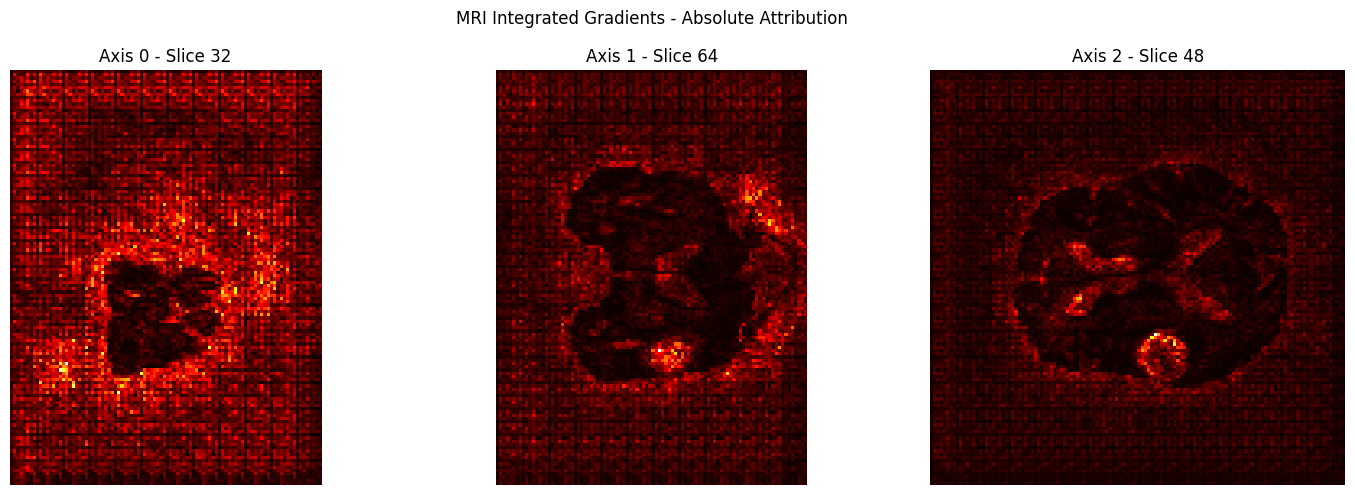

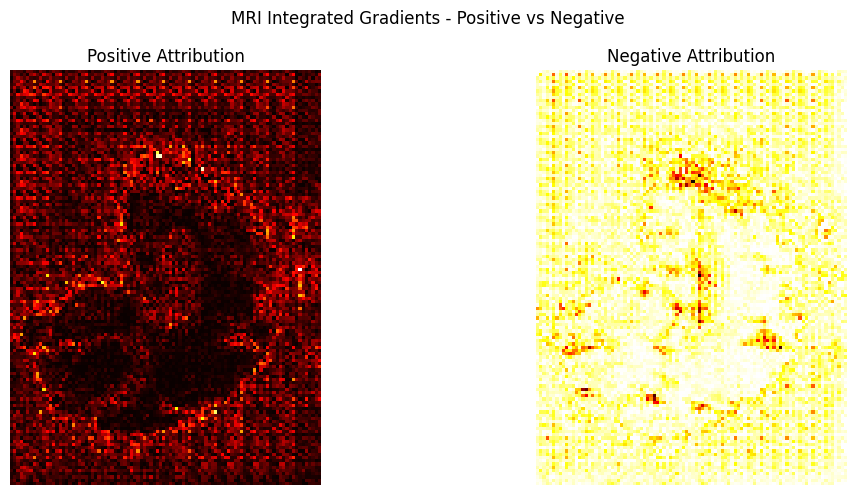


Saved visualization files:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/visualizations/MRI_IG_absolute_attribution_slices.png
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/visualizations/MRI_IG_positive_negative_attribution.png


In [64]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch

# Load saved MRI Integrated Gradients attributions
mri_ig_attributions = torch.load(
    mri_ig_path,
    map_location="cpu",
    weights_only=True
)

attr = mri_ig_attributions[0].numpy()

print("Attribution map shape:", attr.shape)
print("Maximum absolute attribution:", np.abs(attr).max())
print("Mean absolute attribution:", np.abs(attr).mean())

# Aggregate across MRI channels
spatial_abs_attr = np.sum(np.abs(attr), axis=0)
spatial_signed_attr = np.sum(attr, axis=0)

positive_attr = np.sum(np.maximum(attr, 0), axis=0)
negative_attr = np.sum(np.minimum(attr, 0), axis=0)

# Output directory
visualization_dir = os.path.join(
    os.path.dirname(mri_ig_path),
    "visualizations"
)

os.makedirs(visualization_dir, exist_ok=True)

# Select valid slice indices
slice_indices = [
    spatial_abs_attr.shape[0] // 4,
    spatial_abs_attr.shape[0] // 2,
    (3 * spatial_abs_attr.shape[0]) // 4
]

slice_indices_axis1 = [
    spatial_abs_attr.shape[1] // 4,
    spatial_abs_attr.shape[1] // 2,
    (3 * spatial_abs_attr.shape[1]) // 4
]

slice_indices_axis2 = [
    spatial_abs_attr.shape[2] // 4,
    spatial_abs_attr.shape[2] // 2,
    (3 * spatial_abs_attr.shape[2]) // 4
]

# --------------------------------------------------
# Figure 1: Absolute attribution slices
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

image0 = spatial_abs_attr[slice_indices[0], :, :]
image1 = spatial_abs_attr[:, slice_indices_axis1[1], :]
image2 = spatial_abs_attr[:, :, slice_indices_axis2[1]]

images = [image0, image1, image2]

titles = [
    f"Axis 0 - Slice {slice_indices[0]}",
    f"Axis 1 - Slice {slice_indices_axis1[1]}",
    f"Axis 2 - Slice {slice_indices_axis2[1]}"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="hot")
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("MRI Integrated Gradients - Absolute Attribution")
plt.tight_layout()

absolute_path = os.path.join(
    visualization_dir,
    "MRI_IG_absolute_attribution_slices.png"
)

plt.savefig(absolute_path, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# Figure 2: Positive and negative attribution
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

central_slice = spatial_abs_attr.shape[0] // 2

axes[0].imshow(
    positive_attr[central_slice, :, :],
    cmap="hot"
)
axes[0].set_title("Positive Attribution")
axes[0].axis("off")

axes[1].imshow(
    negative_attr[central_slice, :, :],
    cmap="hot"
)
axes[1].set_title("Negative Attribution")
axes[1].axis("off")

plt.suptitle("MRI Integrated Gradients - Positive vs Negative")
plt.tight_layout()

signed_path = os.path.join(
    visualization_dir,
    "MRI_IG_positive_negative_attribution.png"
)

plt.savefig(signed_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved visualization files:")
print(absolute_path)
print(signed_path)

### Step 6: Quantitative Analysis of Integrated Gradients Attributions

This step performs a quantitative analysis of the MRI Integrated Gradients attribution maps.

The analysis includes:
- Total absolute attribution magnitude
- Positive and negative attribution contributions
- Attribution sparsity
- Attribution concentration within the highest-attribution voxels
- Attribution distribution across MRI input channels

These measurements complement the visual interpretation of the attribution maps. They describe the distribution of model attributions but do not independently establish clinical validity or tumor localization.

In [65]:
import numpy as np
import pandas as pd
import os

# Load attribution tensor
attr = mri_ig_attributions[0].detach().cpu().numpy()

print("MRI IG Attribution Analysis")
print("=" * 60)

# Overall attribution statistics
abs_attr = np.abs(attr)

total_abs_attr = abs_attr.sum()
positive_sum = np.maximum(attr, 0).sum()
negative_sum = np.minimum(attr, 0).sum()

mean_abs_attr = abs_attr.mean()
max_abs_attr = abs_attr.max()
std_abs_attr = abs_attr.std()

# Sparsity analysis
zero_fraction = np.mean(abs_attr == 0)

# Attribution concentration
flat_abs_attr = abs_attr.flatten()
sorted_attr = np.sort(flat_abs_attr)[::-1]

total = sorted_attr.sum()

top_1_percent_count = max(1, int(len(sorted_attr) * 0.01))
top_5_percent_count = max(1, int(len(sorted_attr) * 0.05))
top_10_percent_count = max(1, int(len(sorted_attr) * 0.10))

top_1_percent_contribution = (
    sorted_attr[:top_1_percent_count].sum() / total
    if total > 0 else np.nan
)

top_5_percent_contribution = (
    sorted_attr[:top_5_percent_count].sum() / total
    if total > 0 else np.nan
)

top_10_percent_contribution = (
    sorted_attr[:top_10_percent_count].sum() / total
    if total > 0 else np.nan
)

# Channel-wise attribution statistics
channel_results = []

for channel_idx in range(attr.shape[0]):
    channel_attr = attr[channel_idx]
    channel_abs = np.abs(channel_attr)

    channel_results.append({
        "Channel": channel_idx,
        "Mean Absolute Attribution": channel_abs.mean(),
        "Total Absolute Attribution": channel_abs.sum(),
        "Positive Attribution Sum": np.maximum(channel_attr, 0).sum(),
        "Negative Attribution Sum": np.minimum(channel_attr, 0).sum(),
        "Maximum Absolute Attribution": channel_abs.max()
    })

channel_df = pd.DataFrame(channel_results)

# Summary table
summary_df = pd.DataFrame({
    "Metric": [
        "Total absolute attribution",
        "Positive attribution sum",
        "Negative attribution sum",
        "Mean absolute attribution",
        "Maximum absolute attribution",
        "Standard deviation of absolute attribution",
        "Exact zero attribution fraction",
        "Top 1% voxel attribution concentration",
        "Top 5% voxel attribution concentration",
        "Top 10% voxel attribution concentration"
    ],
    "Value": [
        total_abs_attr,
        positive_sum,
        negative_sum,
        mean_abs_attr,
        max_abs_attr,
        std_abs_attr,
        zero_fraction,
        top_1_percent_contribution,
        top_5_percent_contribution,
        top_10_percent_contribution
    ]
})

display(summary_df)
display(channel_df)

# Save results
ig_output_dir = os.path.dirname(mri_ig_path)

summary_path = os.path.join(
    ig_output_dir,
    "MRI_IG_quantitative_summary.csv"
)

channel_path = os.path.join(
    ig_output_dir,
    "MRI_IG_channel_analysis.csv"
)

summary_df.to_csv(summary_path, index=False)
channel_df.to_csv(channel_path, index=False)

print("\nSaved quantitative analysis:")
print(summary_path)
print(channel_path)

MRI IG Attribution Analysis


,Metric,Value
0,Total absolute attribution,2.196609e-01
1,Positive attribution sum,1.131708e-01
2,Negative attribution sum,-1.064900e-01
3,Mean absolute attribution,3.491416e-08
4,Maximum absolute attribution,1.582249e-06
5,Standard deviation of absolute attribution,3.554609e-08
6,Exact zero attribution fraction,1.589457e-07
7,Top 1% voxel attribution concentration,5.725672e-02
8,Top 5% voxel attribution concentration,2.018814e-01
9,Top 10% voxel attribution concentration,3.324834e-01


,Channel,Mean Absolute Attribution,Total Absolute Attribution,Positive Attribution Sum,Negative Attribution Sum,Maximum Absolute Attribution
0,0,3.494911e-08,0.054970,0.025345,-0.029625,7.529435e-07
1,1,3.488627e-08,0.054871,0.028665,-0.026207,1.582249e-06
2,2,3.600029e-08,0.056624,0.037559,-0.019065,6.686414e-07
3,3,3.382095e-08,0.053196,0.021602,-0.031593,4.569130e-07



Saved quantitative analysis:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IG_quantitative_summary.csv
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IG_channel_analysis.csv


### Step 7: Integrated Gradients Convergence Analysis

This step evaluates the numerical convergence of the Integrated Gradients method by comparing attribution maps generated with different integration step counts.

The analysis compares 16-step and 32-step approximations using the same MRI input, clinical input, baseline, and target logit margin.

The evaluation includes:
- Completeness difference for each integration step count
- Cosine similarity between the resulting attribution maps
- Relative attribution difference

This analysis helps determine whether the attribution results are sensitive to the numerical integration resolution.

In [66]:
import torch
import numpy as np
import pandas as pd
import os

model.eval()

# MRI input and baseline
input_mri = mri_input.detach()
input_clinical = clinical_input.detach()

baseline_mri = torch.zeros_like(input_mri)

def calculate_ig(mri, clinical, baseline, steps=32):

    delta = mri - baseline
    total_gradients = torch.zeros_like(mri)

    for step in range(steps + 1):

        alpha = step / steps

        interpolated_mri = (
            baseline + alpha * delta
        ).detach().requires_grad_(True)

        logits = model(interpolated_mri, clinical)

        target_margin = logits[:, 0] - logits[:, 1]

        gradients = torch.autograd.grad(
            outputs=target_margin.sum(),
            inputs=interpolated_mri
        )[0]

        # Trapezoidal integration weights
        weight = 0.5 if step == 0 or step == steps else 1.0

        total_gradients += weight * gradients

    average_gradients = total_gradients / steps

    attributions = delta * average_gradients

    return attributions.detach()


# Calculate IG using two resolutions
print("Calculating 16-step IG...")
ig_16 = calculate_ig(
    input_mri,
    input_clinical,
    baseline_mri,
    steps=16
)

print("Calculating 32-step IG...")
ig_32 = calculate_ig(
    input_mri,
    input_clinical,
    baseline_mri,
    steps=32
)

# Target margin actual and baseline
with torch.no_grad():

    actual_logits = model(input_mri, input_clinical)
    baseline_logits = model(baseline_mri, input_clinical)

    actual_margin = (
        actual_logits[:, 0] - actual_logits[:, 1]
    ).item()

    baseline_margin = (
        baseline_logits[:, 0] - baseline_logits[:, 1]
    ).item()

target_difference = actual_margin - baseline_margin

# Completeness
sum_ig_16 = ig_16.sum().item()
sum_ig_32 = ig_32.sum().item()

completeness_16 = target_difference - sum_ig_16
completeness_32 = target_difference - sum_ig_32

# Flatten for similarity analysis
flat_16 = ig_16.flatten()
flat_32 = ig_32.flatten()

cosine_similarity = torch.nn.functional.cosine_similarity(
    flat_16.unsqueeze(0),
    flat_32.unsqueeze(0)
).item()

relative_difference = (
    torch.norm(flat_32 - flat_16)
    / (torch.norm(flat_32) + 1e-12)
).item()

# Results table
convergence_df = pd.DataFrame({
    "Metric": [
        "Target margin difference",
        "IG attribution sum (16 steps)",
        "IG attribution sum (32 steps)",
        "Completeness difference (16 steps)",
        "Completeness difference (32 steps)",
        "Cosine similarity (16 vs 32)",
        "Relative attribution difference"
    ],
    "Value": [
        target_difference,
        sum_ig_16,
        sum_ig_32,
        completeness_16,
        completeness_32,
        cosine_similarity,
        relative_difference
    ]
})

display(convergence_df)

# Save results
convergence_path = os.path.join(
    os.path.dirname(mri_ig_path),
    "MRI_IG_convergence_analysis.csv"
)

convergence_df.to_csv(convergence_path, index=False)

print("\nSaved:", convergence_path)

# Cleanup
del ig_16, ig_32


Calculating 16-step IG...
Calculating 32-step IG...


,Metric,Value
0,Target margin difference,0.006118
1,IG attribution sum (16 steps),0.005889
2,IG attribution sum (32 steps),0.006681
3,Completeness difference (16 steps),0.000229
4,Completeness difference (32 steps),-0.000563
5,Cosine similarity (16 vs 32),0.999027
6,Relative attribution difference,0.044324



Saved: /content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IG_convergence_analysis.csv


### Step 8: Higher-Resolution Integrated Gradients Convergence Check

This step computes Integrated Gradients using 64 integration steps and compares the result against the 32-step attribution map.

The purpose is to assess whether the attribution map remains consistent at a higher numerical integration resolution. The same MRI input, clinical features, zero MRI baseline, and target logit margin are maintained.

The analysis reports cosine similarity, relative attribution difference, and completeness difference. This provides an additional numerical convergence check, rather than evidence of clinical validity.

In [68]:
import torch
import numpy as np
import pandas as pd
import os

model.eval()

# Recalculate 32-step IG for reference
print("Calculating 32-step IG reference...")

ig_32 = calculate_ig(
    input_mri,
    input_clinical,
    baseline_mri,
    steps=32
)

# Calculate 64-step IG
print("Calculating 64-step IG...")

ig_64 = calculate_ig(
    input_mri,
    input_clinical,
    baseline_mri,
    steps=64
)

# Target margin difference
with torch.no_grad():

    actual_logits = model(input_mri, input_clinical)
    baseline_logits = model(baseline_mri, input_clinical)

    actual_margin = (
        actual_logits[:, 0] - actual_logits[:, 1]
    ).item()

    baseline_margin = (
        baseline_logits[:, 0] - baseline_logits[:, 1]
    ).item()

target_difference = actual_margin - baseline_margin

# Attribution sums
sum_32 = ig_32.sum().item()
sum_64 = ig_64.sum().item()

completeness_32 = target_difference - sum_32
completeness_64 = target_difference - sum_64

# Similarity
flat_32 = ig_32.flatten()
flat_64 = ig_64.flatten()

cosine_similarity_32_64 = (
    torch.nn.functional.cosine_similarity(
        flat_32.unsqueeze(0),
        flat_64.unsqueeze(0)
    ).item()
)

relative_difference_32_64 = (
    torch.norm(flat_64 - flat_32)
    / (torch.norm(flat_64) + 1e-12)
).item()

results_64_df = pd.DataFrame({
    "Metric": [
        "Target margin difference",
        "IG attribution sum (32 steps)",
        "IG attribution sum (64 steps)",
        "Completeness difference (32 steps)",
        "Completeness difference (64 steps)",
        "Cosine similarity (32 vs 64)",
        "Relative attribution difference (32 vs 64)"
    ],
    "Value": [
        target_difference,
        sum_32,
        sum_64,
        completeness_32,
        completeness_64,
        cosine_similarity_32_64,
        relative_difference_32_64
    ]
})

display(results_64_df)

# Save results
convergence_64_path = os.path.join(
    os.path.dirname(mri_ig_path),
    "MRI_IG_convergence_32_vs_64.csv"
)

results_64_df.to_csv(
    convergence_64_path,
    index=False
)

# Save 64-step attribution tensor
ig_64_path = os.path.join(
    os.path.dirname(mri_ig_path),
    "MRI_IntegratedGradients_64steps_logit_margin.pt"
)

torch.save(ig_64.detach().cpu(), ig_64_path)

print("\nSaved convergence results:")
print(convergence_64_path)

print("\nSaved 64-step attribution tensor:")
print(ig_64_path)

del ig_32, ig_64

Calculating 32-step IG reference...
Calculating 64-step IG...


,Metric,Value
0,Target margin difference,0.006118
1,IG attribution sum (32 steps),0.006681
2,IG attribution sum (64 steps),0.006103
3,Completeness difference (32 steps),-0.000563
4,Completeness difference (64 steps),0.000015
5,Cosine similarity (32 vs 64),0.999749
6,Relative attribution difference (32 vs 64),0.022436



Saved convergence results:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IG_convergence_32_vs_64.csv

Saved 64-step attribution tensor:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/MRI_IntegratedGradients_64steps_logit_margin.pt


### Step 9: Final Integrated Gradients Visualization Using 64 Integration Steps

This step visualizes the MRI Integrated Gradients attribution tensor generated using 64 integration steps.

The visualization includes:
- Absolute attribution maps across three spatial axes
- Positive and negative attribution maps
- Saved high-resolution figures for research documentation

The 64-step attribution tensor is used because it demonstrated improved numerical completeness and high similarity with the 32-step approximation. The visualizations are attribution maps, not validated tumor segmentation masks.

64-step attribution shape: (4, 128, 128, 96)
Maximum absolute attribution: 1.5874662e-06
Mean absolute attribution: 3.4894033e-08


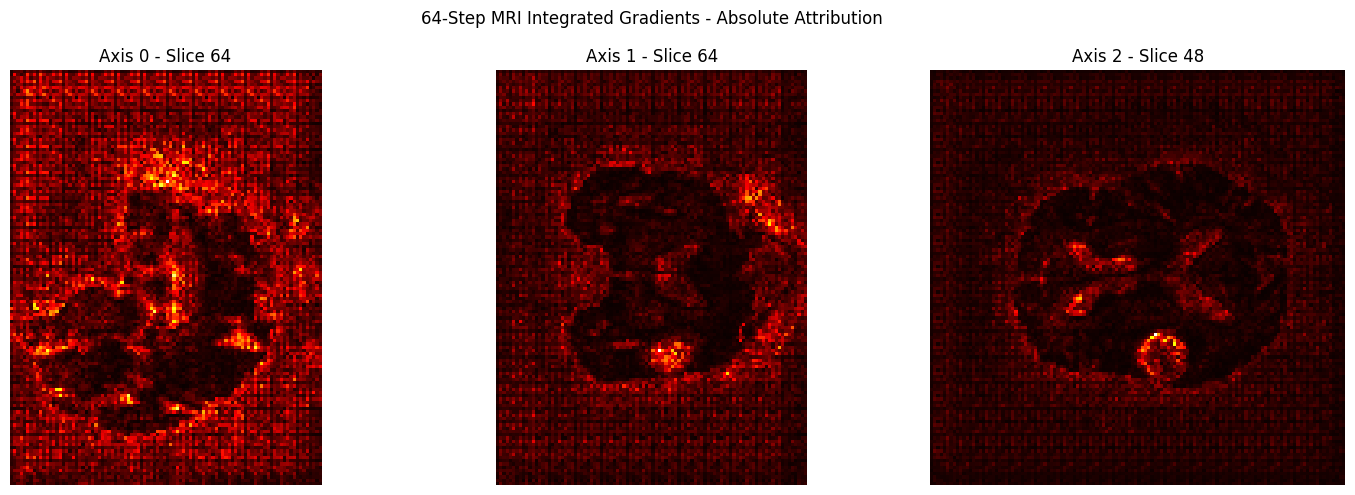

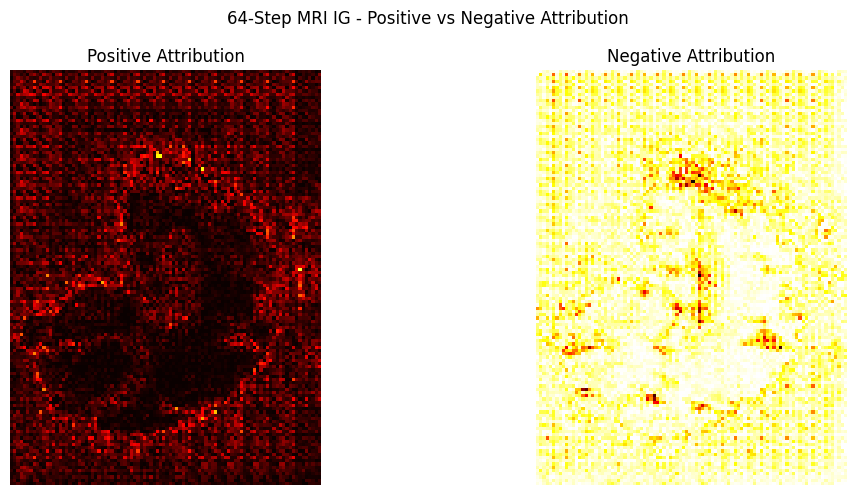


Saved 64-step visualization files:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/visualizations/MRI_IG_64steps_absolute_attribution.png
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/visualizations/MRI_IG_64steps_positive_negative.png


In [69]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os

# Load 64-step attribution tensor
ig_64_path = os.path.join(
    os.path.dirname(mri_ig_path),
    "MRI_IntegratedGradients_64steps_logit_margin.pt"
)

ig_64_tensor = torch.load(
    ig_64_path,
    map_location="cpu",
    weights_only=True
)

attr_64 = ig_64_tensor[0].numpy()

print("64-step attribution shape:", attr_64.shape)
print("Maximum absolute attribution:", np.abs(attr_64).max())
print("Mean absolute attribution:", np.abs(attr_64).mean())

# Aggregate attribution across MRI channels
spatial_abs_64 = np.sum(np.abs(attr_64), axis=0)

positive_64 = np.sum(np.maximum(attr_64, 0), axis=0)
negative_64 = np.sum(np.minimum(attr_64, 0), axis=0)

# Select valid slice indices
idx0 = spatial_abs_64.shape[0] // 2
idx1 = spatial_abs_64.shape[1] // 2
idx2 = spatial_abs_64.shape[2] // 2

# Save directory
visualization_dir = os.path.join(
    os.path.dirname(mri_ig_path),
    "visualizations"
)

os.makedirs(visualization_dir, exist_ok=True)

# --------------------------------------------------
# Figure 1: Absolute attribution maps
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    spatial_abs_64[idx0, :, :],
    spatial_abs_64[:, idx1, :],
    spatial_abs_64[:, :, idx2]
]

titles = [
    f"Axis 0 - Slice {idx0}",
    f"Axis 1 - Slice {idx1}",
    f"Axis 2 - Slice {idx2}"
]

for ax, image, title in zip(axes, images, titles):
    ax.imshow(image, cmap="hot")
    ax.set_title(title)
    ax.axis("off")

plt.suptitle("64-Step MRI Integrated Gradients - Absolute Attribution")
plt.tight_layout()

absolute_64_path = os.path.join(
    visualization_dir,
    "MRI_IG_64steps_absolute_attribution.png"
)

plt.savefig(absolute_64_path, dpi=300, bbox_inches="tight")
plt.show()

# --------------------------------------------------
# Figure 2: Positive and negative attribution
# --------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

positive_slice = positive_64[idx0, :, :]
negative_slice = negative_64[idx0, :, :]

# Use symmetric color limits for fair comparison
vmax = max(
    np.abs(positive_slice).max(),
    np.abs(negative_slice).max()
)

axes[0].imshow(
    positive_slice,
    cmap="hot",
    vmin=0,
    vmax=vmax
)
axes[0].set_title("Positive Attribution")
axes[0].axis("off")

axes[1].imshow(
    negative_slice,
    cmap="hot",
    vmin=-vmax,
    vmax=0
)
axes[1].set_title("Negative Attribution")
axes[1].axis("off")

plt.suptitle("64-Step MRI IG - Positive vs Negative Attribution")
plt.tight_layout()

signed_64_path = os.path.join(
    visualization_dir,
    "MRI_IG_64steps_positive_negative.png"
)

plt.savefig(signed_64_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved 64-step visualization files:")
print(absolute_64_path)
print(signed_64_path)

### Step 10: Clinical-Feature Integrated Gradients Attribution

This step computes Integrated Gradients attribution for the clinical input features used by the multimodal CNN–Vision Transformer model.

The MRI volume is held constant, while the clinical input is interpolated from a zero baseline to the actual clinical feature values.

The target is the logit margin between class 0 (IDH-wildtype) and class 1 (IDH-mutant).

The analysis reports:
- Attribution for each clinical feature
- Positive and negative attribution contributions
- Attribution sum
- Completeness difference

The resulting values describe the model's sensitivity to the clinical inputs relative to the selected baseline. They do not establish clinical causality or feature importance across the entire test cohort.

In [70]:
import torch
import numpy as np
import pandas as pd
import os

model.eval()

# MRI input is held constant
fixed_mri = mri_input.detach()

# Clinical input
clinical_actual = clinical_input.detach()

# Mathematical zero baseline
clinical_baseline = torch.zeros_like(clinical_actual)

# Number of integration steps
clinical_ig_steps = 64

# Accumulate gradients
total_clinical_gradients = torch.zeros_like(clinical_actual)

print("Calculating clinical-feature IG using 64 steps...")

for step in range(clinical_ig_steps + 1):

    alpha = step / clinical_ig_steps

    interpolated_clinical = (
        clinical_baseline
        + alpha * (clinical_actual - clinical_baseline)
    ).detach().requires_grad_(True)

    # MRI remains fixed
    logits = model(
        fixed_mri,
        interpolated_clinical
    )

    # Target: class 0 margin over class 1
    target_margin = logits[:, 0] - logits[:, 1]

    gradients = torch.autograd.grad(
        outputs=target_margin.sum(),
        inputs=interpolated_clinical
    )[0]

    # Trapezoidal integration
    weight = (
        0.5
        if step == 0 or step == clinical_ig_steps
        else 1.0
    )

    total_clinical_gradients += weight * gradients

# Average gradients
average_clinical_gradients = (
    total_clinical_gradients / clinical_ig_steps
)

# Integrated Gradients attribution
clinical_ig_attributions = (
    clinical_actual - clinical_baseline
) * average_clinical_gradients

clinical_ig_attributions = (
    clinical_ig_attributions.detach()
)

# Compute actual and baseline target margins
with torch.no_grad():

    actual_logits = model(
        fixed_mri,
        clinical_actual
    )

    baseline_logits = model(
        fixed_mri,
        clinical_baseline
    )

    actual_margin = (
        actual_logits[:, 0] - actual_logits[:, 1]
    ).item()

    baseline_margin = (
        baseline_logits[:, 0] - baseline_logits[:, 1]
    ).item()

target_margin_difference = (
    actual_margin - baseline_margin
)

# Attribution statistics
clinical_attr_sum = clinical_ig_attributions.sum().item()

clinical_completeness_difference = (
    target_margin_difference - clinical_attr_sum
)

clinical_attr_values = (
    clinical_ig_attributions[0]
    .detach()
    .cpu()
    .numpy()
)

# Feature labels: confirm this order matches preprocessing
clinical_feature_names = [
    "Age",
    "Sex"
]

clinical_results_df = pd.DataFrame({
    "Clinical Feature": clinical_feature_names,
    "Input Value": clinical_actual[0].cpu().numpy(),
    "IG Attribution": clinical_attr_values,
    "Absolute Attribution": np.abs(clinical_attr_values)
})

print("\nClinical IG Attribution Results")
display(clinical_results_df)

# Completeness summary
clinical_completeness_df = pd.DataFrame({
    "Metric": [
        "Actual target margin",
        "Baseline target margin",
        "Target margin difference",
        "Clinical IG attribution sum",
        "Completeness difference"
    ],
    "Value": [
        actual_margin,
        baseline_margin,
        target_margin_difference,
        clinical_attr_sum,
        clinical_completeness_difference
    ]
})

print("\nClinical IG Completeness Check")
display(clinical_completeness_df)

# Save outputs
clinical_ig_dir = os.path.join(
    os.path.dirname(mri_ig_path),
    "clinical"
)

os.makedirs(clinical_ig_dir, exist_ok=True)

clinical_csv_path = os.path.join(
    clinical_ig_dir,
    "Clinical_IG_attributions.csv"
)

clinical_completeness_path = os.path.join(
    clinical_ig_dir,
    "Clinical_IG_completeness.csv"
)

clinical_tensor_path = os.path.join(
    clinical_ig_dir,
    "Clinical_IntegratedGradients_64steps.pt"
)

clinical_results_df.to_csv(
    clinical_csv_path,
    index=False
)

clinical_completeness_df.to_csv(
    clinical_completeness_path,
    index=False
)

torch.save(
    clinical_ig_attributions.cpu(),
    clinical_tensor_path
)

print("\nSaved files:")
print(clinical_csv_path)
print(clinical_completeness_path)
print(clinical_tensor_path)

Calculating clinical-feature IG using 64 steps...

Clinical IG Attribution Results


,Clinical Feature,Input Value,IG Attribution,Absolute Attribution
0,Age,1.928345,2.655135,2.655135
1,Sex,0.000000,0.000000,0.000000



Clinical IG Completeness Check


,Metric,Value
0,Actual target margin,3.730636
1,Baseline target margin,1.077004
2,Target margin difference,2.653631
3,Clinical IG attribution sum,2.655135
4,Completeness difference,-0.001504



Saved files:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/clinical/Clinical_IG_attributions.csv
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/clinical/Clinical_IG_completeness.csv
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/clinical/Clinical_IntegratedGradients_64steps.pt


### Step 11: Test Cohort Inspection for Integrated Gradients

This step inspects the test dataset and dataloader structure before performing cohort-level Integrated Gradients analysis.

The objective is to identify how MRI volumes, clinical features, and ground-truth labels are accessed for individual test patients.

The inspection will help ensure that subsequent cohort-level attribution analysis uses the correct inputs and preserves the test cohort's class distribution.

In [71]:
import torch

print("TEST DATASET INSPECTION")
print("=" * 60)

print("Test loader exists:", "test_loader" in globals())

if "test_loader" in globals():

    print("Test dataset size:", len(test_loader.dataset))
    print("Number of batches:", len(test_loader))

    test_batch = next(iter(test_loader))

    print("\nFirst test batch type:", type(test_batch))

    if isinstance(test_batch, (tuple, list)):

        print("Number of batch components:", len(test_batch))

        for i, component in enumerate(test_batch):

            if torch.is_tensor(component):

                print(
                    f"Component {i}: "
                    f"shape={tuple(component.shape)}, "
                    f"dtype={component.dtype}, "
                    f"device={component.device}"
                )

            else:
                print(
                    f"Component {i}: "
                    f"type={type(component)}"
                )

    elif isinstance(test_batch, dict):

        print("Batch keys:", list(test_batch.keys()))

        for key, component in test_batch.items():

            if torch.is_tensor(component):

                print(
                    f"{key}: "
                    f"shape={tuple(component.shape)}, "
                    f"dtype={component.dtype}, "
                    f"device={component.device}"
                )

            else:
                print(f"{key}: type={type(component)}")

    print("\nDataset class:")
    print(type(test_loader.dataset))

else:

    print("test_loader is not available.")

TEST DATASET INSPECTION
Test loader exists: False
test_loader is not available.


### Step 11A: Locate Existing Test Dataset Objects

This step identifies dataset and dataloader variables currently available in the notebook runtime.

The purpose is to reuse the original test dataset and avoid recreating or changing the experimental data split.

No model training or dataset modification is performed.

In [72]:
import torch

print("SEARCHING EXISTING NOTEBOOK VARIABLES")
print("=" * 60)

keywords = ["test", "dataset", "loader", "clinical", "mri", "data"]

for name, obj in list(globals().items()):

    if any(keyword in name.lower() for keyword in keywords):

        if name.startswith("_"):
            continue

        print(f"\nVariable: {name}")
        print(f"Type: {type(obj)}")

        if isinstance(obj, torch.utils.data.DataLoader):
            print("DataLoader dataset size:", len(obj.dataset))
            print("Batch size:", obj.batch_size)

        elif isinstance(obj, torch.utils.data.Dataset):
            try:
                print("Dataset length:", len(obj))
            except Exception:
                pass

        elif torch.is_tensor(obj):
            print("Tensor shape:", tuple(obj.shape))

SEARCHING EXISTING NOTEBOOK VARIABLES

Variable: TEST_PATH
Type: <class 'str'>

Variable: TEST_CACHE_DIR
Type: <class 'str'>

Variable: checkpoint_metadata
Type: <class 'dict'>

Variable: test_df
Type: <class 'pandas.core.frame.DataFrame'>

Variable: test_ids
Type: <class 'set'>

Variable: MRI3DCNN
Type: <class 'type'>

Variable: MRITransformer
Type: <class 'type'>

Variable: CNNViTGatedClinicalIDHModel
Type: <class 'type'>

Variable: TEST_CSV
Type: <class 'pathlib._local.PosixPath'>

Variable: TEST_CACHE
Type: <class 'str'>

Variable: mri_path
Type: <class 'str'>

Variable: mri_array
Type: <class 'numpy.ndarray'>

Variable: mri_input
Type: <class 'torch.Tensor'>
Tensor shape: (1, 4, 128, 128, 96)

Variable: clinical_input
Type: <class 'torch.Tensor'>
Tensor shape: (1, 2)

Variable: mri_for_grad
Type: <class 'torch.Tensor'>
Tensor shape: (1, 4, 128, 128, 96)

Variable: mri_np
Type: <class 'numpy.ndarray'>

Variable: mri_grad
Type: <class 'torch.Tensor'>
Tensor shape: (1, 4, 128, 128, 9

### Step 11B: Inspecting the Test Dataset Sample Structure

This step inspects a single sample from the existing 94-patient test dataset.

The MRI tensor, clinical feature tensor, label, and sample metadata are examined to confirm the data structure required for cohort-level Integrated Gradients.

No training, data splitting, or modification of the dataset is performed.

In [73]:
import torch
import numpy as np

print("INSPECTING TEST DATASET SAMPLE")
print("=" * 60)

sample = test_dataset[0]

print("Sample type:", type(sample))

if isinstance(sample, (tuple, list)):

    print("Number of components:", len(sample))

    for i, component in enumerate(sample):

        print(f"\nComponent {i}:")
        print("Type:", type(component))

        if torch.is_tensor(component):
            print("Shape:", tuple(component.shape))
            print("Dtype:", component.dtype)
            print("Device:", component.device)
            print("Value:", component if component.numel() <= 10 else "Tensor too large")

        elif isinstance(component, np.ndarray):
            print("Shape:", component.shape)
            print("Dtype:", component.dtype)

            if component.size <= 10:
                print("Value:", component)

        else:
            print("Value:", component)

elif isinstance(sample, dict):

    print("Keys:", list(sample.keys()))

    for key, component in sample.items():

        print(f"\nKey: {key}")
        print("Type:", type(component))

        if torch.is_tensor(component):
            print("Shape:", tuple(component.shape))
            print("Dtype:", component.dtype)

        elif isinstance(component, np.ndarray):
            print("Shape:", component.shape)
            print("Dtype:", component.dtype)

        else:
            print("Value:", component)

else:
    print("Unexpected sample structure.")

INSPECTING TEST DATASET SAMPLE
Sample type: <class 'dict'>
Keys: ['mri', 'clinical', 'label', 'subject_id']

Key: mri
Type: <class 'torch.Tensor'>
Shape: (4, 128, 128, 96)
Dtype: torch.float32

Key: clinical
Type: <class 'torch.Tensor'>
Shape: (2,)
Dtype: torch.float32

Key: label
Type: <class 'torch.Tensor'>
Shape: ()
Dtype: torch.int64

Key: subject_id
Type: <class 'str'>
Value: BT1131


## Step 11C — Pilot Cohort Integrated Gradients

This cell validates the cohort-level Integrated Gradients implementation on two test subjects.

MRI and clinical modalities are analyzed separately using zero baselines. The target is the WT-versus-IDH-mutant logit margin. This is a pilot validation step; the results are not the final cohort-level explainability analysis.

In [74]:
import torch
import numpy as np

# ------------------------------------------------------------
# PILOT SETTINGS
# ------------------------------------------------------------
PILOT_N = 2
PILOT_STEPS = 16

# ------------------------------------------------------------
# MODEL AND DEVICE
# ------------------------------------------------------------
model.eval()
device = next(model.parameters()).device

print("MODEL DEVICE:", device)
print("PILOT SUBJECTS:", PILOT_N)
print("IG STEPS:", PILOT_STEPS)


# ------------------------------------------------------------
# INTEGRATED GRADIENTS FUNCTION
# ------------------------------------------------------------
def compute_ig_single_modality(
    mri_input,
    clinical_input,
    modality="mri",
    steps=16
):
    """
    Computes Integrated Gradients for one modality.

    Target:
        WT logit - IDH-mutant logit

    MRI IG:
        MRI baseline = zero
        Clinical input remains fixed

    Clinical IG:
        Clinical baseline = zero
        MRI input remains fixed
    """

    mri_input = mri_input.detach().to(device)
    clinical_input = clinical_input.detach().to(device)

    if modality == "mri":
        input_tensor = mri_input
        baseline = torch.zeros_like(input_tensor)
    elif modality == "clinical":
        input_tensor = clinical_input
        baseline = torch.zeros_like(input_tensor)
    else:
        raise ValueError("modality must be 'mri' or 'clinical'")

    # Calculate target at actual input
    with torch.no_grad():
        logits_actual = model(mri_input, clinical_input)
        target_actual = logits_actual[0, 0] - logits_actual[0, 1]

    # Calculate target at baseline for selected modality
    with torch.no_grad():
        if modality == "mri":
            logits_baseline = model(baseline, clinical_input)
        else:
            logits_baseline = model(mri_input, baseline)

        target_baseline = (
            logits_baseline[0, 0] - logits_baseline[0, 1]
        )

    # Trapezoidal approximation of gradients along the path
    alphas = torch.linspace(
        0.0, 1.0, steps + 1, device=device
    )

    accumulated_grads = torch.zeros_like(input_tensor)

    for i, alpha in enumerate(alphas):
        interpolated = (
            baseline + alpha * (input_tensor - baseline)
        ).detach().requires_grad_(True)

        if modality == "mri":
            logits = model(interpolated, clinical_input)
        else:
            logits = model(mri_input, interpolated)

        target = logits[0, 0] - logits[0, 1]

        grads = torch.autograd.grad(
            outputs=target,
            inputs=interpolated,
            retain_graph=False,
            create_graph=False
        )[0]

        # Trapezoidal endpoint weighting
        weight = 0.5 if i == 0 or i == steps else 1.0
        accumulated_grads += weight * grads.detach()

    average_grads = accumulated_grads / steps

    attributions = (input_tensor - baseline) * average_grads

    attribution_sum = attributions.sum().item()
    target_difference = (
        target_actual - target_baseline
    ).item()

    completeness_difference = (
        target_difference - attribution_sum
    )

    return {
        "attributions": attributions.detach(),
        "target_actual": target_actual.item(),
        "target_baseline": target_baseline.item(),
        "target_difference": target_difference,
        "attribution_sum": attribution_sum,
        "completeness_difference": completeness_difference
    }


# ------------------------------------------------------------
# RUN PILOT ON TWO SUBJECTS
# ------------------------------------------------------------
pilot_results = []

for idx in range(min(PILOT_N, len(test_dataset))):

    sample = test_dataset[idx]

    subject_id = sample["subject_id"]
    label = sample["label"].item()

    mri = sample["mri"].unsqueeze(0)
    clinical = sample["clinical"].unsqueeze(0)

    print("\n" + "=" * 65)
    print("SUBJECT:", subject_id)
    print("GROUND-TRUTH LABEL:", label)
    print("=" * 65)

    # MRI IG
    mri_result = compute_ig_single_modality(
        mri_input=mri,
        clinical_input=clinical,
        modality="mri",
        steps=PILOT_STEPS
    )

    # Clinical IG
    clinical_result = compute_ig_single_modality(
        mri_input=mri,
        clinical_input=clinical,
        modality="clinical",
        steps=PILOT_STEPS
    )

    print("\nMRI IG")
    print("Target difference:",
          mri_result["target_difference"])
    print("Attribution sum:",
          mri_result["attribution_sum"])
    print("Completeness difference:",
          mri_result["completeness_difference"])

    print("\nCLINICAL IG")
    print("Target difference:",
          clinical_result["target_difference"])
    print("Attribution sum:",
          clinical_result["attribution_sum"])
    print("Completeness difference:",
          clinical_result["completeness_difference"])

    pilot_results.append({
        "subject_id": subject_id,
        "label": label,
        "mri_target_difference": mri_result["target_difference"],
        "mri_attribution_sum": mri_result["attribution_sum"],
        "mri_completeness_difference":
            mri_result["completeness_difference"],
        "clinical_target_difference":
            clinical_result["target_difference"],
        "clinical_attribution_sum":
            clinical_result["attribution_sum"],
        "clinical_completeness_difference":
            clinical_result["completeness_difference"]
    })

print("\n" + "=" * 65)
print("PILOT IG COMPLETED")
print("=" * 65)

import pandas as pd

pilot_df = pd.DataFrame(pilot_results)
display(pilot_df)

MODEL DEVICE: cuda:0
PILOT SUBJECTS: 2
IG STEPS: 16

SUBJECT: BT1131
GROUND-TRUTH LABEL: 0

MRI IG
Target difference: 0.006117582321166992
Attribution sum: 0.005888609681278467
Completeness difference: 0.000228972639888525

CLINICAL IG
Target difference: 2.6536314487457275
Attribution sum: 2.6716082096099854
Completeness difference: -0.017976760864257812

SUBJECT: BT1103
GROUND-TRUTH LABEL: 0

MRI IG
Target difference: -0.0486912727355957
Attribution sum: -0.05068638175725937
Completeness difference: 0.0019951090216636658

CLINICAL IG
Target difference: 2.218748092651367
Attribution sum: 2.2082746028900146
Completeness difference: 0.010473489761352539

PILOT IG COMPLETED


,subject_id,label,mri_target_difference,mri_attribution_sum,mri_completeness_difference,clinical_target_difference,clinical_attribution_sum,clinical_completeness_difference
0,BT1131,0,0.006118,0.005889,0.000229,2.653631,2.671608,-0.017977
1,BT1103,0,-0.048691,-0.050686,0.001995,2.218748,2.208275,0.010473


## Step 11D — Full Test Cohort Integrated Gradients

This step calculates Integrated Gradients for MRI and clinical modalities across the complete 94-subject test cohort.

The analysis uses 32 integration steps per modality and a zero baseline. The target is the WT-minus-IDH-mutant logit margin.

Full MRI attribution volumes are not retained for all subjects. Instead, subject-level attribution summaries, channel-wise attribution magnitudes, clinical feature attributions, and completeness diagnostics are recorded.

This is a cohort-level quantitative explainability analysis. Attribution magnitudes alone do not establish biological validity, clinical utility, or causal importance.

In [75]:
import os
import gc
import numpy as np
import pandas as pd
import torch

# ============================================================
# CONFIGURATION
# ============================================================

COHORT_IG_STEPS = 32
N_TEST_SUBJECTS = len(test_dataset)

OUTPUT_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients/cohort"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("=" * 70)
print("FULL COHORT INTEGRATED GRADIENTS")
print("=" * 70)
print("Number of test subjects:", N_TEST_SUBJECTS)
print("IG steps per modality:", COHORT_IG_STEPS)
print("Device:", device)
print("Output directory:", OUTPUT_DIR)


# ============================================================
# COHORT LOOP
# ============================================================

cohort_records = []

model.eval()

for idx in range(N_TEST_SUBJECTS):

    sample = test_dataset[idx]

    subject_id = sample["subject_id"]
    label = int(sample["label"].item())

    mri = sample["mri"].unsqueeze(0).to(device)
    clinical = sample["clinical"].unsqueeze(0).to(device)

    # --------------------------------------------------------
    # MRI INTEGRATED GRADIENTS
    # --------------------------------------------------------

    mri_result = compute_ig_single_modality(
        mri_input=mri,
        clinical_input=clinical,
        modality="mri",
        steps=COHORT_IG_STEPS
    )

    mri_attr = mri_result["attributions"].squeeze(0)

    # Absolute attribution totals for each MRI channel
    channel_abs_sums = (
        mri_attr.abs()
        .sum(dim=(1, 2, 3))
        .cpu()
        .numpy()
    )

    channel_signed_sums = (
        mri_attr.sum(dim=(1, 2, 3))
        .cpu()
        .numpy()
    )

    total_abs_mri = float(channel_abs_sums.sum())

    if total_abs_mri > 0:
        channel_abs_fractions = (
            channel_abs_sums / total_abs_mri
        )
    else:
        channel_abs_fractions = np.zeros_like(
            channel_abs_sums
        )

    # Overall MRI attribution statistics
    mri_abs_sum = float(mri_attr.abs().sum().item())
    mri_signed_sum = float(mri_attr.sum().item())
    mri_mean_abs = float(mri_attr.abs().mean().item())
    mri_max_abs = float(mri_attr.abs().max().item())

    # --------------------------------------------------------
    # CLINICAL INTEGRATED GRADIENTS
    # --------------------------------------------------------

    clinical_result = compute_ig_single_modality(
        mri_input=mri,
        clinical_input=clinical,
        modality="clinical",
        steps=COHORT_IG_STEPS
    )

    clinical_attr = (
        clinical_result["attributions"]
        .squeeze(0)
        .cpu()
        .numpy()
    )

    # Feature order established in the model pipeline:
    # [age, sex]
    age_attribution = float(clinical_attr[0])
    sex_attribution = float(clinical_attr[1])

    # --------------------------------------------------------
    # RECORD SUBJECT-LEVEL RESULTS
    # --------------------------------------------------------

    record = {
        "subject_id": subject_id,
        "label": label,

        # MRI IG
        "mri_target_difference":
            mri_result["target_difference"],
        "mri_attribution_sum":
            mri_result["attribution_sum"],
        "mri_completeness_difference":
            mri_result["completeness_difference"],
        "mri_total_absolute_attribution":
            mri_abs_sum,
        "mri_total_signed_attribution":
            mri_signed_sum,
        "mri_mean_absolute_attribution":
            mri_mean_abs,
        "mri_max_absolute_attribution":
            mri_max_abs,

        # MRI channel-wise absolute attribution
        "mri_channel_0_abs_sum": channel_abs_sums[0],
        "mri_channel_1_abs_sum": channel_abs_sums[1],
        "mri_channel_2_abs_sum": channel_abs_sums[2],
        "mri_channel_3_abs_sum": channel_abs_sums[3],

        # MRI channel-wise attribution fractions
        "mri_channel_0_abs_fraction":
            channel_abs_fractions[0],
        "mri_channel_1_abs_fraction":
            channel_abs_fractions[1],
        "mri_channel_2_abs_fraction":
            channel_abs_fractions[2],
        "mri_channel_3_abs_fraction":
            channel_abs_fractions[3],

        # MRI channel-wise signed attribution
        "mri_channel_0_signed_sum":
            channel_signed_sums[0],
        "mri_channel_1_signed_sum":
            channel_signed_sums[1],
        "mri_channel_2_signed_sum":
            channel_signed_sums[2],
        "mri_channel_3_signed_sum":
            channel_signed_sums[3],

        # Clinical IG
        "clinical_target_difference":
            clinical_result["target_difference"],
        "clinical_attribution_sum":
            clinical_result["attribution_sum"],
        "clinical_completeness_difference":
            clinical_result["completeness_difference"],
        "age_attribution": age_attribution,
        "sex_attribution": sex_attribution
    }

    cohort_records.append(record)

    # --------------------------------------------------------
    # PROGRESS
    # --------------------------------------------------------

    if (idx + 1) % 10 == 0 or idx == 0:
        print(
            f"Processed {idx + 1}/{N_TEST_SUBJECTS} subjects | "
            f"Current subject: {subject_id} | "
            f"Label: {label}"
        )

    # Release intermediate attribution tensors
    del mri_attr
    del clinical_attr
    del mri_result
    del clinical_result
    del mri
    del clinical

    if (idx + 1) % 10 == 0:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# CREATE COHORT DATAFRAME
# ============================================================

cohort_ig_df = pd.DataFrame(cohort_records)

cohort_csv_path = os.path.join(
    OUTPUT_DIR,
    "Cohort_IntegratedGradients_SubjectLevel.csv"
)

cohort_ig_df.to_csv(
    cohort_csv_path,
    index=False
)

print("\n" + "=" * 70)
print("COHORT IG COMPLETED")
print("=" * 70)

print("Subjects processed:", len(cohort_ig_df))
print("Subject-level CSV:", cohort_csv_path)

display(cohort_ig_df.head())

FULL COHORT INTEGRATED GRADIENTS
Number of test subjects: 94
IG steps per modality: 32
Device: cuda:0
Output directory: /content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/cohort
Processed 1/94 subjects | Current subject: BT1131 | Label: 0
Processed 10/94 subjects | Current subject: BT0969 | Label: 1
Processed 20/94 subjects | Current subject: BT0120 | Label: 1
Processed 30/94 subjects | Current subject: BT0619 | Label: 0
Processed 40/94 subjects | Current subject: BT1303 | Label: 1
Processed 50/94 subjects | Current subject: BT0315 | Label: 1
Processed 60/94 subjects | Current subject: BT1209 | Label: 1
Processed 70/94 subjects | Current subject: BT0219 | Label: 0
Processed 80/94 subjects | Current subject: BT0616 | Label: 0
Processed 90/94 subjects | Current subject: BT0907 | Label: 0

COHORT IG COMPLETED
Subjects processed: 94
Subject-level CSV: /content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/cohort/Cohort_IntegratedGradients_Subject

,subject_id,label,mri_target_difference,mri_attribution_sum,mri_completeness_difference,mri_total_absolute_attribution,mri_total_signed_attribution,mri_mean_absolute_attribution,mri_max_absolute_attribution,mri_channel_0_abs_sum,...,mri_channel_3_abs_fraction,mri_channel_0_signed_sum,mri_channel_1_signed_sum,mri_channel_2_signed_sum,mri_channel_3_signed_sum,clinical_target_difference,clinical_attribution_sum,clinical_completeness_difference,age_attribution,sex_attribution
0,BT1131,0,0.006118,0.006681,-0.000563,0.219661,0.006681,3.491416e-08,1.582249e-06,0.054970,...,0.242172,-0.004280,0.002458,0.018494,-0.009991,2.653631,2.669964,-0.016332,2.669964,0.000000
1,BT1103,0,-0.048691,-0.049759,0.001067,0.281466,-0.049759,4.473776e-08,1.830866e-06,0.093143,...,0.166669,-0.038883,-0.019763,0.034130,-0.025243,2.218748,2.229115,-0.010367,2.214661,0.014453
2,BT0643,1,-0.024051,-0.023280,-0.000771,0.125711,-0.023280,1.998120e-08,7.721387e-07,0.037421,...,0.227234,-0.010416,-0.006325,0.000287,-0.006826,-2.746792,-2.743090,-0.003701,-2.743090,0.000000
3,BT0364,0,-0.165362,-0.165086,-0.000276,0.407583,-0.165086,6.478350e-08,1.581715e-06,0.137393,...,0.214391,-0.099884,-0.037016,0.044854,-0.073041,1.719738,1.714941,0.004797,1.763558,-0.048617
4,BT1100,0,0.005115,0.005354,-0.000240,0.194965,0.005354,3.098888e-08,1.117006e-06,0.053293,...,0.256151,-0.004912,0.007200,0.010515,-0.007449,2.218771,2.229540,-0.010768,2.229540,0.000000


## Step 11E — Cohort Integrated Gradients Summary

This step performs a cohort-level summary of the subject-level MRI and clinical Integrated Gradients results.

The analysis includes:
1. Completeness diagnostics for MRI and clinical IG.
2. MRI channel-wise absolute attribution fractions.
3. Clinical feature attribution distributions.
4. Comparisons between IDH-wildtype and IDH-mutant subjects.
5. Visualizations for the research paper.

The summaries are descriptive. They do not establish causal importance, biological localization, or clinical validity.

Subjects: 94
Labels: {0: 67, 1: 27}

COMPLETENESS DIAGNOSTICS


,count,mean,std,min,25%,50%,75%,max
mri_completeness_difference,94.0,-0.000324,0.001340,-0.007173,-0.000771,-0.000285,0.000605,0.003069
mri_relative_completeness_error,94.0,0.048428,0.084957,0.000676,0.008643,0.018644,0.046051,0.546356
clinical_completeness_difference,94.0,0.000197,0.006242,-0.018887,-0.002812,0.000028,0.003216,0.021344
clinical_relative_completeness_error,94.0,0.004490,0.013854,0.000003,0.000502,0.001691,0.003635,0.098426



MRI CHANNEL ATTRIBUTION SUMMARY


,mean,std,median,min,max
MRI Channel 0,0.310697,0.051778,0.315910,0.202635,0.437599
MRI Channel 1,0.283272,0.038040,0.285778,0.186577,0.428023
MRI Channel 2,0.186778,0.044965,0.176268,0.095932,0.322990
MRI Channel 3,0.219253,0.034136,0.218679,0.143301,0.292314



CLINICAL ATTRIBUTION SUMMARY


,mean,std,median,min,max
age_attribution,0.329416,1.684285,1.087158,-2.964268,2.669964
sex_attribution,0.011233,0.037840,0.000000,-0.057256,0.169846



CLASS-WISE IG SUMMARY


mri_total_absolute_attribution                      \
                                           mean       std    median   
IDH-wildtype (0)                       0.259415  0.098556  0.228219   
IDH-mutant (1)                         0.193405  0.069438  0.175453   

                 mri_completeness_difference            \
                                        mean       std   
IDH-wildtype (0)                   -0.000415  0.001480   
IDH-mutant (1)                     -0.000099  0.000888   

                 mri_relative_completeness_error           age_attribution  \
                                            mean    median            mean   
IDH-wildtype (0)                        0.049169  0.021920        0.935023   
IDH-mutant (1)                          0.046589  0.014355       -1.173388   

                                     sex_attribution                   \
                       std    median            mean       std median   
IDH-wildtype (0)  1.359628  1.452564        0.006367  0.035453    0.0   
IDH-mutant (1)    1.471092 -1.754138        0.023308  0.041455    0.0   

                 clinical_completeness_difference            \
                                             mean       std   
IDH-wildtype (0)                         0.000240  0.006625   
IDH-mutant (1)                           0.000091  0.005285   

                 clinical_relative_completeness_error            
                                                 mean    median  
IDH-wildtype (0)                             0.004052  0.001907  
IDH-mutant (1)                               0.005576  0.001180

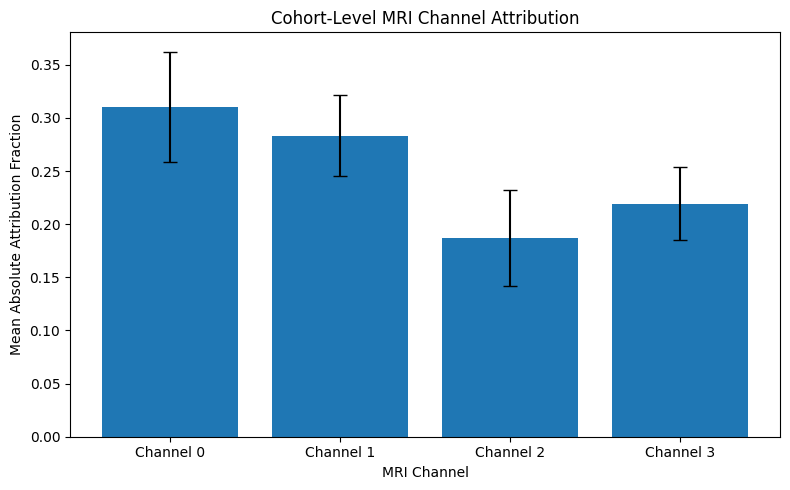

/tmp/ipykernel_493/2094658495.py:173: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


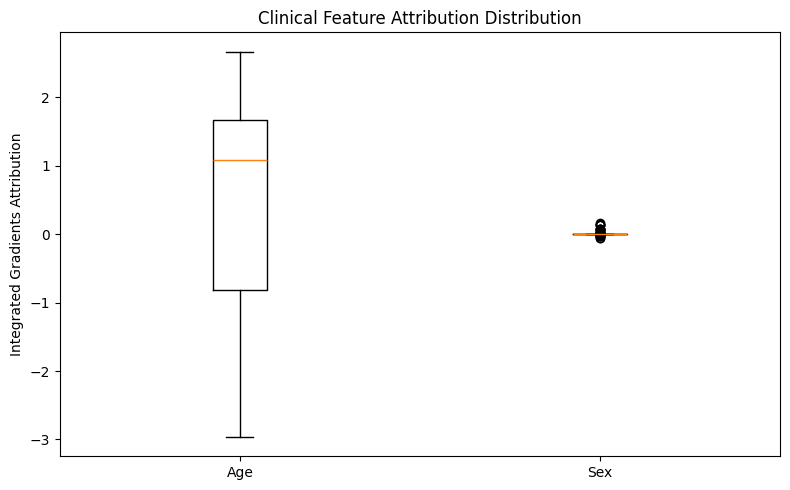

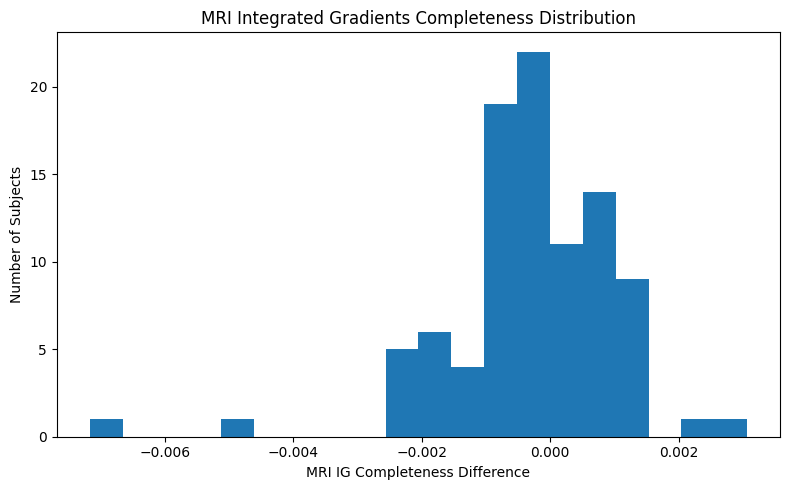

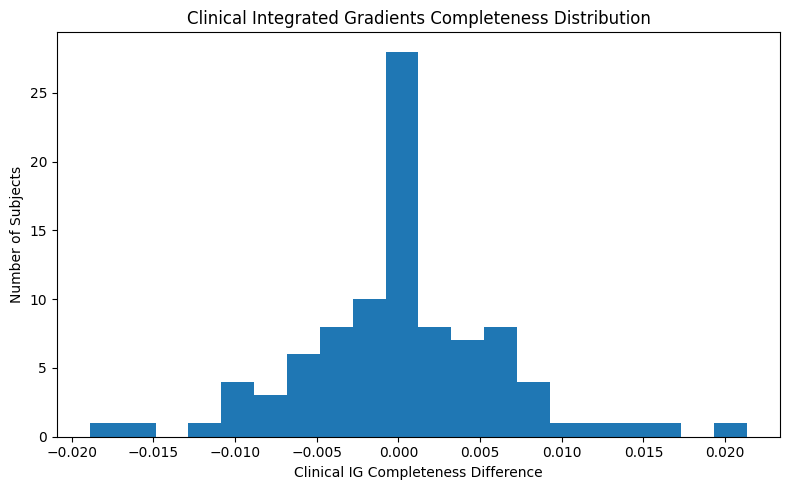


COHORT IG SUMMARY COMPLETED
Saved summary tables and figures to:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/cohort/summary


In [76]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

SUMMARY_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients/cohort/summary"
)

os.makedirs(SUMMARY_DIR, exist_ok=True)

# ============================================================
# LOAD COHORT RESULTS
# ============================================================

cohort_csv_path = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients/cohort/"
    "Cohort_IntegratedGradients_SubjectLevel.csv"
)

cohort_ig_df = pd.read_csv(cohort_csv_path)

print("Subjects:", len(cohort_ig_df))
print("Labels:", cohort_ig_df["label"].value_counts().to_dict())


# ============================================================
# COMPLETENESS DIAGNOSTICS
# ============================================================

epsilon = 1e-8

cohort_ig_df["mri_relative_completeness_error"] = (
    cohort_ig_df["mri_completeness_difference"].abs()
    / (cohort_ig_df["mri_target_difference"].abs() + epsilon)
)

cohort_ig_df["clinical_relative_completeness_error"] = (
    cohort_ig_df["clinical_completeness_difference"].abs()
    / (cohort_ig_df["clinical_target_difference"].abs() + epsilon)
)

diagnostic_columns = [
    "mri_completeness_difference",
    "mri_relative_completeness_error",
    "clinical_completeness_difference",
    "clinical_relative_completeness_error"
]

diagnostics = cohort_ig_df[diagnostic_columns].describe().T

diagnostics.to_csv(
    os.path.join(SUMMARY_DIR, "IG_Completeness_Diagnostics.csv")
)

print("\nCOMPLETENESS DIAGNOSTICS")
display(diagnostics)


# ============================================================
# MRI CHANNEL-WISE SUMMARY
# ============================================================

channel_fraction_columns = [
    "mri_channel_0_abs_fraction",
    "mri_channel_1_abs_fraction",
    "mri_channel_2_abs_fraction",
    "mri_channel_3_abs_fraction"
]

channel_summary = cohort_ig_df[channel_fraction_columns].agg(
    ["mean", "std", "median", "min", "max"]
).T

channel_summary.index = [
    "MRI Channel 0",
    "MRI Channel 1",
    "MRI Channel 2",
    "MRI Channel 3"
]

channel_summary.to_csv(
    os.path.join(SUMMARY_DIR, "MRI_Channel_Attribution_Summary.csv")
)

print("\nMRI CHANNEL ATTRIBUTION SUMMARY")
display(channel_summary)


# ============================================================
# CLINICAL FEATURE SUMMARY
# ============================================================

clinical_summary = cohort_ig_df[
    ["age_attribution", "sex_attribution"]
].agg(["mean", "std", "median", "min", "max"]).T

clinical_summary.to_csv(
    os.path.join(SUMMARY_DIR, "Clinical_Attribution_Summary.csv")
)

print("\nCLINICAL ATTRIBUTION SUMMARY")
display(clinical_summary)


# ============================================================
# CLASS-WISE SUMMARY
# ============================================================

class_summary = cohort_ig_df.groupby("label").agg({
    "mri_total_absolute_attribution": ["mean", "std", "median"],
    "mri_completeness_difference": ["mean", "std"],
    "mri_relative_completeness_error": ["mean", "median"],
    "age_attribution": ["mean", "std", "median"],
    "sex_attribution": ["mean", "std", "median"],
    "clinical_completeness_difference": ["mean", "std"],
    "clinical_relative_completeness_error": ["mean", "median"]
})

class_summary.index = [
    "IDH-wildtype (0)" if label == 0
    else "IDH-mutant (1)"
    for label in class_summary.index
]

class_summary.to_csv(
    os.path.join(SUMMARY_DIR, "Classwise_IG_Summary.csv")
)

print("\nCLASS-WISE IG SUMMARY")
display(class_summary)


# ============================================================
# PLOT 1 — MRI CHANNEL ATTRIBUTION FRACTIONS
# ============================================================

channel_means = cohort_ig_df[channel_fraction_columns].mean()
channel_stds = cohort_ig_df[channel_fraction_columns].std()

plt.figure(figsize=(8, 5))
plt.bar(
    ["Channel 0", "Channel 1", "Channel 2", "Channel 3"],
    channel_means.values,
    yerr=channel_stds.values,
    capsize=5
)

plt.ylabel("Mean Absolute Attribution Fraction")
plt.xlabel("MRI Channel")
plt.title("Cohort-Level MRI Channel Attribution")
plt.tight_layout()

plt.savefig(
    os.path.join(SUMMARY_DIR, "MRI_Channel_Attribution.png"),
    dpi=300
)
plt.show()


# ============================================================
# PLOT 2 — CLINICAL FEATURE ATTRIBUTION DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.boxplot(
    [
        cohort_ig_df["age_attribution"].values,
        cohort_ig_df["sex_attribution"].values
    ],
    labels=["Age", "Sex"]
)

plt.ylabel("Integrated Gradients Attribution")
plt.title("Clinical Feature Attribution Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(SUMMARY_DIR, "Clinical_IG_Distribution.png"),
    dpi=300
)
plt.show()


# ============================================================
# PLOT 3 — MRI COMPLETENESS DIFFERENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    cohort_ig_df["mri_completeness_difference"],
    bins=20
)

plt.xlabel("MRI IG Completeness Difference")
plt.ylabel("Number of Subjects")
plt.title("MRI Integrated Gradients Completeness Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(SUMMARY_DIR, "MRI_IG_Completeness_Distribution.png"),
    dpi=300
)
plt.show()


# ============================================================
# PLOT 4 — CLINICAL COMPLETENESS DIFFERENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    cohort_ig_df["clinical_completeness_difference"],
    bins=20
)

plt.xlabel("Clinical IG Completeness Difference")
plt.ylabel("Number of Subjects")
plt.title("Clinical Integrated Gradients Completeness Distribution")
plt.tight_layout()

plt.savefig(
    os.path.join(SUMMARY_DIR, "Clinical_IG_Completeness_Distribution.png"),
    dpi=300
)
plt.show()


# ============================================================
# SAVE ENRICHED SUBJECT-LEVEL RESULTS
# ============================================================

cohort_ig_df.to_csv(
    os.path.join(SUMMARY_DIR, "Cohort_IG_Results_With_Diagnostics.csv"),
    index=False
)

print("\n" + "=" * 70)
print("COHORT IG SUMMARY COMPLETED")
print("=" * 70)
print("Saved summary tables and figures to:")
print(SUMMARY_DIR)

## Step 12A — Inspect SHAP Prerequisites

This step identifies the trained multimodal model, training dataset, and feature preprocessing variables available in the current notebook runtime.

The inspection is necessary to design a SHAP analysis that explains the clinical features while keeping the MRI input fixed, rather than incorrectly treating the multimodal model as a clinical-only model.

In [77]:
print("=" * 70)
print("SHAP PREREQUISITE INSPECTION")
print("=" * 70)

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------
print("\nMODEL")
print("Model available:", "model" in globals())

if "model" in globals():
    print("Model class:", type(model))
    print("Device:", next(model.parameters()).device)
    print("Evaluation mode:", not model.training)


# ------------------------------------------------------------
# DATASETS
# ------------------------------------------------------------
print("\nDATASETS")

dataset_candidates = [
    "train_dataset",
    "val_dataset",
    "test_dataset",
    "train_df",
    "val_df",
    "test_df"
]

for name in dataset_candidates:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| Type:", type(obj),
            "| Length:", len(obj) if hasattr(obj, "__len__") else "N/A"
        )


# ------------------------------------------------------------
# CLINICAL FEATURE VARIABLES
# ------------------------------------------------------------
print("\nCLINICAL FEATURE VARIABLES")

clinical_candidates = [
    "clinical_cols",
    "clinical_features",
    "clinical_feature_names",
    "feature_cols",
    "scaler",
    "clinical_scaler",
    "train_loader",
    "train_dataset"
]

for name in clinical_candidates:
    if name in globals():
        obj = globals()[name]
        print(name, "| Type:", type(obj))

print("\n" + "=" * 70)
print("INSPECTION COMPLETED")
print("=" * 70)

SHAP PREREQUISITE INSPECTION

MODEL
Model available: True
Model class: <class '__main__.CNNViTGatedClinicalIDHModel'>
Device: cuda:0
Evaluation mode: True

DATASETS
test_dataset | Type: <class '__main__.UTSWGliomaComparisonDataset'> | Length: 94
train_df | Type: <class 'pandas.core.frame.DataFrame'> | Length: 435
val_df | Type: <class 'pandas.core.frame.DataFrame'> | Length: 93
test_df | Type: <class 'pandas.core.frame.DataFrame'> | Length: 94

CLINICAL FEATURE VARIABLES
clinical_feature_names | Type: <class 'list'>

INSPECTION COMPLETED


## Step 12B — Inspect Clinical Features for SHAP

This step verifies the clinical feature names, dataframe columns, and clinical input representation.

The goal is to ensure that the SHAP analysis uses the same feature order and preprocessing as the trained multimodal model.

In [78]:
import numpy as np
import pandas as pd
import torch

print("=" * 70)
print("CLINICAL FEATURE INSPECTION FOR SHAP")
print("=" * 70)

# ------------------------------------------------------------
# FEATURE NAMES
# ------------------------------------------------------------
print("\nClinical feature names:")
print(clinical_feature_names)

print("\nNumber of clinical features:")
print(len(clinical_feature_names))


# ------------------------------------------------------------
# TRAINING DATAFRAME COLUMNS
# ------------------------------------------------------------
print("\nTraining dataframe columns:")
print(train_df.columns.tolist())

print("\nTraining dataframe shape:")
print(train_df.shape)


# ------------------------------------------------------------
# TEST DATAFRAME COLUMNS
# ------------------------------------------------------------
print("\nTest dataframe columns:")
print(test_df.columns.tolist())


# ------------------------------------------------------------
# CLINICAL INPUT FROM TEST DATASET
# ------------------------------------------------------------
sample = test_dataset[0]

print("\nTest dataset clinical input:")
print(sample["clinical"])

print("\nClinical input shape:")
print(sample["clinical"].shape)

print("\nClinical input dtype:")
print(sample["clinical"].dtype)


# ------------------------------------------------------------
# CLINICAL FEATURE DISTRIBUTION
# ------------------------------------------------------------
print("\nTraining dataframe preview:")
display(train_df.head())

print("\nClinical feature summary, if columns exist in train_df:")

available_clinical_cols = [
    col for col in clinical_feature_names
    if col in train_df.columns
]

if available_clinical_cols:
    display(train_df[available_clinical_cols].describe())
else:
    print(
        "Clinical feature names are not directly present as dataframe "
        "columns. We will need to inspect the dataset preprocessing."
    )


# ------------------------------------------------------------
# SHAP PACKAGE
# ------------------------------------------------------------
try:
    import shap
    print("\nSHAP package version:", shap.__version__)
except ImportError:
    print("\nSHAP package is not installed.")


print("\n" + "=" * 70)
print("INSPECTION COMPLETED")
print("=" * 70)

CLINICAL FEATURE INSPECTION FOR SHAP

Clinical feature names:
['Age', 'Sex']

Number of clinical features:
2

Training dataframe columns:
['Subject_ID', 'T1', 'T1ce', 'T2', 'FLAIR', 'FeTS_Segmentation', 'Age', 'Sex', 'Tumor_Type', 'Tumor_Grade', 'IDH', 'MGMT', '1p19q', 'T1_Exists', 'T1ce_Exists', 'T2_Exists', 'FLAIR_Exists', 'IDH_Label', 'Age_Scaled', 'Sex_Encoded']

Training dataframe shape:
(435, 20)

Test dataframe columns:
['Subject_ID', 'T1', 'T1ce', 'T2', 'FLAIR', 'FeTS_Segmentation', 'Age', 'Sex', 'Tumor_Type', 'Tumor_Grade', 'IDH', 'MGMT', '1p19q', 'T1_Exists', 'T1ce_Exists', 'T2_Exists', 'FLAIR_Exists', 'IDH_Label', 'Age_Scaled', 'Sex_Encoded']

Test dataset clinical input:
tensor([1.9283, 0.0000])

Clinical input shape:
torch.Size([2])

Clinical input dtype:
torch.float32

Training dataframe preview:


,Subject_ID,T1,T1ce,T2,FLAIR,FeTS_Segmentation,Age,Sex,Tumor_Type,Tumor_Grade,IDH,MGMT,1p19q,T1_Exists,T1ce_Exists,T2_Exists,FLAIR_Exists,IDH_Label,Age_Scaled,Sex_Encoded
0,BT0348,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,63,F,GLIOBLASTOMA,4.0,wild type,NaN,NaN,True,True,True,True,0,0.567765,1.0
1,BT0243,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,63,M,GLIOBLASTOMA,4.0,wild type,NaN,NaN,True,True,True,True,0,0.567765,0.0
2,BT0687,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,29,F,GLIOBLASTOMA,4.0,mutated,unmethylated,non co-deleted,True,True,True,True,1,-1.635079,1.0
3,BT0629,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,63,M,GLIOBLASTOMA,4.0,wild type,unmethylated,NaN,True,True,True,True,0,0.567765,0.0
4,BT1108,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,/content/drive/MyDrive/Glioma_Research/dataset...,70,M,GLIOBLASTOMA,4.0,wild type,NaN,NaN,True,True,True,True,0,1.021291,0.0



Clinical feature summary, if columns exist in train_df:


,Age
count,435.000000
mean,54.236782
std,15.452366
min,18.000000
25%,42.500000
50%,57.000000
75%,66.000000
max,85.000000



SHAP package version: 0.54.1

INSPECTION COMPLETED


## Step 12C — Clinical SHAP Pilot

This step uses SHAP KernelExplainer to explain the clinical inputs of a single test subject while holding the MRI input fixed.

The clinical feature inputs use the trained model's preprocessing representation:
- Age_Scaled
- Sex_Encoded

The background reference is the mean of the corresponding training features. The target is the WT-minus-IDH-mutant logit margin.

This pilot is intended to verify the implementation and interpretability of the resulting clinical feature contributions.

In [79]:
import numpy as np
import pandas as pd
import torch
import shap

# ============================================================
# SETTINGS
# ============================================================

SHAP_FEATURE_COLUMNS = ["Age_Scaled", "Sex_Encoded"]
SHAP_FEATURE_NAMES = ["Age", "Sex"]

SHAP_PILOT_INDEX = 0
SHAP_NSAMPLES = 4

model.eval()
device = next(model.parameters()).device

# ============================================================
# TRAINING-DERIVED BACKGROUND
# ============================================================

background_values = (
    train_df[SHAP_FEATURE_COLUMNS]
    .astype(float)
    .mean()
    .values
    .astype(np.float32)
)

background = background_values.reshape(1, -1)

print("SHAP background:")
print(pd.DataFrame(background, columns=SHAP_FEATURE_NAMES))

# ============================================================
# SELECT PILOT SUBJECT
# ============================================================

sample = test_dataset[SHAP_PILOT_INDEX]

subject_id = sample["subject_id"]
label = int(sample["label"].item())

fixed_mri = sample["mri"].unsqueeze(0).to(device)

clinical_input = (
    sample["clinical"]
    .unsqueeze(0)
    .to(device)
    .detach()
)

clinical_numpy = clinical_input.cpu().numpy()

print("\nSubject ID:", subject_id)
print("True label:", label)
print("Clinical input:", clinical_numpy)
print("MRI shape:", tuple(fixed_mri.shape))

# ============================================================
# SHAP PREDICTION FUNCTION
# ============================================================

def shap_clinical_predict(clinical_numpy_batch):

    clinical_numpy_batch = np.asarray(
        clinical_numpy_batch,
        dtype=np.float32
    )

    if clinical_numpy_batch.ndim == 1:
        clinical_numpy_batch = clinical_numpy_batch.reshape(1, -1)

    clinical_batch = torch.tensor(
        clinical_numpy_batch,
        dtype=torch.float32,
        device=device
    )

    batch_size = clinical_batch.shape[0]

    # Repeat the same MRI for all clinical rows
    mri_batch = fixed_mri.repeat(
        batch_size, 1, 1, 1, 1
    )

    with torch.no_grad():
        logits = model(mri_batch, clinical_batch)

        # Target: WT logit - IDH-mutant logit
        margin = logits[:, 0] - logits[:, 1]

    return margin.detach().cpu().numpy()


# ============================================================
# KERNEL SHAP
# ============================================================

explainer = shap.KernelExplainer(
    shap_clinical_predict,
    background,
    feature_names=SHAP_FEATURE_NAMES
)

shap_values = explainer.shap_values(
    clinical_numpy,
    nsamples=SHAP_NSAMPLES
)

shap_values = np.asarray(shap_values).reshape(-1)

# ============================================================
# SHAP OUTPUT
# ============================================================

shap_pilot_df = pd.DataFrame({
    "subject_id": [subject_id],
    "label": [label],
    "Age_input": [clinical_numpy[0, 0]],
    "Sex_input": [clinical_numpy[0, 1]],
    "Age_SHAP": [shap_values[0]],
    "Sex_SHAP": [shap_values[1]]
})

print("\nSHAP PILOT RESULTS")
display(shap_pilot_df)

print("\nSHAP expected value:")
print(explainer.expected_value)

print("\nModel target for subject:")
print(shap_clinical_predict(clinical_numpy))

print("\nSHAP values:")
print(shap_values)

print("\nSHAP pilot completed.")

SHAP background:
            Age      Sex
0 -1.020895e-16  0.42069

Subject ID: BT1131
True label: 0
Clinical input: [[1.9283447 0.       ]]
MRI shape: (1, 4, 128, 128, 96)


  0%|          | 0/1 [00:00<?, ?it/s]


SHAP PILOT RESULTS


,subject_id,label,Age_input,Sex_input,Age_SHAP,Sex_SHAP
0,BT1131,0,1.928345,0.0,2.635634,-0.014981



SHAP expected value:
1.109982967376709

Model target for subject:
[3.730636]

SHAP values:
[ 2.63563412 -0.01498121]

SHAP pilot completed.


## Step 12D — Full Cohort Clinical SHAP Analysis

This step computes clinical SHAP values for all 94 test subjects.

The MRI input is held fixed for each subject, while Age and Sex are explained using Kernel SHAP.

The reference background is derived from the mean of the training-set clinical features. SHAP values are calculated for the WT-minus-IDH-mutant logit margin.

The analysis records:
- Subject ID and ground-truth label
- Age and Sex model inputs
- SHAP attribution for Age and Sex
- SHAP expected value
- Actual model target
- SHAP additive reconstruction
- Additivity residual

This is a conditional clinical explanation. It does not directly attribute the MRI voxels.

In [80]:
import os
import gc
import numpy as np
import pandas as pd
import torch
import shap

# ============================================================
# CONFIGURATION
# ============================================================

SHAP_STEPS = 100
SHAP_FEATURE_COLUMNS = ["Age_Scaled", "Sex_Encoded"]
SHAP_FEATURE_NAMES = ["Age", "Sex"]

SHAP_OUTPUT_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/clinical"
)

os.makedirs(SHAP_OUTPUT_DIR, exist_ok=True)

model.eval()
device = next(model.parameters()).device

# Training-derived background reference
background = (
    train_df[SHAP_FEATURE_COLUMNS]
    .astype(float)
    .mean()
    .values
    .astype(np.float32)
    .reshape(1, -1)
)

print("=" * 70)
print("FULL COHORT CLINICAL SHAP")
print("=" * 70)
print("Subjects:", len(test_dataset))
print("Features:", SHAP_FEATURE_NAMES)
print("Kernel SHAP nsamples:", SHAP_STEPS)
print("Device:", device)
print("Background:", background)


# ============================================================
# COHORT SHAP LOOP
# ============================================================

shap_records = []

for idx in range(len(test_dataset)):

    sample = test_dataset[idx]

    subject_id = sample["subject_id"]
    label = int(sample["label"].item())

    fixed_mri = sample["mri"].unsqueeze(0).to(device)

    clinical_input = (
        sample["clinical"]
        .unsqueeze(0)
        .to(device)
    )

    clinical_numpy = clinical_input.detach().cpu().numpy()

    # --------------------------------------------------------
    # SUBJECT-SPECIFIC SHAP PREDICT FUNCTION
    # MRI remains fixed for this subject
    # --------------------------------------------------------

    def subject_shap_predict(clinical_numpy_batch):

        clinical_numpy_batch = np.asarray(
            clinical_numpy_batch,
            dtype=np.float32
        )

        if clinical_numpy_batch.ndim == 1:
            clinical_numpy_batch = clinical_numpy_batch.reshape(1, -1)

        clinical_batch = torch.tensor(
            clinical_numpy_batch,
            dtype=torch.float32,
            device=device
        )

        batch_size = clinical_batch.shape[0]

        mri_batch = fixed_mri.repeat(
            batch_size, 1, 1, 1, 1
        )

        with torch.no_grad():
            logits = model(mri_batch, clinical_batch)

            # WT logit - IDH-mutant logit
            target_margin = logits[:, 0] - logits[:, 1]

        return target_margin.detach().cpu().numpy()

    # --------------------------------------------------------
    # KERNEL SHAP
    # --------------------------------------------------------

    explainer = shap.KernelExplainer(
        subject_shap_predict,
        background,
        feature_names=SHAP_FEATURE_NAMES
    )

    values = explainer.shap_values(
        clinical_numpy,
        nsamples=SHAP_STEPS
    )

    values = np.asarray(values).reshape(-1)

    # --------------------------------------------------------
    # ADDITIVITY DIAGNOSTIC
    # --------------------------------------------------------

    expected_value = float(
        np.asarray(explainer.expected_value).reshape(-1)[0]
    )

    actual_target = float(
        subject_shap_predict(clinical_numpy)[0]
    )

    shap_reconstructed_target = (
        expected_value + float(values.sum())
    )

    additivity_residual = (
        actual_target - shap_reconstructed_target
    )

    # --------------------------------------------------------
    # RECORD
    # --------------------------------------------------------

    shap_records.append({
        "subject_id": subject_id,
        "label": label,

        "Age_input": float(clinical_numpy[0, 0]),
        "Sex_input": float(clinical_numpy[0, 1]),

        "Age_SHAP": float(values[0]),
        "Sex_SHAP": float(values[1]),

        "SHAP_expected_value": expected_value,
        "actual_WT_minus_mutant_margin": actual_target,
        "SHAP_reconstructed_margin": shap_reconstructed_target,
        "SHAP_additivity_residual": additivity_residual
    })

    # --------------------------------------------------------
    # PROGRESS
    # --------------------------------------------------------

    if (idx + 1) % 10 == 0 or idx == 0:
        print(
            f"Processed {idx + 1}/{len(test_dataset)} | "
            f"Subject: {subject_id} | "
            f"Label: {label} | "
            f"Additivity residual: {additivity_residual:.6f}"
        )

    del explainer
    del fixed_mri
    del clinical_input

    if (idx + 1) % 10 == 0:
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()


# ============================================================
# SAVE SUBJECT-LEVEL SHAP RESULTS
# ============================================================

clinical_shap_df = pd.DataFrame(shap_records)

shap_csv_path = os.path.join(
    SHAP_OUTPUT_DIR,
    "Clinical_SHAP_SubjectLevel_94Subjects.csv"
)

clinical_shap_df.to_csv(
    shap_csv_path,
    index=False
)

print("\n" + "=" * 70)
print("FULL COHORT CLINICAL SHAP COMPLETED")
print("=" * 70)

print("Subjects processed:", len(clinical_shap_df))
print("Output CSV:", shap_csv_path)

print("\nFirst 5 results:")
display(clinical_shap_df.head())

print("\nAdditivity residual summary:")
display(
    clinical_shap_df["SHAP_additivity_residual"].describe()
)

FULL COHORT CLINICAL SHAP
Subjects: 94
Features: ['Age', 'Sex']
Kernel SHAP nsamples: 100
Device: cuda:0
Background: [[-1.0208947e-16  4.2068964e-01]]


  0%|          | 0/1 [00:00<?, ?it/s]

Processed 1/94 | Subject: BT1131 | Label: 0 | Additivity residual: 0.000000


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (99 outputs left out)


FULL COHORT CLINICAL SHAP COMPLETED
Subjects processed: 94
Output CSV: /content/drive/MyDrive/Glioma_Research/explainability/shap/clinical/Clinical_SHAP_SubjectLevel_94Subjects.csv

First 5 results:


,subject_id,label,Age_input,Sex_input,Age_SHAP,Sex_SHAP,SHAP_expected_value,actual_WT_minus_mutant_margin,SHAP_reconstructed_margin,SHAP_additivity_residual
0,BT1131,0,1.928345,0.0,2.635634,-0.014981,1.109983,3.730636,3.730636,0.0
1,BT1103,0,1.474818,1.0,2.126116,0.059586,1.058375,3.244077,3.244077,0.0
2,BT0643,1,-1.764658,0.0,-2.762532,-0.017124,0.991421,-1.788235,-1.788235,0.0
3,BT0364,0,1.021291,1.0,1.638276,0.048581,0.975755,2.662612,2.662612,0.0
4,BT1100,0,1.474818,0.0,2.202291,-0.016303,1.109091,3.295079,3.295079,0.0



Additivity residual summary:


,SHAP_additivity_residual
count,94.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


## Step 12E — Cohort-Level Clinical SHAP Visualizations

This step visualizes the clinical SHAP results across the 94-subject test cohort.

The figures include:
- Global mean absolute SHAP importance
- SHAP beeswarm distribution
- Class-wise clinical attribution distributions
- Age SHAP dependence
- Descriptive statistical summaries

All SHAP values explain the WT-minus-IDH-mutant logit margin while each subject's MRI is held fixed.

These visualizations are descriptive model explanations and should not be interpreted as causal or biological evidence.

Subjects: 94
Class distribution:
Class_Name
IDH-wildtype    67
IDH-mutant      27
Name: count, dtype: int64


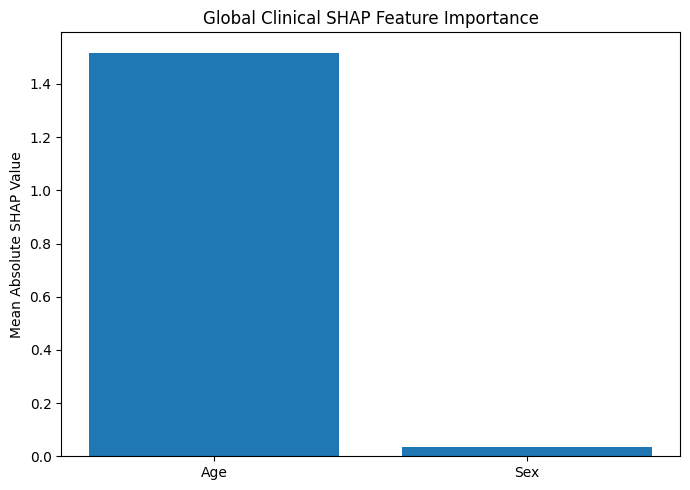

,Feature,Mean_Absolute_SHAP
0,Age,1.518286
1,Sex,0.035583


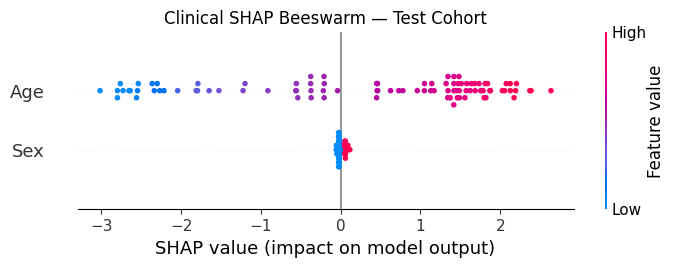

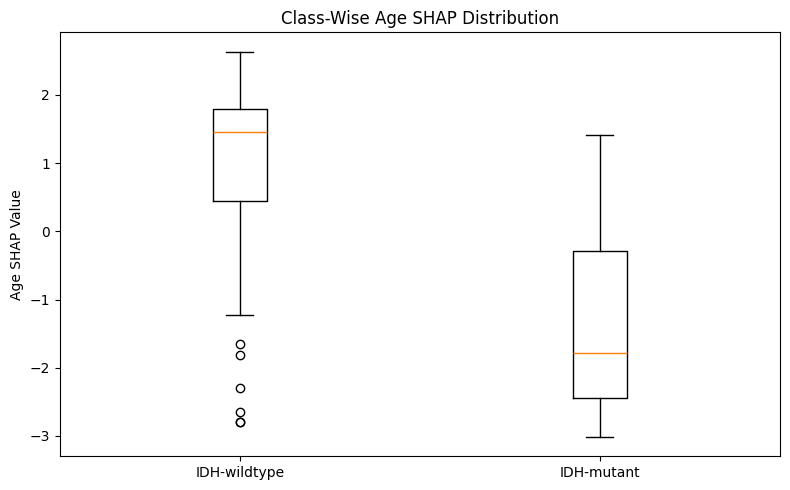

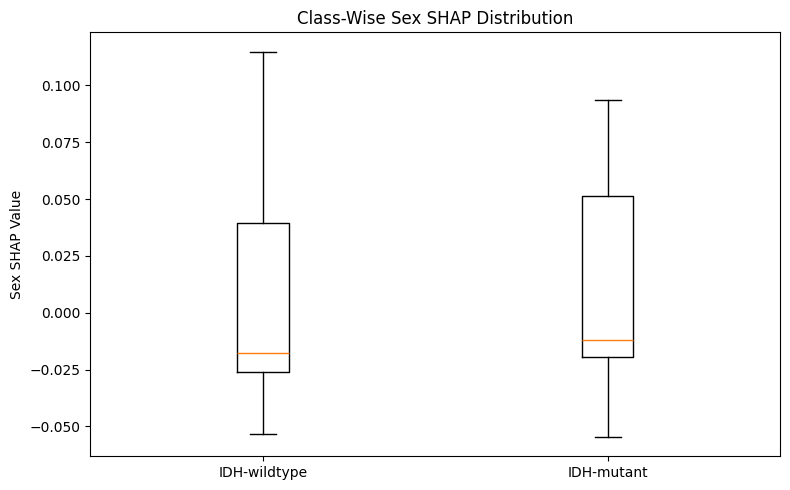

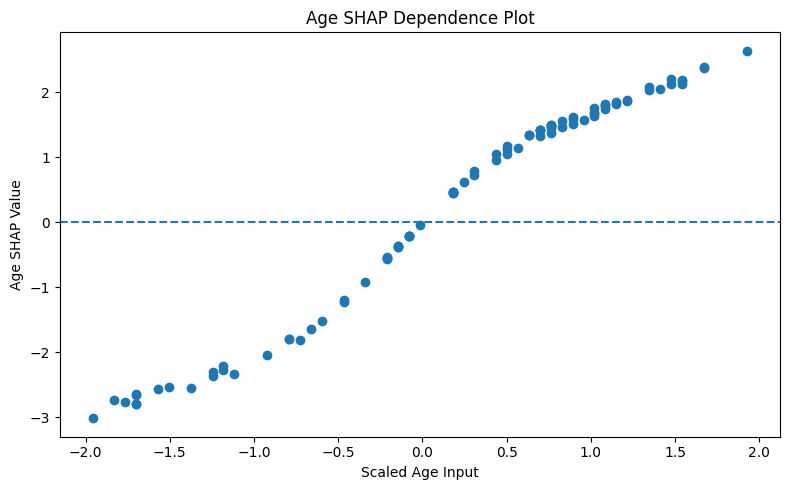


CLINICAL SHAP VISUALIZATION COMPLETED
Saved figures and tables to:
/content/drive/MyDrive/Glioma_Research/explainability/shap/clinical

Statistical summary:


,count,mean,std,min,25%,50%,75%,max,Mean_Absolute_SHAP
Age_SHAP,94.0,0.304193,1.671681,-3.01629,-0.825395,1.049509,1.612456,2.635634,1.518286
Sex_SHAP,94.0,0.003590,0.041830,-0.05463,-0.024676,-0.017406,0.044869,0.114846,0.035583


In [81]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ============================================================
# CONFIGURATION
# ============================================================

SHAP_OUTPUT_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/clinical"
)

os.makedirs(SHAP_OUTPUT_DIR, exist_ok=True)

# Load saved subject-level results
clinical_shap_df = pd.read_csv(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_SubjectLevel_94Subjects.csv"
    )
)

# Class names
clinical_shap_df["Class_Name"] = clinical_shap_df["label"].map({
    0: "IDH-wildtype",
    1: "IDH-mutant"
})

print("Subjects:", len(clinical_shap_df))
print("Class distribution:")
print(clinical_shap_df["Class_Name"].value_counts())


# ============================================================
# 1. GLOBAL SHAP IMPORTANCE
# ============================================================

feature_names = ["Age", "Sex"]

shap_matrix = clinical_shap_df[
    ["Age_SHAP", "Sex_SHAP"]
].values

mean_abs_shap = np.mean(
    np.abs(shap_matrix),
    axis=0
)

global_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

plt.figure(figsize=(7, 5))

plt.bar(
    global_importance_df["Feature"],
    global_importance_df["Mean_Absolute_SHAP"]
)

plt.ylabel("Mean Absolute SHAP Value")
plt.title("Global Clinical SHAP Feature Importance")
plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_Global_Importance.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(global_importance_df)


# ============================================================
# 2. SHAP BEESWARM PLOT
# ============================================================

shap_explanation = shap.Explanation(
    values=shap_matrix,
    data=clinical_shap_df[
        ["Age_input", "Sex_input"]
    ].values,
    feature_names=feature_names
)

plt.figure(figsize=(8, 5))

shap.plots.beeswarm(
    shap_explanation,
    max_display=2,
    show=False
)

plt.title("Clinical SHAP Beeswarm — Test Cohort")

plt.savefig(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_Beeswarm.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. CLASS-WISE AGE SHAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

class_names = ["IDH-wildtype", "IDH-mutant"]

age_shap_groups = [
    clinical_shap_df.loc[
        clinical_shap_df["Class_Name"] == class_name,
        "Age_SHAP"
    ].values
    for class_name in class_names
]

plt.boxplot(
    age_shap_groups,
    tick_labels=class_names
)

plt.ylabel("Age SHAP Value")
plt.title("Class-Wise Age SHAP Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_Age_Classwise.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. CLASS-WISE SEX SHAP DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

sex_shap_groups = [
    clinical_shap_df.loc[
        clinical_shap_df["Class_Name"] == class_name,
        "Sex_SHAP"
    ].values
    for class_name in class_names
]

plt.boxplot(
    sex_shap_groups,
    tick_labels=class_names
)

plt.ylabel("Sex SHAP Value")
plt.title("Class-Wise Sex SHAP Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_Sex_Classwise.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 5. AGE SHAP DEPENDENCE
# ============================================================

plt.figure(figsize=(8, 5))

plt.scatter(
    clinical_shap_df["Age_input"],
    clinical_shap_df["Age_SHAP"]
)

plt.xlabel("Scaled Age Input")
plt.ylabel("Age SHAP Value")
plt.title("Age SHAP Dependence Plot")

plt.axhline(0, linestyle="--")

plt.tight_layout()

plt.savefig(
    os.path.join(
        SHAP_OUTPUT_DIR,
        "Clinical_SHAP_Age_Dependence.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 6. SHAP STATISTICAL SUMMARY
# ============================================================

shap_summary = clinical_shap_df[
    ["Age_SHAP", "Sex_SHAP"]
].describe().T

shap_summary["Mean_Absolute_SHAP"] = [
    np.mean(np.abs(clinical_shap_df["Age_SHAP"])),
    np.mean(np.abs(clinical_shap_df["Sex_SHAP"]))
]

summary_path = os.path.join(
    SHAP_OUTPUT_DIR,
    "Clinical_SHAP_Statistical_Summary.csv"
)

shap_summary.to_csv(summary_path)

print("\n" + "=" * 70)
print("CLINICAL SHAP VISUALIZATION COMPLETED")
print("=" * 70)

print("Saved figures and tables to:")
print(SHAP_OUTPUT_DIR)

print("\nStatistical summary:")
display(shap_summary)

### MRI SHAP — Dataset and Model Input Inspection

Before implementing MRI SHAP, we inspect the test dataset's MRI tensor, clinical tensor, label, and subject identifier. This ensures that the SHAP wrapper uses the exact inputs expected by the trained multimodal model.

We will investigate channel-level MRI contributions rather than attempting computationally expensive voxel-wise Kernel SHAP on the full 3D volume.

In [82]:

# ============================================================
# STEP 12 — MRI SHAP PREREQUISITE INSPECTION
# ============================================================

import inspect
import torch

print("=" * 70)
print("MRI SHAP PREREQUISITE INSPECTION")
print("=" * 70)

sample = test_dataset[0]

print("\nSample type:", type(sample))

if isinstance(sample, dict):
    print("\nKeys:", list(sample.keys()))

    for key, value in sample.items():
        if torch.is_tensor(value):
            print(f"{key}: shape={tuple(value.shape)}, dtype={value.dtype}")
        else:
            print(f"{key}: type={type(value)}, value={value}")

elif isinstance(sample, (tuple, list)):
    print("\nNumber of elements:", len(sample))

    for i, value in enumerate(sample):
        if torch.is_tensor(value):
            print(f"Element {i}: shape={tuple(value.shape)}, dtype={value.dtype}")
        else:
            print(f"Element {i}: type={type(value)}, value={value}")

print("\nModel forward signature:")
print(inspect.signature(model.forward))

print("\nMRI SHAP inspection completed.")


MRI SHAP PREREQUISITE INSPECTION

Sample type: <class 'dict'>

Keys: ['mri', 'clinical', 'label', 'subject_id']
mri: shape=(4, 128, 128, 96), dtype=torch.float32
clinical: shape=(2,), dtype=torch.float32
label: shape=(), dtype=torch.int64
subject_id: type=<class 'str'>, value=BT1131

Model forward signature:
(mri, clinical)

MRI SHAP inspection completed.


### MRI Modality-Level SHAP

This analysis estimates the contribution of each MRI modality (T1, T1ce, T2, and FLAIR) to the trained model's output using grouped modality masking.

The explanation target is the WT-minus-mutant logit margin. A modality is replaced by its reference input while the remaining modalities and clinical features are held fixed. Contributions are calculated over modality subsets to account for interactions between modalities.

The reference input is a computational baseline and should not be interpreted as a healthy MRI scan. These values represent model-dependent modality contributions, not causal or clinically validated biomarkers.

In [83]:

# ============================================================
# STEP 13A — EXACT GROUPED SHAPLEY PILOT FOR MRI MODALITIES
# ============================================================

import itertools
import math
import numpy as np
import pandas as pd
import torch

model.eval()

device = next(model.parameters()).device

sample = test_dataset[0]

mri = sample["mri"].unsqueeze(0).to(device)
clinical = sample["clinical"].unsqueeze(0).to(device)

subject_id = sample["subject_id"]
true_label = int(sample["label"].item())

# Confirm channel order from the dataset preprocessing pipeline.
# Assumed order: T1, T1ce, T2, FLAIR.
modality_names = ["T1", "T1ce", "T2", "FLAIR"]

num_modalities = mri.shape[1]
assert num_modalities == len(modality_names)

# Reference MRI: zero tensor.
# This is a mathematical baseline, NOT a healthy MRI.
baseline = torch.zeros_like(mri)

# Evaluate WT-minus-mutant logit margin.
def get_margin(mri_input):
    with torch.no_grad():
        logits = model(mri_input, clinical)
        margin = logits[:, 0] - logits[:, 1]
    return float(margin.item())

# Calculate model output for each subset of modalities.
subset_values = {}

for subset_size in range(num_modalities + 1):
    for subset in itertools.combinations(range(num_modalities), subset_size):

        masked_mri = baseline.clone()

        if len(subset) > 0:
            masked_mri[:, list(subset)] = mri[:, list(subset)]

        subset_values[frozenset(subset)] = get_margin(masked_mri)

# Exact Shapley calculation for four grouped modalities.
shapley_values = {}

for modality in range(num_modalities):

    contribution = 0.0

    other_modalities = [
        j for j in range(num_modalities)
        if j != modality
    ]

    for subset_size in range(num_modalities):

        for subset in itertools.combinations(
            other_modalities, subset_size
        ):

            subset = frozenset(subset)

            weight = (
                math.factorial(subset_size)
                * math.factorial(num_modalities - subset_size - 1)
                / math.factorial(num_modalities)
            )

            value_without = subset_values[subset]
            value_with = subset_values[subset | {modality}]

            contribution += weight * (
                value_with - value_without
            )

    shapley_values[modality] = contribution

# Additivity check
baseline_margin = subset_values[frozenset()]
full_margin = subset_values[frozenset(range(num_modalities))]

shapley_sum = sum(shapley_values.values())

additivity_residual = (
    baseline_margin + shapley_sum - full_margin
)

results = pd.DataFrame({
    "Subject_ID": [subject_id] * num_modalities,
    "True_Label": [true_label] * num_modalities,
    "MRI_Modality": modality_names,
    "MRI_SHAP": [
        shapley_values[i] for i in range(num_modalities)
    ],
    "Absolute_MRI_SHAP": [
        abs(shapley_values[i]) for i in range(num_modalities)
    ]
})

print("=" * 70)
print("MRI MODALITY-LEVEL SHAP PILOT")
print("=" * 70)

print("Subject:", subject_id)
print("True label:", true_label)
print("Baseline margin:", baseline_margin)
print("Full MRI margin:", full_margin)
print("Sum of modality SHAP:", shapley_sum)
print("Additivity residual:", additivity_residual)

display(results)


MRI MODALITY-LEVEL SHAP PILOT
Subject: BT1131
True label: 0
Baseline margin: 3.724518299102783
Full MRI margin: 3.73063588142395
Sum of modality SHAP: 0.006117582321166989
Additivity residual: 0.0


,Subject_ID,True_Label,MRI_Modality,MRI_SHAP,Absolute_MRI_SHAP
0,BT1131,0,T1,0.002867,0.002867
1,BT1131,0,T1ce,0.002895,0.002895
2,BT1131,0,T2,0.014394,0.014394
3,BT1131,0,FLAIR,-0.014039,0.014039


### Full-Cohort MRI Modality SHAP

We calculate exact grouped Shapley values for T1, T1ce, T2, and FLAIR across the complete held-out test cohort of 94 subjects.

For each subject, all 16 possible modality subsets are evaluated while clinical features remain fixed. The resulting Shapley values quantify each modality's contribution to the WT-minus-mutant logit margin relative to a zero-MRI reference.

We report subject-level values, global absolute attribution summaries, and class-wise distributions. This analysis is modality-level SHAP, not voxel-wise MRI SHAP.

In [84]:

# ============================================================
# STEP 13B — FULL COHORT MRI MODALITY-LEVEL SHAP
# ============================================================

import itertools
import math
import os
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

model.eval()
device = next(model.parameters()).device

modality_names = ["T1", "T1ce", "T2", "FLAIR"]
num_modalities = len(modality_names)

# Output directory
MRI_SHAP_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/mri_modality"
)

os.makedirs(MRI_SHAP_DIR, exist_ok=True)

# All modality subsets
all_subsets = []

for subset_size in range(num_modalities + 1):
    all_subsets.extend(
        itertools.combinations(range(num_modalities), subset_size)
    )

subset_values_cache = {}

def calculate_margin(mri_input, clinical_input):
    with torch.no_grad():
        logits = model(mri_input, clinical_input)
        return float((logits[:, 0] - logits[:, 1]).item())

def calculate_exact_modality_shap(subset_values):

    shap_values = {}

    for modality in range(num_modalities):

        contribution = 0.0

        other_modalities = [
            j for j in range(num_modalities)
            if j != modality
        ]

        for subset_size in range(num_modalities):

            for subset_tuple in itertools.combinations(
                other_modalities, subset_size
            ):

                subset = frozenset(subset_tuple)

                weight = (
                    math.factorial(subset_size)
                    * math.factorial(
                        num_modalities - subset_size - 1
                    )
                    / math.factorial(num_modalities)
                )

                value_without = subset_values[subset]
                value_with = subset_values[subset | {modality}]

                contribution += weight * (
                    value_with - value_without
                )

        shap_values[modality] = contribution

    return shap_values

cohort_results = []
cohort_diagnostics = []

for sample_idx in tqdm(
    range(len(test_dataset)),
    desc="MRI modality SHAP"
):

    sample = test_dataset[sample_idx]

    mri = sample["mri"].unsqueeze(0).to(device)
    clinical = sample["clinical"].unsqueeze(0).to(device)

    subject_id = sample["subject_id"]
    true_label = int(sample["label"].item())

    baseline = torch.zeros_like(mri)

    subset_values = {}

    for subset_tuple in all_subsets:

        subset = frozenset(subset_tuple)

        masked_mri = baseline.clone()

        if len(subset) > 0:
            masked_mri[:, list(subset)] = mri[:, list(subset)]

        subset_values[subset] = calculate_margin(
            masked_mri,
            clinical
        )

    shap_values = calculate_exact_modality_shap(
        subset_values
    )

    baseline_margin = subset_values[frozenset()]
    full_margin = subset_values[
        frozenset(range(num_modalities))
    ]

    shap_sum = sum(shap_values.values())

    residual = baseline_margin + shap_sum - full_margin

    cohort_diagnostics.append({
        "Subject_ID": subject_id,
        "True_Label": true_label,
        "Baseline_Margin": baseline_margin,
        "Full_MRI_Margin": full_margin,
        "SHAP_Sum": shap_sum,
        "Additivity_Residual": residual
    })

    for modality_idx, modality_name in enumerate(
        modality_names
    ):

        value = shap_values[modality_idx]

        cohort_results.append({
            "Subject_ID": subject_id,
            "True_Label": true_label,
            "Class_Name": (
                "IDH-wildtype"
                if true_label == 0
                else "IDH-mutant"
            ),
            "MRI_Modality": modality_name,
            "MRI_SHAP": value,
            "Absolute_MRI_SHAP": abs(value)
        })

# Create dataframes
mri_shap_df = pd.DataFrame(cohort_results)
mri_diagnostics_df = pd.DataFrame(cohort_diagnostics)

# Save subject-level results
subject_csv = os.path.join(
    MRI_SHAP_DIR,
    "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv"
)

diagnostics_csv = os.path.join(
    MRI_SHAP_DIR,
    "MRI_Modality_SHAP_AdditivityDiagnostics.csv"
)

mri_shap_df.to_csv(subject_csv, index=False)
mri_diagnostics_df.to_csv(diagnostics_csv, index=False)

# Global summary
global_summary = (
    mri_shap_df
    .groupby("MRI_Modality")["Absolute_MRI_SHAP"]
    .agg(["mean", "std", "median", "min", "max"])
    .sort_values("mean", ascending=False)
)

global_summary_csv = os.path.join(
    MRI_SHAP_DIR,
    "MRI_Modality_SHAP_GlobalSummary.csv"
)

global_summary.to_csv(global_summary_csv)

# Class-wise summary
classwise_summary = (
    mri_shap_df
    .groupby(["Class_Name", "MRI_Modality"])
    ["Absolute_MRI_SHAP"]
    .agg(["mean", "std", "median"])
)

classwise_csv = os.path.join(
    MRI_SHAP_DIR,
    "MRI_Modality_SHAP_ClasswiseSummary.csv"
)

classwise_summary.to_csv(classwise_csv)

print("\n" + "=" * 70)
print("FULL COHORT MRI MODALITY SHAP COMPLETED")
print("=" * 70)

print("Subjects processed:", mri_shap_df["Subject_ID"].nunique())
print("Modality names:", modality_names)

print("\nGLOBAL MRI SHAP SUMMARY")
display(global_summary)

print("\nCLASS-WISE MRI SHAP SUMMARY")
display(classwise_summary)

print("\nADDITIVITY DIAGNOSTICS")
display(
    mri_diagnostics_df["Additivity_Residual"].describe()
)

print("\nMaximum absolute additivity residual:",
      mri_diagnostics_df["Additivity_Residual"].abs().max())

print("\nSaved files:")
print(subject_csv)
print(diagnostics_csv)
print(global_summary_csv)
print(classwise_csv)


MRI modality SHAP:   0%|          | 0/94 [00:00<?, ?it/s]


FULL COHORT MRI MODALITY SHAP COMPLETED
Subjects processed: 94
Modality names: ['T1', 'T1ce', 'T2', 'FLAIR']

GLOBAL MRI SHAP SUMMARY


,mean,std,median,min,max
MRI_Modality,,,,,
FLAIR,0.035115,0.024057,0.029438,0.000376,0.094425
T1,0.030455,0.033911,0.020362,0.000130,0.171118
T2,0.028725,0.018312,0.027446,0.000134,0.081880
T1ce,0.021893,0.017834,0.019617,0.000278,0.069315



CLASS-WISE MRI SHAP SUMMARY


mean       std    median
Class_Name   MRI_Modality                              
IDH-mutant   FLAIR         0.024846  0.018381  0.018149
             T1            0.019782  0.021190  0.013041
             T1ce          0.020614  0.014017  0.019630
             T2            0.017774  0.014331  0.014996
IDH-wildtype FLAIR         0.039253  0.024938  0.031745
             T1            0.034756  0.037123  0.022418
             T1ce          0.022409  0.019231  0.018726
             T2            0.033138  0.017966  0.033390


ADDITIVITY DIAGNOSTICS


,Additivity_Residual
count,94.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0



Maximum absolute additivity residual: 0.0

Saved files:
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_Modality_SHAP_SubjectLevel_94Subjects.csv
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_Modality_SHAP_AdditivityDiagnostics.csv
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_Modality_SHAP_GlobalSummary.csv
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_Modality_SHAP_ClasswiseSummary.csv


### MRI Modality-Level SHAP: Publication-Quality Visualization

This step generates publication-quality visualizations from the previously completed full-cohort MRI modality-level SHAP analysis. The saved subject-level SHAP results are used directly, avoiding unnecessary model inference.

The figures include:
1. Global MRI modality importance based on mean absolute SHAP values.
2. Distribution of signed SHAP values across the test cohort.
3. Class-wise modality contribution comparison.

These figures describe modality-level model attribution and should not be interpreted as voxel-level tumor localization or clinical validation.

Subject-level shape: (376, 6)
Global summary shape: (4, 6)
Class-wise summary shape: (8, 5)

Subject-level columns:
['Subject_ID', 'True_Label', 'Class_Name', 'MRI_Modality', 'MRI_SHAP', 'Absolute_MRI_SHAP']

Global summary:


,MRI_Modality,mean,std,median,min,max
0,FLAIR,0.035115,0.024057,0.029438,0.000376,0.094425
1,T1,0.030455,0.033911,0.020362,0.000130,0.171118
2,T2,0.028725,0.018312,0.027446,0.000134,0.081880
3,T1ce,0.021893,0.017834,0.019617,0.000278,0.069315



Class-wise summary:


,Class_Name,MRI_Modality,mean,std,median
0,IDH-mutant,FLAIR,0.024846,0.018381,0.018149
1,IDH-mutant,T1,0.019782,0.021190,0.013041
2,IDH-mutant,T1ce,0.020614,0.014017,0.019630
3,IDH-mutant,T2,0.017774,0.014331,0.014996
4,IDH-wildtype,FLAIR,0.039253,0.024938,0.031745
5,IDH-wildtype,T1,0.034756,0.037123,0.022418
6,IDH-wildtype,T1ce,0.022409,0.019231,0.018726
7,IDH-wildtype,T2,0.033138,0.017966,0.033390


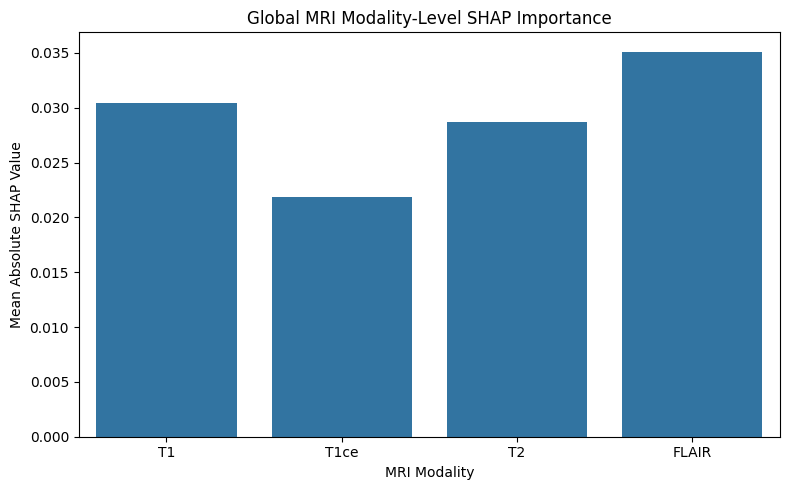

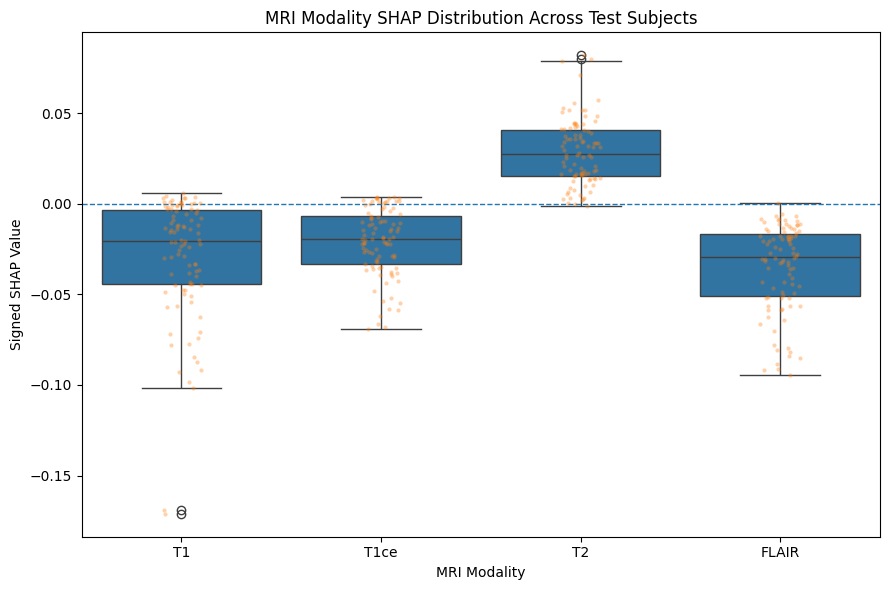

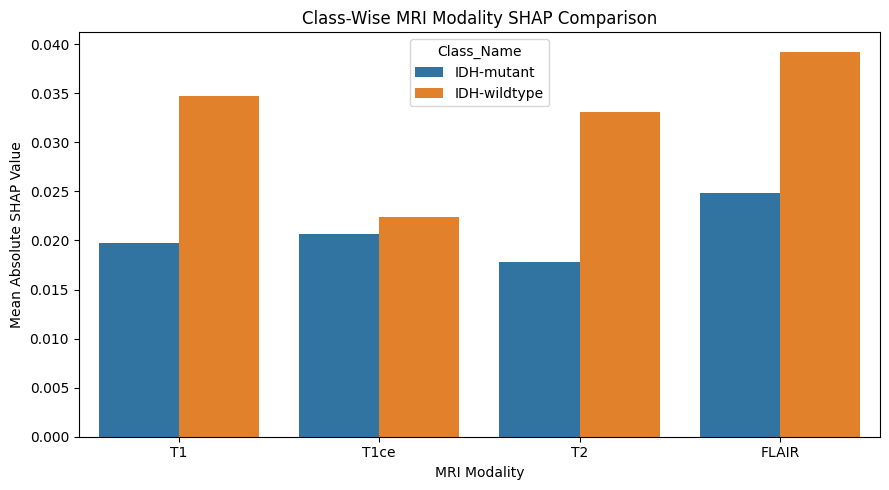


MRI SHAP publication visualizations completed.
Saved directory: /content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality


In [85]:
# ================================================================
# MRI MODALITY-LEVEL SHAP: PUBLICATION-QUALITY VISUALIZATIONS
# ================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SHAP_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/mri_modality"
)

SUBJECT_CSV = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv"
)

CLASSWISE_CSV = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_ClasswiseSummary.csv"
)

GLOBAL_CSV = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_GlobalSummary.csv"
)

# Load saved cohort results
mri_shap_df = pd.read_csv(SUBJECT_CSV)
mri_global_df = pd.read_csv(GLOBAL_CSV)
mri_classwise_df = pd.read_csv(CLASSWISE_CSV)

print("Subject-level shape:", mri_shap_df.shape)
print("Global summary shape:", mri_global_df.shape)
print("Class-wise summary shape:", mri_classwise_df.shape)

print("\nSubject-level columns:")
print(mri_shap_df.columns.tolist())

print("\nGlobal summary:")
display(mri_global_df)

print("\nClass-wise summary:")
display(mri_classwise_df)

# ------------------------------------------------
# 1. GLOBAL MODALITY IMPORTANCE
# ------------------------------------------------

plt.figure(figsize=(8, 5))

sns.barplot(
    data=mri_global_df,
    x="MRI_Modality",
    y="mean",
    order=["T1", "T1ce", "T2", "FLAIR"]
)

plt.title("Global MRI Modality-Level SHAP Importance")
plt.xlabel("MRI Modality")
plt.ylabel("Mean Absolute SHAP Value")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "MRI_SHAP_Global_Importance.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 2. SIGNED SHAP DISTRIBUTION ACROSS TEST SUBJECTS
# ------------------------------------------------

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=mri_shap_df,
    x="MRI_Modality",
    y="MRI_SHAP",
    order=["T1", "T1ce", "T2", "FLAIR"]
)

sns.stripplot(
    data=mri_shap_df,
    x="MRI_Modality",
    y="MRI_SHAP",
    order=["T1", "T1ce", "T2", "FLAIR"],
    alpha=0.35,
    size=3
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("MRI Modality SHAP Distribution Across Test Subjects")
plt.xlabel("MRI Modality")
plt.ylabel("Signed SHAP Value")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "MRI_SHAP_Cohort_Distribution.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------
# 3. CLASS-WISE MODALITY CONTRIBUTION
# ------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=mri_classwise_df,
    x="MRI_Modality",
    y="mean",
    hue="Class_Name",
    order=["T1", "T1ce", "T2", "FLAIR"]
)

plt.title("Class-Wise MRI Modality SHAP Comparison")
plt.xlabel("MRI Modality")
plt.ylabel("Mean Absolute SHAP Value")
plt.tight_layout()

plt.savefig(
    os.path.join(SHAP_DIR, "MRI_SHAP_Classwise_Comparison.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nMRI SHAP publication visualizations completed.")
print("Saved directory:", SHAP_DIR)

### Statistical Analysis of MRI Modality-Level SHAP Attributions

This analysis evaluates the distribution of MRI modality-level SHAP attribution magnitudes across the held-out test cohort.

For each MRI modality, the mean absolute SHAP value and its bootstrap 95% confidence interval will be estimated. Class-wise attribution magnitudes will be compared between IDH-mutant and IDH-wildtype subjects using the Mann–Whitney U test. Benjamini–Hochberg correction will be applied to account for multiple comparisons.

The analysis is descriptive and exploratory. Statistical differences in attribution magnitude will not be interpreted as evidence of biological causality or clinical significance.

In [86]:
# ================================================================
# MRI SHAP STATISTICAL ANALYSIS
# Bootstrap 95% CI + Mann-Whitney U + BH correction
# ================================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

SHAP_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/mri_modality"
)

INPUT_CSV = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv"
)

OUTPUT_GLOBAL = os.path.join(
    SHAP_DIR,
    "MRI_SHAP_Bootstrap_Global_Statistics.csv"
)

OUTPUT_CLASSWISE = os.path.join(
    SHAP_DIR,
    "MRI_SHAP_Classwise_Statistical_Comparison.csv"
)

df = pd.read_csv(INPUT_CSV)

# Verify required columns
required = [
    "Subject_ID",
    "True_Label",
    "MRI_Modality",
    "Absolute_MRI_SHAP"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["True_Label"] = df["True_Label"].astype(int)

# Confirm class distribution
print("Class distribution:")
print(df[["Subject_ID", "True_Label"]].drop_duplicates()["True_Label"].value_counts())

# ------------------------------------------------
# Bootstrap confidence interval for mean
# ------------------------------------------------

def bootstrap_mean_ci(values, n_boot=5000, seed=42):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    rng = np.random.default_rng(seed)

    boot_means = np.empty(n_boot)

    for i in range(n_boot):
        sample = rng.choice(
            values,
            size=len(values),
            replace=True
        )
        boot_means[i] = np.mean(sample)

    return (
        np.mean(values),
        np.percentile(boot_means, 2.5),
        np.percentile(boot_means, 97.5)
    )

# ------------------------------------------------
# GLOBAL STATISTICS
# ------------------------------------------------

global_rows = []

modalities = ["T1", "T1ce", "T2", "FLAIR"]

for modality in modalities:

    values = df.loc[
        df["MRI_Modality"] == modality,
        "Absolute_MRI_SHAP"
    ].values

    mean_val, ci_low, ci_high = bootstrap_mean_ci(values)

    global_rows.append({
        "MRI_Modality": modality,
        "N": len(values),
        "Mean_Absolute_SHAP": mean_val,
        "Bootstrap_95CI_Lower": ci_low,
        "Bootstrap_95CI_Upper": ci_high,
        "Median_Absolute_SHAP": np.median(values),
        "SD_Absolute_SHAP": np.std(values, ddof=1)
    })

global_stats = pd.DataFrame(global_rows)

global_stats.to_csv(OUTPUT_GLOBAL, index=False)

print("\nGLOBAL MRI SHAP STATISTICS")
display(global_stats)

# ------------------------------------------------
# CLASS-WISE STATISTICAL COMPARISON
# Label 0 = IDH-wildtype
# Label 1 = IDH-mutant
# ------------------------------------------------

comparison_rows = []

for modality in modalities:

    wt = df.loc[
        (df["MRI_Modality"] == modality) &
        (df["True_Label"] == 0),
        "Absolute_MRI_SHAP"
    ].values

    mutant = df.loc[
        (df["MRI_Modality"] == modality) &
        (df["True_Label"] == 1),
        "Absolute_MRI_SHAP"
    ].values

    statistic, p_value = mannwhitneyu(
        mutant,
        wt,
        alternative="two-sided"
    )

    comparison_rows.append({
        "MRI_Modality": modality,
        "N_IDH_Wildtype": len(wt),
        "N_IDH_Mutant": len(mutant),
        "Mean_Abs_SHAP_Wildtype": np.mean(wt),
        "Mean_Abs_SHAP_Mutant": np.mean(mutant),
        "Median_Abs_SHAP_Wildtype": np.median(wt),
        "Median_Abs_SHAP_Mutant": np.median(mutant),
        "Mann_Whitney_U": statistic,
        "P_Value": p_value
    })

class_stats = pd.DataFrame(comparison_rows)

# ------------------------------------------------
# BENJAMINI-HOCHBERG FDR CORRECTION
# ------------------------------------------------

p_values = class_stats["P_Value"].values

n_tests = len(p_values)

sorted_indices = np.argsort(p_values)
sorted_p = p_values[sorted_indices]

adjusted_sorted = sorted_p * n_tests / (
    np.arange(1, n_tests + 1)
)

# Enforce monotonicity
adjusted_sorted = np.minimum.accumulate(
    adjusted_sorted[::-1]
)[::-1]

adjusted_sorted = np.clip(adjusted_sorted, 0, 1)

adjusted_p = np.empty(n_tests)
adjusted_p[sorted_indices] = adjusted_sorted

class_stats["BH_Adjusted_P_Value"] = adjusted_p
class_stats["Significant_FDR_0.05"] = (
    class_stats["BH_Adjusted_P_Value"] < 0.05
)

class_stats.to_csv(OUTPUT_CLASSWISE, index=False)

print("\nCLASS-WISE MRI SHAP STATISTICAL COMPARISON")
display(class_stats)

print("\nSaved:")
print(OUTPUT_GLOBAL)
print(OUTPUT_CLASSWISE)

print("\nMRI SHAP statistical analysis completed.")

Class distribution:
True_Label
0    67
1    27
Name: count, dtype: int64

GLOBAL MRI SHAP STATISTICS


,MRI_Modality,N,Mean_Absolute_SHAP,Bootstrap_95CI_Lower,Bootstrap_95CI_Upper,Median_Absolute_SHAP,SD_Absolute_SHAP
0,T1,94,0.030455,0.023817,0.037493,0.020362,0.033911
1,T1ce,94,0.021893,0.018334,0.025449,0.019617,0.017834
2,T2,94,0.028725,0.025022,0.032553,0.027446,0.018312
3,FLAIR,94,0.035115,0.030316,0.039955,0.029438,0.024057



CLASS-WISE MRI SHAP STATISTICAL COMPARISON


,MRI_Modality,N_IDH_Wildtype,N_IDH_Mutant,Mean_Abs_SHAP_Wildtype,Mean_Abs_SHAP_Mutant,Median_Abs_SHAP_Wildtype,Median_Abs_SHAP_Mutant,Mann_Whitney_U,P_Value,BH_Adjusted_P_Value,Significant_FDR_0.05
0,T1,67,27,0.034756,0.019782,0.022418,0.013041,699.0,0.086708,0.115611,False
1,T1ce,67,27,0.022409,0.020614,0.018726,0.019630,907.0,0.986666,0.986666,False
2,T2,67,27,0.033138,0.017774,0.033390,0.014996,448.0,0.000139,0.000555,True
3,FLAIR,67,27,0.039253,0.024846,0.031745,0.018149,585.0,0.007684,0.015369,True



Saved:
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_SHAP_Bootstrap_Global_Statistics.csv
/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_SHAP_Classwise_Statistical_Comparison.csv

MRI SHAP statistical analysis completed.


### MRI Modality SHAP Effect-Size Analysis

This analysis evaluates the magnitude of the difference in MRI modality attribution between IDH-wildtype and IDH-mutant subjects.

Cliff's delta and bootstrap confidence intervals are calculated in addition to the previously computed Mann–Whitney U tests and Benjamini–Hochberg adjusted p-values.

The analysis is exploratory and is performed on the held-out test cohort. Absolute SHAP values represent attribution magnitude, not attribution direction.

In [87]:
import pandas as pd
import numpy as np
from pathlib import Path

from scipy.stats import mannwhitneyu

# --------------------------------------------------
# PATHS
# --------------------------------------------------
SHAP_DIR = Path(
    "/content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality"
)

SUBJECT_CSV = SHAP_DIR / "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv"
CLASSWISE_CSV = SHAP_DIR / "MRI_SHAP_Classwise_Statistical_Comparison.csv"

OUTPUT_CSV = SHAP_DIR / "MRI_SHAP_EffectSize_Bootstrap_Analysis.csv"

# --------------------------------------------------
# LOAD DATA
# --------------------------------------------------
df = pd.read_csv(SUBJECT_CSV)
classwise = pd.read_csv(CLASSWISE_CSV)

print("Loaded subject-level SHAP data:", df.shape)
print("Columns:", df.columns.tolist())

# --------------------------------------------------
# EFFECT SIZE + BOOTSTRAP
# --------------------------------------------------
rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

results = []

modalities = ["T1", "T1ce", "T2", "FLAIR"]

for modality in modalities:

    modality_df = df[df["MRI_Modality"] == modality].copy()

    wildtype = modality_df.loc[
        modality_df["True_Label"] == 0,
        "Absolute_MRI_SHAP"
    ].dropna().to_numpy()

    mutant = modality_df.loc[
        modality_df["True_Label"] == 1,
        "Absolute_MRI_SHAP"
    ].dropna().to_numpy()

    if len(wildtype) == 0 or len(mutant) == 0:
        print(f"Skipping {modality}: missing class data")
        continue

    # Mean difference: WT minus mutant
    observed_difference = wildtype.mean() - mutant.mean()

    # Mann-Whitney U
    U, p_value = mannwhitneyu(
        wildtype,
        mutant,
        alternative="two-sided"
    )

    # Cliff's delta
    # Positive delta means WT values tend to be larger.
    # Negative delta means mutant values tend to be larger.
    cliffs_delta = (2 * U) / (len(wildtype) * len(mutant)) - 1

    # Bootstrap CI for mean difference
    bootstrap_differences = np.empty(N_BOOTSTRAP)

    for b in range(N_BOOTSTRAP):
        wt_sample = rng.choice(
            wildtype,
            size=len(wildtype),
            replace=True
        )

        mutant_sample = rng.choice(
            mutant,
            size=len(mutant),
            replace=True
        )

        bootstrap_differences[b] = (
            wt_sample.mean() - mutant_sample.mean()
        )

    ci_lower, ci_upper = np.percentile(
        bootstrap_differences,
        [2.5, 97.5]
    )

    results.append({
        "MRI_Modality": modality,
        "N_Wildtype": len(wildtype),
        "N_Mutant": len(mutant),
        "Mean_Abs_SHAP_Wildtype": wildtype.mean(),
        "Mean_Abs_SHAP_Mutant": mutant.mean(),
        "Mean_Difference_WT_minus_Mutant": observed_difference,
        "Bootstrap_95CI_Lower": ci_lower,
        "Bootstrap_95CI_Upper": ci_upper,
        "Cliffs_Delta": cliffs_delta,
        "Mann_Whitney_U": U,
        "P_Value": p_value
    })

# --------------------------------------------------
# SAVE
# --------------------------------------------------
effect_df = pd.DataFrame(results)

effect_df.to_csv(OUTPUT_CSV, index=False)

print("\n" + "=" * 70)
print("MRI SHAP EFFECT-SIZE ANALYSIS COMPLETED")
print("=" * 70)

display(effect_df.round(6))

print("\nSaved:", OUTPUT_CSV)

Loaded subject-level SHAP data: (376, 6)
Columns: ['Subject_ID', 'True_Label', 'Class_Name', 'MRI_Modality', 'MRI_SHAP', 'Absolute_MRI_SHAP']

MRI SHAP EFFECT-SIZE ANALYSIS COMPLETED


,MRI_Modality,N_Wildtype,N_Mutant,Mean_Abs_SHAP_Wildtype,Mean_Abs_SHAP_Mutant,Mean_Difference_WT_minus_Mutant,Bootstrap_95CI_Lower,Bootstrap_95CI_Upper,Cliffs_Delta,Mann_Whitney_U,P_Value
0,T1,67,27,0.034756,0.019782,0.014973,0.003071,0.026931,0.227197,1110.0,0.086708
1,T1ce,67,27,0.022409,0.020614,0.001794,-0.005345,0.008556,-0.002764,902.0,0.986666
2,T2,67,27,0.033138,0.017774,0.015364,0.008547,0.022101,0.504699,1361.0,0.000139
3,FLAIR,67,27,0.039253,0.024846,0.014407,0.005227,0.023156,0.353234,1224.0,0.007684



Saved: /content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_SHAP_EffectSize_Bootstrap_Analysis.csv


### MRI Integrated Gradients: Cohort Pilot

This pilot evaluates MRI input-level Integrated Gradients for five subjects from the held-out test cohort.

The target is the WT-versus-mutant logit margin, defined as logit(WT) − logit(mutant). The clinical input is held fixed while MRI attribution is calculated.

A zero MRI baseline is used as a mathematical reference. It is not interpreted as a healthy or clinically realistic MRI. The pilot assesses attribution completeness, numerical stability, and computational feasibility before cohort-level execution.

In [88]:
import torch
import numpy as np
import pandas as pd
import time

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------
model.eval()

DEVICE = next(model.parameters()).device
N_PILOT = 5
IG_STEPS = 16

pilot_results = []

print("Device:", DEVICE)
print("Pilot subjects:", N_PILOT)
print("IG integration steps:", IG_STEPS)

# --------------------------------------------------
# MRI INTEGRATED GRADIENTS FUNCTION
# --------------------------------------------------
def calculate_mri_ig(mri, clinical, steps=16):

    mri = mri.to(DEVICE).float()
    clinical = clinical.to(DEVICE).float()

    if mri.ndim == 4:
        mri = mri.unsqueeze(0)

    if clinical.ndim == 1:
        clinical = clinical.unsqueeze(0)

    baseline = torch.zeros_like(mri)

    total_gradients = torch.zeros_like(mri)

    # Trapezoidal integration
    alphas = torch.linspace(
        0.0, 1.0, steps, device=DEVICE
    )

    for i, alpha in enumerate(alphas):

        interpolated = (
            baseline + alpha * (mri - baseline)
        ).detach().requires_grad_(True)

        logits = model(interpolated, clinical)

        # Target: WT logit minus mutant logit
        target_margin = logits[:, 0] - logits[:, 1]

        gradients = torch.autograd.grad(
            outputs=target_margin.sum(),
            inputs=interpolated
        )[0]

        weight = 0.5 if i in [0, steps - 1] else 1.0

        total_gradients += weight * gradients

    average_gradients = total_gradients / (steps - 1)

    attributions = (mri - baseline) * average_gradients

    # Completeness diagnostics
    with torch.no_grad():

        full_logits = model(mri, clinical)
        baseline_logits = model(baseline, clinical)

        full_margin = (
            full_logits[:, 0] - full_logits[:, 1]
        ).item()

        baseline_margin = (
            baseline_logits[:, 0] - baseline_logits[:, 1]
        ).item()

    attribution_sum = attributions.sum().item()

    target_difference = full_margin - baseline_margin

    completeness_error = (
        target_difference - attribution_sum
    )

    return {
        "attributions": attributions.detach(),
        "full_margin": full_margin,
        "baseline_margin": baseline_margin,
        "target_difference": target_difference,
        "attribution_sum": attribution_sum,
        "completeness_error": completeness_error,
        "absolute_attribution_sum": attributions.abs().sum().item()
    }


# --------------------------------------------------
# PILOT
# --------------------------------------------------
start_time = time.time()

for idx in range(min(N_PILOT, len(test_dataset))):

    sample = test_dataset[idx]

    mri = sample["mri"]
    clinical = sample["clinical"]
    label = int(sample["label"])
    subject_id = sample["subject_id"]

    result = calculate_mri_ig(
        mri=mri,
        clinical=clinical,
        steps=IG_STEPS
    )

    pilot_results.append({
        "Subject_ID": subject_id,
        "True_Label": label,
        "Full_Margin": result["full_margin"],
        "Baseline_Margin": result["baseline_margin"],
        "Target_Difference": result["target_difference"],
        "IG_Attribution_Sum": result["attribution_sum"],
        "Completeness_Error": result["completeness_error"],
        "Absolute_Attribution_Sum": result["absolute_attribution_sum"]
    })

    print(
        f"{idx+1}/{N_PILOT} | {subject_id} | "
        f"Label={label} | "
        f"Completeness error={result['completeness_error']:.6f}"
    )

pilot_df = pd.DataFrame(pilot_results)

elapsed = time.time() - start_time

print("\n" + "=" * 70)
print("MRI IG PILOT COMPLETED")
print("=" * 70)

display(pilot_df.round(6))

print(f"\nElapsed time: {elapsed:.2f} seconds")
print(f"Average time per subject: {elapsed / len(pilot_df):.2f} seconds")

Device: cuda:0
Pilot subjects: 5
IG integration steps: 16
1/5 | BT1131 | Label=0 | Completeness error=-0.001465
2/5 | BT1103 | Label=0 | Completeness error=-0.000485
3/5 | BT0643 | Label=1 | Completeness error=-0.000401
4/5 | BT0364 | Label=0 | Completeness error=-0.002090
5/5 | BT1100 | Label=0 | Completeness error=-0.000462

MRI IG PILOT COMPLETED


,Subject_ID,True_Label,Full_Margin,Baseline_Margin,Target_Difference,IG_Attribution_Sum,Completeness_Error,Absolute_Attribution_Sum
0,BT1131,0,3.730636,3.724518,0.006118,0.007582,-0.001465,0.218822
1,BT1103,0,3.244077,3.292768,-0.048691,-0.048206,-0.000485,0.286198
2,BT0643,1,-1.788235,-1.764183,-0.024051,-0.023650,-0.000401,0.126106
3,BT0364,0,2.662612,2.827975,-0.165362,-0.163273,-0.002090,0.407887
4,BT1100,0,3.295079,3.289965,0.005115,0.005576,-0.000462,0.194116



Elapsed time: 4.57 seconds
Average time per subject: 0.91 seconds


### Cohort-Level MRI Integrated Gradients Analysis

This analysis computes MRI Integrated Gradients for the 94 subjects in the held-out test cohort using 64 integration steps. The target is the WT-minus-mutant logit margin, with clinical features held fixed.

The zero MRI baseline is used as a mathematical reference. For each subject, the analysis records attribution magnitude, signed attribution, channel-wise attribution summaries, and completeness diagnostics.

To avoid excessive storage, full 3D attribution tensors are not retained for every subject. Instead, compact per-subject and class-wise summary tables are generated. These summaries describe model attribution behavior and do not independently establish spatial localization or clinical validity.

In [89]:
import os
import gc
import time
import numpy as np
import pandas as pd
import torch

# --------------------------------------------------
# CONFIGURATION
# --------------------------------------------------
IG_STEPS_COHORT = 64

IG_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients/mri_cohort"
)

os.makedirs(IG_DIR, exist_ok=True)

CHANNEL_NAMES = ["T1", "T1ce", "T2", "FLAIR"]

cohort_rows = []

start_time = time.time()

print("=" * 70)
print("COHORT MRI INTEGRATED GRADIENTS")
print("=" * 70)
print("Subjects:", len(test_dataset))
print("Integration steps:", IG_STEPS_COHORT)
print("Device:", DEVICE)

# --------------------------------------------------
# PROCESS ALL TEST SUBJECTS
# --------------------------------------------------
for idx in range(len(test_dataset)):

    sample = test_dataset[idx]

    mri = sample["mri"]
    clinical = sample["clinical"]
    label = int(sample["label"])
    subject_id = sample["subject_id"]

    result = calculate_mri_ig(
        mri=mri,
        clinical=clinical,
        steps=IG_STEPS_COHORT
    )

    attr = result["attributions"].detach().cpu()

    # Remove batch dimension: (4, 128, 128, 96)
    if attr.ndim == 5:
        attr = attr.squeeze(0)

    row = {
        "Subject_ID": subject_id,
        "True_Label": label,
        "Class_Name": (
            "IDH-wildtype" if label == 0 else "IDH-mutant"
        ),
        "Full_Margin": result["full_margin"],
        "Baseline_Margin": result["baseline_margin"],
        "Target_Difference": result["target_difference"],
        "IG_Attribution_Sum": result["attribution_sum"],
        "Completeness_Error": result["completeness_error"],
        "Absolute_Attribution_Sum": attr.abs().sum().item(),
        "Mean_Absolute_Attribution": attr.abs().mean().item(),
        "Maximum_Absolute_Attribution": attr.abs().max().item()
    }

    # Channel-wise summaries
    for ch_idx, ch_name in enumerate(CHANNEL_NAMES):

        channel_attr = attr[ch_idx]

        row[f"{ch_name}_Signed_Sum"] = (
            channel_attr.sum().item()
        )

        row[f"{ch_name}_Absolute_Sum"] = (
            channel_attr.abs().sum().item()
        )

        row[f"{ch_name}_Mean_Absolute"] = (
            channel_attr.abs().mean().item()
        )

    cohort_rows.append(row)

    del result, attr
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    if (idx + 1) % 10 == 0 or idx == 0:
        elapsed = time.time() - start_time

        print(
            f"Processed {idx+1}/{len(test_dataset)} | "
            f"Subject: {subject_id} | "
            f"Elapsed: {elapsed:.1f}s"
        )

# --------------------------------------------------
# SAVE SUBJECT-LEVEL RESULTS
# --------------------------------------------------
cohort_ig_df = pd.DataFrame(cohort_rows)

SUBJECT_OUTPUT = os.path.join(
    IG_DIR,
    "MRI_IG_SubjectLevel_94Subjects_64steps.csv"
)

cohort_ig_df.to_csv(SUBJECT_OUTPUT, index=False)

# --------------------------------------------------
# GLOBAL SUMMARY
# --------------------------------------------------
global_summary = cohort_ig_df[
    [
        "Absolute_Attribution_Sum",
        "Mean_Absolute_Attribution",
        "Maximum_Absolute_Attribution",
        "Completeness_Error"
    ]
].describe()

GLOBAL_OUTPUT = os.path.join(
    IG_DIR,
    "MRI_IG_Global_Summary.csv"
)

global_summary.to_csv(GLOBAL_OUTPUT)

# --------------------------------------------------
# CLASS-WISE SUMMARY
# --------------------------------------------------
channel_abs_columns = [
    f"{ch}_Absolute_Sum" for ch in CHANNEL_NAMES
]

channel_mean_columns = [
    f"{ch}_Mean_Absolute" for ch in CHANNEL_NAMES
]

classwise_summary = cohort_ig_df.groupby(
    "Class_Name"
)[
    channel_abs_columns + channel_mean_columns
].agg(["mean", "std", "median", "count"])

CLASSWISE_OUTPUT = os.path.join(
    IG_DIR,
    "MRI_IG_Classwise_Channel_Summary.csv"
)

classwise_summary.to_csv(CLASSWISE_OUTPUT)

# --------------------------------------------------
# COMPLETENESS DIAGNOSTICS
# --------------------------------------------------
completeness_summary = cohort_ig_df[
    "Completeness_Error"
].describe()

print("\n" + "=" * 70)
print("COHORT MRI IG COMPLETED")
print("=" * 70)

print("Subjects processed:", len(cohort_ig_df))

print("\nCompleteness error summary:")
display(completeness_summary.to_frame())

print("\nGlobal summary:")
display(global_summary.round(8))

print("\nClass-wise channel summary:")
display(classwise_summary.round(8))

print("\nSaved files:")
print(SUBJECT_OUTPUT)
print(GLOBAL_OUTPUT)
print(CLASSWISE_OUTPUT)

print("\nTotal elapsed time:", round(time.time() - start_time, 2), "seconds")

COHORT MRI INTEGRATED GRADIENTS
Subjects: 94
Integration steps: 64
Device: cuda:0
Processed 1/94 | Subject: BT1131 | Elapsed: 3.8s
Processed 10/94 | Subject: BT0969 | Elapsed: 37.0s
Processed 20/94 | Subject: BT0120 | Elapsed: 74.2s
Processed 30/94 | Subject: BT0619 | Elapsed: 111.3s
Processed 40/94 | Subject: BT1303 | Elapsed: 147.9s
Processed 50/94 | Subject: BT0315 | Elapsed: 184.8s
Processed 60/94 | Subject: BT1209 | Elapsed: 221.5s
Processed 70/94 | Subject: BT0219 | Elapsed: 258.1s
Processed 80/94 | Subject: BT0616 | Elapsed: 294.8s
Processed 90/94 | Subject: BT0907 | Elapsed: 331.4s

COHORT MRI IG COMPLETED
Subjects processed: 94

Completeness error summary:


,Completeness_Error
count,94.000000
mean,-0.000095
std,0.000543
min,-0.002326
25%,-0.000264
50%,-0.000060
75%,0.000151
max,0.001196



Global summary:


,Absolute_Attribution_Sum,Mean_Absolute_Attribution,Maximum_Absolute_Attribution,Completeness_Error
count,94.000000,9.400000e+01,9.400000e+01,94.000000
mean,0.240834,4.000000e-08,1.500000e-06,-0.000095
std,0.095793,2.000000e-08,6.800000e-07,0.000543
min,0.126039,2.000000e-08,4.400000e-07,-0.002326
25%,0.190347,3.000000e-08,1.040000e-06,-0.000264
50%,0.217242,3.000000e-08,1.450000e-06,-0.000060
75%,0.278042,4.000000e-08,1.720000e-06,0.000151
max,0.630628,1.000000e-07,3.980000e-06,0.001196



Class-wise channel summary:


T1_Absolute_Sum                           T1ce_Absolute_Sum  \
                        mean       std    median count              mean   
Class_Name                                                                 
IDH-mutant          0.059550  0.028157  0.046410    27          0.058465   
IDH-wildtype        0.083786  0.042286  0.069074    67          0.071392   

                                       T2_Absolute_Sum            ...  \
                   std    median count            mean       std  ...   
Class_Name                                                        ...   
IDH-mutant    0.023902  0.051883    27        0.033778  0.013816  ...   
IDH-wildtype  0.027972  0.062582    67        0.048555  0.016785  ...   

             T1ce_Mean_Absolute       T2_Mean_Absolute                \
                         median count             mean           std   
Class_Name                                                             
IDH-mutant         3.000000e-08    27     2.000000e-08  1.000000e-08   
IDH-wildtype       4.000000e-08    67     3.000000e-08  1.000000e-08   

                                 FLAIR_Mean_Absolute                \
                    median count                mean           std   
Class_Name                                                           
IDH-mutant    2.000000e-08    27        3.000000e-08  1.000000e-08   
IDH-wildtype  3.000000e-08    67        4.000000e-08  1.000000e-08   

                                  
                    median count  
Class_Name                        
IDH-mutant    2.000000e-08    27  
IDH-wildtype  3.000000e-08    67  

[2 rows x 32 columns]


Saved files:
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/mri_cohort/MRI_IG_SubjectLevel_94Subjects_64steps.csv
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/mri_cohort/MRI_IG_Global_Summary.csv
/content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/mri_cohort/MRI_IG_Classwise_Channel_Summary.csv

Total elapsed time: 346.16 seconds


In [90]:

# STEP 42D: Audit the saved paired perturbation results
# Read-only verification. Does NOT rerun the model or modify existing files.

import os
import numpy as np
import pandas as pd

BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test"
)

PERTURBATION_FILE = os.path.join(
    BASE,
    "gradcam_vs_gradcampp_perturbation_sensitivity.csv"
)

FINAL_SUMMARY_FILE = os.path.join(
    BASE,
    "final_perturbation_summary.csv"
)

if not os.path.isfile(PERTURBATION_FILE):
    raise FileNotFoundError(PERTURBATION_FILE)

perturb = pd.read_csv(PERTURBATION_FILE)

required_columns = [
    "Subject_ID",
    "Method",
    "High_Region_Probability_Drop",
    "Low_Region_Probability_Drop",
    "High_minus_Low_Drop",
    "High_Drop_Larger",
]

missing_columns = [
    col for col in required_columns
    if col not in perturb.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

print("=" * 70)
print("SAVED PERTURBATION CSV AUDIT")
print("=" * 70)

print("\nFile:", PERTURBATION_FILE)
print("Total rows:", len(perturb))
print("Unique subjects:", perturb["Subject_ID"].nunique())
print("\nRows per method:")
print(perturb.groupby("Method")["Subject_ID"].nunique())

# Recompute all summary values directly from the CSV.
summary = perturb.groupby("Method").agg(
    Patients=("Subject_ID", "nunique"),
    Rows=("Subject_ID", "count"),
    Mean_High_Region_Drop=(
        "High_Region_Probability_Drop", "mean"
    ),
    Mean_Low_Region_Drop=(
        "Low_Region_Probability_Drop", "mean"
    ),
    Mean_High_Minus_Low=(
        "High_minus_Low_Drop", "mean"
    ),
    High_Drop_Larger_Count=(
        "High_Drop_Larger", "sum"
    ),
)

summary["High_Drop_Larger_Fraction"] = (
    summary["High_Drop_Larger_Count"]
    / summary["Patients"]
)

print("\n" + "=" * 70)
print("RECOMPUTED SUMMARY FROM SAVED CSV")
print("=" * 70)

print(summary.to_string(float_format=lambda x: f"{x:.8f}"))

# Check row coverage and duplicate subject-method pairs.
print("\n" + "=" * 70)
print("STRUCTURAL CHECKS")
print("=" * 70)

expected_methods = {"GradCAM", "GradCAMPP_Approx"}
observed_methods = set(perturb["Method"].unique())

print("Methods correct:", observed_methods == expected_methods)
print("Expected rows (94 subjects x 2 methods):", 188)
print("Actual rows:", len(perturb))

duplicate_pairs = perturb.duplicated(
    subset=["Subject_ID", "Method"]
).sum()

print("Duplicate subject-method rows:", duplicate_pairs)

print("\nSubjects per method:")
print(
    perturb.groupby("Method")["Subject_ID"]
    .nunique()
    .to_string()
)

# Compare with the final summary file if it exists.
if os.path.isfile(FINAL_SUMMARY_FILE):
    saved_summary = pd.read_csv(
        FINAL_SUMMARY_FILE,
        index_col=0
    )

    print("\n" + "=" * 70)
    print("COMPARISON WITH FINAL SUMMARY CSV")
    print("=" * 70)

    print("\nSaved final summary:")
    print(saved_summary.to_string())

    print("\nNote: Differences may indicate that the final summary CSV")
    print("was generated from a different version of the perturbation file.")
else:
    print("\nFinal summary CSV not found:", FINAL_SUMMARY_FILE)

print("\nAUDIT CELL COMPLETED — no model inference performed.")


SAVED PERTURBATION CSV AUDIT

File: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/gradcam_vs_gradcampp_perturbation_sensitivity.csv
Total rows: 188
Unique subjects: 94

Rows per method:
Method
GradCAM             94
GradCAMPP_Approx    94
Name: Subject_ID, dtype: int64

RECOMPUTED SUMMARY FROM SAVED CSV
                  Patients  Rows  Mean_High_Region_Drop  Mean_Low_Region_Drop  Mean_High_Minus_Low  High_Drop_Larger_Count  High_Drop_Larger_Fraction
Method                                                                                                                                               
GradCAM                 94    94            -0.00003854           -0.00006809           0.00002955                      26                 0.27659574
GradCAMPP_Approx        94    94            -0.00004982            0.00000009          -0.00004991                       6                 0.06382979

STRUCTURAL CHECKS
Methods correct: True
Expected rows (94 subjects x 2 me

In [91]:

# STEP 42E: Paired statistical analysis of perturbation sensitivity
# Uses the verified CSV. Does not rerun model inference.

import os
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

CSV_PATH = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/gradcam_test/"
    "gradcam_vs_gradcampp_perturbation_sensitivity.csv"
)

df = pd.read_csv(CSV_PATH)

rng = np.random.default_rng(42)
N_BOOTSTRAP = 10000

print("=" * 75)
print("PAIRED PERTURBATION STATISTICAL ANALYSIS")
print("=" * 75)

results = []

for method in df["Method"].unique():
    sub = df[df["Method"] == method].copy()

    # Positive value means high-region drop exceeds low-region drop.
    differences = sub["High_minus_Low_Drop"].dropna().to_numpy()

    if len(differences) == 0:
        continue

    # Wilcoxon signed-rank test against zero.
    if np.allclose(differences, 0):
        statistic, p_value = 0.0, 1.0
    else:
        statistic, p_value = wilcoxon(
            differences,
            alternative="two-sided",
            zero_method="wilcox"
        )

    # Bootstrap confidence interval for the mean paired difference.
    bootstrap_means = np.empty(N_BOOTSTRAP)

    for i in range(N_BOOTSTRAP):
        sample = rng.choice(
            differences,
            size=len(differences),
            replace=True
        )
        bootstrap_means[i] = np.mean(sample)

    ci_low, ci_high = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    results.append({
        "Method": method,
        "N": len(differences),
        "Mean_HighMinusLow": np.mean(differences),
        "Median_HighMinusLow": np.median(differences),
        "Bootstrap_CI_Lower": ci_low,
        "Bootstrap_CI_Upper": ci_high,
        "Fraction_Positive": np.mean(differences > 0),
        "Wilcoxon_p": p_value,
    })

results_df = pd.DataFrame(results)

# Holm correction for the two method-specific tests.
p_values = results_df["Wilcoxon_p"].to_numpy()
order = np.argsort(p_values)
adjusted = np.empty(len(p_values))
running_max = 0.0
m = len(p_values)

for rank, idx in enumerate(order):
    value = min(1.0, (m - rank) * p_values[idx])
    running_max = max(running_max, value)
    adjusted[idx] = running_max

results_df["Holm_Adjusted_p"] = adjusted

print("\nMETHOD-WISE RESULTS")
print(results_df.to_string(index=False, float_format=lambda x: f"{x:.8g}"))

# Paired comparison of the high-minus-low effect between methods.
pivot = df.pivot(
    index="Subject_ID",
    columns="Method",
    values="High_minus_Low_Drop"
).dropna()

if {"GradCAM", "GradCAMPP_Approx"}.issubset(pivot.columns):
    paired_method_difference = (
        pivot["GradCAM"] - pivot["GradCAMPP_Approx"]
    )

    if np.allclose(paired_method_difference, 0):
        method_stat, method_p = 0.0, 1.0
    else:
        method_stat, method_p = wilcoxon(
            paired_method_difference,
            alternative="two-sided"
        )

    print("\nPAIRED METHOD COMPARISON")
    print("Subjects:", len(paired_method_difference))
    print(
        "Mean GradCAM - GradCAM++ difference:",
        f"{paired_method_difference.mean():.8g}"
    )
    print(
        "Median GradCAM - GradCAM++ difference:",
        f"{paired_method_difference.median():.8g}"
    )
    print("Wilcoxon p-value:", f"{method_p:.8g}")

print("\nAnalysis completed.")
print("Interpretation must consider the tiny probability-drop magnitudes.")


PAIRED PERTURBATION STATISTICAL ANALYSIS

METHOD-WISE RESULTS
          Method  N  Mean_HighMinusLow  Median_HighMinusLow  Bootstrap_CI_Lower  Bootstrap_CI_Upper  Fraction_Positive    Wilcoxon_p  Holm_Adjusted_p
         GradCAM 94      2.9546149e-05                    0      -1.2598377e-05       7.3373524e-05         0.27659574    0.76063013       0.76063013
GradCAMPP_Approx 94     -4.9907476e-05       -4.7713518e-05      -5.8595884e-05      -4.0987071e-05        0.063829787 2.2853708e-12    4.5707416e-12

PAIRED METHOD COMPARISON
Subjects: 94
Mean GradCAM - GradCAM++ difference: 7.9453626e-05
Median GradCAM - GradCAM++ difference: 3.7372112e-05
Wilcoxon p-value: 3.1759786e-10

Analysis completed.
Interpretation must consider the tiny probability-drop magnitudes.


In [93]:

# STEP 44: Audit existing cohort-level IG and SHAP output files
# Read-only audit. Does not run model inference or regenerate explanations.

import os
import pandas as pd

XAI_BASE = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability"
)

PREDICTIONS_FILE = os.path.join(
    XAI_BASE,
    "gradcam_test",
    "gradcam_test_predictions.csv"
)

if not os.path.isfile(PREDICTIONS_FILE):
    raise FileNotFoundError(
        f"Prediction reference file not found: {PREDICTIONS_FILE}"
    )

pred = pd.read_csv(PREDICTIONS_FILE)

subject_col_pred = next(
    (c for c in pred.columns if c.lower() in
     ["subject_id", "subject", "patient_id", "patient"]),
    None
)

if subject_col_pred is None:
    raise ValueError(
        "Could not identify the subject ID column in predictions CSV."
    )

expected_ids = set(
    pred[subject_col_pred].astype(str).str.strip().unique()
)

# Filename keywords for expected explainability outputs.
keywords = {
    "MRI_IG": ["mri_ig_subjectlevel", "mri_ig_subject_level"],
    "Clinical_SHAP": ["clinical_shap_subjectlevel", "clinical_shap"],
    "MRI_SHAP": ["mri_modality_shap", "mri_shap_subjectlevel",
                 "mri_shap"],
    "Clinical_IG": ["clinical_ig_subjectlevel", "clinical_ig"],
}

# Find CSVs recursively.
all_csvs = []

for root, dirs, files in os.walk(XAI_BASE):
    for file in files:
        if file.lower().endswith(".csv"):
            all_csvs.append(os.path.join(root, file))

print("=" * 75)
print("STEP 44: FINAL IG AND SHAP FILE AUDIT")
print("=" * 75)

print("\nExpected held-out test subjects:", len(expected_ids))

audit_results = []

for category, terms in keywords.items():

    matches = [
        path for path in all_csvs
        if any(term.lower() in os.path.basename(path).lower()
               for term in terms)
    ]

    print("\n" + "-" * 75)
    print(category)
    print("-" * 75)

    if not matches:
        print("No matching CSV found.")
        audit_results.append({
            "Category": category,
            "File": "NOT FOUND",
            "Rows": None,
            "Unique_Subjects": None,
            "Missing_Subjects": None,
            "Unexpected_Subjects": None,
            "Status": "NOT FOUND"
        })
        continue

    for path in matches:
        df = pd.read_csv(path)

        subject_col = next(
            (c for c in df.columns if c.lower() in
             ["subject_id", "subject", "patient_id", "patient"]),
            None
        )

        if subject_col is None:
            unique_subjects = None
            missing_subjects = None
            unexpected_subjects = None
            status = "SUBJECT COLUMN NOT IDENTIFIED"
        else:
            observed_ids = set(
                df[subject_col].astype(str).str.strip().unique()
            )

            unique_subjects = len(observed_ids)
            missing_subjects = len(expected_ids - observed_ids)
            unexpected_subjects = len(observed_ids - expected_ids)

            if missing_subjects == 0 and unexpected_subjects == 0:
                status = "SUBJECT COVERAGE PASS"
            else:
                status = "SUBJECT COVERAGE WARNING"

        print("\nFile:", os.path.basename(path))
        print("Full path:", path)
        print("Rows:", len(df))
        print("Subject column:", subject_col)
        print("Unique subjects:", unique_subjects)
        print("Missing subjects:", missing_subjects)
        print("Unexpected subjects:", unexpected_subjects)
        print("Status:", status)

        audit_results.append({
            "Category": category,
            "File": os.path.basename(path),
            "Rows": len(df),
            "Unique_Subjects": unique_subjects,
            "Missing_Subjects": missing_subjects,
            "Unexpected_Subjects": unexpected_subjects,
            "Status": status
        })

audit_df = pd.DataFrame(audit_results)

print("\n" + "=" * 75)
print("FINAL AUDIT TABLE")
print("=" * 75)

print(audit_df.to_string(index=False))

print("\nSTEP 44 AUDIT COMPLETED.")
print("No model inference or attribution generation was performed.")


STEP 44: FINAL IG AND SHAP FILE AUDIT

Expected held-out test subjects: 94

---------------------------------------------------------------------------
MRI_IG
---------------------------------------------------------------------------

File: MRI_IG_SubjectLevel_94Subjects_64steps.csv
Full path: /content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients/mri_cohort/MRI_IG_SubjectLevel_94Subjects_64steps.csv
Rows: 94
Subject column: Subject_ID
Unique subjects: 94
Missing subjects: 0
Unexpected subjects: 0
Status: SUBJECT COVERAGE PASS

---------------------------------------------------------------------------
Clinical_SHAP
---------------------------------------------------------------------------

File: Clinical_SHAP_SubjectLevel_94Subjects.csv
Full path: /content/drive/MyDrive/Glioma_Research/explainability/shap/clinical/Clinical_SHAP_SubjectLevel_94Subjects.csv
Rows: 94
Subject column: subject_id
Unique subjects: 94
Missing subjects: 0
Unexpected subjects: 0
Status: SU

In [94]:

# STEP 45: Inspect existing Clinical IG summary CSV files
# Read-only inspection. No model inference or attribution calculation.

import os
import pandas as pd

CLINICAL_IG_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/integrated_gradients/clinical"
)

files_to_inspect = [
    "Clinical_IG_attributions.csv",
    "Clinical_IG_completeness.csv",
]

for filename in files_to_inspect:
    path = os.path.join(CLINICAL_IG_DIR, filename)

    print("\n" + "=" * 75)
    print("FILE:", filename)
    print("=" * 75)

    if not os.path.isfile(path):
        print("FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFull contents:")
    print(df.to_string(index=False))

print("\nSTEP 45 COMPLETED — inspection only.")



FILE: Clinical_IG_attributions.csv
Shape: (2, 4)

Columns:
['Clinical Feature', 'Input Value', 'IG Attribution', 'Absolute Attribution']

Full contents:
Clinical Feature  Input Value  IG Attribution  Absolute Attribution
             Age     1.928345        2.655135              2.655135
             Sex     0.000000        0.000000              0.000000

FILE: Clinical_IG_completeness.csv
Shape: (5, 2)

Columns:
['Metric', 'Value']

Full contents:
                     Metric     Value
       Actual target margin  3.730636
     Baseline target margin  1.077004
   Target margin difference  2.653631
Clinical IG attribution sum  2.655135
    Completeness difference -0.001504

STEP 45 COMPLETED — inspection only.


# Step 46: Consolidation of Explainability Results

This step consolidates the saved explainability outputs from the held-out
test cohort into a single technical report.

The report includes:
- MRI Integrated Gradients
- Clinical Integrated Gradients
- MRI SHAP
- Clinical SHAP
- Grad-CAM and Grad-CAM++ comparison
- Grad-CAM perturbation analysis
- Statistical analysis and subject coverage

All results are collected from existing output files. No model training
or explainability computation is repeated in this step.

In [95]:
# ============================================================
# STEP 46: CONSOLIDATE SAVED EXPLAINABILITY OUTPUTS
# ============================================================

import os
import pandas as pd
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

REPORT_PATH = os.path.join(
    BASE_DIR,
    "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"
)

GRADCAM_REPORT_PATH = os.path.join(
    BASE_DIR,
    "gradcam_test",
    "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
)

# ------------------------------------------------------------
# 1. Define report sections
# ------------------------------------------------------------

sections = {
    "MRI INTEGRATED GRADIENTS": os.path.join(
        BASE_DIR, "integrated_gradients", "mri_cohort"
    ),

    "CLINICAL INTEGRATED GRADIENTS": os.path.join(
        BASE_DIR, "integrated_gradients", "clinical"
    ),

    "MRI SHAP": os.path.join(
        BASE_DIR, "shap", "mri"
    ),

    "CLINICAL SHAP": os.path.join(
        BASE_DIR, "shap", "clinical"
    ),

    "GRAD-CAM AND PERTURBATION ANALYSIS": os.path.join(
        BASE_DIR, "gradcam_test"
    )
}

# ------------------------------------------------------------
# 2. Start report
# ------------------------------------------------------------

report_lines = []

report_lines.append("=" * 90)
report_lines.append("COMPREHENSIVE BRAIN GLIOMA EXPLAINABILITY REPORT")
report_lines.append("=" * 90)

report_lines.append(
    f"Generated on: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}"
)

report_lines.append(
    "Research task: IDH-mutant vs IDH-wildtype glioma classification"
)

report_lines.append(
    "Dataset: Held-out test cohort; expected subject count = 94"
)

report_lines.append(
    "Note: This report consolidates saved results and does not rerun "
    "model inference or explainability calculations."
)

# ------------------------------------------------------------
# 3. Collect CSV files from each section
# ------------------------------------------------------------

for section_name, folder_path in sections.items():

    report_lines.append("\n\n" + "=" * 90)
    report_lines.append(section_name)
    report_lines.append("=" * 90)

    if not os.path.exists(folder_path):
        report_lines.append(
            f"WARNING: Directory not found: {folder_path}"
        )
        continue

    csv_files = sorted([
        f for f in os.listdir(folder_path)
        if f.lower().endswith(".csv")
    ])

    if len(csv_files) == 0:
        report_lines.append("No CSV files found.")
        continue

    for csv_file in csv_files:

        file_path = os.path.join(folder_path, csv_file)

        report_lines.append("\n" + "-" * 80)
        report_lines.append(f"FILE: {csv_file}")
        report_lines.append("-" * 80)

        try:
            df = pd.read_csv(file_path)

            report_lines.append(f"Shape: {df.shape}")
            report_lines.append(
                "Columns: " + ", ".join(map(str, df.columns))
            )

            report_lines.append("\nPreview:")

            report_lines.append(
                df.head(15).to_string(index=False)
            )

            if len(df) > 15:
                report_lines.append(
                    f"\nShowing first 15 of {len(df)} rows."
                )

        except Exception as e:

            report_lines.append(
                f"ERROR reading file: {str(e)}"
            )

# ------------------------------------------------------------
# 4. Include the existing Grad-CAM final report
# ------------------------------------------------------------

report_lines.append("\n\n" + "=" * 90)
report_lines.append("EXISTING GRAD-CAM FINAL REPORT")
report_lines.append("=" * 90)

if os.path.exists(GRADCAM_REPORT_PATH):

    with open(
        GRADCAM_REPORT_PATH,
        "r",
        encoding="utf-8"
    ) as f:

        gradcam_report = f.read()

    report_lines.append(gradcam_report)

else:

    report_lines.append(
        "Grad-CAM final report file was not found."
    )

# ------------------------------------------------------------
# 5. Save comprehensive report
# ------------------------------------------------------------

final_report = "\n".join(report_lines)

with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    f.write(final_report)

print("=" * 90)
print("STEP 46 COMPLETED")
print("=" * 90)

print("\nComprehensive report saved at:")
print(REPORT_PATH)

print("\nReport size:", len(final_report), "characters")

print("\nREPORT PREVIEW:")
print(final_report[:12000])

STEP 46 COMPLETED

Comprehensive report saved at:
/content/drive/MyDrive/Glioma_Research/explainability/FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt

Report size: 52960 characters

REPORT PREVIEW:
COMPREHENSIVE BRAIN GLIOMA EXPLAINABILITY REPORT
Generated on: 2026-11-10 14:05:34
Research task: IDH-mutant vs IDH-wildtype glioma classification
Dataset: Held-out test cohort; expected subject count = 94
Note: This report consolidates saved results and does not rerun model inference or explainability calculations.


MRI INTEGRATED GRADIENTS

--------------------------------------------------------------------------------
FILE: MRI_IG_Classwise_Channel_Summary.csv
--------------------------------------------------------------------------------
Shape: (4, 33)
Columns: Unnamed: 0, T1_Absolute_Sum, T1_Absolute_Sum.1, T1_Absolute_Sum.2, T1_Absolute_Sum.3, T1ce_Absolute_Sum, T1ce_Absolute_Sum.1, T1ce_Absolute_Sum.2, T1ce_Absolute_Sum.3, T2_Absolute_Sum, T2_Absolute_Sum.1, T2_Absolute_Sum.2, T2_A

# Step 47: Research-Oriented Explainability Findings

This step synthesizes the explainability results obtained from the held-out
test cohort of 94 subjects.

The synthesis covers:
1. MRI Integrated Gradients
2. MRI SHAP modality-level results
3. Clinical Integrated Gradients and SHAP
4. Grad-CAM and Grad-CAM++ approximation
5. Perturbation-based evaluation
6. Interpretation limitations

The results are exploratory explanations of model behavior and are not
evidence of causal relationships or clinical validity.

In [96]:
# ============================================================
# STEP 47: RESEARCH-ORIENTED EXPLAINABILITY FINDINGS SUMMARY
# ============================================================

import os
from datetime import datetime

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

OUTPUT_PATH = os.path.join(
    BASE_DIR,
    "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"
)

findings = f"""
COMPREHENSIVE EXPLAINABILITY FINDINGS
=====================================

Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}

Research objective:
IDH-mutant versus IDH-wildtype glioma classification using MRI and
clinical features.

Held-out test cohort:
94 subjects
67 IDH-wildtype
27 IDH-mutant


1. MRI INTEGRATED GRADIENTS
---------------------------

MRI Integrated Gradients were computed for all 94 held-out test subjects
using 64 integration steps.

The mean completeness error was approximately -0.000095, with standard
deviation 0.000543 and range from -0.002326 to 0.001196.

These results indicate that the attribution sums were generally close
to the corresponding target-margin differences.

Classwise mean absolute attribution sums:

                    IDH-mutant      IDH-wildtype
T1                  0.059550        0.083786
T1ce                0.058465        0.071392
T2                  0.033778        0.048555
FLAIR               0.041989        0.056063

The IDH-wildtype group had higher mean absolute attribution sums for
each MRI channel in this cohort. This describes attribution magnitude
in the evaluated cohort; it does not establish that the model relies
more effectively on these modalities for that class.


2. MRI SHAP MODALITY-LEVEL RESULTS
----------------------------------

Mean absolute modality SHAP values:

T1       0.030455
T1ce     0.021893
T2       0.028725
FLAIR    0.035115

FLAIR had the highest overall mean absolute modality SHAP value,
followed by T1 and T2. T1ce had the lowest.

Classwise exploratory statistical comparisons reported:

T1:
    Raw p = 0.086708
    BH-adjusted p = 0.115611

T1ce:
    Raw p = 0.986666
    BH-adjusted p = 0.986666

T2:
    Raw p = 0.000139
    BH-adjusted p = 0.000555

FLAIR:
    Raw p = 0.007684
    BH-adjusted p = 0.015369

T2 and FLAIR showed statistically significant differences in absolute
modality SHAP values between the classes after Benjamini-Hochberg
adjustment in the performed analysis.

These results indicate differences in model attribution behavior,
not causal importance or biological significance.


3. CLINICAL INTEGRATED GRADIENTS
-------------------------------

The inspected individual clinical IG output contained:

Age attribution: +2.655135
Sex attribution: 0.000000

The completeness difference was -0.001504.

This individual example suggests that Age contributed to the selected
target margin for that subject, while Sex had zero attribution in this
example.

The inspected CSV is an individual example and must not be presented
as a cohort-level clinical IG finding.


4. CLINICAL SHAP
----------------

Clinical SHAP was computed for the 94-subject held-out test cohort
using Age and Sex as the clinical input features.

The subject-level attribution file contains 94 subjects.

Clinical SHAP findings should be reported using the saved global and
classwise summaries. Individual attribution values should be interpreted
as model behavior for the evaluated subjects, not as causal clinical
effects.


5. GRAD-CAM AND GRAD-CAM++ APPROXIMATION
----------------------------------------

Grad-CAM and the Grad-CAM++ approximation were generated for the
held-out cohort.

Grad-CAM produced zero maps for 31 of 94 subjects.
The Grad-CAM++ approximation produced zero maps for 0 of 94 subjects.

The difference in map generation behavior should be noted when
interpreting the visualizations.

The Grad-CAM++ implementation is an approximation and should not be
described as a validated canonical Grad-CAM++ implementation unless
its implementation has been independently verified.


6. PERTURBATION ANALYSIS
------------------------

Grad-CAM:
    Mean high-minus-low probability drop:
    0.000029546

    Fraction positive:
    27.66%

    Wilcoxon p-value:
    0.760630

    Holm-adjusted p-value:
    0.760630

Grad-CAM++ approximation:
    Mean high-minus-low probability drop:
    -0.000049907

    Fraction positive:
    6.38%

    Wilcoxon p-value:
    2.28537e-12

    Holm-adjusted p-value:
    4.57074e-12

The Grad-CAM perturbation result was not statistically significant.

The Grad-CAM++ approximation result was statistically significant
in the counter-direction: perturbing the low-attribution region
produced a greater average probability drop than perturbing the
high-attribution region.

The probability-drop magnitudes were very small. Therefore, this
finding should not be interpreted as proof of explanation faithfulness
or clinical usefulness.

The two methods showed statistically different perturbation behavior.
This does not establish that either method is superior.


7. OVERALL INTERPRETATION
-------------------------

The explainability analyses provide complementary perspectives:

- Integrated Gradients quantify input-level attribution relative to
  a selected baseline.
- SHAP estimates feature or modality contributions relative to a
  background distribution.
- Grad-CAM methods visualize spatial regions associated with model
  activations.
- Perturbation analysis evaluates the model's response to changes
  in selected attribution regions.

The analyses reveal patterns in model behavior, but the findings
remain exploratory.

Important limitations include:

- The held-out test cohort contains only 94 subjects.
- The class distribution is imbalanced (67 wildtype, 27 mutant).
- Attribution values depend on the selected target, baseline,
  preprocessing, and explainer implementation.
- Grad-CAM maps with zero activations require careful interpretation.
- Perturbation results do not establish clinical validity.
- Explainability findings should not be interpreted as causal
  biological discoveries.


8. RECOMMENDED SCIENTIFIC CLAIM
-------------------------------

A defensible summary is:

"Multiple explainability techniques were applied to the held-out
test cohort to characterize the multimodal model's attribution
behavior. MRI modality-level SHAP analyses identified T2 and FLAIR
as exhibiting statistically different attribution magnitudes between
the IDH-mutant and IDH-wildtype groups in the evaluated cohort.
Spatial Grad-CAM perturbation results were method-dependent and
did not consistently support attribution faithfulness. These
findings are exploratory and require validation in independent
cohorts."


END OF REPORT
"""

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    f.write(findings)

print("=" * 80)
print("STEP 47 COMPLETED")
print("=" * 80)
print("Research-oriented findings summary saved to:")
print(OUTPUT_PATH)

print("\nReport preview:")
print(findings[:5000])

STEP 47 COMPLETED
Research-oriented findings summary saved to:
/content/drive/MyDrive/Glioma_Research/explainability/FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt

Report preview:

COMPREHENSIVE EXPLAINABILITY FINDINGS

Generated: 2026-11-10 14:06:34

Research objective:
IDH-mutant versus IDH-wildtype glioma classification using MRI and
clinical features.

Held-out test cohort:
94 subjects
67 IDH-wildtype
27 IDH-mutant


1. MRI INTEGRATED GRADIENTS
---------------------------

MRI Integrated Gradients were computed for all 94 held-out test subjects
using 64 integration steps.

The mean completeness error was approximately -0.000095, with standard
deviation 0.000543 and range from -0.002326 to 0.001196.

These results indicate that the attribution sums were generally close
to the corresponding target-margin differences.

Classwise mean absolute attribution sums:

                    IDH-mutant      IDH-wildtype
T1                  0.059550        0.083786
T1ce                0.058

# Step 48: Final Explainability Output Audit

This step performs a read-only audit of the saved explainability
outputs.

It checks CSV file availability, subject coverage, and the contents
of clinical SHAP summary files.

No model inference, training, or attribution calculations are repeated.

In [97]:
# ============================================================
# STEP 48: FINAL EXPLAINABILITY OUTPUT AUDIT
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

EXPECTED_SUBJECTS = 94

audit_dirs = {
    "MRI Integrated Gradients": os.path.join(
        BASE_DIR, "integrated_gradients", "mri_cohort"
    ),
    "Clinical Integrated Gradients": os.path.join(
        BASE_DIR, "integrated_gradients", "clinical"
    ),
    "MRI SHAP": os.path.join(
        BASE_DIR, "shap", "mri"
    ),
    "Clinical SHAP": os.path.join(
        BASE_DIR, "shap", "clinical"
    ),
    "Grad-CAM": os.path.join(
        BASE_DIR, "gradcam_test"
    )
}

subject_id_candidates = [
    "Subject_ID",
    "subject_id",
    "SubjectID",
    "subject",
    "ID"
]

print("=" * 90)
print("STEP 48: FINAL EXPLAINABILITY AUDIT")
print("=" * 90)

# ------------------------------------------------------------
# 1. Check folders and list CSV files
# ------------------------------------------------------------

for section, folder in audit_dirs.items():

    print("\n" + "=" * 80)
    print(section)
    print("=" * 80)

    if not os.path.isdir(folder):
        print("MISSING DIRECTORY:", folder)
        continue

    csv_files = sorted([
        file for file in os.listdir(folder)
        if file.lower().endswith(".csv")
    ])

    print("CSV count:", len(csv_files))

    for file in csv_files:
        path = os.path.join(folder, file)

        try:
            df = pd.read_csv(path)

            print(
                f"{file} | Shape: {df.shape} | "
                f"Columns: {list(df.columns)}"
            )

            subject_col = next(
                (
                    col for col in subject_id_candidates
                    if col in df.columns
                ),
                None
            )

            if subject_col is not None:

                unique_subjects = df[subject_col].nunique()
                missing_ids = df[subject_col].isna().sum()

                print(
                    f"  Subject coverage: {unique_subjects}/"
                    f"{EXPECTED_SUBJECTS}"
                )

                print(
                    f"  Missing subject IDs: {missing_ids}"
                )

                if unique_subjects == EXPECTED_SUBJECTS:
                    print("  Coverage status: PASS")
                else:
                    print("  Coverage status: REVIEW")

        except Exception as e:
            print("ERROR:", file, str(e))

# ------------------------------------------------------------
# 2. Inspect all clinical SHAP CSVs
# ------------------------------------------------------------

clinical_shap_dir = audit_dirs["Clinical SHAP"]

print("\n" + "=" * 90)
print("CLINICAL SHAP SUMMARY CONTENT INSPECTION")
print("=" * 90)

if os.path.isdir(clinical_shap_dir):

    clinical_csvs = sorted([
        file for file in os.listdir(clinical_shap_dir)
        if file.lower().endswith(".csv")
    ])

    for file in clinical_csvs:

        path = os.path.join(clinical_shap_dir, file)

        print("\n" + "-" * 80)
        print("FILE:", file)
        print("-" * 80)

        try:
            df = pd.read_csv(path)

            print("Shape:", df.shape)
            print("Columns:", list(df.columns))
            print("\nFull contents:")
            print(df.to_string(index=False))

        except Exception as e:
            print("ERROR:", str(e))

# ------------------------------------------------------------
# 3. Check final report files
# ------------------------------------------------------------

report_files = [
    os.path.join(
        BASE_DIR,
        "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"
    ),
    os.path.join(
        BASE_DIR,
        "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"
    ),
    os.path.join(
        BASE_DIR,
        "gradcam_test",
        "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
    )
]

print("\n" + "=" * 90)
print("FINAL REPORT FILE CHECK")
print("=" * 90)

for path in report_files:

    exists = os.path.exists(path)

    if exists:
        size_kb = os.path.getsize(path) / 1024

        print(
            f"PASS | {os.path.basename(path)} | "
            f"{size_kb:.2f} KB"
        )

    else:
        print(
            f"MISSING | {os.path.basename(path)}"
        )

print("\nSTEP 48 AUDIT COMPLETED — READ-ONLY INSPECTION.")

STEP 48: FINAL EXPLAINABILITY AUDIT

MRI Integrated Gradients
CSV count: 3
MRI_IG_Classwise_Channel_Summary.csv | Shape: (4, 33) | Columns: ['Unnamed: 0', 'T1_Absolute_Sum', 'T1_Absolute_Sum.1', 'T1_Absolute_Sum.2', 'T1_Absolute_Sum.3', 'T1ce_Absolute_Sum', 'T1ce_Absolute_Sum.1', 'T1ce_Absolute_Sum.2', 'T1ce_Absolute_Sum.3', 'T2_Absolute_Sum', 'T2_Absolute_Sum.1', 'T2_Absolute_Sum.2', 'T2_Absolute_Sum.3', 'FLAIR_Absolute_Sum', 'FLAIR_Absolute_Sum.1', 'FLAIR_Absolute_Sum.2', 'FLAIR_Absolute_Sum.3', 'T1_Mean_Absolute', 'T1_Mean_Absolute.1', 'T1_Mean_Absolute.2', 'T1_Mean_Absolute.3', 'T1ce_Mean_Absolute', 'T1ce_Mean_Absolute.1', 'T1ce_Mean_Absolute.2', 'T1ce_Mean_Absolute.3', 'T2_Mean_Absolute', 'T2_Mean_Absolute.1', 'T2_Mean_Absolute.2', 'T2_Mean_Absolute.3', 'FLAIR_Mean_Absolute', 'FLAIR_Mean_Absolute.1', 'FLAIR_Mean_Absolute.2', 'FLAIR_Mean_Absolute.3']
MRI_IG_Global_Summary.csv | Shape: (8, 5) | Columns: ['Unnamed: 0', 'Absolute_Attribution_Sum', 'Mean_Absolute_Attribution', 'Maximum

# Step 49: Locate Saved MRI SHAP Outputs

The previous audit could not find the expected MRI SHAP directory.
This step recursively searches the explainability folder for MRI SHAP
CSV files and verifies their saved structure.

No SHAP values will be recalculated.

In [98]:
# ============================================================
# STEP 49: LOCATE MRI SHAP FILES
# ============================================================

import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

print("=" * 90)
print("STEP 49: MRI SHAP FILE LOCATION AUDIT")
print("=" * 90)

matches = []

for root, dirs, files in os.walk(BASE_DIR):

    for file in files:

        if file.lower().endswith(".csv"):

            name = file.lower()

            if "shap" in name and (
                "mri" in name
                or "modality" in name
                or "additivity" in name
                or "bootstrap" in name
                or "classwise" in name
            ):

                matches.append(os.path.join(root, file))

if not matches:

    print("No MRI-related SHAP CSV files found under:")
    print(BASE_DIR)

else:

    print(f"Found {len(matches)} candidate CSV files.\n")

    for path in sorted(matches):

        print("\n" + "-" * 80)
        print("FILE:", path)
        print("-" * 80)

        try:

            df = pd.read_csv(path)

            print("Shape:", df.shape)
            print("Columns:", list(df.columns))
            print("\nPreview:")
            print(df.head(10).to_string(index=False))

        except Exception as e:

            print("ERROR:", str(e))

print("\nSTEP 49 COMPLETED — READ-ONLY SEARCH.")

STEP 49: MRI SHAP FILE LOCATION AUDIT
Found 7 candidate CSV files.


--------------------------------------------------------------------------------
FILE: /content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_Modality_SHAP_AdditivityDiagnostics.csv
--------------------------------------------------------------------------------
Shape: (94, 6)
Columns: ['Subject_ID', 'True_Label', 'Baseline_Margin', 'Full_MRI_Margin', 'SHAP_Sum', 'Additivity_Residual']

Preview:
Subject_ID  True_Label  Baseline_Margin  Full_MRI_Margin  SHAP_Sum  Additivity_Residual
    BT1131           0         3.724518         3.730636  0.006118                  0.0
    BT1103           0         3.292768         3.244077 -0.048691                  0.0
    BT0643           1        -1.764183        -1.788235 -0.024051                  0.0
    BT0364           0         2.827975         2.662612 -0.165362                  0.0
    BT1100           0         3.289965         3.295079  0.005115     

In [99]:
import os
import numpy as np
import pandas as pd

SHAP_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/mri_modality"
)

subject_file = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv"
)

additivity_file = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_AdditivityDiagnostics.csv"
)

global_file = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_GlobalSummary.csv"
)

classwise_file = os.path.join(
    SHAP_DIR,
    "MRI_Modality_SHAP_ClasswiseSummary.csv"
)

df = pd.read_csv(subject_file)
add_df = pd.read_csv(additivity_file)
global_df = pd.read_csv(global_file)
classwise_df = pd.read_csv(classwise_file)

expected_subjects = 94
expected_modalities = {"T1", "T1ce", "T2", "FLAIR"}

print("=" * 80)
print("STEP 50: MRI SHAP INTEGRITY AND COVERAGE VALIDATION")
print("=" * 80)

# 1. Subject coverage
unique_subjects = df["Subject_ID"].nunique()
print("\n1. SUBJECT COVERAGE")
print("Rows:", len(df))
print("Unique subjects:", unique_subjects)
print("Expected subjects:", expected_subjects)
print("Coverage:", f"{unique_subjects}/{expected_subjects}")

# 2. Duplicate subject-modality records
duplicate_count = df.duplicated(
    subset=["Subject_ID", "MRI_Modality"]
).sum()

print("\n2. DUPLICATE RECORD CHECK")
print("Duplicate subject-modality rows:", duplicate_count)

# 3. Modalities
observed_modalities = set(df["MRI_Modality"].unique())

print("\n3. MODALITY CHECK")
print("Observed modalities:", sorted(observed_modalities))
print("Expected modalities:", sorted(expected_modalities))
print("Modality set matches:", observed_modalities == expected_modalities)

# 4. Per-subject modality coverage
modalities_per_subject = df.groupby("Subject_ID")[
    "MRI_Modality"
].nunique()

print("\n4. PER-SUBJECT MODALITY COVERAGE")
print("Subjects with exactly 4 modalities:",
      int((modalities_per_subject == 4).sum()))
print("Subjects with incomplete modality coverage:",
      int((modalities_per_subject != 4).sum()))

# 5. Class label consistency
label_mapping = {
    0: "IDH-wildtype",
    1: "IDH-mutant"
}

expected_class_names = df["True_Label"].map(label_mapping)

class_mismatch = (
    expected_class_names != df["Class_Name"]
).sum()

print("\n5. CLASS LABEL CONSISTENCY")
print("Class-name mismatches:", int(class_mismatch))
print("Subjects per class:")
print(
    df[["Subject_ID", "True_Label", "Class_Name"]]
    .drop_duplicates()
    ["Class_Name"]
    .value_counts()
)

# 6. Additivity residual
residual = add_df["Additivity_Residual"].to_numpy()

print("\n6. SHAP ADDITIVITY")
print("Diagnostic rows:", len(add_df))
print("Unique diagnostic subjects:",
      add_df["Subject_ID"].nunique())
print("Mean absolute residual:",
      np.mean(np.abs(residual)))
print("Maximum absolute residual:",
      np.max(np.abs(residual)))
print("All residuals approximately zero:",
      np.allclose(residual, 0, atol=1e-6))

# 7. Global summary consistency
recomputed = (
    df.groupby("MRI_Modality")["Absolute_MRI_SHAP"]
    .mean()
    .reset_index(name="Recomputed_Mean_Abs_SHAP")
)

comparison = global_df.merge(
    recomputed,
    on="MRI_Modality",
    how="inner"
)

comparison["Absolute_Difference"] = (
    comparison["mean"] -
    comparison["Recomputed_Mean_Abs_SHAP"]
)

print("\n7. GLOBAL SUMMARY CONSISTENCY")
print(comparison[
    [
        "MRI_Modality",
        "mean",
        "Recomputed_Mean_Abs_SHAP",
        "Absolute_Difference"
    ]
].to_string(index=False))

# 8. Final status
checks = {
    "94 subjects covered": unique_subjects == expected_subjects,
    "376 subject-modality rows": len(df) == 376,
    "No duplicate subject-modality records": duplicate_count == 0,
    "All four modalities present":
        observed_modalities == expected_modalities,
    "All subjects have four modalities":
        (modalities_per_subject == 4).all(),
    "Class labels consistent": class_mismatch == 0,
    "94 additivity diagnostic rows": len(add_df) == 94,
    "Additivity residuals approximately zero":
        np.allclose(residual, 0, atol=1e-6),
    "Global SHAP means match subject-level data":
        np.allclose(
            comparison["mean"],
            comparison["Recomputed_Mean_Abs_SHAP"],
            atol=1e-6
        )
}

print("\n" + "=" * 80)
print("FINAL AUDIT CHECKLIST")
print("=" * 80)

for check_name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}: {check_name}")

print("\nOVERALL STATUS:",
      "PASS" if all(checks.values()) else "REVIEW REQUIRED")
print("=" * 80)

STEP 50: MRI SHAP INTEGRITY AND COVERAGE VALIDATION

1. SUBJECT COVERAGE
Rows: 376
Unique subjects: 94
Expected subjects: 94
Coverage: 94/94

2. DUPLICATE RECORD CHECK
Duplicate subject-modality rows: 0

3. MODALITY CHECK
Observed modalities: ['FLAIR', 'T1', 'T1ce', 'T2']
Expected modalities: ['FLAIR', 'T1', 'T1ce', 'T2']
Modality set matches: True

4. PER-SUBJECT MODALITY COVERAGE
Subjects with exactly 4 modalities: 94
Subjects with incomplete modality coverage: 0

5. CLASS LABEL CONSISTENCY
Class-name mismatches: 0
Subjects per class:
Class_Name
IDH-wildtype    67
IDH-mutant      27
Name: count, dtype: int64

6. SHAP ADDITIVITY
Diagnostic rows: 94
Unique diagnostic subjects: 94
Mean absolute residual: 0.0
Maximum absolute residual: 0.0
All residuals approximately zero: True

7. GLOBAL SUMMARY CONSISTENCY
MRI_Modality     mean  Recomputed_Mean_Abs_SHAP  Absolute_Difference
       FLAIR 0.035115                  0.035115         1.387779e-17
          T1 0.030455                  0.030

In [100]:
import os

SHAP_DIR = (
    "/content/drive/MyDrive/Glioma_Research/"
    "explainability/shap/mri_modality"
)

output_file = os.path.join(
    SHAP_DIR,
    "MRI_SHAP_FINAL_VALIDATION_SUMMARY.txt"
)

report = """
MRI SHAP FINAL VALIDATION SUMMARY
=================================

Research Task:
IDH-mutant versus IDH-wildtype glioma classification using
MRI and clinical features.

Evaluation Cohort:
Held-out test cohort of 94 subjects:
- IDH-wildtype: 67
- IDH-mutant: 27

MRI Modalities:
T1, T1ce, T2, FLAIR

1. GLOBAL MRI MODALITY IMPORTANCE
---------------------------------

Mean absolute SHAP values:

FLAIR:
Mean = 0.035115
95% Bootstrap CI = [0.030316, 0.039955]

T1:
Mean = 0.030455
95% Bootstrap CI = [0.023817, 0.037493]

T2:
Mean = 0.028725
95% Bootstrap CI = [0.025022, 0.032553]

T1ce:
Mean = 0.021893
95% Bootstrap CI = [0.018334, 0.025449]

Global ranking:
1. FLAIR
2. T1
3. T2
4. T1ce

Interpretation:
FLAIR had the largest mean absolute MRI modality-level SHAP
attribution in this test cohort. T1ce had the smallest.
These results describe model attribution magnitude and should
not be interpreted as causal or biological importance.

2. CLASSWISE SHAP COMPARISON
----------------------------

Mean absolute SHAP values, IDH-wildtype versus IDH-mutant:

T1:
Wildtype = 0.034756
Mutant = 0.019782
BH-adjusted p = 0.115611
Not statistically significant at FDR 0.05.

T1ce:
Wildtype = 0.022409
Mutant = 0.020614
BH-adjusted p = 0.986666
Not statistically significant at FDR 0.05.

T2:
Wildtype = 0.033138
Mutant = 0.017774
BH-adjusted p = 0.000555
Statistically significant at FDR 0.05.

FLAIR:
Wildtype = 0.039253
Mutant = 0.024846
BH-adjusted p = 0.015369
Statistically significant at FDR 0.05.

Interpretation:
T2 and FLAIR demonstrated significantly higher mean absolute
SHAP attribution magnitudes in IDH-wildtype subjects than in
IDH-mutant subjects after Benjamini-Hochberg correction.

3. INTEGRITY AND COVERAGE AUDIT
-------------------------------

Audit status: PASS

- 94 unique subjects covered.
- 376 subject-modality records.
- Four MRI modalities per subject.
- No duplicate subject-modality records.
- No incomplete modality coverage.
- No class-name mismatches.
- 94 additivity diagnostic records.
- Mean absolute additivity residual = 0.
- Maximum absolute additivity residual = 0.
- Global SHAP means match recomputed subject-level means.

4. SCIENTIFIC LIMITATIONS
-------------------------

- SHAP values describe model attribution, not causality.
- Higher absolute attribution does not imply a modality is
  biologically more important.
- Findings are based on the held-out cohort and require
  external validation before generalization.
- Statistical differences in attribution magnitude do not
  establish that a modality independently discriminates
  IDH mutation status.

5. FINAL STATUS
---------------

MRI modality-level SHAP integrity and coverage validation
has passed for the 94-subject held-out test cohort.

This validation supports proceeding with final explainability
report consolidation and publication-oriented figure preparation.
"""

with open(output_file, "w", encoding="utf-8") as f:
    f.write(report)

print("MRI SHAP validation summary saved successfully.")
print("File:", output_file)
print("Report size:", os.path.getsize(output_file), "bytes")

MRI SHAP validation summary saved successfully.
File: /content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality/MRI_SHAP_FINAL_VALIDATION_SUMMARY.txt
Report size: 2877 bytes


## STEP 52: FINAL COMPREHENSIVE EXPLAINABILITY CONSOLIDATION

### Objective
Consolidate all previously generated explainability outputs for the 94-subject held-out test cohort into a single comprehensive research-oriented report.

This step must use existing saved results only. Do not retrain the CNN, ViT, or CNN–ViT fusion model. Do not regenerate computationally expensive explainability results.

The report should include:

1. MRI SHAP global modality importance and classwise statistical comparisons.
2. Clinical SHAP global feature importance.
3. MRI Integrated Gradients findings and completeness diagnostics.
4. Clinical Integrated Gradients findings, clearly distinguishing individual examples from cohort-level results.
5. Grad-CAM and Grad-CAM++ coverage and findings.
6. Perturbation analysis results, including statistical significance and limitations.
7. A summary of all integrity and coverage checks.
8. Research-oriented conclusions and methodological limitations.

The report must distinguish statistically significant results from nonsignificant or inconclusive findings.

Do not invent missing results. If a file is unavailable, report it as unavailable.

Save the final report to:

`/content/drive/MyDrive/Glioma_Research/explainability/FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt`

Also save a concise research findings summary to:

`/content/drive/MyDrive/Glioma_Research/explainability/FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt`

This is a read-only consolidation step and must not modify original output files.

In [101]:
import os
import pandas as pd

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

print("=" * 80)
print("STEP 52: FINAL EXPLAINABILITY CONSOLIDATION")
print("=" * 80)

# Check whether the previously generated reports exist
report_paths = [
    os.path.join(
        BASE_DIR,
        "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"
    ),
    os.path.join(
        BASE_DIR,
        "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"
    ),
    os.path.join(
        BASE_DIR,
        "gradcam_test",
        "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
    )
]

for path in report_paths:
    print("\nFile:", path)
    if os.path.exists(path):
        print("Status: EXISTS")
        print("Size:", os.path.getsize(path), "bytes")
    else:
        print("Status: MISSING")

# Check MRI SHAP validated output directory
MRI_SHAP_DIR = os.path.join(BASE_DIR, "shap", "mri_modality")

print("\nMRI SHAP directory exists:",
      os.path.isdir(MRI_SHAP_DIR))

if os.path.isdir(MRI_SHAP_DIR):
    print("\nMRI SHAP files:")
    for file in sorted(os.listdir(MRI_SHAP_DIR)):
        print("-", file)

print("\nSTEP 52 INITIAL CHECK COMPLETED")

STEP 52: FINAL EXPLAINABILITY CONSOLIDATION

File: /content/drive/MyDrive/Glioma_Research/explainability/FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt
Status: EXISTS
Size: 52962 bytes

File: /content/drive/MyDrive/Glioma_Research/explainability/FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt
Status: EXISTS
Size: 6277 bytes

File: /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test/FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt
Status: EXISTS
Size: 3599 bytes

MRI SHAP directory exists: True

MRI SHAP files:
- MRI_Modality_SHAP_AdditivityDiagnostics.csv
- MRI_Modality_SHAP_ClasswiseSummary.csv
- MRI_Modality_SHAP_GlobalSummary.csv
- MRI_Modality_SHAP_SubjectLevel_94Subjects.csv
- MRI_SHAP_Bootstrap_Global_Statistics.csv
- MRI_SHAP_Classwise_Comparison.png
- MRI_SHAP_Classwise_Statistical_Comparison.csv
- MRI_SHAP_Cohort_Distribution.png
- MRI_SHAP_EffectSize_Bootstrap_Analysis.csv
- MRI_SHAP_FINAL_VALIDATION_SUMMARY.txt
- MRI_SHAP_Global_Importance.png

STEP 52 INITIAL CHECK

In [102]:
import os

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

comprehensive_path = os.path.join(
    BASE_DIR,
    "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"
)

findings_path = os.path.join(
    BASE_DIR,
    "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"
)

marker = "STEP 50 MRI SHAP INTEGRITY VALIDATION ADDENDUM"

addendum = """
============================================================
STEP 50 MRI SHAP INTEGRITY VALIDATION ADDENDUM
============================================================

Validation status: PASS

Held-out test cohort:
- Total subjects: 94
- IDH-wildtype: 67
- IDH-mutant: 27
- MRI modalities: T1, T1ce, T2, FLAIR
- Subject-modality records: 376

Global MRI modality importance:
- FLAIR: mean absolute SHAP = 0.035115
  Bootstrap 95% CI: [0.030316, 0.039955]
- T1: mean absolute SHAP = 0.030455
  Bootstrap 95% CI: [0.023817, 0.037493]
- T2: mean absolute SHAP = 0.028725
  Bootstrap 95% CI: [0.025022, 0.032553]
- T1ce: mean absolute SHAP = 0.021893
  Bootstrap 95% CI: [0.018334, 0.025449]

Global ranking:
1. FLAIR
2. T1
3. T2
4. T1ce

Classwise comparisons after Benjamini-Hochberg FDR correction:
- T1: adjusted p = 0.115611; not significant
- T1ce: adjusted p = 0.986666; not significant
- T2: adjusted p = 0.000555; significant
- FLAIR: adjusted p = 0.015369; significant

For T2 and FLAIR, mean absolute SHAP attribution was higher
in IDH-wildtype than IDH-mutant subjects.

Integrity audit:
- 94/94 unique subjects present
- 376 subject-modality rows
- No duplicate subject-modality records
- All subjects have all four modalities
- No class-name mismatches
- 94 additivity diagnostic rows
- Mean absolute additivity residual = 0
- Maximum absolute additivity residual = 0
- Global summary values match recomputed subject-level means
  within floating-point precision

Interpretation:
These results characterize model attribution magnitude.
They do not establish causal or biological importance,
clinical validity, or independent modality discrimination.
External validation is still required.

============================================================
END MRI SHAP VALIDATION ADDENDUM
============================================================
"""

for path in [comprehensive_path, findings_path]:
    if not os.path.exists(path):
        print("MISSING FILE:", path)
        continue

    with open(path, "r", encoding="utf-8") as f:
        existing = f.read()

    if marker in existing:
        print("Addendum already exists; skipped:", os.path.basename(path))
    else:
        with open(path, "a", encoding="utf-8") as f:
            f.write("\n\n" + addendum)

        print("Updated:", os.path.basename(path))

    print("Current size:", os.path.getsize(path), "bytes")

print("\nSTEP 52A COMPLETED")

Updated: FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt
Current size: 54822 bytes
Updated: FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt
Current size: 8137 bytes

STEP 52A COMPLETED


## STEP 53: FINAL EXPLAINABILITY TECHNICAL AUDIT

### Objective

Perform a comprehensive audit of all previously generated explainability outputs for the held-out 94-subject glioma classification test cohort.

The audit must:
- Identify the presence or absence of expected output files.
- Check subject coverage for cohort-level CSV files.
- Verify that subject-level outputs contain the expected 94 subjects where applicable.
- Identify empty error logs without incorrectly treating them as failures.
- Identify missing, incomplete, or exploratory analyses.
- Summarize the readiness of the explainability pipeline for frontend integration.

This is a read-only audit. No model training, prediction regeneration, or explainability computation should be performed.

Do not automatically declare the project publication-ready or clinically validated based only on file presence.

In [103]:
import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

print("=" * 90)
print("STEP 53: FINAL EXPLAINABILITY TECHNICAL AUDIT")
print("=" * 90)

# ---------------------------------------------------------
# 1. EXPECTED EXPLAINABILITY COMPONENT DIRECTORIES
# ---------------------------------------------------------

components = {
    "MRI SHAP": os.path.join(BASE_DIR, "shap", "mri_modality"),
    "Clinical SHAP": os.path.join(BASE_DIR, "shap", "clinical"),
    "Integrated Gradients": os.path.join(BASE_DIR, "integrated_gradients"),
    "Grad-CAM": os.path.join(BASE_DIR, "gradcam_test"),
}

print("\n1. COMPONENT DIRECTORY CHECK")
print("-" * 90)

for component, path in components.items():
    status = "EXISTS" if os.path.isdir(path) else "MISSING"
    print(f"{component:<25} | {status} | {path}")

# ---------------------------------------------------------
# 2. REQUIRED REPORTS
# ---------------------------------------------------------

required_reports = [
    os.path.join(
        BASE_DIR,
        "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"
    ),
    os.path.join(
        BASE_DIR,
        "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"
    ),
    os.path.join(
        BASE_DIR,
        "gradcam_test",
        "FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"
    ),
]

print("\n2. REPORT CHECK")
print("-" * 90)

for path in required_reports:
    if os.path.isfile(path):
        print(
            f"EXISTS | {os.path.basename(path)} | "
            f"{os.path.getsize(path):,} bytes"
        )
    else:
        print(f"MISSING | {path}")

# ---------------------------------------------------------
# 3. RECURSIVE CSV INVENTORY
# ---------------------------------------------------------

print("\n3. CSV INVENTORY")
print("-" * 90)

csv_inventory = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.lower().endswith(".csv"):
            path = os.path.join(root, file)

            try:
                df = pd.read_csv(path)

                csv_inventory.append({
                    "Component": os.path.relpath(root, BASE_DIR),
                    "Filename": file,
                    "Rows": len(df),
                    "Columns": len(df.columns),
                    "Has_Subject_ID": "Subject_ID" in df.columns,
                    "Unique_Subjects": (
                        df["Subject_ID"].nunique()
                        if "Subject_ID" in df.columns
                        else None
                    ),
                    "Empty": df.empty,
                    "Read_Status": "READ_OK"
                })

            except Exception as e:
                csv_inventory.append({
                    "Component": os.path.relpath(root, BASE_DIR),
                    "Filename": file,
                    "Rows": None,
                    "Columns": None,
                    "Has_Subject_ID": None,
                    "Unique_Subjects": None,
                    "Empty": None,
                    "Read_Status": f"ERROR: {str(e)[:100]}"
                })

inventory_df = pd.DataFrame(csv_inventory)

if not inventory_df.empty:
    print(inventory_df.to_string(index=False))
else:
    print("No CSV files found.")

# ---------------------------------------------------------
# 4. COHORT-LEVEL SUBJECT COVERAGE
# ---------------------------------------------------------

print("\n4. COHORT-LEVEL SUBJECT COVERAGE")
print("-" * 90)

if not inventory_df.empty:
    cohort_csvs = inventory_df[
        (inventory_df["Has_Subject_ID"] == True) &
        (inventory_df["Unique_Subjects"] == 94)
    ]

    print(
        "CSV files containing 94 unique subjects:",
        len(cohort_csvs)
    )

    for _, row in cohort_csvs.iterrows():
        print(
            f"PASS | {row['Component']} | "
            f"{row['Filename']} | "
            f"{row['Unique_Subjects']} subjects"
        )

# ---------------------------------------------------------
# 5. EMPTY FILE REVIEW
# ---------------------------------------------------------

print("\n5. EMPTY CSV REVIEW")
print("-" * 90)

if not inventory_df.empty:
    empty_files = inventory_df[
        inventory_df["Empty"] == True
    ]

    if empty_files.empty:
        print("No empty CSV files detected.")
    else:
        print(
            "Empty CSV files found. These may be empty error logs "
            "or require investigation:"
        )

        print(
            empty_files[
                ["Component", "Filename", "Rows", "Read_Status"]
            ].to_string(index=False)
        )

# ---------------------------------------------------------
# 6. IMPORTANT XAI FILE CHECK
# ---------------------------------------------------------

print("\n6. IMPORTANT XAI OUTPUT CHECK")
print("-" * 90)

important_patterns = [
    "MRI_Modality_SHAP_SubjectLevel_94Subjects.csv",
    "Clinical_SHAP_SubjectLevel_94Subjects.csv",
    "MRI_IG_SubjectLevel_94Subjects_64steps.csv",
]

all_files = []

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        all_files.append(os.path.join(root, file))

for pattern in important_patterns:
    matches = [
        path for path in all_files
        if os.path.basename(path) == pattern
    ]

    if matches:
        for path in matches:
            print("FOUND:", path)
    else:
        print("NOT FOUND:", pattern)

# ---------------------------------------------------------
# 7. FINAL AUDIT SUMMARY
# ---------------------------------------------------------

print("\n7. FINAL AUDIT SUMMARY")
print("-" * 90)

print("Total CSV files discovered:", len(csv_inventory))
print("Total reports checked:", len(required_reports))

if not inventory_df.empty:
    print(
        "CSV files with read errors:",
        (inventory_df["Read_Status"] != "READ_OK").sum()
    )

print("\nSTEP 53 AUDIT INVENTORY COMPLETED")
print(
    "NOTE: This inventory does not itself establish "
    "scientific validity or explanation faithfulness."
)
print("=" * 90)

STEP 53: FINAL EXPLAINABILITY TECHNICAL AUDIT

1. COMPONENT DIRECTORY CHECK
------------------------------------------------------------------------------------------
MRI SHAP                  | EXISTS | /content/drive/MyDrive/Glioma_Research/explainability/shap/mri_modality
Clinical SHAP             | EXISTS | /content/drive/MyDrive/Glioma_Research/explainability/shap/clinical
Integrated Gradients      | EXISTS | /content/drive/MyDrive/Glioma_Research/explainability/integrated_gradients
Grad-CAM                  | EXISTS | /content/drive/MyDrive/Glioma_Research/explainability/gradcam_test

2. REPORT CHECK
------------------------------------------------------------------------------------------
EXISTS | FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt | 54,822 bytes
EXISTS | FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt | 8,137 bytes
EXISTS | FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt | 3,599 bytes

3. CSV INVENTORY
---------------------------------------------------------------------

### STEP 53A: CLINICAL SHAP AND COHORT INTEGRATED GRADIENTS VALIDATION

Objective:
Perform targeted validation of clinical SHAP and cohort-level Integrated Gradients files.

Verify:
- File schemas and subject identifier fields.
- Expected cohort size.
- Class label distribution, where available.
- Duplicate rows.
- Numeric attribution columns.
- Completeness diagnostic columns, where available.

Do not regenerate explanations or modify existing files.


In [104]:
import os
import pandas as pd
import numpy as np

BASE_DIR = "/content/drive/MyDrive/Glioma_Research/explainability"

files_to_check = {
    "Clinical SHAP": os.path.join(
        BASE_DIR,
        "shap",
        "clinical",
        "Clinical_SHAP_SubjectLevel_94Subjects.csv"
    ),
    "Clinical SHAP Summary": os.path.join(
        BASE_DIR,
        "shap",
        "clinical",
        "Clinical_SHAP_Statistical_Summary.csv"
    ),
    "Cohort IG Subject Level": os.path.join(
        BASE_DIR,
        "integrated_gradients",
        "cohort",
        "Cohort_IntegratedGradients_SubjectLevel.csv"
    ),
    "Cohort IG Results with Diagnostics": os.path.join(
        BASE_DIR,
        "integrated_gradients",
        "cohort",
        "summary",
        "Cohort_IG_Results_With_Diagnostics.csv"
    ),
    "IG Completeness Diagnostics": os.path.join(
        BASE_DIR,
        "integrated_gradients",
        "cohort",
        "summary",
        "IG_Completeness_Diagnostics.csv"
    )
}

print("=" * 85)
print("STEP 53A: CLINICAL SHAP AND COHORT IG VALIDATION")
print("=" * 85)

for name, path in files_to_check.items():

    print("\n" + "-" * 85)
    print("FILE:", name)
    print("PATH:", path)

    if not os.path.exists(path):
        print("STATUS: MISSING")
        continue

    df = pd.read_csv(path)

    print("STATUS: FOUND")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    # Check expected cohort size
    print("Rows:", len(df))
    print("Expected cohort rows: 94")
    print("Row count matches:", len(df) == 94)

    # Look for subject identifier columns
    id_candidates = [
        col for col in df.columns
        if any(term in col.lower()
               for term in ["subject", "patient", "case", "sample", "id"])
    ]

    print("Potential identifier columns:", id_candidates)

    for col in id_candidates:
        print(
            f"Unique values in {col}:",
            df[col].nunique(dropna=True)
        )

    # Check duplicate rows
    print("Exact duplicate rows:", df.duplicated().sum())

    # Numeric summary
    numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

    if numeric_cols:
        print("\nNumeric column summary:")
        print(
            df[numeric_cols]
            .describe()
            .round(6)
            .to_string()
        )

    # Preview
    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))

print("\nSTEP 53A COMPLETED")

STEP 53A: CLINICAL SHAP AND COHORT IG VALIDATION

-------------------------------------------------------------------------------------
FILE: Clinical SHAP
PATH: /content/drive/MyDrive/Glioma_Research/explainability/shap/clinical/Clinical_SHAP_SubjectLevel_94Subjects.csv
STATUS: FOUND
Shape: (94, 10)
Columns: ['subject_id', 'label', 'Age_input', 'Sex_input', 'Age_SHAP', 'Sex_SHAP', 'SHAP_expected_value', 'actual_WT_minus_mutant_margin', 'SHAP_reconstructed_margin', 'SHAP_additivity_residual']
Rows: 94
Expected cohort rows: 94
Row count matches: True
Potential identifier columns: ['subject_id', 'SHAP_additivity_residual']
Unique values in subject_id: 94
Unique values in SHAP_additivity_residual: 1
Exact duplicate rows: 0

Numeric column summary:
           label  Age_input  Sex_input   Age_SHAP   Sex_SHAP  SHAP_expected_value  actual_WT_minus_mutant_margin  SHAP_reconstructed_margin  SHAP_additivity_residual
count  94.000000  94.000000  94.000000  94.000000  94.000000            94.0000

Clinical SHAP and IG cohort files loaded successfully.


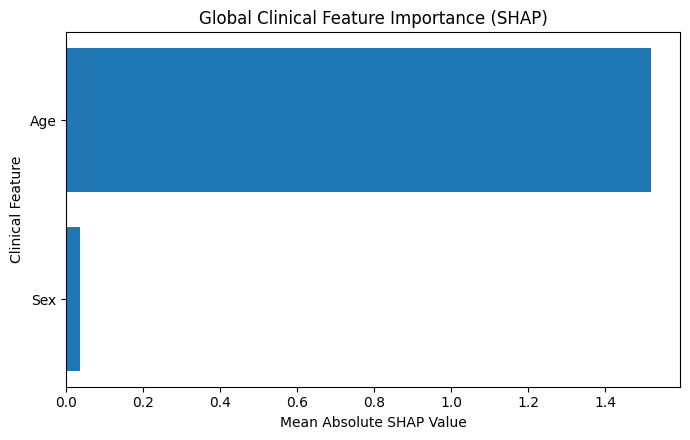

/tmp/ipykernel_493/720341879.py:92: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(
/tmp/ipykernel_493/720341879.py:92: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


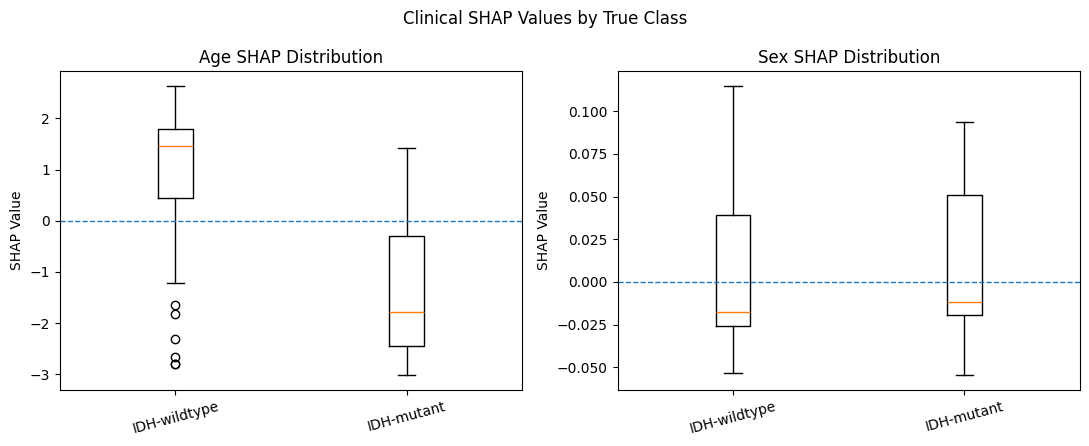

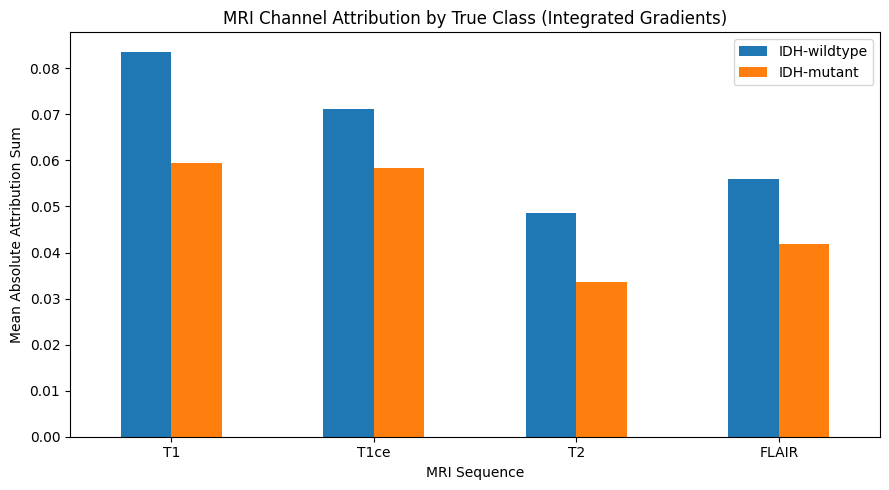


STEP 54 COMPLETED
Figure_1_Clinical_SHAP_Global_Importance.png | 64879 bytes
Figure_2_Clinical_SHAP_Classwise_Distribution.png | 135085 bytes
Figure_3_MRI_IG_Channel_Attribution_Classwise.png | 113082 bytes

Figures saved to:
/content/drive/MyDrive/Glioma_Research/explainability/publication_figures


In [105]:
# ============================================================
# STEP 54: PUBLICATION-READY CLINICAL SHAP & IG FIGURES
# ============================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = "/content/drive/MyDrive/Glioma_Research/explainability"

FIG_DIR = os.path.join(BASE, "publication_figures")
os.makedirs(FIG_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Load validated datasets
# ------------------------------------------------------------

clinical_shap_path = os.path.join(
    BASE, "shap/clinical/Clinical_SHAP_SubjectLevel_94Subjects.csv"
)

ig_path = os.path.join(
    BASE,
    "integrated_gradients/cohort/Cohort_IntegratedGradients_SubjectLevel.csv"
)

clinical_df = pd.read_csv(clinical_shap_path)
ig_df = pd.read_csv(ig_path)

assert len(clinical_df) == 94
assert clinical_df["subject_id"].nunique() == 94

assert len(ig_df) == 94
assert ig_df["subject_id"].nunique() == 94

print("Clinical SHAP and IG cohort files loaded successfully.")

# ------------------------------------------------------------
# 2. Figure 1: Global Clinical SHAP Importance
# ------------------------------------------------------------

clinical_importance = pd.Series({
    "Age": clinical_df["Age_SHAP"].abs().mean(),
    "Sex": clinical_df["Sex_SHAP"].abs().mean()
}).sort_values(ascending=True)

plt.figure(figsize=(7, 4.5))

plt.barh(
    clinical_importance.index,
    clinical_importance.values
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Clinical Feature")
plt.title("Global Clinical Feature Importance (SHAP)")
plt.tight_layout()

fig1_path = os.path.join(
    FIG_DIR, "Figure_1_Clinical_SHAP_Global_Importance.png"
)

plt.savefig(fig1_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 3. Figure 2: Clinical SHAP Distribution by Class
# ------------------------------------------------------------

class_names = {
    0: "IDH-wildtype",
    1: "IDH-mutant"
}

clinical_df["Class"] = clinical_df["label"].map(class_names)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, feature, title in zip(
    axes,
    ["Age_SHAP", "Sex_SHAP"],
    ["Age SHAP Distribution", "Sex SHAP Distribution"]
):
    groups = [
        clinical_df.loc[
            clinical_df["label"] == label, feature
        ].dropna().values
        for label in [0, 1]
    ]

    ax.boxplot(
        groups,
        labels=["IDH-wildtype", "IDH-mutant"],
        showfliers=True
    )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("SHAP Value")
    ax.tick_params(axis="x", rotation=15)

plt.suptitle("Clinical SHAP Values by True Class")
plt.tight_layout()

fig2_path = os.path.join(
    FIG_DIR, "Figure_2_Clinical_SHAP_Classwise_Distribution.png"
)

plt.savefig(fig2_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 4. Figure 3: MRI Integrated Gradients Channel Attribution
# ------------------------------------------------------------

channel_names = ["T1", "T1ce", "T2", "FLAIR"]

channel_columns = [
    "mri_channel_0_abs_sum",
    "mri_channel_1_abs_sum",
    "mri_channel_2_abs_sum",
    "mri_channel_3_abs_sum"
]

# Confirm expected columns exist
missing = [c for c in channel_columns if c not in ig_df.columns]

if missing:
    raise ValueError(f"Missing IG channel columns: {missing}")

ig_classwise = (
    ig_df.groupby("label")[channel_columns]
    .mean()
)

ig_classwise.index = [
    class_names[int(label)] for label in ig_classwise.index
]

ig_plot_df = ig_classwise.T
ig_plot_df.index = channel_names

ax = ig_plot_df.plot(
    kind="bar",
    figsize=(9, 5)
)

ax.set_title("MRI Channel Attribution by True Class (Integrated Gradients)")
ax.set_xlabel("MRI Sequence")
ax.set_ylabel("Mean Absolute Attribution Sum")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

fig3_path = os.path.join(
    FIG_DIR, "Figure_3_MRI_IG_Channel_Attribution_Classwise.png"
)

plt.savefig(fig3_path, dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 5. Export figure inventory
# ------------------------------------------------------------

figure_paths = [fig1_path, fig2_path, fig3_path]

print("\nSTEP 54 COMPLETED")
print("=" * 60)

for path in figure_paths:
    print(os.path.basename(path), "|", os.path.getsize(path), "bytes")

print("\nFigures saved to:")
print(FIG_DIR)

In [106]:
# ============================================================
# STEP 55: FINAL EXPLAINABILITY REPORT AND FIGURE AUDIT
# ============================================================

import os

BASE = "/content/drive/MyDrive/Glioma_Research/explainability"

paths = {
    "Comprehensive Explainability Report":
        os.path.join(BASE, "FINAL_COMPREHENSIVE_EXPLAINABILITY_REPORT.txt"),

    "Research-Oriented Findings":
        os.path.join(BASE, "FINAL_RESEARCH_ORIENTED_EXPLAINABILITY_FINDINGS.txt"),

    "GradCAM Report":
        os.path.join(BASE, "gradcam_test/FINAL_GRADCAM_EXPLAINABILITY_REPORT.txt"),

    "Publication Figures":
        os.path.join(BASE, "publication_figures")
}

print("=" * 70)
print("STEP 55: FINAL REPORT AUDIT")
print("=" * 70)

for name, path in paths.items():

    print(f"\n{name}")
    print("-" * 50)

    if os.path.isfile(path):
        print("STATUS: FOUND")
        print("Size:", os.path.getsize(path), "bytes")

        if path.endswith(".txt"):
            with open(path, "r", encoding="utf-8") as f:
                content = f.read()

            print("Characters:", len(content))
            print("First 1200 characters:")
            print(content[:1200])

    elif os.path.isdir(path):
        files = [
            f for f in os.listdir(path)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".pdf"))
        ]

        print("STATUS: FOUND")
        print("Figure count:", len(files))

        for f in sorted(files):
            print("-", f, "|", os.path.getsize(os.path.join(path, f)), "bytes")

    else:
        print("STATUS: MISSING")

print("\nSTEP 55 AUDIT COMPLETED")

STEP 55: FINAL REPORT AUDIT

Comprehensive Explainability Report
--------------------------------------------------
STATUS: FOUND
Size: 54822 bytes
Characters: 54820
First 1200 characters:
COMPREHENSIVE BRAIN GLIOMA EXPLAINABILITY REPORT
Generated on: 2026-11-10 14:05:34
Research task: IDH-mutant vs IDH-wildtype glioma classification
Dataset: Held-out test cohort; expected subject count = 94
Note: This report consolidates saved results and does not rerun model inference or explainability calculations.


MRI INTEGRATED GRADIENTS

--------------------------------------------------------------------------------
FILE: MRI_IG_Classwise_Channel_Summary.csv
--------------------------------------------------------------------------------
Shape: (4, 33)
Columns: Unnamed: 0, T1_Absolute_Sum, T1_Absolute_Sum.1, T1_Absolute_Sum.2, T1_Absolute_Sum.3, T1ce_Absolute_Sum, T1ce_Absolute_Sum.1, T1ce_Absolute_Sum.2, T1ce_Absolute_Sum.3, T2_Absolute_Sum, T2_Absolute_Sum.1, T2_Absolute_Sum.2, T2_Absolute_S